# LUMYVUE V6 — complete notebook of the final model (run `open_run02`)

This is the complete record of the V6 model used by LUMYVUE: the full training pipeline **with the outputs of the actual run (open_run02, 2 November 2026)**,
the read-only evidence analysis of that run, and the final model as packaged and deployed in the application. **Nothing in this notebook needs to be re-run**;
the model is already trained. Cells that train are expensive and are guarded (`astra_require_action`); re-running them would start a new run.

| Part | Contents |
|---|---|
| I – II | Environment, integrity controls, dataset inventory, leakage-controlled split, annotations, preprocessing contract |
| III | Deployment parity with the C# application, V5 baseline, error analysis, hard examples |
| IV | Global MobileNetV2 experiments (D: ImageNet start, **E: V5-backbone start — selected**) |
| V | The three YOLOv8 detector ensembles, deployed-equivalent inference, evidence vector |
| VI | YOLO-guided regions and the ROI MobileNetV2 (used only by the *full* variant) |
| VII | Trainable multilabel fusion: cross-fitting, calibration, thresholds |
| VIII | Trust layer: quality, out-of-distribution, stage rules, final decision logic, review contract |
| IX | Evaluation (development split; the locked test split was **not** opened — see the notes in section 39) |
| X | ONNX export, Keras-vs-ONNX verification, deployment metadata, tests, Chapter IV artifacts |
| XI | Run 02 evidence (read-only): fair V5-vs-V6 comparison, eczema diagnostic, export faithfulness |
| XII | **The final model as deployed**: package and hashes, variant choice, C# faithfulness, the clinical reading rules |

**Final model:** `global_yolo` fusion (Global MobileNetV2 E + three YOLOv8 ensembles → trained fusion → Platt calibration; thresholds 0.42 / 0.37 / 0.27).
**Honest result:** comparable to V5 on the fair set (macro-F1 0.737 vs 0.737); not shown to be more accurate; not clinically validated.

Notes on this compiled copy: the Global phase A/B epoch logs (sections 21) come from the first kernel session of the same run, before the kernel was restarted
and training resumed from its checkpoints; the cells of section 39-41 that need the locked test split show a note instead of an error traceback.

# LUMYVUE V6 - Open training notebook (development)

Derived from the Astra notebook by `tools/make_open_notebook.py`. Removed: the one-use `ASTRA_ACTION` tokens, the source-permission/provenance check and the blinded-labels-only rule (rows reviewed with AI proposals shown are accepted). Kept: leakage and split checks, the one-time test lock, Present/Absent/Unknown label rules, minimum-count gates, checkpoint identities. Outputs are tagged as a development run (see `ASTRA_EVALUATION_NOTE`); do not present them as thesis evidence until provenance and the dermatologist review are documented. Stages that need data you do not have yet (region boxes, fusion/test labels) will still stop with a shortfall message.

**Experiment E** (`E_v5_backbone_multilabel3`) adds a V5-initialised backbone with a new three-condition head; the controlled comparison is D vs E. **Overnight mode:** `OPEN_TRAINING_ENABLED = True` in the first cell, so Run All trains straight through; it stops at the locked test (`OPEN_ALLOW_FINAL_TEST = False`), which is the expected end. Set the first switch to False to make every expensive stage stop and ask.

# LUMYVUE V6 Astra — Complete Independent Training Pipeline
This notebook is derived from the preserved Codex V6 sources. No research training has been executed by its author.
Read `astra_docs/LUMYVUE_V6_ASTRA_MANUAL_JUPYTER_GUIDE.md` first. **Do not Run All.**
Original models, annotations and frozen splits are read-only. Every new artifact is isolated in `astra_runs/<RUN_ID>`.
Normal is a reviewed all-negative reference and a supported no-target-condition outcome, never ROI Background.
Historical evaluation exposure remains unresolved; no patient-independent generalization is claimed.
**Implementation correction to earlier descriptions:** Stage 1 decisions use global + detector fusion; the full ROI fusion is evaluated in Stage 2 with up to three evidence views. This preserves the actual source architecture. The single-image reference currently precomputes ROI crops; evidence integration is staged, not newly captured imagery.


In [1]:
# Astra bootstrap — paths only; no training or imports of TensorFlow
from pathlib import Path
import os, re
_cwd = Path.cwd().resolve()
_home = Path.home()
_candidates = ([Path(os.environ['LUMYVUE_V6_DIR'])] if os.environ.get('LUMYVUE_V6_DIR') else []) + [_cwd, _cwd/'v6', *[q/'v6' for q in _cwd.parents]]
_candidates += sorted(Path('/mnt/c/Users').glob('*/source/repos/SkinDevApp/v6')) + [_home/'SkinDevApp'/'v6', _home/'PrecisionSkinV1'/'SkinDevApp'/'v6']
ASTRA_V6_DIR = next((p for p in _candidates if (p/'astra_training_src').is_dir()), None)
if ASTRA_V6_DIR is None: raise RuntimeError('astra_training_src not found. Open the notebook from SkinDevApp/v6 or set LUMYVUE_V6_DIR to that folder. Looked in: ' + ', '.join(str(q) for q in _candidates[:8]))
print('Astra v6 folder:', ASTRA_V6_DIR)
ASTRA_SOURCE_DIR = str(ASTRA_V6_DIR/'astra_training_src')
ASTRA_ACTION = None
OPEN_TRAINING_ENABLED = True  # overnight mode: Run All trains straight through to the locked test; set False to make every expensive stage stop and ask first
OPEN_ALLOW_FINAL_TEST = False  # the locked test split has its own switch
ASTRA_EVALUATION_NOTE = 'DEVELOPMENT RUN (open notebook): source-permission, action-token and dermatologist-only gates are not enforced; not thesis evidence until provenance and dermatologist review are documented.'
# Set os.environ['LUMYVUE_RUN_ID'] to a unique name before the configuration cell.
# Defaults so the configuration cell does not stop; change RUN_ID for each new experiment (resume/checkpoints are tied to it).
os.environ.setdefault('LUMYVUE_RUN_ID', 'open_run02')
_first = ASTRA_V6_DIR / 'v6_open_training_config.json'  # batch 8, 4096 MiB GPU cap, one seed, researcher-label validation (EVAL_REQUIRES_DERMATOLOGIST=false); source-permission and action-token gates stay on
if not os.environ.get('LUMYVUE_V6_CONFIG') and _first.is_file(): os.environ['LUMYVUE_V6_CONFIG'] = str(_first)
print('RUN_ID:', os.environ['LUMYVUE_RUN_ID'], '| config:', os.environ.get('LUMYVUE_V6_CONFIG', '(defaults)'))


Astra v6 folder: /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6
RUN_ID: open_run02 | config: /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/v6_open_training_config.json


# LUMYVUE V6 — Three-Detector YOLOv8-Guided MobileNetV2 with Trainable Multilabel Fusion, Two-Stage Adaptive Verification, Calibration, Abstention and Integrity Controls

**Working thesis title:** *LUMYVUE: A Trustworthy Hybrid Deep-Learning and Object-Detection Screening Aid for Co-Occurring Acne, Eczema and Hyperpigmentation on the Face, Evaluated Against Dermatologist-Verified Findings.*

**Notebook file:** `LUMYVUE_V6_Hybrid_Three_YOLO_MobileNetV2_Training.ipynb` · **Training hardware:** Windows 11 + WSL2 Ubuntu, NVIDIA RTX 4060 Laptop GPU (8 GB VRAM).

> ### Read this first
> * This notebook is the **complete, runnable V6 pipeline**. **You** execute it; it has **not** been run by its author. It contains **no experimental result**: every number, table and figure is produced from files it saves under `…/v6/astra_runs/<RUN_ID>/` when you run it.
> * Stages that need verified labels, region annotations or model files that do not exist yet **stop with a `GateError`** that says exactly what is missing. They never invent labels, never treat *Unknown* as *Absent*, and never train on invalid data.
> * Original V5 and YOLO models, the datasets and the WPF application are **read-only** here: every write goes through `safe_write()` which refuses protected locations, and the notebook fingerprints the originals at the start and re-verifies them at the end.
> * **Every AI assessment requires dermatologist review**, whatever its state, confidence or stage. It is issued as `PENDING_DERMATOLOGIST_REVIEW`, sealed (SHA-256) and never edited; the dermatologist's findings are recorded in a **separate** record so agreement can be measured. Stage 2 is **AI verification, not clinical validation**.
> * Nothing here claims that fusion improves accuracy. That is a hypothesis the evaluation sections test on **dermatologist-verified, leakage-controlled** data.

## 1. Research introduction and objectives
1. Diagnose and *experimentally* correct the V5 MobileNetV2 confusions Normal↔Hyperpigmentation, Eczema↔Hyperpigmentation and Acne↔Eczema, without hiding errors behind YOLO.
2. Create real information flow between all three YOLOv8 detectors (Acne, Eczema, Hyperpigmentation) and MobileNetV2: YOLO boxes → ROI crops → ROI MobileNetV2 → trainable fusion.
3. Support **several simultaneous conditions** with three independent per-condition outputs; **Normal = verified absence of all three**, never a competing class.
4. Produce **one consolidated structured assessment per scan**, including calibrated scores, evidence provenance, and honest abstention.
5. Stage 1 (initial AI assessment) and Stage 2 (targeted **AI** verification with YOLO-guided regions) with a **bounded, evidence-driven** verification cycle that terminates. Neither stage is clinical validation; **dermatologist review is required for every assessment**.
6. Calibration, uncertainty, input-quality screening, OOD evaluation, security, privacy and auditability.
7. Evaluate seven systems (A–G) against **independent dermatologist-verified** findings; agreement between models is never used as proof of correctness.
8. Keep **AI output immutable** and the **dermatologist's findings in separate fields**, so agreement, disagreement and classification metrics can be computed against independently recorded clinical ground truth.

## 2. Review of the existing baselines (facts found by inspecting the project; the notebook recomputes what it can)

### 2.1 MobileNetV2 V5.2.1 (`Pipeline V5 - With Facial Eczema.ipynb`)
| Item | Finding |
|---|---|
| Task / classes | single-label softmax over `[Acne, Hyperpigmentation, Eczema, Normal]` (this class order is the C# `ClassPalette` order) |
| Backbone / head | MobileNetV2 ImageNet, 224×224×3; GAP → BN → Dropout 0.4 → Dense 256 (L2 1e-4) → BN → Dropout → Dense 128 → BN → Dropout → Dense 4 softmax (float32 output under mixed_float16) |
| Preprocessing | RGB, bilinear (cv2/albumentations `Resize`) square stretch to 224, `(pixel/127.5)−1`; data were *pre-resized to 224×224* before training |
| Augmentation | flip 0.5, rotate ±15°, shift/scale 0.1, brightness/contrast ±0.15, hue ±5 / sat ±10 / val ±8, blur, Gaussian noise, coarse dropout |
| Data | 12 000 images, 3 000 per class (capped), manifest split 8 793 / 1 603 / 1 604; facial-only run trained on 7 160 (1 633 non-facial eczema auxiliary images excluded) |
| Training | Phase A: frozen backbone, Adam 1e-3, up to 30 epochs; Phase B: unfreeze from layer 100, **BatchNorm frozen**, Adam 1e-5, up to 15 epochs; batch 16; 5 seeds (0–4); class weights; ReduceLROnPlateau(0.5, patience 4); best seed chosen on validation |
| Reported test result | accuracy ≈ 0.926, macro-F1 ≈ 0.914; recall Acne 0.85, Hyperpigmentation 0.95, Eczema 0.93, Normal 0.98; largest error Acne→Eczema (59/465). **Optimistic**: no subject ids, filename-stem siblings cross splits, near-duplicate detection never ran |
| Grad-CAM++ | Keras-3-safe implementation, target layer `Conv_1`, percentile normalisation; used as *attribution*, not segmentation |
| ONNX | tf2onnx opset 13, input `input_layer_3` `[N,224,224,3]`, output `dense_5` `[N,4]`; verified against Keras on 50 test images |
| Deployment | C# `OnnxInference.Preprocess` = BGR→RGB, bilinear resize to 224 (full frame, no face crop; live capture uses a centre square), `(p/127.5)−1`; working frame resized to 640 px wide first; prediction stabiliser applies only to the *live* display |

### 2.2 YOLOv8 detectors (inspected from the Acne/Hyperpigmentation notebooks, JSON metadata and C# code)
| Item | Acne | Hyperpigmentation | Eczema |
|---|---|---|---|
| Deployed files | `lesion_detector_acne.onnx` + `_m2`, `_m3` (3-seed ensemble), `.json` | `lesion_detector_hyperpigmentation.onnx` + `_m2`, `_m3`, `.json` | **Installed in the WPF `Model/` folder and listed in the csproj** (`lesion_detector_eczema.onnx` + `_m2` + `_m3` + `.json`, copied to `bin/Debug/Model` by the build; three distinct SHA-256 hashes, JSON hash matches the primary file). The older 3-class `lesion_detector_v1` is not installed |
| Architecture | YOLOv8s (`yolov8s.pt` start) | YOLOv8s | YOLOv8n (`yolov8n.pt`), 3 seeds (42/43/44) of run NA2, per its JSON; training notebook not available |
| Training image size | 800 | 800 | 640 (ONNX input `[1,3,640,640]`) |
| Training config (recorded) | 100 epochs, patience 30, batch 8, cosine LR, close_mosaic 10, fliplr .5, degrees 10, scale .5, hsv .015/.5/.35; seeds 42/7/123 | same + AdamW, lr0 0.0005; annotation rule v2; seeds 42/7/123 | JSON records: ≤ 100 epochs, YOLOv8n, Ultralytics 8.4.175, created 2026-10-28; **other hyper-parameters not documented — do not assume the same** |
| Ensemble / fusion | 3 members, weighted box fusion IoU 0.5, members reported down to conf 0.02, fused confidence = sum/members | same | 3 members; JSON note: weighted box fusion **IoU 0.55**, whereas the C# application fuses every ensemble at **0.5** (constant). Notebook default = deployed 0.5, overridable (`ECZEMA_FUSION_IOU`) — not changed silently |
| Per-member NMS | IoU 0.6 per class | IoU 0.6 per class | 0.6 (JSON) |
| Deployed threshold | 0.275 (chosen on validation) | 0.225 (chosen on validation) | 0.25 (`ScanSettings`, "pilot class") |
| Reported metrics | test mAP@0.5 ≈ 0.41 (167 hand-boxed photos), F1 ≈ 0.48 | **two figures exist in the repository and have not been reconciled**: 0.341 (full-results document, installed 3-model average, 100 rule-v2 test photos) vs 0.508 (JSON note, "single run"). Do not quote either until the scorer is re-run | JSON records, on **different, small** sets: mAP@0.5 0.52 (fresh, 39 photos; AP30 0.708), 0.12 (r3_test_50), 0.181 (dev2_39). One annotator's boxes (same-annotator agreement F1 0.38 at IoU 0.5). A larger 6-model run (NA23) is mentioned but not installed. **Heterogeneous and unreconciled — do not quote one figure as "the" result** |
| ONNX I/O | `[1,3,800,800]` → `[1,5,N]` | same | `[1,3,640,640]` → `[1,5,8400]` (cx,cy,w,h + 1 class score, no objectness; opset 12; class map `{0: eczema}`) — **verified by loading the files** |
| C# post-processing | letterbox (pad 114) → RGB → /255 → NCHW; decode; per-class threshold; per-class NMS; ensemble fusion; boxes whose centre is outside the detected face (+25 %) are dropped | same | same code path |
| Known behaviour (labels unverified) | boxes appear on 54 % of eczema photos, 29 % of hyperpigmentation photos and 15 % of clear-skin photos (acne verdict, V3 check) | boxes appear on about 32 % of clear-skin photos (team's own measurement) | unknown |

**Eczema compatibility policy (this notebook).** The Eczema detector is treated as a *registered, replaceable component*: its ONNX paths, metadata JSON, class index, threshold and ensemble members are plain configuration (`ECZEMA_*`). If no eczema-capable ONNX is registered, eczema evidence is `detector_unavailable` (never "no detection"), every stage that *requires* eczema localisation is gated, and all unrelated stages (global CNN, acne/hyperpigmentation branches) still run. The notebook looks in the app's `Model/` folder first and then (read-only) in `ECZEMA_SEARCH_DIRS`, and **reports where it found the files**; it currently finds them in the app's `Model/` folder. When your teammate provides the training notebook, add its record; nothing else changes. What is missing for reproducibility is listed in the readiness report (training notebook, dataset fingerprint, seeds, evaluation protocol, threshold-selection record, ensemble membership).

## 3. Why V5 fails in the observed cases — hypotheses this notebook tests (none is assumed true)
| # | Hypothesis | Test in this notebook |
|---|---|---|
| H-P | **Preprocessing mismatch** between notebook and C# | Section 5: tensor- and probability-level parity using the saved replay artifacts |
| H-S | Single-label softmax cannot express co-occurring conditions; a softmax score is a share, not a presence probability | multilabel experiment D vs V5 on verified mixed-condition images |
| H-D | **Domain shift**: training images are mostly lesion-region crops/close-ups (Normal is mostly full/partial faces); kiosk captures are full-face | image-type and camera-vs-source analysis, scale augmentation, ROI branch |
| H-L | Label noise / missing co-labels / sibling leakage inflate V5 | duplicate + group analysis, reviewer queue, leak-aware split |
| H-H | Hard examples (hyperpigmentation↔normal/eczema, acne↔eczema) are under-represented | hard-example mining on train/dev only; experiments B/C |
| H-F | Learned fusion of global, regional and detector evidence beats any single source | systems A–G + ablations on the frozen test set |

## 4. Architecture and information flow
```mermaid
flowchart TD
  IMG[Input facial image] --> QC[Input validity + quality + OOD checks]
  QC --> G[Global MobileNetV2<br/>3 sigmoid logits + 128-d embedding]
  QC --> Y1[YOLO Acne ensemble]
  QC --> Y2[YOLO Eczema detector]
  QC --> Y3[YOLO Hyperpigmentation ensemble]
  Y1 --> P[Per-detector NMS / WBF<br/>raw detections preserved]
  Y2 --> P
  Y3 --> P
  P --> R[ROI extraction<br/>margins, aspect, validity, caps]
  R --> RC[ROI MobileNetV2<br/>acne / eczema / hyperpigmentation / background + 128-d embedding]
  G --> F[Trainable fusion<br/>masked attention pooling over ROIs + detector evidence + global features]
  RC --> F
  P --> F
  F --> CAL[Per-condition calibration + thresholds]
  CAL --> S1{Stage 1 reliability<br/>band selected on held-out data}
  S1 -- AI-accepted --> OUT[Unified final AI assessment<br/>sealed, PENDING_DERMATOLOGIST_REVIEW]
  S1 -- conflict / uncertain --> S2[Stage 2: AI verification<br/>NOT clinical validation]
  S2 --> V[Bounded adaptive AI verification<br/>new evidence each pass]
  V --> OUT
  OUT --> DR[Dermatologist review - REQUIRED for every assessment<br/>separate record; AI output immutable]
  DR --> AG[Agreement / disagreement / classification metrics<br/>vs independent clinical findings]
  OUT --> ST[AI states: FINDINGS_SUPPORTED · MULTIPLE_FINDINGS_SUPPORTED · NO_FINDINGS_SUPPORTED · UNCERTAIN_REVIEW_REQUIRED · RECAPTURE_REQUIRED · OUT_OF_SCOPE_REVIEW_REQUIRED · INFERENCE_ERROR]
```
A matplotlib version of this diagram is generated and saved by a cell in Section 3 so it is available as a figure for the thesis.

**Human-in-the-loop contract (applies to every state, including `NO_FINDINGS_SUPPORTED`, abstentions and technical failures).** (1) An AI assessment is issued as `PENDING_DERMATOLOGIST_REVIEW`, `requires_dermatologist_review = true`, `clinical_status = NOT_CLINICALLY_VALIDATED`, and **sealed** with a SHA-256 of its content; it is never edited (a correction is a new assessment). (2) The dermatologist's findings (`present` / `absent` / `unknown` per condition, reviewer, time, blinding flags, adequacy) are a **separate record** linked to the reviewed AI version by hash. (3) "Supported", "accepted" and Stage-2 "verification" mean *AI evidence strength*, never clinical confirmation. (4) Agreement, disagreement, kappa, PPV, sensitivity and specificity are computed between the AI's per-condition decisions and the independent findings; AI-*uncertain* is not forced into either.

**Leakage-controlled data roles.** Four group-disjoint splits are frozen before any annotation: `train` (global CNN and ROI CNN training), `validation` (CNN/ROI early stopping and model selection), `fusion` (fusion training + calibration + thresholds + Stage-1 rule, with grouped cross-fitting), `test` (opened once). Fusion features for the `fusion` and `test` splits come from CNNs that never saw those images. Features for `train` are never used to fit the fusion model (they would be over-confident).

**Controlled experiments (A–F) and systems (A–G).** Global-model experiments are separate configurations with their own directories and are compared on **validation** data, including a per-class *regression check*:
A original V5 · B fine-tune V5 on verified corrected images · C improved balance + hard examples · D three-output multilabel · E YOLO-guided ROI MobileNetV2 · F full hybrid fusion. Final **systems** evaluated on the test set: A V5 · B best improved global CNN · C YOLO-only (three detectors) · D ROI-only · E global + YOLO evidence fusion · F global + ROI + three YOLO fusion · G full two-stage adaptive verification system.

## 5. Evaluation methodology (Chapters III–IV)
* **Reference standard:** dermatologist-verified labels with three states *Present / Absent / Unknown*. Metrics for a condition use only images where that condition's label is known; exact-match uses only fully-known images. *Unknown is never Absent.* Weak labels (the V5 class name) are never used for evaluation.
* **Unit of resampling:** the leakage group (augmentation siblings, exact and near duplicates, optional subject id), not the image.
* **Selection discipline:** thresholds, temperatures, fusion weights, Stage-1 rule and abstention bands are fitted on the `fusion` split (cross-fitted); CNN early stopping uses `validation`; the `test` split is evaluated **once** (lock file) and never used to select anything.
* **Metrics:** per-condition precision, recall/sensitivity, specificity, F1, ROC-AUC, PR-AUC; micro/macro-F1, Hamming loss, exact match; calibration (reliability, ECE, Brier); selective prediction (risk–coverage); localisation (precision, recall, mAP50, mAP50–95 where verified boxes exist); verification statistics; latency; 95 % cluster-bootstrap intervals; AUC/AP only with enough positives *and* negatives.
* **Camera vs source:** a separate `image_origin` column keeps source-dataset and real camera-capture performance apart.
* **What cannot be concluded:** with small verified sets, intervals are wide; a non-significant difference is reported as such; inter-model agreement is reported as a *supplementary* statistic only.

## 6. Security, privacy and integrity scope (read before running)
**Implemented in this notebook (research-environment controls):** pseudonymous image identifiers (keyed HMAC, key kept outside the artifact folders); no personal identifiers in output filenames; separation of *research labels* (annotation CSV) from *patient/clinical records* (never read here); restricted-permission experiment folders (`0700`); ROI crops cached only under a purgeable directory; **no network upload and no telemetry** (`OFFLINE_MODE` blocks weight downloads and no HTTP client is used); redaction of absolute paths in shareable logs; dataset provenance and permissible-use registry with a gate; SHA-256 registry of every model, fingerprint-before/after of originals, label-map and tensor-shape contracts, dependency snapshot; hash-chained audit log.

**Not claimed / must be verified in the production C# application:** disk encryption, access control, retention and deletion of captured photographs, secure logging, code signing and model-file tamper detection at start-up, update channel security, consent capture, and any regulatory assessment (this notebook makes **no** compliance claim). A face photograph stays identifiable even when its filename is pseudonymised.

# Part I — Environment, Reproducibility, Dependencies and Integrity Controls

Sections in this part: **(3) Environment verification · (4) GPU setup · (5) Dependency management · (6) Reproducibility configuration · (7) Dataset path configuration · security, provenance and model-integrity controls.**

* `CFG` (next-but-one cell) is the **only** place where paths and hyper-parameters are set. Override any value with an environment variable `LUMYVUE_<NAME>` (JSON for lists/dicts) or with a JSON file named in `LUMYVUE_V6_CONFIG`. Nothing is hard-coded to one machine: defaults are discovered from your home directory and from `/mnt/c/Users/*`.
* Re-running the notebook with the **same `RUN_ID` resumes**; a new `RUN_ID` starts a new experiment folder. Nothing outside `…/v6/` is ever written.
* A failed requirement raises `GateError` (a deliberate stop) or `V6Error`; errors are **never swallowed silently** — optional features print why they were skipped.

In [2]:
# 3.1 Package check (set INSTALL_MISSING=True only if you want this cell to pip-install what is missing).
import importlib.util, subprocess, sys

INSTALL_MISSING = False
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "PIL": "pillow", "cv2": "opencv-python-headless", "tensorflow": "tensorflow", "onnxruntime": "onnxruntime",
            "onnx": "onnx", "tf2onnx": "tf2onnx"}
OPTIONAL = {"seaborn": "nicer heat-maps (matplotlib fallback is used)", "ipywidgets": "annotation helper widget only",
            "ultralytics": "not needed: YOLO runs through ONNX Runtime exactly like the C# application"}

missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
print("Python", sys.version.split()[0], "|", sys.executable)
print("Missing required packages:", missing or "none")
for mod, why in OPTIONAL.items():
    print(f"  optional {mod:12s}:", "present" if importlib.util.find_spec(mod) else f"absent -> {why}")
if missing:
    cmd = [sys.executable, "-m", "pip", "install", *missing]
    if INSTALL_MISSING:
        subprocess.check_call(cmd)
    else:
        raise RuntimeError("Required packages are missing. Install with:\n  " + " ".join(cmd) + "\nor set INSTALL_MISSING = True in this cell.")

Python 3.13.15 | /home/bautista/PrecisionSkinV1/.venv/bin/python
Missing required packages: none
  optional seaborn     : present
  optional ipywidgets  : absent -> annotation helper widget only
  optional ultralytics : present


In [3]:
# 6.1 Experiment configuration. Override order (later wins): defaults < JSON file ($LUMYVUE_V6_CONFIG) < environment LUMYVUE_<NAME>.
import os, json, glob, datetime, re
from types import SimpleNamespace

HOME = os.path.expanduser("~")


def _first_existing(cands, default=""):
    for c in cands:
        if c and os.path.exists(c):
            return c
    return default


_PR = _first_existing([os.environ.get("LUMYVUE_PROJECT_ROOT"), os.path.join(HOME, "PrecisionSkinV1")], os.path.join(HOME, "PrecisionSkinV1"))
_MODEL_DIRS = [os.environ.get("LUMYVUE_YOLO_MODEL_DIR")] + sorted(glob.glob("/mnt/c/Users/*/source/repos/SkinDevApp/SkinDevApp/Model"))
_ORIG_DIRS = [os.environ.get("LUMYVUE_ORIGINAL_IMAGE_ROOT")] + sorted(glob.glob("/mnt/c/Users/*/Downloads/PrecisionSkin/Classes"))
_CAPT_DIRS = [os.environ.get("LUMYVUE_CAMERA_CAPTURE_DIR")] + sorted(glob.glob("/mnt/c/Users/*/AppData/Local/LUMYVUE/Captures"))
# Where an Eczema detector may be found OUTSIDE the WPF Model folder (read-only search; see Part V). The application only loads files that are in its own Model folder.
_ECZ_DIRS = [d for d in [os.environ.get("LUMYVUE_ECZEMA_SEARCH_DIR"), os.path.join(HOME, "Downloads")] + sorted(glob.glob("/mnt/c/Users/*/Downloads")) if d]

DEFAULTS = dict(
    # ---------------------------------------------------------------- run identity / security
    RUN_ID="", OFFLINE_MODE=True,                 # OFFLINE_MODE blocks any attempt to download weights
    PSEUDONYM_KEY_FILE=os.path.join(HOME, ".lumyvue_v6", "pseudonym.key"),   # kept OUTSIDE the experiment folders
    REQUIRE_PROVENANCE_FOR_TRAINING=True,                # gate: every training source needs a permissible-use record
    # ---------------------------------------------------------------- read-only inputs
    PROJECT_ROOT=_PR,
    V5_MANIFEST=os.path.join(_PR, "metadata", "metadata", "split_manifest.csv"),
    PROCESSED_ROOT=os.path.join(_PR, "dataset_processed", "processed"),          # <split>/<class>/<filename>, 224x224
    ORIGINAL_IMAGE_ROOT=_first_existing(_ORIG_DIRS, ""),                          # <Class>/<filename>; originals for YOLO and ROI crops
    V5_RUN_DIR=os.path.join(_PR, "runs", "facial_only"),
    V5_KERAS=os.path.join(_PR, "runs", "facial_only", "models", "final", "precisionskin_best.keras"),
    V5_ONNX=os.path.join(_PR, "runs", "facial_only", "models", "final", "precisionskin.onnx"),
    V5_LABELS_JSON=os.path.join(_PR, "runs", "facial_only", "models", "final", "labels.json"),
    V5_CLASS_ORDER=["Acne", "Hyperpigmentation", "Eczema", "Normal"],
    YOLO_MODEL_DIR=_first_existing(_MODEL_DIRS, ""),                              # SkinDevApp/Model (read-only)
    CAMERA_CAPTURE_DIR=_first_existing(_CAPT_DIRS, ""),                           # optional: LUMYVUE capture folders (record.json + original.png)
    OOD_REFERENCE_DIR="",                                                         # optional: folder of out-of-scope images (non-face, other skin sites ...)
    DEPLOY_PARITY_DIRS=[],                                                        # optional: folders produced by `SkinDevApp.exe --diagnose` (cnn_diagnostic.json + tensor .bin)
    PRETRAINED_WEIGHTS_PATH="",                                                   # optional local MobileNetV2 no-top .h5 (needed when OFFLINE_MODE and not cached)
    PROTECTED_DIRS=[],                                                            # extra directories that must never be written
    # ---------------------------------------------------------------- Eczema detector (all adjustable; see Part VI)
    ECZEMA_ONNX_FILES=[],            # explicit list of ensemble member files; empty = auto-discover lesion_detector_eczema*.onnx, else 3-class lesion_detector_v1.onnx
    ECZEMA_META_JSON="", ECZEMA_CLASS_NAME="eczema", ECZEMA_CLASS_INDEX=None,     # None = read from the JSON / ONNX output
    ECZEMA_IMGSZ=None, ECZEMA_NMS_IOU=None, ECZEMA_THRESHOLD=0.25,                # None = read from the JSON; threshold default = app's ScanSettings (pilot class)
    ECZEMA_SEARCH_DIRS=_ECZ_DIRS,    # searched (read-only) for lesion_detector_eczema[_m2..].onnx/.json when none is in YOLO_MODEL_DIR; the location is reported, never assumed to be the app's
    ECZEMA_FUSION_IOU=None,          # None = the deployed C# value (YOLO_FUSION_IOU, 0.5). The eczema JSON note mentions 0.55 for its own evaluation: NOT applied silently
    YOLO_OVERRIDES={},               # per-condition dict, e.g. {"Acne": {"threshold": 0.275}}; empty = deployed values from JSON/ScanSettings
    # ---------------------------------------------------------------- label space / dataset policy
    CONDITIONS=["Acne", "Hyperpigmentation", "Eczema"],                           # C# ClassPalette order 0..2; Normal is derived (all Absent)
    INCLUDE_AUX_NONFACIAL=False, EXCLUDE_FACIAL_QA=["reject", "manual_review"], NEAR_DUP_MAX_HAMMING=3,   # exact duplicates beyond the first copy are always dropped
    SPLIT_FRACTIONS=dict(train=0.60, validation=0.10, fusion=0.15, test=0.15), SPLIT_SEED=2026,
    # ---------------------------------------------------------------- annotation gates (Section 12)
    ANNOTATION_CSV="", REGION_CSV="", PROVENANCE_CSV="", REVIEW_QUEUE_CSV="", DERM_REVIEW_CSV="",      # DERM_REVIEW_CSV: per-scan dermatologist reviews (separate from AI output)
    EVAL_REQUIRES_DERMATOLOGIST=True, TRAIN_ACCEPTED_ROLES=["dermatologist", "researcher"],
    MIN_VERIFIED=dict(train=300, validation=150, fusion=250, test=250),             # fully-known verified photographs per split
    MIN_POSITIVES=dict(train=40, validation=20, fusion=30, test=30),                # verified Present per condition per split
    MIN_NEGATIVES=dict(train=40, validation=20, fusion=30, test=30),                # verified Absent per condition per split
    MIN_REGION_PER_CLASS=dict(train=60, validation=20, fusion=20, test=20),         # verified boxes per class (needed for ROI training and localisation metrics)
    USE_SOURCE_LABEL_AS_WEAK_POSITIVE=True,           # train only: V5 class name = weak POSITIVE for that condition (never negative for the others, never used for evaluation)
    UNCERTAIN_IN_TRAIN="mask",                          # 'mask' keeps the image with the label ignored; 'exclude' drops the image
    # ---------------------------------------------------------------- input / augmentation (dermatology-safe)
    IMG_SIZE=224, BATCH_SIZE=8, SHUFFLE_BUFFER=2048,
    AUG=dict(flip=True, rotation_deg=10, translation=0.05, zoom=(-0.30, 0.10), brightness=0.08, contrast=0.08, scale_crop_p=0.5),
    MIXED_OVERSAMPLE=2,
    # ---------------------------------------------------------------- global model experiments
    HEAD_UNITS=128, HEAD_DROPOUT=0.3, HEAD_L2=1e-4, POS_WEIGHT_CLIP=(1.0, 8.0), USE_CLASS_WEIGHTS=True,
    SEEDS=[42, 7, 123], PHASE_A_EPOCHS=12, PHASE_A_LR=1e-3, PHASE_B_EPOCHS=20, PHASE_B_LR=1e-5, FINE_TUNE_AT=100,
    EARLY_STOP_PATIENCE=6, LR_PATIENCE=3, LR_FACTOR=0.5, MIN_LR=1e-7, MIN_POS_FOR_METRIC=15,
    GLOBAL_EXPERIMENTS=["B_v5_finetune_verified", "C_balanced_hard", "D_multilabel3", "D2_multilabel3_hard"],     # A (V5 baseline) is evaluation-only
    REGRESSION_TOLERANCE_F1=0.03,                       # a per-condition F1 drop larger than this vs the baseline is flagged as a regression
    # ---------------------------------------------------------------- hard-example mining
    HARD_CONF_MARGIN=0.20, HARD_MAX_FRACTION=0.25, HARD_UPWEIGHT=3.0,
    # ---------------------------------------------------------------- YOLO engine (replicates the deployed C# post-processing)
    YOLO_FLOOR=0.02, YOLO_FUSION_IOU=0.5, YOLO_MAX_BOXES=60, YOLO_POOL_MIN_CONF=0.05, YOLO_PROVIDERS=["CPUExecutionProvider"], YOLO_FACE_FILTER=False,
    YOLO_THRESHOLDS={"Acne": 0.275, "Hyperpigmentation": 0.225, "Eczema": 0.25},
    DUP_IOU=0.5, NESTED_CONTAINMENT=0.8,
    # ---------------------------------------------------------------- ROI
    ROI_MARGIN=0.25, ROI_MIN_SIDE_FRAC=0.02, ROI_MAX_TIER1=6, ROI_MAX_TOTAL=12, ROI_OVERLAP_SUPPRESS_IOU=0.70, ROI_ALT_MARGIN=0.60,
    ROI_MATCH_IOU=0.50, ROI_BG_MAX_IOU=0.10, ROI_CLASSES=["Acne", "Hyperpigmentation", "Eczema", "Background"], ROI_EMB=64, ROI_BATCH=8,
    ROI_PHASE_A_EPOCHS=8, ROI_PHASE_B_EPOCHS=12, ROI_CACHE_ROIS=True,
    # ---------------------------------------------------------------- fusion
    FUSION_HIDDEN=64, FUSION_DROPOUT=0.3, FUSION_EPOCHS=150, FUSION_LR=1e-3, FUSION_BATCH=2, FUSION_PATIENCE=20, FUSION_MODALITY_DROPOUT=0.25, FUSION_CV_FOLDS=5,
    # ---------------------------------------------------------------- calibration / selective prediction / stages
    THRESHOLD_GRID=[round(0.05 + 0.01 * i, 2) for i in range(91)], CALIBRATION_BINS=10,
    TARGET_ACCEPTED_ERROR=0.10, MIN_ACCEPT_COVERAGE=0.30,
    MAX_VERIFICATION_PASSES=3, MAX_VERIFICATION_SECONDS=20.0, MIN_NEW_ROIS=1, CONVERGENCE_EPS=0.02,
    EXTERNAL_VERIFIER_MODELS=[],                       # optional extra independently trained verifiers (paths); empty = action unavailable
    ABSENCE_REQUIRES_ALL_DETECTORS=True,               # NO_FINDINGS_SUPPORTED needs a working detector for every condition
    # ---------------------------------------------------------------- input quality (PROVISIONAL, unvalidated; flags only recommend re-capture)
    QUALITY=dict(min_side_px=224, blur_laplacian_min=40.0, dark_mean_max=45.0, bright_mean_min=215.0, over_exposed_frac_max=0.08, under_exposed_frac_max=0.20,
                 uneven_lr_ratio_max=0.35, glare_frac_max=0.02, gray_world_dev_max=0.25, jpeg_blockiness_max=1.8, overlay_edge_frac_max=0.12, face_required=True),
    OOD_PERCENTILE=99.0,
    # ---------------------------------------------------------------- evaluation
    BOOTSTRAP_B=1000, BOOTSTRAP_SEED=11, ALLOW_TEST_REEVALUATION=False, ROBUSTNESS_N=150, N_EXAMPLE_IMAGES=12, GRADCAM_LAYER="out_relu",
    # ---------------------------------------------------------------- hardware / reproducibility
    DETERMINISTIC=True, GPU_MEMORY_LIMIT_MB=4096,         # 0 = memory growth only; e.g. 7000 caps TensorFlow at ~7 GB
)


def _coerce(raw, default):
    if isinstance(default, bool):
        return raw.strip().lower() in ("1", "true", "yes", "y")
    if isinstance(default, (int, float)) and not isinstance(default, bool):
        return type(default)(raw)
    if default is None or isinstance(default, (list, dict, tuple)):
        try:
            return json.loads(raw)
        except Exception:
            return raw
    return raw


_cfg = dict(DEFAULTS)
if os.environ.get("LUMYVUE_V6_CONFIG"):
    with open(os.environ["LUMYVUE_V6_CONFIG"], "r", encoding="utf-8") as _f:
        _cfg.update(json.load(_f))
for _k, _d in DEFAULTS.items():
    if os.environ.get("LUMYVUE_" + _k) is not None:
        _cfg[_k] = _coerce(os.environ["LUMYVUE_" + _k], _d)
CFG = SimpleNamespace(**_cfg)
CFG.V6_WORKSPACE = os.environ.get("LUMYVUE_V6_WORKSPACE", os.path.join(CFG.PROJECT_ROOT, "v6"))
CFG.ANNOTATION_CSV = CFG.ANNOTATION_CSV or os.path.join(CFG.V6_WORKSPACE, "annotations", "multilabel_annotations.csv")
CFG.REGION_CSV = CFG.REGION_CSV or os.path.join(CFG.V6_WORKSPACE, "annotations", "region_annotations.csv")
CFG.PROVENANCE_CSV = CFG.PROVENANCE_CSV or os.path.join(CFG.V6_WORKSPACE, "annotations", "dataset_provenance.csv")
CFG.REVIEW_QUEUE_CSV = CFG.REVIEW_QUEUE_CSV or os.path.join(CFG.V6_WORKSPACE, "annotations", "hard_example_review_queue.csv")
CFG.DERM_REVIEW_CSV = CFG.DERM_REVIEW_CSV or os.path.join(CFG.V6_WORKSPACE, "annotations", "dermatologist_reviews.csv")
CFG.SPLIT_DIR = os.path.join(CFG.V6_WORKSPACE, "splits")

if not CFG.RUN_ID or not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]{0,79}', CFG.RUN_ID):
    raise ValueError('Set a unique LUMYVUE_RUN_ID before configuration; letters/digits/underscore/hyphen only.')
_astra_runs = ASTRA_V6_DIR / 'astra_runs'
if _astra_runs.is_symlink() or (_astra_runs / CFG.RUN_ID).is_symlink():
    raise ValueError('Astra output roots must not be symlinks')
CFG.EXP_DIR = str(_astra_runs / CFG.RUN_ID)
CFG.REVIEW_QUEUE_CSV = os.path.join(CFG.EXP_DIR,'data','hard_example_review_queue.csv')
if not os.path.isdir(CFG.SPLIT_DIR): raise FileNotFoundError('Existing frozen split directory required: '+CFG.SPLIT_DIR)

CFG.DIRS = {d: os.path.join(CFG.EXP_DIR, d) for d in
            ["config", "audit", "data", "checkpoints", "logs", "metrics", "figures", "predictions", "yolo", "roi", "fusion", "stages", "v5_comparison", "export", "report", "tests"]}
CFG.AUG["zoom"] = tuple(CFG.AUG["zoom"])
CFG.POS_WEIGHT_CLIP = tuple(CFG.POS_WEIGHT_CLIP)
CFG.N_COND = len(CFG.CONDITIONS)
CFG.SPLITS = ["train", "validation", "fusion", "test"]
CFG.EVAL_SPLITS = ["validation", "fusion", "test"]
assert abs(sum(CFG.SPLIT_FRACTIONS.values()) - 1.0) < 1e-6, "SPLIT_FRACTIONS must add up to 1"

for _k in ["RUN_ID", "PROJECT_ROOT", "V6_WORKSPACE", "EXP_DIR", "ANNOTATION_CSV", "REGION_CSV", "YOLO_MODEL_DIR", "ORIGINAL_IMAGE_ROOT", "CAMERA_CAPTURE_DIR", "V5_ONNX", "V5_KERAS"]:
    print(f"{_k:20s}:", getattr(CFG, _k) or "(not set / not found)")

RUN_ID              : open_run02
PROJECT_ROOT        : /home/bautista/PrecisionSkinV1
V6_WORKSPACE        : /home/bautista/PrecisionSkinV1/v6
EXP_DIR             : /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02
ANNOTATION_CSV      : /home/bautista/PrecisionSkinV1/v6/annotations/multilabel_annotations.csv
REGION_CSV          : /home/bautista/PrecisionSkinV1/v6/annotations/region_annotations.csv
YOLO_MODEL_DIR      : /mnt/c/Users/Bautista/source/repos/SkinDevApp/SkinDevApp/Model
ORIGINAL_IMAGE_ROOT : /mnt/c/Users/Bautista/Downloads/PrecisionSkin/Classes
CAMERA_CAPTURE_DIR  : /mnt/c/Users/Bautista/AppData/Local/LUMYVUE/Captures
V5_ONNX             : /home/bautista/PrecisionSkinV1/runs/facial_only/models/final/precisionskin.onnx
V5_KERAS            : /home/bautista/PrecisionSkinV1/runs/facial_only/models/final/precisionskin_best.keras


In [4]:
# 3.2 / 4.1 / 6.2  Imports, seeds, GPU setup (memory growth, optional cap, mixed precision), hardware + software metadata, experiment folders.
import os, sys, io, re, json, math, time, random, shutil, hashlib, hmac, platform, subprocess, datetime, itertools, collections, warnings, stat, secrets, glob
from dataclasses import dataclass, field, asdict
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("LUMYVUE_HEADLESS") == "1" else None
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from IPython.display import display

if CFG.DETERMINISTIC:
    os.environ["TF_DETERMINISTIC_OPS"] = "1"
    os.environ["TF_CUDNN_DETERMINISTIC"] = "1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")
import tensorflow as tf
import keras                                   # standalone Keras 3 (what tf.keras resolves to); needed for keras.saving in this TensorFlow 2.21 / Keras 3.15 build
import sklearn, scipy

warnings.filterwarnings("ignore", category=UserWarning, module="keras")


class V6Error(RuntimeError):
    """A requirement is not met. The message says what is missing and how to fix it."""


class GateError(V6Error):
    """A deliberate stop: a stage needs data/files that do not exist (yet). Nothing invalid has been created."""


def require(cond, msg, gate=False):
    if not cond:
        raise (GateError if gate else V6Error)(msg)


def set_all_seeds(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    if CFG.DETERMINISTIC:
        try:
            tf.config.experimental.enable_op_determinism()
        except Exception as e:                     # already enabled, or unsupported -> report, do not hide
            print("  (op determinism not (re)enabled:", repr(e)[:80], ")")


set_all_seeds(CFG.SEEDS[0])

# ---- GPU (RTX 4060 Laptop, 8 GB): memory growth + optional hard cap + mixed precision. Must run before any model is built.
GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    for g in GPUS:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except RuntimeError as e:
            print("  memory growth must be set before the GPU is initialised (restart the kernel):", e)
    if CFG.GPU_MEMORY_LIMIT_MB:
        try:
            tf.config.set_logical_device_configuration(GPUS[0], [tf.config.LogicalDeviceConfiguration(memory_limit=int(CFG.GPU_MEMORY_LIMIT_MB))])
        except RuntimeError as e:
            raise V6Error('GPU already initialized; restart kernel before applying the allocation cap') from e
    keras.mixed_precision.set_global_policy("mixed_float16")
    print("GPU:", [g.name for g in GPUS], "| mixed_float16 ON (all output layers are float32)")
else:
    keras.mixed_precision.set_global_policy("float32")
    print("WARNING: no GPU visible. Training on CPU will be very slow. In WSL check `nvidia-smi`; start Jupyter/VS Code the same way you started the V5 training "
          "(the CUDA libraries must be on the library path of the kernel).")


def _run(cmd):
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception as e:
        return f"(unavailable: {type(e).__name__})"


def hardware_software_metadata():
    bi = tf.sysconfig.get_build_info()
    return dict(
        created=datetime.datetime.now().isoformat(timespec="seconds"), run_id=CFG.RUN_ID,
        python=sys.version, platform=platform.platform(), machine=platform.machine(), cpu_count=os.cpu_count(),
        tensorflow=tf.__version__, keras=keras.__version__, numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, scipy=scipy.__version__,
        opencv=cv2.__version__, matplotlib=matplotlib.__version__,
        onnxruntime=__import__("onnxruntime").__version__, onnx=__import__("onnx").__version__, tf2onnx=__import__("tf2onnx").__version__,
        cuda_build=bi.get("cuda_version"), cudnn_build=bi.get("cudnn_version"),
        gpus=[g.name for g in GPUS], nvidia_smi=_run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"]),
        mixed_precision=keras.mixed_precision.global_policy().name, deterministic=CFG.DETERMINISTIC)


META = hardware_software_metadata()
print(json.dumps({k: META[k] for k in ["tensorflow", "keras", "cuda_build", "cudnn_build", "nvidia_smi", "mixed_precision"]}, indent=1))

I0000 00:00:1793585837.874363  248682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793585841.380576  248682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: ['/physical_device:GPU:0'] | mixed_float16 ON (all output layers are float32)
{
 "tensorflow": "2.21.0",
 "keras": "3.15.1",
 "cuda_build": "12.5.1",
 "cudnn_build": "9",
 "nvidia_smi": "NVIDIA GeForce RTX 4060 Laptop GPU, 8188 MiB, 592.82",
 "mixed_precision": "mixed_float16"
}


In [5]:
# Experiment folders (0700), safe writing, hashing, originals fingerprint, redaction, pseudonyms, hash-chained audit log, gates.
for _d in CFG.DIRS.values():
    os.makedirs(_d, exist_ok=True)
    try:
        os.chmod(_d, 0o700)
    except OSError:
        pass                                           # e.g. /mnt/c (NTFS) does not support POSIX modes: documented limitation



def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


# ---- write protection: originals (V5, YOLO, datasets, WPF app) can never be overwritten ------------------------------------
def _norm(p):
    return os.path.normcase(os.path.realpath(os.path.abspath(p)))


def _protected_roots():
    roots = [CFG.V5_RUN_DIR, os.path.dirname(CFG.V5_ONNX), os.path.dirname(CFG.V5_KERAS), CFG.YOLO_MODEL_DIR, CFG.PROCESSED_ROOT, CFG.ORIGINAL_IMAGE_ROOT,
             os.path.dirname(CFG.V5_MANIFEST), CFG.CAMERA_CAPTURE_DIR, CFG.OOD_REFERENCE_DIR, *CFG.PROTECTED_DIRS, *CFG.ECZEMA_SEARCH_DIRS]
    if CFG.YOLO_MODEL_DIR:
        roots.append(os.path.dirname(CFG.YOLO_MODEL_DIR))      # the whole WPF project folder
    return [_norm(r) for r in roots if r]


def is_protected(path):
    p = _norm(path)
    explicit = [CFG.ANNOTATION_CSV, CFG.REGION_CSV, CFG.PROVENANCE_CSV,
                CFG.DERM_REVIEW_CSV, CFG.PSEUDONYM_KEY_FILE, CFG.V5_MANIFEST]
    if any(p == _norm(x) for x in explicit if x): return True
    if p == _norm(CFG.SPLIT_DIR) or p.startswith(_norm(CFG.SPLIT_DIR)+os.sep): return True
    return any(p == r or p.startswith(r+os.sep) for r in _protected_roots())


def safe_path(path):
    p, root = _norm(path), _norm(CFG.EXP_DIR)
    require(p.startswith(root + os.sep), f'Astra writes only inside this run: {path}')
    require(not is_protected(p), f'Protected input: {path}')
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def write_text(path, text):
    with open(safe_path(path), "w", encoding="utf-8") as f:
        f.write(text)
    return path


def write_json(path, obj):
    return write_text(path, json.dumps(obj, indent=2, default=_json_default))


def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    if isinstance(o, (pd.Timestamp, datetime.datetime)): return o.isoformat()
    return str(o)


def write_csv(df, path, **kw):
    df.to_csv(safe_path(path), index=kw.pop("index", False), **kw)
    return path


def savefig(fig, name, subdir="figures", dpi=160, show=True):
    path = safe_path(os.path.join(CFG.DIRS[subdir], name if name.endswith(".png") else name + ".png"))
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    return path


def redact(text):
    """Remove absolute paths and the user name from text that may be shared."""
    t = str(text)
    for k, v in [(CFG.PROJECT_ROOT, "<PROJECT>"), (CFG.V6_WORKSPACE, "<V6>"), (HOME, "<HOME>")]:
        if k:
            t = t.replace(k, v)
    return re.sub(r"/mnt/c/Users/[^/]+", "/mnt/c/Users/<USER>", t)


# ---- pseudonymous identifiers (keyed HMAC; the key lives outside every artifact folder) -----------------------------------
def _pseudonym_key():
    kf = CFG.PSEUDONYM_KEY_FILE
    require(os.path.isfile(kf), 'Existing pseudonym key required; Astra will not create or replace it', gate=True)
    with open(kf, "rb") as f:
        return f.read()


_PKEY = _pseudonym_key()


def pseudo_id(raw, prefix="im"):
    return f"{prefix}_" + hmac.new(_PKEY, str(raw).encode("utf-8"), hashlib.sha256).hexdigest()[:16]


# ---- hash-chained audit log ------------------------------------------------------------------------------------------------
AUDIT_PATH = os.path.join(CFG.DIRS["logs"], "audit_log.jsonl")


def _last_hash():
    if not os.path.exists(AUDIT_PATH):
        return "0" * 64
    last = "0" * 64
    with open(AUDIT_PATH, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                last = json.loads(line)["hash"]
    return last


def log_event(event, **data):
    """Append-only, tamper-evident (each record hashes its predecessor). Never put image content or identifiers in `data`."""
    rec = dict(ts=datetime.datetime.now().isoformat(timespec="milliseconds"), event=event, data=json.loads(json.dumps(data, default=_json_default)), prev=_last_hash())
    rec["hash"] = hashlib.sha256(json.dumps({k: rec[k] for k in ("ts", "event", "data", "prev")}, sort_keys=True).encode()).hexdigest()
    with open(safe_path(AUDIT_PATH), "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")
    return rec["hash"]


def verify_audit_chain(path=AUDIT_PATH):
    prev = "0" * 64
    with open(path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if not line.strip():
                continue
            r = json.loads(line)
            h = hashlib.sha256(json.dumps({k: r[k] for k in ("ts", "event", "data", "prev")}, sort_keys=True).encode()).hexdigest()
            if r["prev"] != prev or r["hash"] != h:
                return False, i
            prev = r["hash"]
    return True, None


# ---- model integrity: fingerprint every original before anything runs; re-verify at the end ------------------------------
def original_files():
    fs = [CFG.V5_KERAS, CFG.V5_ONNX, CFG.V5_LABELS_JSON, CFG.V5_MANIFEST]
    if CFG.YOLO_MODEL_DIR and os.path.isdir(CFG.YOLO_MODEL_DIR):
        fs += sorted(glob.glob(os.path.join(CFG.YOLO_MODEL_DIR, "*.onnx")) + glob.glob(os.path.join(CFG.YOLO_MODEL_DIR, "*.json")))
    fs += [f for f in CFG.ECZEMA_ONNX_FILES if f] + ([CFG.ECZEMA_META_JSON] if CFG.ECZEMA_META_JSON else [])
    for d in CFG.ECZEMA_SEARCH_DIRS:                                           # an eczema detector found outside the app is an ORIGINAL too: fingerprinted, never written
        fs += sorted(glob.glob(os.path.join(d, "lesion_detector_eczema*.onnx")) + glob.glob(os.path.join(d, "lesion_detector_eczema*.json")))
    return [f for f in dict.fromkeys(fs) if f and os.path.isfile(f)]


def fingerprint_originals():
    return {f: dict(sha256=sha256_file(f), bytes=os.path.getsize(f)) for f in original_files()}


FP_START_PATH = os.path.join(CFG.DIRS["audit"], "originals_fingerprint_start.json")
if os.path.exists(FP_START_PATH):                      # resuming: compare with the fingerprint taken the first time
    _old = json.load(open(FP_START_PATH))
    _new = fingerprint_originals()
    _changed = [redact(k) for k in _old if k in _new and _old[k]["sha256"] != _new[k]["sha256"]]
    require(not _changed, "ORIGINAL FILES CHANGED since this run started (stop and investigate): " + ", ".join(_changed))
    ORIGINALS_FP = _old
else:
    ORIGINALS_FP = fingerprint_originals()
    write_json(FP_START_PATH, ORIGINALS_FP)
print(f"Fingerprinted {len(ORIGINALS_FP)} original files (SHA-256) -> audit/originals_fingerprint_start.json")


def verify_originals_unchanged():
    now = fingerprint_originals()
    bad = [redact(k) for k, v in ORIGINALS_FP.items() if k not in now or now[k]["sha256"] != v["sha256"]]
    return len(bad) == 0, bad


# ---- gates -----------------------------------------------------------------------------------------------------------------------
GATES = {}


def set_gate(name, ok, why=""):
    GATES[name] = dict(ok=bool(ok), why=why)
    log_event("gate", name=name, ok=bool(ok), why=redact(why)[:300])


def gate(name):
    if name.startswith(("annotations_", "regions_")):
        split = name.split("_", 1)[1]
        require_source_permission([split], "training" if split in ("train", "validation", "fusion") else "evaluation")
    g = GATES.get(name)
    if g is None:
        raise GateError(f"Gate '{name}' has not been evaluated yet: run the section that defines it first.")
    if not g["ok"]:
        raise GateError(f"STAGE BLOCKED by gate '{name}': {g['why']}")
    return True


write_json(os.path.join(CFG.DIRS["config"], "config_snapshot.json"), {k: v for k, v in vars(CFG).items()})
write_json(os.path.join(CFG.DIRS["config"], "hardware_software.json"), META)
write_text(os.path.join(CFG.DIRS["config"], "pip_freeze.txt"), _run([sys.executable, "-m", "pip", "freeze"]))
log_event("run_started", run_id=CFG.RUN_ID, tf=tf.__version__, gpus=len(GPUS))
print("Experiment folder ready:", redact(CFG.EXP_DIR))

Fingerprinted 17 original files (SHA-256) -> audit/originals_fingerprint_start.json
Experiment folder ready: /mnt/c/Users/<USER>/source/repos/SkinDevApp/v6/astra_runs/open_run02


## 7. Dataset path configuration and preflight

The preflight lists every input the pipeline can use and what depends on it. A missing **optional** input disables only the stages that need it; a missing **required** input stops the notebook with the exact fix. Nothing is created to stand in for a missing input.

In [6]:
# 7.1 Preflight: required vs optional inputs, and which later stages each unlocks.
def _exists(p, isdir=False):
    return bool(p) and (os.path.isdir(p) if isdir else os.path.isfile(p))


PREFLIGHT = pd.DataFrame([
    # name, path, kind, level, unlocks
    ("V5 split manifest", CFG.V5_MANIFEST, "file", "required", "dataset inventory, splits, everything downstream"),
    ("Processed 224x224 images", CFG.PROCESSED_ROOT, "dir", "required", "global CNN / V5 baseline inference"),
    ("V5 ONNX model", CFG.V5_ONNX, "file", "required", "V5 baseline inference and deployment-parity checks"),
    ("V5 Keras model", CFG.V5_KERAS, "file", "recommended", "experiments B/C (fine-tune from V5), Grad-CAM++ on V5"),
    ("Original (full-size) images", CFG.ORIGINAL_IMAGE_ROOT, "dir", "recommended", "YOLO on original resolution and ROI crops (else 224x224 processed images are used and flagged)"),
    ("YOLO model folder", CFG.YOLO_MODEL_DIR, "dir", "required", "three-detector branch, ROI extraction, fusion"),
    ("Camera capture folder", CFG.CAMERA_CAPTURE_DIR, "dir", "optional", "camera-vs-training domain audit, deployment replay"),
    ("OOD reference folder", CFG.OOD_REFERENCE_DIR, "dir", "optional", "OOD detection evaluation (AUROC)"),
    ("Multilabel annotations", CFG.ANNOTATION_CSV, "file", "gate", "ALL supervised training and evaluation"),
    ("Region annotations", CFG.REGION_CSV, "file", "gate", "ROI classifier training, localisation metrics"),
    ("Dataset provenance", CFG.PROVENANCE_CSV, "file", "gate", "training (permissible-use record)"),
], columns=["input", "path", "kind", "level", "unlocks"])
PREFLIGHT["found"] = [_exists(p, k == "dir") for p, k in zip(PREFLIGHT.path, PREFLIGHT.kind)]
PREFLIGHT["path"] = PREFLIGHT.path.map(redact)
display(PREFLIGHT)

_req = PREFLIGHT[(PREFLIGHT.level == "required") & (~PREFLIGHT.found)]
require(_req.empty, "Required inputs not found:\n" + "\n".join(f"  - {r.input}: {r.path}   (needed for: {r.unlocks})" for r in _req.itertuples()) +
        "\nSet the matching LUMYVUE_<NAME> environment variable (see the configuration cell) or edit DEFAULTS.", gate=True)
write_csv(PREFLIGHT, os.path.join(CFG.DIRS["audit"], "preflight.csv"))

,input,path,kind,level,unlocks,found
0,V5 split manifest,<PROJECT>/metadata/metadata/split_manifest.csv,file,required,"dataset inventory, splits, everything downstream",True
1,Processed 224x224 images,<PROJECT>/dataset_processed/processed,dir,required,global CNN / V5 baseline inference,True
2,V5 ONNX model,<PROJECT>/runs/facial_only/models/final/precis...,file,required,V5 baseline inference and deployment-parity ch...,True
3,V5 Keras model,<PROJECT>/runs/facial_only/models/final/precis...,file,recommended,"experiments B/C (fine-tune from V5), Grad-CAM+...",True
4,Original (full-size) images,/mnt/c/Users/<USER>/Downloads/PrecisionSkin/Cl...,dir,recommended,YOLO on original resolution and ROI crops (els...,True
5,YOLO model folder,/mnt/c/Users/<USER>/source/repos/SkinDevApp/Sk...,dir,required,"three-detector branch, ROI extraction, fusion",True
6,Camera capture folder,/mnt/c/Users/<USER>/AppData/Local/LUMYVUE/Capt...,dir,optional,"camera-vs-training domain audit, deployment re...",True
7,OOD reference folder,,dir,optional,OOD detection evaluation (AUROC),False
8,Multilabel annotations,<PROJECT>/v6/annotations/multilabel_annotation...,file,gate,ALL supervised training and evaluation,True
9,Region annotations,<PROJECT>/v6/annotations/region_annotations.csv,file,gate,"ROI classifier training, localisation metrics",True


'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/audit/preflight.csv'

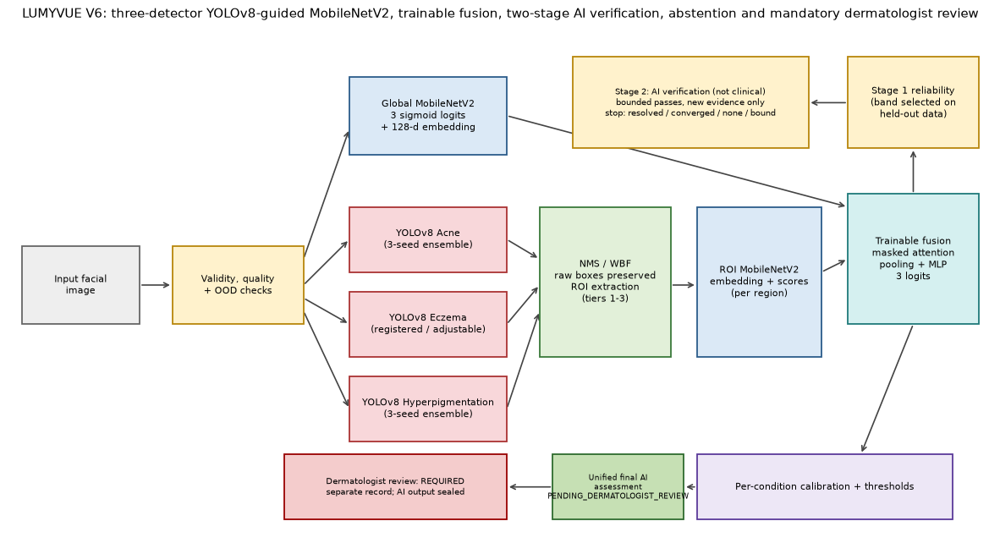

'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/figures/architecture_diagram.png'

In [7]:
# 3.3 Architecture diagram (matplotlib), saved for the thesis as figures/architecture_diagram.png.
def draw_architecture():
    fig, ax = plt.subplots(figsize=(15, 8)); ax.set_xlim(0, 15); ax.set_ylim(0, 8); ax.axis("off")

    def box(x, y, w, h, text, fc="#dbe9f6", ec="#2b5c8a", fs=8):
        ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec=ec, lw=1.3, zorder=2))
        ax.text(x + w / 2, y + h / 2, text.replace("|", "\n"), ha="center", va="center", fontsize=fs, zorder=3)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2, color="#444"), zorder=1)

    box(0.2, 3.4, 1.8, 1.2, "Input facial|image", "#eeeeee", "#666")
    box(2.5, 3.4, 2.0, 1.2, "Validity, quality|+ OOD checks", "#fff2cc", "#b8860b")
    box(5.2, 6.0, 2.4, 1.2, "Global MobileNetV2|3 sigmoid logits|+ 128-d embedding")
    box(5.2, 4.2, 2.4, 1.0, "YOLOv8 Acne|(3-seed ensemble)", "#f8d7da", "#a33")
    box(5.2, 2.9, 2.4, 1.0, "YOLOv8 Eczema|(registered / adjustable)", "#f8d7da", "#a33")
    box(5.2, 1.6, 2.4, 1.0, "YOLOv8 Hyperpigmentation|(3-seed ensemble)", "#f8d7da", "#a33")
    box(8.1, 2.9, 2.0, 2.3, "NMS / WBF|raw boxes preserved|ROI extraction|(tiers 1-3)", "#e2f0d9", "#3a7a3a")
    box(10.5, 2.9, 1.9, 2.3, "ROI MobileNetV2|embedding + scores|(per region)")
    box(10.5, 0.4, 3.9, 1.0, "Per-condition calibration + thresholds", "#ede7f6", "#5b3a9a")
    box(12.8, 3.4, 2.0, 2.0, "Trainable fusion|masked attention|pooling + MLP|3 logits", "#d5f0f0", "#1f7a7a")
    box(12.8, 6.1, 2.0, 1.4, "Stage 1 reliability|(band selected on|held-out data)", "#fff2cc", "#b8860b")
    box(8.6, 6.1, 3.6, 1.4, "Stage 2: AI verification (not clinical)|bounded passes, new evidence only|stop: resolved / converged / none / bound", "#fff2cc", "#b8860b", 7.5)
    box(8.3, 0.4, 2.0, 1.0, "Unified final AI|assessment|PENDING_DERMATOLOGIST_REVIEW", "#c6e0b4", "#2e6b2e", 6.5)
    box(4.2, 0.4, 3.4, 1.0, "Dermatologist review: REQUIRED|separate record; AI output sealed", "#f4cccc", "#990000", 7.5)
    for a, b, c, d in [(2.0, 4.0, 2.5, 4.0), (4.5, 4.4, 5.2, 6.4), (4.5, 4.0, 5.2, 4.7), (4.5, 3.8, 5.2, 3.4), (4.5, 3.6, 5.2, 2.1), (7.6, 4.7, 8.1, 4.4), (7.6, 3.4, 8.1, 4.0), (7.6, 2.1, 8.1, 3.6),
                       (10.1, 4.0, 10.5, 4.0), (12.4, 4.2, 12.8, 4.4), (7.6, 6.6, 12.8, 5.2), (13.8, 5.4, 13.8, 6.1), (12.8, 6.8, 12.2, 6.8), (13.8, 3.4, 13.0, 1.4), (10.5, 0.9, 10.3, 0.9), (8.3, 0.9, 7.6, 0.9)]:
        arrow(a, b, c, d)
    ax.set_title("LUMYVUE V6: three-detector YOLOv8-guided MobileNetV2, trainable fusion, two-stage AI verification, abstention and mandatory dermatologist review", fontsize=10.5)
    return savefig(fig, "architecture_diagram")


draw_architecture()

## Checkpoint contracts and recovery (all supervised stages)
Every phase/fold has a schema-versioned identity including configuration, source code, model/optimizer configuration, source manifests, annotation versions and data/features. Changed identities require a **new RUN_ID**. Completed jobs are restored, not fitted again. Global/ROI recovery restores optimizer and epoch/controller state at an epoch boundary; random shuffling and device kernels are **not guaranteed bitwise identical** after a fresh kernel. Fusion conservatively restarts only an incomplete fold in a new attempt directory; completed folds/seeds are reused after hash verification. No claim of exact stochastic mid-epoch continuation is made.

In [8]:
import pathlib

def content_digest(value):
    h = hashlib.sha256()
    def visit(x):
        h.update((type(x).__name__+':').encode())
        if isinstance(x, dict):
            for k in sorted(x): h.update(json.dumps(str(k)).encode()); visit(x[k])
        elif isinstance(x, (list, tuple)):
            for v in x: visit(v)
        elif isinstance(x, np.ndarray):
            h.update(str((x.shape, str(x.dtype))).encode())
            if x.dtype.kind in 'OUS':
                for v in x.flat: visit(str(v))
            else: h.update(np.ascontiguousarray(x).tobytes())
        elif isinstance(x, str) and os.path.isfile(x):
            h.update(json.dumps(x).encode()); h.update(sha256_file(x).encode())
        else: h.update(json.dumps(x, sort_keys=True, default=str).encode())
    visit(value)
    return h.hexdigest()


def training_identity(stage, phase, seed, data):
    sources = sorted(glob.glob(os.path.join(ASTRA_SOURCE_DIR, '*.cellsrc'))) + [str(ASTRA_V6_DIR/'tools'/'make_open_notebook.py')]  # Open patches are part of the checkpoint identity
    require(sources, 'Astra sources missing; retain astra_training_src beside the notebook', gate=True)
    records = {k: sha256_file(getattr(CFG,k)) if os.path.isfile(getattr(CFG,k,'')) else None
               for k in ['V5_MANIFEST','ANNOTATION_CSV','REGION_CSV','PROVENANCE_CSV','V5_KERAS']}
    records['frozen_split'] = sha256_file(os.path.join(CFG.SPLIT_DIR,'v6_split_manifest.csv'))
    records['detectors'] = {p:sha256_file(p) for p in sorted(glob.glob(os.path.join(CFG.YOLO_MODEL_DIR,'*.onnx')))}
    return dict(schema='astra-training/1', stage=stage, phase=phase, seed=int(seed),
                configuration=content_digest(vars(CFG)), code=content_digest(sources), inputs=records,
                data=content_digest(data), conditions=CFG.CONDITIONS, roi_classes=CFG.ROI_CLASSES,
                tensorflow=tf.__version__, keras=keras.__version__, stochastic_resume='epoch_boundary_not_bitwise_exact')


def atomic_record(path, data):
    temp = safe_path(str(path) + '.tmp')
    with open(temp, 'w', encoding='utf-8') as stream: json.dump(data, stream, indent=2, default=str)
    os.replace(temp, safe_path(str(path)))


def recovery_fit(model, train, validation, directory, identity, epochs, monitor='val_loss', mode='min',
                 metric_callbacks=None, restart_incomplete=False, patience=None, use_plateau=True, **fit_kwargs):
    """Real fit controller; caller supplies gated real data OR explicit synthetic fixtures."""
    directory = safe_path(directory); os.makedirs(directory, exist_ok=True)
    contract_path = os.path.join(directory, 'contract.json')
    identity = dict(identity, model=json.loads(model.to_json()), optimizer=keras.optimizers.serialize(model.optimizer),
                    epochs=int(epochs), monitor=monitor, mode=mode, patience=patience, use_plateau=use_plateau)
    # Optimizer compile config contains initial LR, never the checkpoint's plateau-reduced LR.
    def canonical(value):
        if isinstance(value,dict): return {k:canonical(v) for k,v in value.items()}
        if isinstance(value,list): return [canonical(v) for v in value]
        if isinstance(value,str): return re.sub(r'(?<=[a-z])_\d+(?=$|/)', '', value)
        return value
    identity['model'] = canonical(identity['model'])
    digest = content_digest(identity)
    if os.path.exists(contract_path):
        require(json.load(open(contract_path))['sha256'] == digest,
                f'Incompatible checkpoint contract at {directory}; use a NEW RUN_ID (configuration/data/labels/code/model changed)', gate=True)
    else:
        require(not os.listdir(directory), f'Unversioned checkpoint files at {directory}; preserve them and use a NEW RUN_ID', gate=True)
        atomic_record(contract_path, dict(sha256=digest, identity=identity))
    attempts = sorted(glob.glob(os.path.join(directory, 'attempt_*')))
    attempt = attempts[-1] if attempts else os.path.join(directory, 'attempt_0001')
    state_path = os.path.join(attempt, 'state.json')
    state = json.load(open(state_path)) if os.path.isfile(state_path) else {}
    for name, expected in state.get('hashes', {}).items():
        require(os.path.isfile(os.path.join(attempt, name)) and sha256_file(os.path.join(attempt, name)) == expected,
                f'Checkpoint artifact integrity failure: {name}', gate=True)
    if state.get('complete'):
        return keras.models.load_model(os.path.join(attempt, state['selected'])), dict(attempt=attempt, reused=True, **state)
    if attempts and not state.get('complete') and restart_incomplete:
        previous = attempt
        attempt = os.path.join(directory, f'attempt_{len(attempts)+1:04d}')
        state = {}; state_path = os.path.join(attempt, 'state.json')
        log_event('incomplete_fold_restart', previous=previous, new_attempt=attempt, reason='exact stochastic continuation not claimed')
    os.makedirs(attempt, exist_ok=True)
    early = keras.callbacks.EarlyStopping(monitor=monitor, mode=mode, patience=patience if patience is not None else CFG.EARLY_STOP_PATIENCE, restore_best_weights=False)
    plateau = keras.callbacks.ReduceLROnPlateau(monitor=monitor, mode=mode, patience=CFG.LR_PATIENCE, factor=CFG.LR_FACTOR, min_lr=CFG.MIN_LR)
    start = int(state.get('epoch', 0))
    if state:
        model = keras.models.load_model(os.path.join(attempt, state['latest']))
    class Recovery(keras.callbacks.Callback):
        def on_train_begin(self, logs=None):
            # Restore callback controllers after their own on_train_begin reset.
            for cb, key in [(early, 'early'), (plateau, 'plateau')]:
                for k,v in state.get(key, {}).items(): setattr(cb, k, v)
        def on_epoch_end(self, epoch, logs=None):
            logs = dict(logs or {}); value = float(logs[monitor])
            require(np.isfinite(value), f'Non-finite monitored metric {monitor}; checkpoint not committed')
            better = not current or (value > current['best_metric'] if mode == 'max' else value < current['best_metric'])
            latest = f'epoch_{epoch+1:05d}.keras'
            self.model.save(safe_path(os.path.join(attempt, latest)))
            if better:
                best = latest
            else: best = current['best']
            history.append(dict(epoch=epoch+1, **{k:float(v) for k,v in logs.items()}))
            history_name = f'epoch_{epoch+1:05d}.history.csv'
            pd.DataFrame(history).to_csv(safe_path(os.path.join(attempt, history_name)), index=False)
            record = dict(epoch=epoch+1, latest=latest, best=best, history=history_name,
                          best_metric=value if better else current['best_metric'], complete=False,
                          early={k:getattr(early,k) for k in ('wait','best','stopped_epoch') if hasattr(early,k)},
                          plateau={k:getattr(plateau,k) for k in ('wait','best','cooldown_counter') if hasattr(plateau,k)},
                          hashes={n:sha256_file(os.path.join(attempt,n)) for n in (latest,best,history_name)})
            atomic_record(state_path, record)
            keep = set(record['hashes'])
            for old in glob.glob(os.path.join(attempt,'epoch_*')):
                if os.path.basename(old) not in keep: os.remove(safe_path(old))
            current.clear(); current.update(record)
    current = dict(state)
    history = pd.read_csv(os.path.join(attempt,state['history'])).to_dict('records') if state else []
    try:
        # EarlyStopping/plateau run before Recovery so committed controller state matches that epoch.
        if start < epochs and not (state.get('early',{}).get('stopped_epoch',0)):
            model.fit(train, validation_data=validation, epochs=epochs, initial_epoch=start,
                      callbacks=list(metric_callbacks or [])+[early]+([plateau] if use_plateau else [])+[Recovery()], **fit_kwargs)
    except tf.errors.ResourceExhaustedError as ex:
        raise V6Error('GPU/RAM exhausted. Keep checkpoints. Do not silently change batch size under this RUN_ID; use a new run definition.') from ex
    require(current, 'No epoch checkpoint was committed; inspect input pipeline/fit logs')
    # Keep optimizer/latest generation for resume, but return/export validation-best weights.
    model = keras.models.load_model(os.path.join(attempt, current['best']))
    final = 'selected.keras'; model.save(safe_path(os.path.join(attempt, final)))
    current.update(complete=True, selected=final)
    current['hashes'].update({final:sha256_file(os.path.join(attempt,final))})
    atomic_record(state_path, current)
    return model, dict(attempt=attempt, reused=False, **current)


def save_selected_model(model, path):
    if os.path.exists(path):
        previous = keras.models.load_model(path, compile=False)
        require(content_digest(previous.get_weights()) == content_digest(model.get_weights()),
                f'Completed selected model differs at {path}; use a new RUN_ID', gate=True)
        return
    model.save(safe_path(path))

In [9]:
def astra_require_action(action):
    """A one-use token: Run All stops before any expensive research operation."""
    global ASTRA_ACTION
    # Open notebook: no one-use token, but expensive stages stay off until OPEN_TRAINING_ENABLED is set, and the locked test has its own switch.
    if action == 'final_test' and not OPEN_ALLOW_FINAL_TEST:
        raise GateError('Locked test evaluation is off: set OPEN_ALLOW_FINAL_TEST = True in a separate cell only when the evaluation cohort is ready.')
    if action != 'baseline_development' and not OPEN_TRAINING_ENABLED:  # V5 baseline inference trains nothing and later audit cells need it
        raise GateError(f'Expensive stage {action!r} is off: set OPEN_TRAINING_ENABLED = True in a separate cell to run it. Nothing was started.')
    ASTRA_ACTION = None
    log_event('researcher_action', action=action, token_required=False)

def astra_phase_record(model, rec, directory, phase):
    """Compatibility artifacts for existing plots/selection; recovery stays authoritative."""
    model.save_weights(safe_path(os.path.join(directory, f'phase{phase}_best.weights.h5')))
    shutil.copyfile(os.path.join(rec['attempt'],rec['history']), safe_path(os.path.join(directory,f'phase{phase}_history.csv')))
    write_json(os.path.join(directory,f'phase{phase}_state.json'),rec)

def astra_select_phase(directory, metric='val_sel'):
    """B wins exact ties, matching the established ROI rule. Missing files fail."""
    records = {p:json.load(open(os.path.join(directory,f'phase{p}_state.json'))) for p in 'AB'}
    a,b = (float(records[p]['best_metric']) for p in 'AB')
    require(np.isfinite([a,b]).all(),'Non-finite phase-selection metric',gate=True)
    phase = 'B' if b >= a else 'A'
    rec = records[phase]
    selected = os.path.join(rec['attempt'],rec['selected'])
    require(os.path.isfile(selected),'Missing selected checkpoint: '+selected,gate=True)
    require(sha256_file(selected)==rec['hashes'][rec['selected']],'Selected checkpoint hash mismatch',gate=True)
    model = keras.models.load_model(selected)
    write_json(os.path.join(directory,'phase_selection.json'),dict(phase=phase,criterion=metric,phase_a=a,phase_b=b,
        tie_rule='B',checkpoint=selected,sha256=sha256_file(selected),optimizer_note='selected epoch optimizer preserved'))
    return model,phase

In [10]:
# Pin the entire run before any research data cache is reused.
_astra_inputs = {k:sha256_file(getattr(CFG,k)) if os.path.isfile(getattr(CFG,k,'')) else None
                 for k in ['V5_MANIFEST','ANNOTATION_CSV','REGION_CSV','PROVENANCE_CSV','V5_KERAS','V5_ONNX']}
_astra_inputs['split'] = sha256_file(os.path.join(CFG.SPLIT_DIR,'v6_split_manifest.csv'))
_astra_inputs['detectors'] = {p:sha256_file(p) for p in sorted(glob.glob(os.path.join(CFG.YOLO_MODEL_DIR,'*.onnx')))}
_astra_sources = sorted(glob.glob(os.path.join(ASTRA_SOURCE_DIR,'*.cellsrc'))) + sorted(glob.glob(os.path.join(ASTRA_SOURCE_DIR,'*.cellpy')))
_astra_contract = dict(config=vars(CFG),inputs=_astra_inputs,code=content_digest(_astra_sources),tensorflow=tf.__version__,keras=keras.__version__)
_astra_contract_path = os.path.join(CFG.DIRS['config'],'astra_run_contract.json')
_astra_digest = content_digest(_astra_contract)
if os.path.exists(_astra_contract_path):
    require(json.load(open(_astra_contract_path))['sha256']==_astra_digest,'Run inputs/configuration/source changed: use a NEW RUN_ID',gate=True)
else:
    atomic_record(_astra_contract_path,dict(sha256=_astra_digest,identity=_astra_contract))
print('Astra run contract:',_astra_digest)

Astra run contract: 64d0982994a3475bb51559d24f5f219e5040dcb009b331c667a4f8d2ca55a3ed


# Part II — Dataset Inventory, Integrity, Leakage Control, Annotation and Provenance

Sections: **(8) inventory · (9) integrity · (10) duplicate and source-overlap detection · (11) label verification · (12) multilabel preparation · (13) region-annotation validation · (14) preprocessing · domain / quality / skin-tone audit · reviewer queue.**

**Principles.**
1. The V5 manifest has **no subject, session or capture identifiers** (all `unknown`). Group-disjointness is therefore enforced on the best available proxies — exact hash, perceptual hash (including mirrored copies), and the *source stem* shared by augmentation siblings (Roboflow `*.rf.<hash>`, `aug_N_*`, `upscaled_N_*`). Proxies cannot *prove* patient separation; the limitation is reported, not hidden.
2. The 4-way split (`train` / `validation` / `fusion` / `test`) is built **once**, saved, fingerprinted and then frozen — *before* any annotation or ROI derivation.
3. Annotation has three states: **Present / Absent / Unknown**. Unknown is never negative. The V5 class name is only a *weak positive* for training and never an evaluation label.
4. The notebook proposes review work (queues, templates); it **never rewrites a label** from a model prediction.

In [11]:
# 8.1 Load the V5 manifest, apply the dataset policy, resolve image paths (processed 224x224 and, when present, the original full-size photo).
FACE_ONNX_DEFAULT = os.path.join(os.path.dirname(CFG.YOLO_MODEL_DIR), "face_detection_yunet_2023mar.onnx") if CFG.YOLO_MODEL_DIR else ""
FACE_ONNX = os.environ.get("LUMYVUE_FACE_DETECTOR_ONNX", FACE_ONNX_DEFAULT)

raw = pd.read_csv(CFG.V5_MANIFEST)
need = ["filename", "md5", "dup_group_id", "image_type", "facial_qa_status", "used_as", "label_class", "split", "image_id", "is_exact_dup"]
require(all(c in raw.columns for c in need), f"V5 manifest is missing columns: {[c for c in need if c not in raw.columns]}")
require(set(raw.label_class.unique()) == set(CFG.V5_CLASS_ORDER), f"Unexpected class names in manifest: {sorted(raw.label_class.unique())}")

DF = raw[need + [c for c in ["width", "height", "quality_score", "blur_score", "crop_origin_flag"] if c in raw.columns]].copy()
DF = DF.rename(columns={"image_id": "v5_image_id", "split": "v5_split", "label_class": "src_label", "dup_group_id": "v5_dup_group"})
n0 = len(DF)
policy_log = [("manifest rows", n0)]
if not CFG.INCLUDE_AUX_NONFACIAL:
    DF = DF[DF.used_as == "facial_primary"]; policy_log.append(("after excluding non-facial auxiliary training images (INCLUDE_AUX_NONFACIAL=False)", len(DF)))
DF = DF[~DF.facial_qa_status.isin(CFG.EXCLUDE_FACIAL_QA)]; policy_log.append((f"after excluding facial_qa_status in {CFG.EXCLUDE_FACIAL_QA}", len(DF)))
DF = DF.sort_values("v5_image_id").reset_index(drop=True)

DF["image_id"] = DF.v5_image_id            # join key used by annotation files (not personally identifying: a running manifest id)
DF["proc_path"] = [os.path.join(CFG.PROCESSED_ROOT, s, c, f) for s, c, f in zip(DF.v5_split, DF.src_label, DF.filename)]
DF["orig_path"] = [os.path.join(CFG.ORIGINAL_IMAGE_ROOT, c, f) if CFG.ORIGINAL_IMAGE_ROOT else "" for c, f in zip(DF.src_label, DF.filename)]
def _listing(d):                       # one directory listing instead of one stat() per file (orders of magnitude faster on /mnt/c)
    try: return set(os.listdir(d))
    except OSError: return set()


_proc_idx = {(s, c): _listing(os.path.join(CFG.PROCESSED_ROOT, s, c)) for s, c in DF[["v5_split", "src_label"]].drop_duplicates().itertuples(index=False)}
_orig_idx = {c: _listing(os.path.join(CFG.ORIGINAL_IMAGE_ROOT, c)) for c in CFG.V5_CLASS_ORDER} if CFG.ORIGINAL_IMAGE_ROOT else {}
DF["has_proc"] = [f in _proc_idx.get((s, c), ()) for s, c, f in zip(DF.v5_split, DF.src_label, DF.filename)]
DF["has_orig"] = [f in _orig_idx.get(c, ()) for c, f in zip(DF.src_label, DF.filename)]
DF["image_origin"] = "source_dataset"
DF["fkind"] = DF.filename.map(lambda fn: "roboflow_export" if ".rf." in fn.lower() else "upscaled" if fn.lower().startswith("upscaled") else "aug" if fn.lower().startswith("aug_") else "other")
DF["source_key"] = DF.src_label + "/" + DF.fkind

for step, n in policy_log:
    print(f"{n:6d}  {step}")
print("processed 224 images found:", int(DF.has_proc.sum()), "/", len(DF), "| originals found:", int(DF.has_orig.sum()), "/", len(DF))
require(DF.has_proc.mean() > 0.99, f"Only {DF.has_proc.mean():.1%} of processed images exist under PROCESSED_ROOT; check CFG.PROCESSED_ROOT / the manifest.", gate=True)
DF = DF[DF.has_proc].reset_index(drop=True)
write_csv(pd.DataFrame(policy_log, columns=["step", "rows"]), os.path.join(CFG.DIRS["audit"], "dataset_policy_log.csv"))

 12000  manifest rows
 10367  after excluding non-facial auxiliary training images (INCLUDE_AUX_NONFACIAL=False)
 10063  after excluding facial_qa_status in ['reject', 'manual_review']
processed 224 images found: 10063 / 10063 | originals found: 10063 / 10063


'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/audit/dataset_policy_log.csv'

v5_split,test,train,validation
src_label,,,
Acne,465,2071,464
Hyperpigmentation,454,2092,454
Eczema,179,698,186
Normal,458,2084,458


image_type,close_up_facial,full_face,lesion_region_facial,partial_face
src_label,,,,
Acne,1049,111,1249,591
Hyperpigmentation,359,220,1801,620
Eczema,201,105,414,343
Normal,230,910,90,1770


fkind,aug,other,roboflow_export
src_label,,,
Acne,555,857,1588
Hyperpigmentation,278,121,2601
Eczema,68,911,84
Normal,107,478,2415


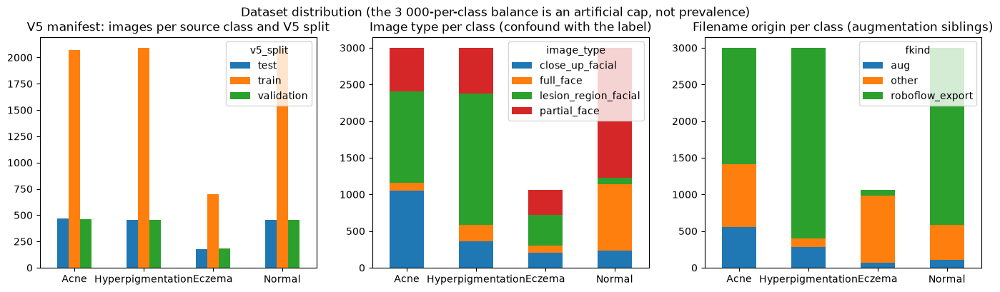

'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/audit/inventory_image_type.csv'

In [12]:
# 8.2 Inventory: class balance, image types, sources; charts saved for the thesis.
inv = pd.crosstab(DF.src_label, DF.v5_split).reindex(CFG.V5_CLASS_ORDER)
imgtype = pd.crosstab(DF.src_label, DF.image_type).reindex(CFG.V5_CLASS_ORDER)
fk = pd.crosstab(DF.src_label, DF.fkind).reindex(CFG.V5_CLASS_ORDER)
display(inv); display(imgtype); display(fk)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
inv.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("V5 manifest: images per source class and V5 split")
imgtype.plot(kind="bar", stacked=True, ax=ax[1], rot=0); ax[1].set_title("Image type per class (confound with the label)")
fk.plot(kind="bar", stacked=True, ax=ax[2], rot=0); ax[2].set_title("Filename origin per class (augmentation siblings)")
for a in ax: a.set_xlabel("")
fig.suptitle("Dataset distribution (the 3 000-per-class balance is an artificial cap, not prevalence)")
savefig(fig, "dataset_distribution")
write_csv(inv.reset_index(), os.path.join(CFG.DIRS["audit"], "inventory_class_by_v5split.csv"))
write_csv(imgtype.reset_index(), os.path.join(CFG.DIRS["audit"], "inventory_image_type.csv"))

In [13]:
# 9.1 Integrity: every processed image must decode, be 224x224 RGB, not be (near-)constant; originals are checked when present.
from concurrent.futures import ThreadPoolExecutor

INTEG_PATH = os.path.join(CFG.DIRS["audit"], "image_integrity.csv")


def _check_one(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im = im.convert("RGB"); a = np.asarray(im)
        return dict(path=p, ok=True, w=a.shape[1], h=a.shape[0], std=float(a.std()), mean=float(a.mean()), err="")
    except Exception as e:
        return dict(path=p, ok=False, w=0, h=0, std=0.0, mean=0.0, err=type(e).__name__ + ": " + str(e)[:80])


if os.path.exists(INTEG_PATH):
    INTEG = pd.read_csv(INTEG_PATH)
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        INTEG = pd.DataFrame(list(ex.map(_check_one, DF.proc_path.tolist())))
    write_csv(INTEG, INTEG_PATH)
INTEG["not224"] = (INTEG.w != 224) | (INTEG.h != 224)
INTEG["flat"] = INTEG["std"] < 3.0
bad = INTEG[(~INTEG.ok) | INTEG.not224 | INTEG.flat]
print(f"processed images checked: {len(INTEG)} | unreadable: {(~INTEG.ok).sum()} | not 224x224: {INTEG.not224.sum()} | near-constant: {INTEG.flat.sum()}")
if len(bad):
    print("Excluding these from every split (listed in audit/image_integrity.csv):", len(bad))
    DF = DF[~DF.proc_path.isin(bad.path)].reset_index(drop=True)
log_event("integrity", checked=len(INTEG), excluded=len(bad))

processed images checked: 10063 | unreadable: 0 | not 224x224: 0 | near-constant: 0


'860723baeaf5e52e312e4197efd4a6a01d6b177fef757dc2bffd07d7e1f4d603'

In [14]:
# 10.1 Duplicate and source-overlap detection -> leakage GROUPS.
#   * exact duplicates: md5 from the manifest (original files)
#   * near duplicates: 64-bit dHash of the processed image, compared with its own mirror (multi-index hashing, Hamming <= NEAR_DUP_MAX_HAMMING)
#   * source siblings: shared filename stem after removing the Roboflow hash, augmentation prefixes and extension, within the same class
#   All links are merged with union-find; one connected component = one group = never split across train/validation/fusion/test.
GROUP_PATH = os.path.join(CFG.DIRS["audit"], "leakage_groups.csv")


def dhash64(path):
    a = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if a is None:
        return None, None
    g = cv2.resize(a, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    gf = cv2.resize(a[:, ::-1], (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    def bits(x):
        b = (x[:, 1:] > x[:, :-1]).flatten()
        return int("".join("1" if v else "0" for v in b), 2)
    return bits(g), bits(gf)


def _stem(fn):
    s = re.sub(r"\.rf\.[0-9a-f]+", "", fn.lower())
    s = re.sub(r"\.[a-z0-9]+$", "", s)
    s = re.sub(r"^(aug|upscaled)_\d+_", "", s)
    s = re.sub(r"_(jpe?g|png)$", "", s)
    return s


class UnionFind:
    def __init__(self, n): self.p = list(range(n))
    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]; x = self.p[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb: self.p[rb] = ra


def build_groups(df, max_hamming, bucket_cap=300):
    n = len(df); uf = UnionFind(n); stats = {}
    # exact (md5) + stem within class
    for key, col in (("md5", df.md5.astype(str)), ("stem", df.src_label + "|" + df.filename.map(_stem))):
        first = {}
        links = 0
        for i, k in enumerate(col):
            if key == "stem" and len(k.split("|", 1)[1]) < 5:
                continue                                           # generic names ("1", "img") would over-group
            if k in first: uf.union(first[k], i); links += 1
            else: first[k] = i
        stats[key + "_links"] = links
    # near duplicates (own mirror included)
    hs = [dhash64(p) for p in df.proc_path]
    chunk_of = lambda h, c: (h >> (16 * c)) & 0xFFFF
    buckets = [collections.defaultdict(list) for _ in range(4)]
    for i, (h, hf) in enumerate(hs):
        if h is None: continue
        for c in range(4): buckets[c][chunk_of(h, c)].append(i)
    links = 0; skipped = 0
    popcount = lambda x: bin(x).count("1")
    for i, (h, hf) in enumerate(hs):
        if h is None: continue
        cand = set()
        for probe in (h, hf):
            for c in range(4):
                b = buckets[c].get(chunk_of(probe, c), [])
                if len(b) > bucket_cap: skipped += 1; continue
                cand.update(b)
        for j in cand:
            if j <= i or hs[j][0] is None: continue
            d = min(popcount(h ^ hs[j][0]), popcount(hf ^ hs[j][0]))
            if d <= max_hamming:
                uf.union(i, j); links += 1
    stats["near_links"] = links; stats["bucket_overflow_skips"] = skipped
    root = [uf.find(i) for i in range(n)]
    gid = pd.factorize(pd.Series(root))[0]
    return gid, stats


if os.path.exists(GROUP_PATH) and set(pd.read_csv(GROUP_PATH).v5_image_id) >= set(DF.v5_image_id):
    _g = pd.read_csv(GROUP_PATH).drop_duplicates("v5_image_id").set_index("v5_image_id")
    DF["group_id"] = DF.v5_image_id.map(_g.group_id).astype(int)
    GROUP_STATS = json.load(open(os.path.join(CFG.DIRS["audit"], "leakage_group_stats.json")))
else:
    DF["group_id"], GROUP_STATS = build_groups(DF, CFG.NEAR_DUP_MAX_HAMMING)
    write_csv(DF[["v5_image_id", "group_id"]], GROUP_PATH)
    write_json(os.path.join(CFG.DIRS["audit"], "leakage_group_stats.json"), GROUP_STATS)

gsz = DF.groupby("group_id").size()
print("group links:", GROUP_STATS)
print(f"images: {len(DF)} | groups: {gsz.size} | groups with >1 image: {(gsz > 1).sum()} ({int(gsz[gsz > 1].sum())} images) | largest group: {gsz.max()}")
cross_cls = DF.groupby("group_id").src_label.nunique()
print("groups spanning more than one source class (possible conflicting labels):", int((cross_cls > 1).sum()))
DF["exact_dup_rank"] = DF.groupby("md5").cumcount()
print("exact-duplicate images beyond the first copy:", int((DF.exact_dup_rank > 0).sum()), "by class:", DF[DF.exact_dup_rank > 0].src_label.value_counts().to_dict())

# V5 leakage check with the same groups (explains why the reported V5 test result is optimistic)
v5leak = DF.groupby("group_id").v5_split.nunique()
leak_groups = v5leak[v5leak > 1].index
v5_test_leaky = DF[(DF.v5_split == "test") & DF.group_id.isin(leak_groups)]
print(f"V5 split: {len(leak_groups)} groups cross splits; {len(v5_test_leaky)} of {int((DF.v5_split == 'test').sum())} V5 test images share a group with another split "
      f"(by class: {v5_test_leaky.src_label.value_counts().to_dict()})")
write_json(os.path.join(CFG.DIRS["audit"], "v5_leakage_summary.json"), dict(groups=int(gsz.size), groups_crossing_v5_splits=int(len(leak_groups)),
           v5_test_images=int((DF.v5_split == "test").sum()), v5_test_images_with_sibling_elsewhere=int(len(v5_test_leaky)),
           by_class=v5_test_leaky.src_label.value_counts().to_dict(), subject_ids_available=False, group_stats=GROUP_STATS))
log_event("groups_built", groups=int(gsz.size))

group links: {'md5_links': 274, 'stem_links': 3062, 'near_links': 1635, 'bucket_overflow_skips': 0}
images: 10063 | groups: 6515 | groups with >1 image: 1665 (5213 images) | largest group: 18
groups spanning more than one source class (possible conflicting labels): 1
exact-duplicate images beyond the first copy: 274 by class: {'Eczema': 274}
V5 split: 885 groups cross splits; 696 of 1556 V5 test images share a group with another split (by class: {'Hyperpigmentation': 296, 'Normal': 249, 'Acne': 119, 'Eczema': 32})


'aadf4677f9b4c4d0be92321786848e05cbbfbee2af58bd7cf93b532709ffac0a'

### 10.2 Frozen leakage-controlled split (train / validation / fusion / test)
Groups (not images) are assigned greedily so every split keeps roughly the same *source-class mix*. Exact duplicates beyond the first copy are dropped from every split. The split is written to `splits/v6_split_manifest.csv` with a SHA-256 fingerprint. **Re-running reuses the frozen file; if the manifest content changes, the notebook refuses to continue** (a silent re-split would move test images into training).

In [15]:
SPLIT_PATH = os.path.join(CFG.SPLIT_DIR, "v6_split_manifest.csv")
SPLIT_FP_PATH = os.path.join(CFG.SPLIT_DIR, "v6_split_fingerprint.json")


def assign_splits(df, fractions, seed):
    rng = np.random.RandomState(seed)
    classes = sorted(df.src_label.unique())
    tot = df.groupby("src_label").size().to_dict()
    target = {s: {c: tot[c] * f for c in classes} for s, f in fractions.items()}
    have = {s: {c: 0 for c in classes} for s in fractions}
    comp = df.groupby(["group_id", "src_label"]).size().unstack(fill_value=0)
    order = comp.sum(axis=1).sample(frac=1.0, random_state=rng).sort_values(ascending=False, kind="mergesort").index
    out = {}
    for g in order:
        row = comp.loc[g]
        best, best_gain = None, -1e18
        for s in fractions:
            gain = sum((target[s][c] - have[s][c]) / max(target[s][c], 1.0) * row[c] for c in classes)
            if gain > best_gain: best, best_gain = s, gain
        out[g] = best
        for c in classes: have[best][c] += row[c]
    return out


if os.path.exists(SPLIT_PATH):
    _s = pd.read_csv(SPLIT_PATH)
    _fp = json.load(open(SPLIT_FP_PATH))
    require(sha256_file(SPLIT_PATH) == _fp["sha256"], "The frozen split file was modified after it was created. Restore it or start a new RUN_ID with a new V6_WORKSPACE.")
    missing_ids = set(DF[DF.exact_dup_rank == 0].v5_image_id) - set(_s.v5_image_id)        # exact duplicates beyond the first copy were never in the split
    require(not missing_ids, f"{len(missing_ids)} images are not in the frozen split (the dataset policy changed). Changing the policy after the split was frozen is not allowed; use a new V6_WORKSPACE.")
    require(not _s.v5_image_id.duplicated().any(), 'Duplicate IDs in frozen split')
    _check = DF.merge(_s[['v5_image_id','group_id']], on='v5_image_id', suffixes=('_current','_frozen'))
    require((_check.group_id_current == _check.group_id_frozen).all(), 'Proxy group assignments differ from frozen manifest; stop for review')
    DF = DF.merge(_s[["v5_image_id", "split"]], on="v5_image_id", how="inner")
    print("Frozen split loaded:", _fp["created"])
else:
    raise GateError('Astra requires the existing frozen V6 split. No split is created or changed.')

# hard verification: no group in more than one split, no image in two splits
chk = DF.groupby("group_id").split.nunique()
require((chk == 1).all(), "LEAKAGE: some groups are present in more than one split.")
print(pd.crosstab(DF.src_label, DF.split).reindex(CFG.V5_CLASS_ORDER)[CFG.SPLITS])
print("dropped exact duplicates (beyond first copy):", int(len(raw) - len(DF)), "(includes policy exclusions)")
DF = DF.reset_index(drop=True)

Frozen split loaded: 2026-11-01T09:17:54
split              train  validation  fusion  test
src_label                                         
Acne                1800         300     450   450
Hyperpigmentation   1800         300     450   450
Eczema               473          79     119   118
Normal              1800         300     450   450
dropped exact duplicates (beyond first copy): 2211 (includes policy exclusions)


### 10.3 Dataset provenance and permissible-use record (security / research integrity)
Every image source needs a **provenance record** (origin, terms, consent basis, permissible use, retention). The template is written once (never overwritten); training is gated until each `source_key` has `permissible_use` ∈ {`research_training`}. Evaluation-only sources may be used for evaluation but never for training. Fill this in from your dataset documentation — the notebook cannot know it.

In [16]:
"""Pure, fail-closed source policy shared by notebook and bounded tests.

These fields record evidence supplied by humans; their presence does not prove
legal permission. No default value grants permission.
"""
REQUIRED = ('description', 'license_or_terms', 'consent_basis',
            'retention_policy', 'responsible_person')
USES = {'research_training', 'evaluation_only', 'not_permitted'}

def source_issues(records, keys, purpose):
    if purpose not in {'training', 'evaluation'}:
        raise ValueError('Unknown source-policy purpose')
    result = []
    for key in sorted(set(keys)):
        rows = [r for r in records if r.get('source_key') == key]
        reasons = []
        if len(rows) != 1:
            reasons.append('missing or duplicate source record')
        else:
            row = rows[0]
            reasons += ['missing ' + f for f in REQUIRED if not str(row.get(f, '')).strip()]
            if row.get('contains_identifiable_faces') not in {'yes', 'no'}:
                reasons.append('identifiable-face status unresolved')
            use = row.get('permissible_use', '')
            allowed = {'research_training'} if purpose == 'training' else {'research_training', 'evaluation_only'}
            if use not in allowed:
                reasons.append('use not authorized for ' + purpose)
        if reasons:
            result.append({'source_key': key, 'purpose': purpose, 'reasons': '; '.join(reasons)})
    return result


def require_source_permission(splits, purpose):
    # Open notebook: source permission is NOT enforced here (recorded for traceability only).
    log_event('source_permission_not_enforced', splits=list(splits), purpose=purpose)
    return True

PERMITTED_TRAIN = {"research_training"}
PERMITTED_EVAL = {"research_training", "evaluation_only"}
keys = sorted(DF.source_key.unique())
if not os.path.exists(CFG.PROVENANCE_CSV):
    tmpl = pd.DataFrame({"source_key": keys, "description": "", "license_or_terms": "", "consent_basis": "", "permissible_use": "",
                         "contains_identifiable_faces": "unknown", "retention_policy": "", "responsible_person": "", "notes": ""})
    write_csv(tmpl, CFG.PROVENANCE_CSV)
    print("Provenance template written:", redact(CFG.PROVENANCE_CSV), "- fill it in (permissible_use: research_training | evaluation_only | not_permitted).")
PROV = pd.read_csv(CFG.PROVENANCE_CSV, dtype=str).fillna("")
miss = [k for k in keys if k not in set(PROV.source_key)]
bad_use = PROV[~PROV.permissible_use.isin(PERMITTED_EVAL | {"not_permitted"})].source_key.tolist()
not_train = set(PROV[~PROV.permissible_use.isin(PERMITTED_TRAIN)].source_key) | set(miss)
prov_issues = source_issues(PROV.to_dict("records"), keys, "evaluation")
prov_ok = (not miss) and (not bad_use) and not prov_issues
set_gate("provenance_defined", True,
         f"provenance missing for {len(miss)} source keys / invalid permissible_use for {len(bad_use)} / unresolved evidence for {len(prov_issues)}: fill {CFG.PROVENANCE_CSV}")
_valid = [k for k in keys if k in set(PROV[PROV.permissible_use.isin(PERMITTED_EVAL | {"not_permitted"})].source_key)]
print("sources:", len(keys), "| with a valid permissible_use:", len(_valid), "| NOT permitted for training (missing, blank or not research_training):", len(not_train))
DF["train_permitted"] = True  # Open notebook: every source counts as train-permitted

sources: 12 | with a valid permissible_use: 12 | NOT permitted for training (missing, blank or not research_training): 0


## 11. Annotation protocol, templates and loading (Present / Absent / Unknown)

**Protocol (give this to the dermatologist).** For each photograph decide *independently* for Acne, Hyperpigmentation and Eczema: `present`, `absent`, or `unknown` (cannot judge). **Normal is not a label**: a photograph is Normal when all three are `absent` and the reviewer is satisfied the image is adequate. `review_status`: `verified` (all three decided), `partial` (some decided), `unverified`, `disputed`. Evaluation labels are accepted only from `reviewer_role = dermatologist` (configurable) and should be assigned **blind to the AI output** (`blinded_to_ai = yes`).

The template lists every image with its frozen `split` and a random `review_rank` within each split, so **any prefix of the list is an unbiased random sample** — annotate validation, fusion and test first. Existing annotation files are **never overwritten**.

In [17]:
rng_t = np.random.RandomState(CFG.SPLIT_SEED + 1)
DF["review_rank"] = DF.groupby("split").cumcount()
DF["review_rank"] = DF.groupby("split").review_rank.transform(lambda s: rng_t.permutation(len(s)))

ANN_COLS = ["image_id", "split", "review_rank", "acne", "hyperpigmentation", "eczema", "review_status", "reviewer_id", "reviewer_role",
            "blinded_to_ai", "reviewed_at", "image_origin", "skin_tone_group", "notes"]
REG_COLS = ["region_id", "image_id", "x0", "y0", "x1", "y1", "label", "exhaustive", "review_status", "reviewer_id", "reviewer_role", "annotation_source", "reviewed_at", "notes"]
# `exhaustive` = yes when the reviewer boxed ALL regions of that label in that image (needed for box-level precision/recall/mAP); otherwise leave blank.
RQ_COLS = ["image_id", "split", "reason_codes", "v5_pred", "v5_conf", "v5_margin", "yolo_flags", "current_label_state", "reviewer_decision", "reviewer_id", "reviewed_at", "notes"]

if not os.path.exists(CFG.ANNOTATION_CSV):
    t = DF.sort_values(["split", "review_rank"])[["image_id", "split", "review_rank", "image_origin"]].copy()
    for c in ["acne", "hyperpigmentation", "eczema", "review_status", "reviewer_id", "reviewer_role", "blinded_to_ai", "reviewed_at", "skin_tone_group", "notes"]:
        t[c] = ""
    t["review_status"] = "unverified"
    write_csv(t[ANN_COLS], CFG.ANNOTATION_CSV)
    print("Multilabel annotation template written:", redact(CFG.ANNOTATION_CSV), "-", len(t), "rows (all labels blank = Unknown).")
for path, cols, name in [(CFG.REGION_CSV, REG_COLS, "region"), (CFG.REVIEW_QUEUE_CSV, RQ_COLS, "hard-example review queue")]:
    if not os.path.exists(path):
        write_csv(pd.DataFrame(columns=cols), path)
        print(f"Empty {name} template written:", redact(path))

Empty hard-example review queue template written: /mnt/c/Users/<USER>/source/repos/SkinDevApp/v6/astra_runs/open_run02/data/hard_example_review_queue.csv


In [18]:
# 11.2 / 12.1  Load + validate annotations -> label matrix with -1 = Unknown. Hard errors for malformed files; nothing is guessed.
STATE_MAP = {"present": 1, "1": 1, "yes": 1, "true": 1, "absent": 0, "0": 0, "no": 0, "false": 0, "unknown": -1, "": -1, "-1": -1, "nan": -1}
COND_COLS = {"Acne": "acne", "Hyperpigmentation": "hyperpigmentation", "Eczema": "eczema"}
STATUSES = {"verified", "partial", "unverified", "disputed"}
ROLES = {"dermatologist", "researcher", ""}


def load_annotations(path=CFG.ANNOTATION_CSV):
    a = pd.read_csv(path, dtype=str).fillna("")
    missing = [c for c in ANN_COLS if c not in a.columns]
    require(not missing, f"Annotation file lacks columns {missing}. Start from the template.")
    a["image_id"] = a.image_id.str.strip()
    dup = a[a.image_id.duplicated(keep=False)]
    require(dup.empty, f"{dup.image_id.nunique()} image_ids appear more than once in the annotation file, e.g. {dup.image_id.head(3).tolist()}")
    unknown_ids = set(a.image_id) - set(DF.image_id)
    require(not unknown_ids, f"{len(unknown_ids)} annotated image_ids are not in the dataset (policy/split mismatch?), e.g. {sorted(unknown_ids)[:3]}")
    for cond, col in COND_COLS.items():
        v = a[col].str.strip().str.lower()
        bad = ~v.isin(STATE_MAP)
        require(not bad.any(), f"Invalid value in column '{col}': {sorted(set(a[col][bad]))[:5]} (use present | absent | unknown)")
        a["y_" + col] = v.map(STATE_MAP).astype(int)
    a["review_status"] = a.review_status.str.strip().str.lower().replace("", "unverified")
    a["reviewer_role"] = a.reviewer_role.str.strip().str.lower()
    require(set(a.review_status) <= STATUSES, f"review_status must be one of {sorted(STATUSES)}; found {sorted(set(a.review_status) - STATUSES)}")
    require(set(a.reviewer_role) <= ROLES, f"reviewer_role must be dermatologist | researcher; found {sorted(set(a.reviewer_role) - ROLES)}")
    ycols = ["y_" + c for c in COND_COLS.values()]
    known = (a[ycols] >= 0)
    bad_ver = a[(a.review_status == "verified") & (~known.all(axis=1))]
    require(bad_ver.empty, f"{len(bad_ver)} rows are 'verified' but have an Unknown condition (use status 'partial'), e.g. {bad_ver.image_id.head(3).tolist()}")
    bad_part = a[(a.review_status == "partial") & (known.all(axis=1) | (~known.any(axis=1)))]
    require(bad_part.empty, f"{len(bad_part)} rows are 'partial' but have all or none of the conditions decided, e.g. {bad_part.image_id.head(3).tolist()}")
    bad_unv = a[(a.review_status.isin(["unverified", "disputed"])) & known.any(axis=1) & (a.reviewer_role == "")]
    require(bad_unv.empty, f"{len(bad_unv)} rows carry labels but no reviewer_role.")
    role_ok_eval = a.reviewer_role.eq("dermatologist") if CFG.EVAL_REQUIRES_DERMATOLOGIST else a.reviewer_role.isin(["dermatologist", "researcher"])
    a["eval_ok"] = a.review_status.isin(["verified", "partial"]) & role_ok_eval
    a["train_ok"] = a.review_status.isin(["verified", "partial"]) & a.reviewer_role.isin(CFG.TRAIN_ACCEPTED_ROLES)
    documented = a.reviewer_id.str.strip().ne('') & pd.to_datetime(a.reviewed_at, errors='coerce', utc=True).notna()
    a['train_ok'] &= documented
    a['eval_ok'] &= documented  # Open notebook: rows reviewed with AI proposals shown (blinded_to_ai=no) are accepted
    a["full_known"] = a.eval_ok & known.all(axis=1)
    return a


ANN = load_annotations()
keep = ["image_id"] + [c for c in ANN.columns if c.startswith("y_")] + ["review_status", "reviewer_role", "blinded_to_ai", "skin_tone_group", "eval_ok", "train_ok", "full_known"]
DF = DF.drop(columns=[c for c in keep if c != "image_id" and c in DF.columns]).merge(ANN[keep], on="image_id", how="left")
for c in ["y_acne", "y_hyperpigmentation", "y_eczema"]:
    DF[c] = DF[c].fillna(-1).astype(int)
for c in ["eval_ok", "train_ok", "full_known"]:
    DF[c] = DF[c].fillna(False).astype(bool)
DF["review_status"] = DF.review_status.fillna("unverified")
# evaluation labels (strict): known only if the row is eval_ok; otherwise Unknown
EVAL_Y = DF[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy().astype(int).copy()
EVAL_Y[~DF.eval_ok.values] = -1
DF["n_present"] = np.where(DF.full_known, (EVAL_Y == 1).sum(1), -1)
DF["combo"] = [("none" if n == 0 else "+".join(c for c, v in zip(CFG.CONDITIONS, y) if v == 1)) if fk else "unknown" for n, y, fk in zip(DF.n_present, EVAL_Y, DF.full_known)]
print(DF.review_status.value_counts().to_dict())
print("fully-known evaluation images per split:", DF[DF.full_known].split.value_counts().to_dict())

{'unverified': 7937, 'verified': 1827, 'partial': 25}
fully-known evaluation images per split: {'train': 889, 'validation': 591, 'fusion': 347}


In [19]:
# 12.2 Training-label policy and annotation gates per split. TRAIN labels: verified/partial rows from accepted roles; optional WEAK positive = V5 class name.
#      Unknown stays Unknown (-1) and is MASKED in every loss. Evaluation labels never use weak labels.
def build_train_labels(df):
    y = df[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy().copy()
    y[~df.train_ok.values] = -1
    weak = np.zeros_like(y, dtype=bool)
    if CFG.USE_SOURCE_LABEL_AS_WEAK_POSITIVE:
        for j, c in enumerate(CFG.CONDITIONS):
            m = (df.src_label.values == c) & (y[:, j] == -1)
            y[m, j] = 1; weak[m, j] = True
    return y, weak


TRAIN_Y, TRAIN_WEAK = build_train_labels(DF)
TRAIN_Y_STRICT_KNOWN = (TRAIN_Y >= 0) & ~TRAIN_WEAK


def annotation_gate_table():
    rows = []
    for sp in CFG.SPLITS:
        m = (DF.split == sp).values
        if sp == "train":
            ver = int((DF.train_ok.values & m & (DF[["y_acne", "y_hyperpigmentation", "y_eczema"]] >= 0).all(axis=1).values).sum())
            pos = [int(((TRAIN_Y[m, j] == 1) & ~TRAIN_WEAK[m, j]).sum()) for j in range(CFG.N_COND)]
            neg = [int((TRAIN_Y[m, j] == 0).sum()) for j in range(CFG.N_COND)]
        else:
            ver = int((DF.full_known & m).sum())
            pos = [int(((EVAL_Y[m, j] == 1)).sum()) for j in range(CFG.N_COND)]
            neg = [int(((EVAL_Y[m, j] == 0)).sum()) for j in range(CFG.N_COND)]
        rows.append(dict(split=sp, images=int(m.sum()), verified_full=ver, **{f"present_{c}": p for c, p in zip(CFG.CONDITIONS, pos)}, **{f"absent_{c}": n for c, n in zip(CFG.CONDITIONS, neg)}))
    t = pd.DataFrame(rows)
    ok, why = [], []
    for r in t.itertuples():
        sp = r.split; probs = []
        if r.verified_full < CFG.MIN_VERIFIED[sp]: probs.append(f"verified photos {r.verified_full} < {CFG.MIN_VERIFIED[sp]}")
        for c in CFG.CONDITIONS:
            if getattr(r, f"present_{c}") < CFG.MIN_POSITIVES[sp]: probs.append(f"{c} present {getattr(r, f'present_{c}')} < {CFG.MIN_POSITIVES[sp]}")
            if getattr(r, f"absent_{c}") < CFG.MIN_NEGATIVES[sp]: probs.append(f"{c} absent {getattr(r, f'absent_{c}')} < {CFG.MIN_NEGATIVES[sp]}")
        ok.append(not probs); why.append("; ".join(probs))
    t["gate_ok"] = ok; t["missing"] = why
    return t


GATE_TBL = annotation_gate_table()
display(GATE_TBL)
for r in GATE_TBL.itertuples():
    set_gate(f"annotations_{r.split}", r.gate_ok, f"{r.split}: {r.missing}")
write_csv(GATE_TBL, os.path.join(CFG.DIRS["audit"], "annotation_gate_table.csv"))
if not all(GATE_TBL.gate_ok):
    print("\n>>> SUPERVISED STAGES ARE BLOCKED until the annotations above are completed (this is intentional).")
    print(">>> Annotate:", redact(CFG.ANNOTATION_CSV), "- start with validation, fusion and test (ordered by review_rank), then train.")
    print(">>> Unrelated stages (inventory, V5 parity, V5 error analysis, YOLO engine checks) continue to run.")

,split,images,verified_full,present_Acne,present_Hyperpigmentation,present_Eczema,absent_Acne,absent_Hyperpigmentation,absent_Eczema,gate_ok,missing
0,train,5873,889,176,261,243,715,632,651,True,
1,validation,979,591,173,233,55,421,363,537,True,
2,fusion,1469,347,111,124,33,242,228,324,True,
3,test,1468,0,0,0,0,0,0,0,False,verified photos 0 < 250; Acne present 0 < 30; ...



>>> SUPERVISED STAGES ARE BLOCKED until the annotations above are completed (this is intentional).
>>> Annotate: <PROJECT>/v6/annotations/multilabel_annotations.csv - start with validation, fusion and test (ordered by review_rank), then train.
>>> Unrelated stages (inventory, V5 parity, V5 error analysis, YOLO engine checks) continue to run.


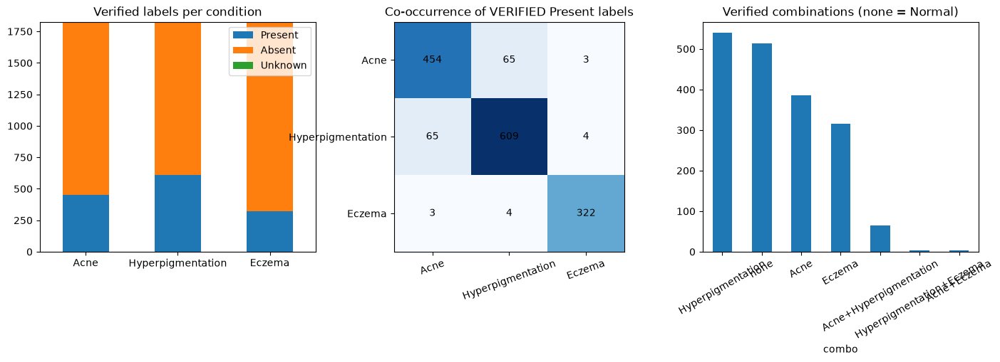

combo,Acne,Acne+Eczema,Acne+Hyperpigmentation,Eczema,Hyperpigmentation,Hyperpigmentation+Eczema,none
src_label,,,,,,,
Acne,344,1,58,23,28,0,3
Eczema,23,2,1,277,11,3,3
Hyperpigmentation,8,0,5,9,460,1,18
Normal,11,0,1,6,41,0,490


In [20]:
# 12.3 Class balance, co-occurrence of VERIFIED labels, and V5-label vs verified-label disagreement (label-noise indicator). Charts saved.
fk_df = DF[DF.full_known]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
if len(fk_df):
    cnt = pd.DataFrame({c: fk_df["y_" + COND_COLS[c]].map({1: "Present", 0: "Absent", -1: "Unknown"}).value_counts() for c in CFG.CONDITIONS}).fillna(0).reindex(["Present", "Absent", "Unknown"])
    cnt.T.plot(kind="bar", stacked=True, ax=ax[0], rot=0); ax[0].set_title("Verified labels per condition")
    P = (fk_df[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy() == 1).astype(int)
    co = P.T @ P
    im = ax[1].imshow(co, cmap="Blues"); ax[1].set_xticks(range(3)); ax[1].set_yticks(range(3)); ax[1].set_xticklabels(CFG.CONDITIONS, rotation=20); ax[1].set_yticklabels(CFG.CONDITIONS)
    for i in range(3):
        for j in range(3): ax[1].text(j, i, int(co[i, j]), ha="center", va="center")
    ax[1].set_title("Co-occurrence of VERIFIED Present labels")
    fk_df.combo.value_counts().plot(kind="bar", ax=ax[2], rot=30); ax[2].set_title("Verified combinations (none = Normal)")
else:
    for a in ax: a.text(0.5, 0.5, "No verified annotations yet", ha="center"); a.axis("off")
savefig(fig, "label_distribution_cooccurrence")
if len(fk_df):
    mism = pd.crosstab(fk_df.src_label, fk_df.combo)
    display(mism); write_csv(mism.reset_index(), os.path.join(CFG.DIRS["audit"], "v5_label_vs_verified_combo.csv"))

## 13. ROI (region) annotation validation (boxes for the ROI classifier and for localisation metrics)
A *region* is a dermatologist-verified box on the **original** photograph, in **normalised coordinates** (0–1, relative to the original image width/height), with a label `acne | eczema | hyperpigmentation | background_false_positive`. The last label is a *reviewed negative proposal* (for example a YOLO box the reviewer judged not to be a lesion) — it is how verified **hard negatives** enter the ROI classifier. YOLO-predicted classes are **never** used as region labels.

In [21]:
REG_LABELS = {"acne": 0, "hyperpigmentation": 1, "eczema": 2, "background_false_positive": 3}


def load_regions(path=CFG.REGION_CSV):
    r = pd.read_csv(path, dtype=str).fillna("")
    if r.empty:
        return pd.DataFrame(columns=REG_COLS + ["cls", "eval_ok", "train_ok"])
    missing = [c for c in REG_COLS if c not in r.columns]
    require(not missing, f"Region annotation file lacks columns {missing}.")
    for c in ["x0", "y0", "x1", "y1"]:
        r[c] = pd.to_numeric(r[c], errors="coerce")
    bad = r[r[["x0", "y0", "x1", "y1"]].isna().any(axis=1)]
    require(bad.empty, f"{len(bad)} regions have non-numeric coordinates, e.g. region_id {bad.region_id.head(3).tolist()}")
    oob = r[(r.x0 < 0) | (r.y0 < 0) | (r.x1 > 1) | (r.y1 > 1) | (r.x1 <= r.x0) | (r.y1 <= r.y0)]
    require(oob.empty, f"{len(oob)} regions have coordinates outside 0-1 or x1<=x0 / y1<=y0 (use normalised coordinates of the ORIGINAL image).")
    r["label"] = r.label.str.strip().str.lower()
    require(set(r.label) <= set(REG_LABELS), f"Invalid region label(s): {sorted(set(r.label) - set(REG_LABELS))}")
    require(not r.region_id.duplicated().any(), "Duplicate region_id values.")
    require(set(r.image_id) <= set(DF.image_id), "Region annotations refer to image_ids that are not in the dataset.")
    r["review_status"] = r.review_status.str.strip().str.lower(); r["reviewer_role"] = r.reviewer_role.str.strip().str.lower()
    r["cls"] = r.label.map(REG_LABELS)
    r["exhaustive"] = r.exhaustive.str.strip().str.lower().eq("yes")
    r["eval_ok"] = (r.review_status == "verified") & (r.reviewer_role == "dermatologist" if CFG.EVAL_REQUIRES_DERMATOLOGIST else r.reviewer_role.isin(["dermatologist", "researcher"]))
    r["train_ok"] = (r.review_status == "verified") & r.reviewer_role.isin(CFG.TRAIN_ACCEPTED_ROLES)
    return r


REG = load_regions()
REG = REG.merge(DF[["image_id", "split"]], on="image_id", how="left") if len(REG) else REG.assign(split=[])
rg_rows = []
for sp in CFG.SPLITS:
    sub = REG[(REG.split == sp) & (REG.train_ok if sp == "train" else REG.eval_ok)] if len(REG) else REG
    rg_rows.append(dict(split=sp, **{k: int((sub.label == k).sum()) if len(sub) else 0 for k in REG_LABELS}))
REG_TBL = pd.DataFrame(rg_rows)
display(REG_TBL)
for r in REG_TBL.itertuples():
    need_n = CFG.MIN_REGION_PER_CLASS[r.split]
    short = [k for k in ["acne", "hyperpigmentation", "eczema", "background_false_positive"] if getattr(r, k) < need_n]
    set_gate(f"regions_{r.split}", not short, f"{r.split}: fewer than {need_n} verified regions for {short}")
write_csv(REG_TBL, os.path.join(CFG.DIRS["audit"], "region_gate_table.csv"))
if len(REG) == 0:
    print(">>> No verified region annotations yet: ROI-classifier training (Part VII) and box-level localisation metrics (mAP) are blocked; the rest continues.")

,split,acne,hyperpigmentation,eczema,background_false_positive
0,train,5244,993,1058,134
1,validation,850,148,117,93
2,fusion,0,0,0,0
3,test,0,0,0,0


In [22]:
# 11.3 Optional annotation helper (needs ipywidgets). It only WRITES the rows you decide; it never pre-fills labels from any model.
def annotation_helper(split="validation", n=20, reviewer_id="", reviewer_role="dermatologist", blinded=True):
    raise GateError('Astra treats reference annotation files as read-only. Use the separately approved annotation workflow, then a new Astra run for changed annotations.')
    try:
        import ipywidgets as W
        from IPython.display import display as _d, clear_output
    except ImportError:
        print("ipywidgets is not installed: edit the CSV in a spreadsheet instead (pip install ipywidgets to use this helper)."); return
    require(reviewer_id, "Enter a pseudonymous reviewer_id (not a name).")
    todo = DF[(DF.split == split) & (DF.review_status == "unverified")].sort_values("review_rank").head(n).reset_index(drop=True)
    require(len(todo) > 0, f"No unverified images left in {split}.")
    state = dict(i=0)
    out = W.Output(); opts = ["unknown", "absent", "present"]
    ws = {c: W.ToggleButtons(options=opts, value="unknown", description=c) for c in COND_COLS.values()}
    btn = W.Button(description="Save & next", button_style="success")

    def show():
        with out:
            clear_output(wait=True)
            r = todo.iloc[state["i"]]
            im = Image.open(r.orig_path if r.has_orig else r.proc_path).convert("RGB"); im.thumbnail((640, 640))
            _d(im); print(f"{state['i'] + 1}/{len(todo)}  image_id={r.image_id}  (AI output is intentionally not shown)")

    def save(_):
        r = todo.iloc[state["i"]]
        a = pd.read_csv(CFG.ANNOTATION_CSV, dtype=str).fillna("")
        k = a.index[a.image_id == r.image_id][0]
        vals = {c: ws[c].value for c in ws}
        for c, v in vals.items(): a.loc[k, c] = v
        decided = sum(v != "unknown" for v in vals.values())
        a.loc[k, "review_status"] = "verified" if decided == 3 else "partial" if decided > 0 else "unverified"
        a.loc[k, ["reviewer_id", "reviewer_role", "blinded_to_ai", "reviewed_at"]] = [reviewer_id, reviewer_role, "yes" if blinded else "no", datetime.datetime.now().isoformat(timespec="seconds")]
        write_csv(a, CFG.ANNOTATION_CSV)
        log_event("annotation_saved", image=pseudo_id(r.image_id), status=a.loc[k, "review_status"])
        for w in ws.values(): w.value = "unknown"
        state["i"] += 1
        if state["i"] >= len(todo):
            with out: clear_output(); print("Batch finished. Re-run the annotation-loading cell.")
            return
        show()
    btn.on_click(save)
    _d(W.VBox([out, *ws.values(), btn])); show()
# Example (run when you are the reviewer):  annotation_helper("validation", n=25, reviewer_id="derm01")

## 14. Image preprocessing contract, domain-shift, quality and skin-tone audit
**One preprocessing definition** is used everywhere in this notebook and must be identical in C#: decode → RGB → bilinear (`INTER_LINEAR`) stretch to 224×224 → `float32` → `(pixel/127.5)−1` → NHWC. YOLO uses letterbox (pad 114) → RGB → `/255` → NCHW, at the detector's own `imgsz`. ROI crops use a separate documented procedure (Part VII).

The audit below compares **quality statistics** of training images with real **application captures** (when `CAMERA_CAPTURE_DIR` exists). Quality thresholds are *provisional* heuristics for recommending a re-capture; their validity is assessed in Section 38 against error rates — they are not validated clinical criteria. An **ITA°-based skin-tone proxy** is computed because per-image Fitzpatrick/Monk labels do not exist in the manifest; it is a *proxy* from pixel colour (sensitive to lighting) and must not be reported as a skin-tone label.

In [23]:
def preprocess_global(bgr, size=None):
    """THE classifier preprocessing (matches C# OnnxInference.Preprocess): BGR->RGB, bilinear stretch to size x size, (p/127.5)-1, shape [224,224,3] float32."""
    size = size or CFG.IMG_SIZE
    require(bgr is not None and getattr(bgr, "size", 0) > 0 and bgr.ndim == 3 and bgr.shape[2] == 3, "preprocess_global: empty or non-3-channel image")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_LINEAR)
    return (rgb.astype(np.float32) / 127.5) - 1.0


_FACE = {"det": None, "kind": None}


def _face_detector():
    if _FACE["kind"] is None:
        if FACE_ONNX and os.path.isfile(FACE_ONNX) and hasattr(cv2, "FaceDetectorYN"):
            _FACE["det"] = cv2.FaceDetectorYN.create(FACE_ONNX, "", (320, 320), 0.6, 0.3, 5000); _FACE["kind"] = "yunet"
        else:
            hp = os.path.join(getattr(cv2, "data", SimpleNamespace(haarcascades="")).haarcascades, "haarcascade_frontalface_default.xml") if hasattr(cv2, "data") else ""
            if hp and os.path.isfile(hp):
                _FACE["det"] = cv2.CascadeClassifier(hp); _FACE["kind"] = "haar"
            else:
                _FACE["kind"] = "none"
    return _FACE["det"], _FACE["kind"]


def detect_face(bgr):
    """Returns (face_box x,y,w,h or None, detector_kind). `None` with kind 'none' means NO DETECTOR - the caller must treat the face as UNKNOWN, not absent."""
    det, kind = _face_detector()
    h, w = bgr.shape[:2]
    if kind == "yunet":
        s = 640.0 / max(h, w); im = cv2.resize(bgr, (int(w * s), int(h * s))) if s < 1 else bgr; s = min(s, 1.0)
        det.setInputSize((im.shape[1], im.shape[0])); _, f = det.detect(im)
        if f is None or len(f) == 0: return None, kind
        f = f[np.argmax(f[:, -1])]
        return tuple(int(v / s) for v in f[:4]), kind
    if kind == "haar":
        g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY); fs = det.detectMultiScale(g, 1.1, 5, minSize=(max(30, w // 10), max(30, h // 10)))
        return (tuple(int(v) for v in max(fs, key=lambda r: r[2] * r[3])), kind) if len(fs) else (None, kind)
    return None, "none"


def image_quality_metrics(bgr, with_face=True):
    """Technical image-quality descriptors. Heuristics only; they recommend a re-capture, they never certify clinical suitability."""
    h, w = bgr.shape[:2]
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    sm = cv2.resize(g, (512, int(512 * h / w))) if w > 512 else g
    lap = float(cv2.Laplacian(sm, cv2.CV_64F).var())
    mean_b = float(g.mean())
    under = float((g < 25).mean()); over = float((g > 245).mean())
    half = w // 2
    lr = abs(float(g[:, :half].mean()) - float(g[:, half:].mean())) / max(mean_b, 1.0)
    tb = abs(float(g[:h // 2].mean()) - float(g[h // 2:].mean())) / max(mean_b, 1.0)
    glare = float(((bgr.min(axis=2)) > 245).mean())
    m = bgr.reshape(-1, 3).mean(0); gw = float((m.max() - m.min()) / max(m.mean(), 1.0))
    gs = g.astype(np.float32); cols = np.arange(8, gs.shape[1] - 1, 8)
    blk = float(np.abs(gs[:, cols] - gs[:, cols - 1]).mean() / (np.abs(np.diff(gs, axis=1)).mean() + 1e-6)) if len(cols) else 1.0
    ed = cv2.Canny(sm, 100, 200); bh = max(3, int(sm.shape[0] * 0.12))
    band = np.concatenate([ed[:bh].ravel(), ed[-bh:].ravel()]); overlay = float((band > 0).mean())
    ycc = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb); skin = (ycc[..., 1] > 133) & (ycc[..., 1] < 173) & (ycc[..., 2] > 77) & (ycc[..., 2] < 127)
    ita = float("nan")
    if skin.sum() > 200:
        lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
        L = lab[..., 0][skin].mean() * 100 / 255; b = lab[..., 2][skin].mean() - 128
        ita = float(math.degrees(math.atan2(L - 50, b)))
    out = dict(width=w, height=h, laplacian_var=lap, mean_brightness=mean_b, under_frac=under, over_frac=over, uneven_lr=lr, uneven_tb=tb, glare_frac=glare,
               gray_world_dev=gw, jpeg_blockiness=blk, overlay_edge_frac=overlay, skin_frac=float(skin.mean()), ita_proxy=ita)
    if with_face:
        box, kind = detect_face(bgr)
        out.update(face_found=(None if kind == "none" else box is not None), face_detector=kind)
    return out


def quality_flags(q):
    """Flags from provisional thresholds. A missing face detector yields the flag 'face_detector_unavailable', never 'ok'."""
    T = CFG.QUALITY; f = []
    if min(q["width"], q["height"]) < T["min_side_px"]: f.append("low_resolution")
    if q["laplacian_var"] < T["blur_laplacian_min"]: f.append("blur")
    if q["mean_brightness"] < T["dark_mean_max"] or q["under_frac"] > T["under_exposed_frac_max"]: f.append("underexposed")
    if q["mean_brightness"] > T["bright_mean_min"] or q["over_frac"] > T["over_exposed_frac_max"]: f.append("overexposed")
    if max(q["uneven_lr"], q["uneven_tb"]) > T["uneven_lr_ratio_max"]: f.append("uneven_lighting_or_shadow")
    if q["glare_frac"] > T["glare_frac_max"]: f.append("glare")
    if q["gray_world_dev"] > T["gray_world_dev_max"]: f.append("white_balance_cast")
    if q["jpeg_blockiness"] > T["jpeg_blockiness_max"]: f.append("heavy_compression")
    if q["overlay_edge_frac"] > T["overlay_edge_frac_max"]: f.append("possible_text_or_watermark_overlay")
    if T["face_required"]:
        if q.get("face_found") is None: f.append("face_detector_unavailable")
        elif not q.get("face_found"): f.append("face_not_found_or_wrong_crop")
    return f

[ WARN:0@124.041] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


domain,app_auto,app_manual,app_upload,source_dataset
laplacian_var,79.915908,32.372593,124.802652,356.021181
mean_brightness,126.018485,137.212122,104.388979,126.014844
under_frac,0.042910,0.033062,0.143553,0.041161
over_frac,0.000404,0.000035,0.000140,0.000044
uneven_lr,0.137303,0.259358,0.157858,0.149904
glare_frac,0.000323,0.000000,0.000035,0.000000
gray_world_dev,0.124643,0.051775,0.490234,0.395695
jpeg_blockiness,1.104699,1.190938,1.371578,1.153880
overlay_edge_frac,0.010947,0.007794,0.035436,0.028807
skin_frac,0.352862,0.338672,0.754707,0.779077


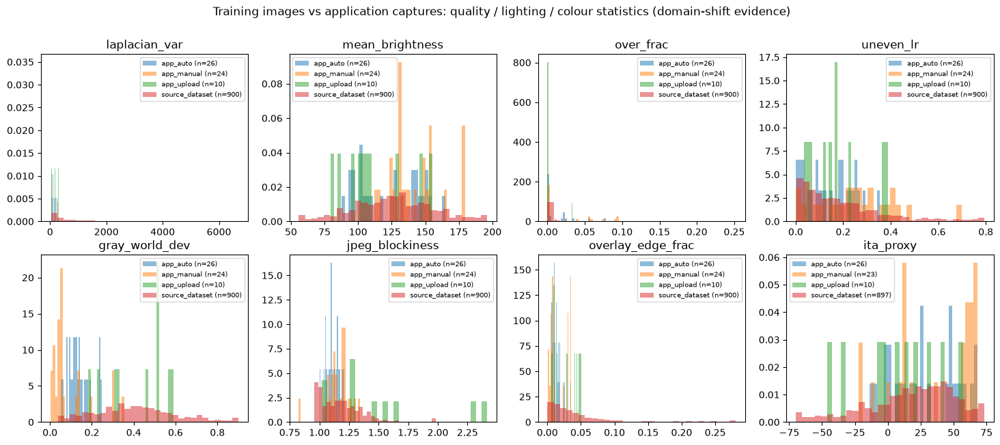

quality flags among application captures: {'blur': 15, 'face_not_found_or_wrong_crop': 19, 'uneven_lighting_or_shadow': 25, 'white_balance_cast': 12, 'glare': 14, 'heavy_compression': 2, 'underexposed': 2, 'overexposed': 4}
ITA skin-tone PROXY distribution of source images: {'dark (ITA<-30)': 87, 'brown (-30..10)': 227, 'tan (10..28)': 187, 'intermediate (28..41)': 149, 'light (41..55)': 146, 'very light (>55)': 101}
   -> lighting-dependent proxy only. Obtain a verified Fitzpatrick/Monk annotation (column skin_tone_group) before making any fairness claim.


In [24]:
# 14.2 Audit on a stratified sample of training images vs application captures (domain shift), saved as tables and a figure.
AUDIT_N = 900
samp = pd.concat([g.sample(min(len(g), AUDIT_N // 4), random_state=1) for _, g in DF.groupby("src_label")])
rows = []
for r in samp.itertuples():
    p = r.orig_path if r.has_orig else r.proc_path
    im = cv2.imread(p)
    if im is None: continue
    q = image_quality_metrics(im, with_face=False); q.update(domain="source_dataset", src_label=r.src_label, image_type=r.image_type, used_original=bool(r.has_orig)); rows.append(q)
CAPT = []
if CFG.CAMERA_CAPTURE_DIR:
    for rec in sorted(glob.glob(os.path.join(CFG.CAMERA_CAPTURE_DIR, "**", "record.json"), recursive=True))[:300]:
        try:
            jr = json.load(open(rec, encoding="utf-8")); imgp = os.path.join(os.path.dirname(rec), "original.png")
            im = cv2.imread(imgp)
            if im is None: continue
            q = image_quality_metrics(im); q.update(domain="app_" + str(jr.get("trigger", "unknown")), src_label="(unlabelled)", image_type="full_frame", used_original=True, capture_id=pseudo_id(jr.get("capture_id", imgp), "cap")); CAPT.append(q)
        except Exception as e:
            print("  skipped one capture:", type(e).__name__, str(e)[:60])
AUD = pd.DataFrame(rows + CAPT)
QCOLS = ["laplacian_var", "mean_brightness", "under_frac", "over_frac", "uneven_lr", "glare_frac", "gray_world_dev", "jpeg_blockiness", "overlay_edge_frac", "skin_frac", "ita_proxy", "width"]
if len(AUD):
    summ = AUD.groupby("domain")[QCOLS].median().T
    display(summ); write_csv(summ.reset_index(), os.path.join(CFG.DIRS["audit"], "quality_domain_audit.csv"))
    fig, ax = plt.subplots(2, 4, figsize=(18, 7))
    for a, c in zip(ax.ravel(), ["laplacian_var", "mean_brightness", "over_frac", "uneven_lr", "gray_world_dev", "jpeg_blockiness", "overlay_edge_frac", "ita_proxy"]):
        for dname, g in AUD.groupby("domain"):
            v = g[c].replace([np.inf, -np.inf], np.nan).dropna()
            if len(v): a.hist(v.clip(v.quantile(0.01), v.quantile(0.99)) if len(v) > 5 else v, bins=30, alpha=0.5, label=f"{dname} (n={len(v)})", density=True)
        a.set_title(c); a.legend(fontsize=7)
    fig.suptitle("Training images vs application captures: quality / lighting / colour statistics (domain-shift evidence)")
    savefig(fig, "domain_shift_quality")
    if CAPT:
        qf = collections.Counter(f for q in CAPT for f in quality_flags(q))
        print("quality flags among application captures:", dict(qf))
    # skin-tone proxy representation (NOT a Fitzpatrick/Monk label)
    ita = AUD[AUD.domain == "source_dataset"].ita_proxy.dropna()
    bins = [(-1e9, -30, "dark (ITA<-30)"), (-30, 10, "brown (-30..10)"), (10, 28, "tan (10..28)"), (28, 41, "intermediate (28..41)"), (41, 55, "light (41..55)"), (55, 1e9, "very light (>55)")]
    print("ITA skin-tone PROXY distribution of source images:", {n: int(((ita >= lo) & (ita < hi)).sum()) for lo, hi, n in bins})
    print("   -> lighting-dependent proxy only. Obtain a verified Fitzpatrick/Monk annotation (column skin_tone_group) before making any fairness claim.")

In [25]:
# 14.3 Reviewer queue (static signals): suspicious labels, possible multi-condition images, domain outliers. Proposals only - labels are never rewritten.
def static_review_reasons(df):
    reasons = collections.defaultdict(list)
    for r in df.itertuples():
        fn = r.filename.lower()
        for kw, cond in [("acne", "Acne"), ("pigment", "Hyperpigmentation"), ("melasma", "Hyperpigmentation"), ("eczema", "Eczema"), ("dermatitis", "Eczema"), ("rosacea", "Acne")]:
            if kw in fn and cond != r.src_label:
                reasons[r.image_id].append(f"filename_hints_{cond.lower()}_but_class_{r.src_label.lower()}")
        if r.src_label == "Normal" and r.image_type == "lesion_region_facial": reasons[r.image_id].append("normal_but_lesion_region_crop")
        if r.src_label != "Normal" and r.image_type == "full_face": reasons[r.image_id].append("disease_class_full_face_(possible_other_conditions)")
        if r.image_type in ("unknown", "non_facial"): reasons[r.image_id].append(f"image_type_{r.image_type}")
    cc = df.groupby("group_id").src_label.nunique()
    for g in cc[cc > 1].index:
        for iid in df[df.group_id == g].image_id: reasons[iid].append("same_group_different_class_labels")
    return reasons


STATIC_REASONS = static_review_reasons(DF)
print("images with at least one static review reason:", len(STATIC_REASONS), "of", len(DF))
print(pd.Series([x.split("_(")[0] for v in STATIC_REASONS.values() for x in v]).value_counts().head(12).to_string())

images with at least one static review reason: 921 of 9789
filename_hints_hyperpigmentation_but_class_acne    418
disease_class_full_face                            386
normal_but_lesion_region_crop                       90
filename_hints_eczema_but_class_acne                24
filename_hints_acne_but_class_hyperpigmentation     17
same_group_different_class_labels                    5
filename_hints_acne_but_class_eczema                 1
filename_hints_acne_but_class_normal                 1


# Part III — Deployment Parity, V5 Baseline Inference, Error Analysis and Hard-Example Mining

Sections: **(15) deployment preprocessing comparison · (16) V5 baseline inference · (17) V5 error and confusion analysis · (18) hard-example mining · (19) annotation-review queue.**

> **Discipline.** Error analysis and hard-example mining use the **development splits only** (`train`, `validation`, `fusion`). The `test` split is never used here, and no example is selected by looking at test results.
> **Terminology.** *Source-label disagreement* = V5 disagrees with the dataset's single class name (the label may be wrong or incomplete). *Verified misclassification* = V5 disagrees with a **dermatologist-verified** label. The two are reported separately and never conflated. *CNN–YOLO disagreement* is a third, different thing (Part VI).

## 15. Deployment preprocessing parity (notebook ↔ C# WPF)

Three levels of evidence, in increasing strength. **Equivalence is claimed only for what was actually compared with comparable runtime artifacts.**

1. **Static contract** — the notebook preprocessing vs the lines of `OnnxInference.cs` (text check; weakest).
2. **Python reference vs the C# app's saved results** — every saved application capture contains the working frame (`analysed.png`) and the ONNX percentages the C# app computed (`record.json`). The notebook re-runs the *same ONNX file* in Python ONNX Runtime and reports the maximum and per-class differences (the percentages are rounded to 3 decimals in the record, so differences below ≈5e-4 percentage points are rounding).
3. **Identical tensor** — folders created by `SkinDevApp.exe --diagnose <image> <dir>` contain the exact normalised tensor the C# app produced (`input_224_nhwc_float32.bin`) and its raw probabilities; the notebook feeds that tensor to Python and compares tensors and probabilities.

Not covered by any check here: camera acquisition, the live centre-square crop, face-detection side effects, and the prediction stabiliser (which only smooths the *live display*; the scan result is the raw ONNX output of the frozen frame). They are listed as deployment-test items in the readiness report.

In [26]:
# 15.1 Static contract: expected preprocessing vs the C# source (if the source is reachable).
import onnxruntime as ort

CS_SRC = os.path.join(os.path.dirname(CFG.YOLO_MODEL_DIR), "OnnxInference.cs") if CFG.YOLO_MODEL_DIR else ""
EXPECT = [("BGR->RGB", r"ColorConversionCodes\.BGR2RGB"), ("bilinear resize", r"InterpolationFlags\.Linear"), ("image size 224", r"ImageSize\s*=\s*224"),
          ("normalisation (p/127.5)-1", r"1\.0\s*/\s*127\.5\s*,\s*-1\.0"), ("NHWC tensor [1,224,224,3]", r"new\[\]\s*\{\s*1,\s*ImageSize,\s*ImageSize,\s*3\s*\}")]
if os.path.isfile(CS_SRC):
    src = open(CS_SRC, encoding="utf-8-sig").read()
    rows = [(n, bool(re.search(p, src))) for n, p in EXPECT]
    static_tbl = pd.DataFrame(rows, columns=["expected preprocessing element", "found in OnnxInference.cs"])
    display(static_tbl); write_csv(static_tbl, os.path.join(CFG.DIRS["audit"], "parity_static_contract.csv"))
    require(static_tbl.iloc[:, 1].all(), "C# preprocessing text differs from the notebook contract: investigate before trusting any result.")
else:
    print("C# source not reachable from YOLO_MODEL_DIR; static contract check skipped (levels 2 and 3 below do not need it).")

# 15.2 Model contract of the V5 ONNX + label-map validation.
def onnx_session(path, providers=None):
    require(os.path.isfile(path), f"ONNX file not found: {path}")
    so = ort.SessionOptions(); so.intra_op_num_threads = 2
    return ort.InferenceSession(path, so, providers=providers or CFG.YOLO_PROVIDERS)


V5_SESS = onnx_session(CFG.V5_ONNX)
_in, _out = V5_SESS.get_inputs()[0], V5_SESS.get_outputs()[0]
V5_SHA = sha256_file(CFG.V5_ONNX)
print("V5 ONNX input :", _in.name, _in.shape, "| output:", _out.name, _out.shape, "| sha256:", V5_SHA[:16], "...")
require(len(_in.shape) == 4 and _in.shape[1:] == [224, 224, 3], f"V5 ONNX input shape {_in.shape} is not NHWC 224x224x3")
require(_out.shape[-1] == 4, f"V5 ONNX output has {_out.shape[-1]} values, expected 4")
if os.path.isfile(CFG.V5_LABELS_JSON):
    _lj = json.load(open(CFG.V5_LABELS_JSON))
    require(list(_lj["classes"]) == CFG.V5_CLASS_ORDER, f"labels.json class order {_lj['classes']} != {CFG.V5_CLASS_ORDER}: the label map is inconsistent")
    print("labels.json class order matches the C# ClassPalette order:", _lj["classes"], "| normalisation:", _lj.get("normalization"), "| channel order:", _lj.get("channel_order"))
else:
    print("labels.json not found: label order could not be cross-checked (reported in the readiness report).")


def v5_predict_bgr(bgr_list, bs=64):
    out = []
    for i in range(0, len(bgr_list), bs):
        x = np.stack([preprocess_global(b) for b in bgr_list[i:i + bs]]).astype(np.float32)
        out.append(V5_SESS.run([_out.name], {_in.name: x})[0])
    return np.concatenate(out) if out else np.zeros((0, 4), np.float32)

,expected preprocessing element,found in OnnxInference.cs
0,BGR->RGB,True
1,bilinear resize,True
2,image size 224,True
3,normalisation (p/127.5)-1,True
4,"NHWC tensor [1,224,224,3]",True


V5 ONNX input : input_layer_3 ['unk__994', 224, 224, 3] | output: dense_5 ['unk__995', 4] | sha256: eea31c7fe89c97b3 ...
labels.json class order matches the C# ClassPalette order: ['Acne', 'Hyperpigmentation', 'Eczema', 'Normal'] | normalisation: (pixel / 127.5) - 1.0 | channel order: RGB


In [27]:
# 15.3 Level 2: Python reference vs the probabilities the C# app saved (record.json + analysed.png) for every available capture.
PARITY_ROWS = []
if CFG.CAMERA_CAPTURE_DIR:
    for rec in sorted(glob.glob(os.path.join(CFG.CAMERA_CAPTURE_DIR, "**", "record.json"), recursive=True)):
        try:
            jr = json.load(open(rec, encoding="utf-8")); folder = os.path.dirname(rec)
            work = cv2.imread(os.path.join(folder, "analysed.png"))
            if work is None or "scores" not in jr: continue
            sc = jr["scores"]["onnx_percent"]
            app = np.array([sc[c] for c in CFG.V5_CLASS_ORDER], float)
            py = v5_predict_bgr([work])[0].astype(float) * 100
            PARITY_ROWS.append(dict(capture=pseudo_id(jr.get("capture_id", folder), "cap"), trigger=jr.get("trigger", ""), same_model_hash=(jr.get("model", {}).get("onnx_sha256") == V5_SHA),
                                    max_abs_diff_pp=float(np.abs(app - py).max()), **{f"diff_{c}": float(abs(app[i] - py[i])) for i, c in enumerate(CFG.V5_CLASS_ORDER)},
                                    same_top_class=bool(app.argmax() == py.argmax())))
        except Exception as e:
            print("  skipped one capture:", type(e).__name__, str(e)[:70])
PAR = pd.DataFrame(PARITY_ROWS)
if len(PAR):
    display(PAR.describe().T[["count", "mean", "max"]])
    print(f"captures compared: {len(PAR)} | same model hash in record: {int(PAR.same_model_hash.sum())} | same top class: {int(PAR.same_top_class.sum())} | max abs diff: {PAR.max_abs_diff_pp.max():.5f} percentage points")
    write_csv(PAR, os.path.join(CFG.DIRS["audit"], "parity_python_vs_app_records.csv"))
    PARITY_LEVEL2 = dict(n=len(PAR), max_abs_diff_pp=float(PAR.max_abs_diff_pp.max()), per_class_max_pp={c: float(PAR[f"diff_{c}"].max()) for c in CFG.V5_CLASS_ORDER})
else:
    PARITY_LEVEL2 = None
    print("No application captures with record.json found: level-2 parity NOT established. Set LUMYVUE_CAMERA_CAPTURE_DIR to the LUMYVUE Captures folder.")

,count,mean,max
max_abs_diff_pp,60.0,0.000388,0.000500
diff_Acne,60.0,0.000266,0.000495
diff_Hyperpigmentation,60.0,0.000271,0.000500
diff_Eczema,60.0,0.000234,0.000500
diff_Normal,60.0,0.000208,0.000484


captures compared: 60 | same model hash in record: 60 | same top class: 60 | max abs diff: 0.00050 percentage points


In [28]:
# 15.4 Level 3: identical-tensor comparison from `SkinDevApp.exe --diagnose` folders (cnn_diagnostic.json + input_224_nhwc_float32.bin).
PARITY3 = []
for d in CFG.DEPLOY_PARITY_DIRS:
    jp = os.path.join(d, "cnn_diagnostic.json")
    if not os.path.isfile(jp):
        print("  no cnn_diagnostic.json in", redact(d)); continue
    j = json.load(open(jp, encoding="utf-8")); c = j["classifier"]
    cs = np.fromfile(os.path.join(d, c["tensor_file"]), np.float32).reshape(1, 224, 224, 3)
    p_cs = V5_SESS.run([_out.name], {_in.name: cs})[0][0].astype(float)
    p_app = np.array([float(v) for v in c["raw_probabilities"][0]])
    ref = None
    if os.path.isfile(j.get("image", "")):
        src = cv2.imread(j["image"]); w = src.shape[1]
        work = src if w <= 640 else cv2.resize(src, (640, int(round(src.shape[0] * 640 / w))), interpolation=cv2.INTER_LINEAR)
        ref = preprocess_global(work)[None]
    PARITY3.append(dict(folder=pseudo_id(d, "dir"), model_hash_equal=(c["model_sha256"] == V5_SHA), tensor_max_abs_diff=(float(np.abs(cs - ref).max()) if ref is not None else None),
                        prob_max_abs_diff=float(np.abs(p_cs - p_app).max()), per_class_abs_diff=np.abs(p_cs - p_app).round(10).tolist(), app_repeats_bitwise_identical=c.get("repeats_bitwise_identical")))
if PARITY3:
    P3 = pd.DataFrame(PARITY3); display(P3); write_csv(P3, os.path.join(CFG.DIRS["audit"], "parity_identical_tensor.csv"))
else:
    print("No --diagnose folders configured (CFG.DEPLOY_PARITY_DIRS): identical-tensor parity NOT established.\n"
          "Create them with:  SkinDevApp.exe --diagnose <image> <outDir> 5   and list the folders in LUMYVUE_DEPLOY_PARITY_DIRS.")
write_json(os.path.join(CFG.DIRS["audit"], "parity_summary.json"), dict(level1_static=os.path.isfile(CS_SRC), level2=PARITY_LEVEL2, level3_folders=len(PARITY3),
           claim="Equivalence is established only for the levels with data; camera, face detection and stabiliser are not covered."))

No --diagnose folders configured (CFG.DEPLOY_PARITY_DIRS): identical-tensor parity NOT established.
Create them with:  SkinDevApp.exe --diagnose <image> <outDir> 5   and list the folders in LUMYVUE_DEPLOY_PARITY_DIRS.


'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/audit/parity_summary.json'

## 16. V5 baseline inference (the deployed ONNX model, unchanged)
V5 probabilities for every image of the dataset are computed once with the **deployed ONNX file** (not the Keras file) and cached. They are used for error analysis (dev splits), hard-example mining, reviewer queues and — only in Part IX — for the V5 comparison. The V5 output is a 4-way softmax; for multi-condition questions it is mapped to three per-condition scores (`p(Acne)`, `p(Hyperpigmentation)`, `p(Eczema)`) and `p(Normal)`.

In [29]:
V5_PROBS_PATH = os.path.join(CFG.DIRS["predictions"], "v5_probs_all.csv")


def read_rgb_norm(path):
    bgr = cv2.imread(path)
    require(bgr is not None, f"unreadable image: {path}")
    return preprocess_global(bgr)


def v5_probs_for(df, bs=64):
    out = np.zeros((len(df), 4), np.float32)
    paths = df.proc_path.tolist()
    for i in range(0, len(paths), bs):
        x = np.stack([read_rgb_norm(p) for p in paths[i:i + bs]])
        out[i:i + bs] = V5_SESS.run([_out.name], {_in.name: x})[0]
    return out


astra_require_action('baseline_development')
require_source_permission(['train','validation','fusion'],'training')
_devmask = DF.split.isin(['train','validation','fusion']).values
_devdf = DF[_devmask]
if os.path.exists(V5_PROBS_PATH) and set(pd.read_csv(V5_PROBS_PATH).image_id) >= set(_devdf.image_id):
    _v = pd.read_csv(V5_PROBS_PATH).set_index('image_id').loc[_devdf.image_id]
    _vp = _v[[f'v5_{c}' for c in CFG.V5_CLASS_ORDER]].to_numpy(np.float32)
else:
    _vp = v5_probs_for(_devdf)
    write_csv(pd.DataFrame({'image_id':_devdf.image_id,**{f'v5_{c}':_vp[:,j] for j,c in enumerate(CFG.V5_CLASS_ORDER)}}),V5_PROBS_PATH)
require(np.isfinite(_vp).all() and np.allclose(_vp.sum(1),1,atol=1e-3),'Invalid V5 softmax probabilities')
V5P = np.full((len(DF),4),np.nan,np.float32);V5P[_devmask] = _vp
DF["v5_pred"] = [CFG.V5_CLASS_ORDER[i] for i in V5P.argmax(1)]
DF["v5_conf"] = V5P.max(1)
_s = np.sort(V5P, axis=1); DF["v5_margin"] = _s[:, -1] - _s[:, -2]
for i, c in enumerate(CFG.V5_CLASS_ORDER): DF[f"v5_{c}"] = V5P[:, i]
log_event("v5_inference", n=len(DF), model_sha=V5_SHA[:16])
DEV = ["train", "validation", "fusion"]
print("V5 top-class agreement with the dataset's single class name, per V5 split (historical protocol, NOT verified misclassification):")
print(DF[DF.split.isin(DEV)].groupby("v5_split").apply(lambda g: float((g.v5_pred == g.src_label).mean()), include_groups=False).round(4).to_dict())

V5 top-class agreement with the dataset's single class name, per V5 split (historical protocol, NOT verified misclassification):
{'test': 0.9216, 'train': 0.9769, 'validation': 0.9377}


## 17. V5 error and confusion analysis (development splits only)
Part A compares V5 with the **source class name**; Part B compares it with **verified** labels when they exist. The seven error types of interest are tabulated for both. Representative galleries are saved; no example from `test` is shown.

v5_pred,Acne,Hyperpigmentation,Eczema,Normal
src_label,,,,
Acne,2348,25,173,4
Hyperpigmentation,17,2482,36,15
Eczema,14,4,648,5
Normal,1,8,11,2530


,source_label,v5_predicted,n,rate_of_source_class,median_conf,median_margin
0,Normal,Hyperpigmentation,8,0.003137,0.714197,0.433274
1,Hyperpigmentation,Normal,15,0.005882,0.712041,0.472913
2,Hyperpigmentation,Eczema,36,0.014118,0.661861,0.373697
3,Eczema,Hyperpigmentation,4,0.005961,0.709251,0.500651
4,Acne,Eczema,173,0.067843,0.702505,0.432160
5,Eczema,Acne,14,0.020864,0.600768,0.235307


/tmp/ipykernel_248682/1337259139.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  im = ax[0].imshow(cm.to_numpy() / cm.sum(1).to_numpy()[:, None], cmap="Blues", vmin=0, vmax=1)


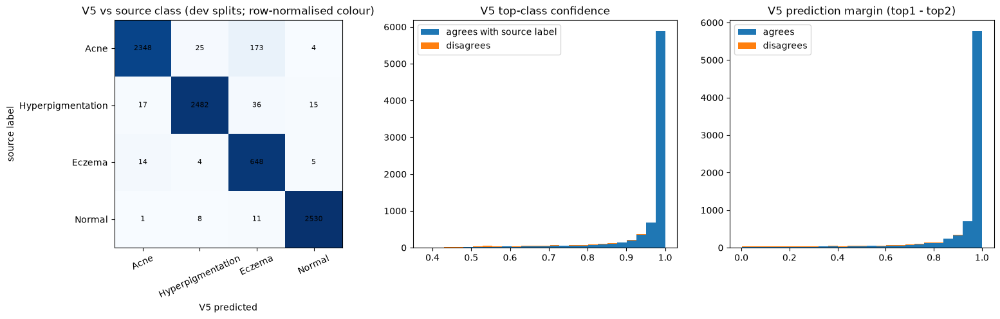

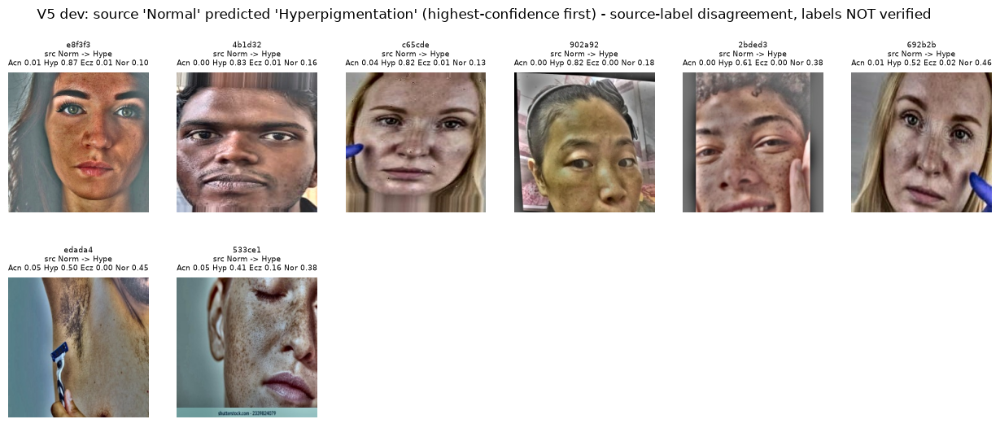

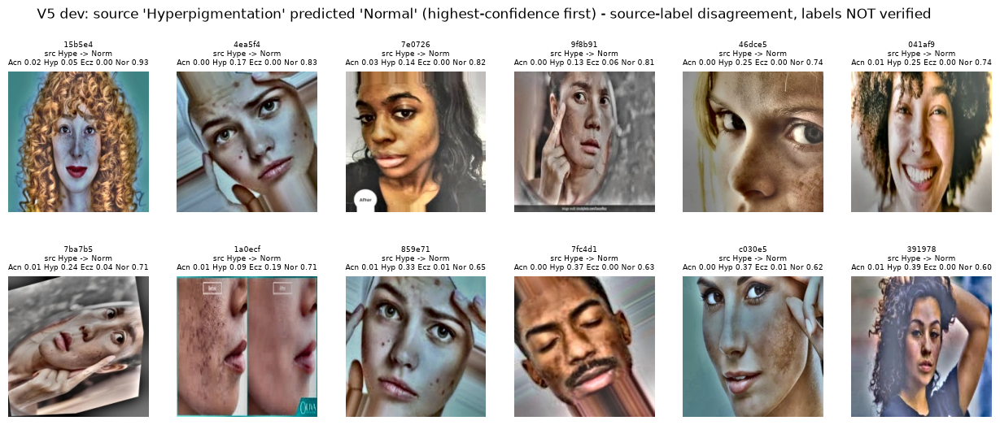

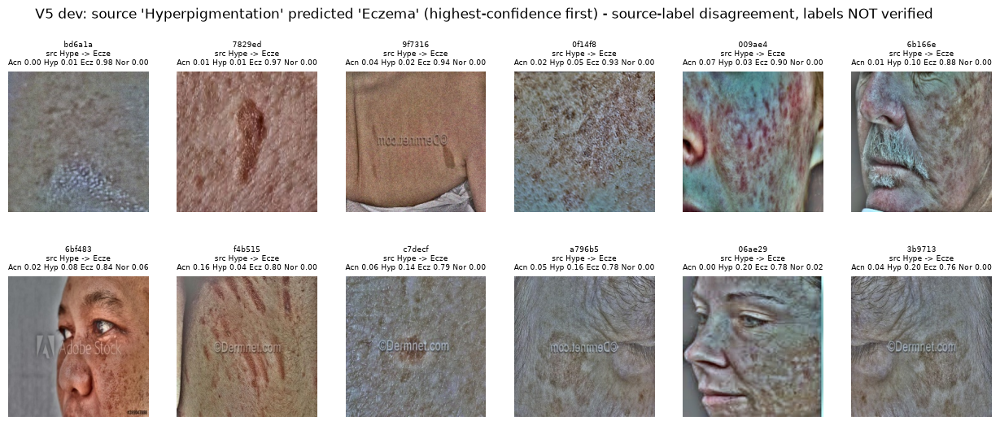

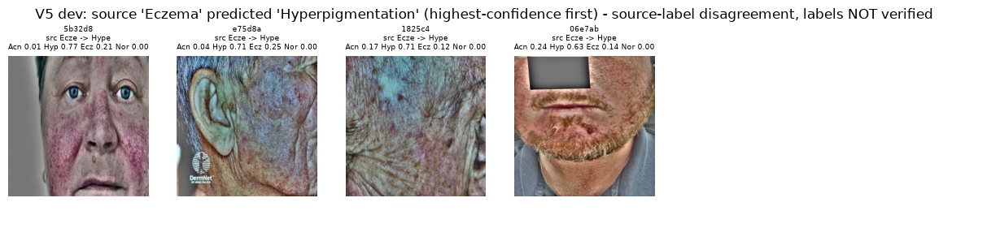

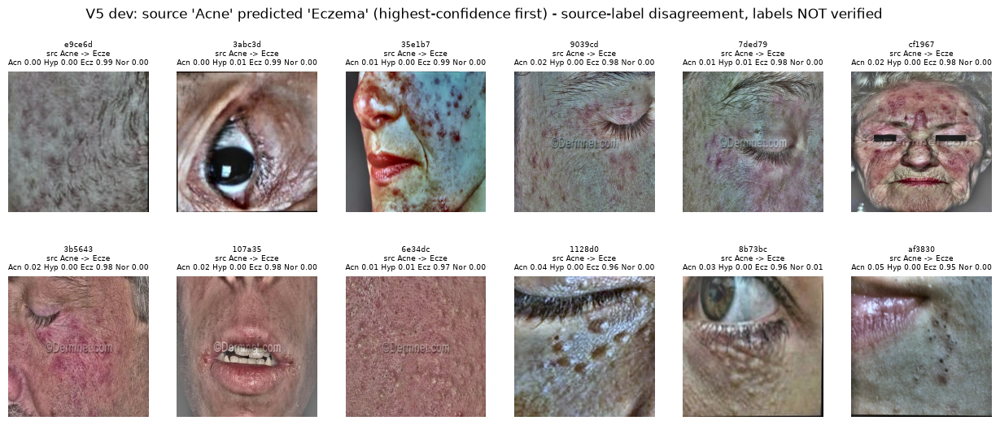

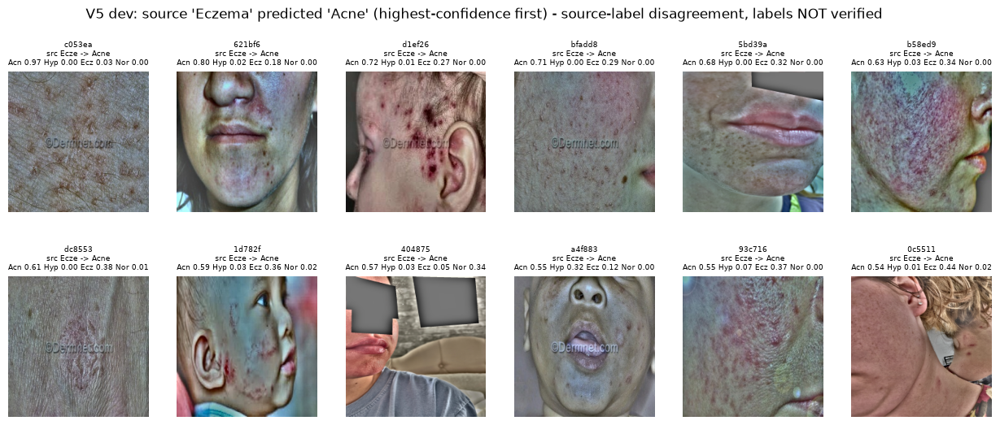

In [30]:
# 17.1 Part A - source-label disagreement (dev splits).
dev = DF[DF.split.isin(DEV)]
cm = pd.crosstab(dev.src_label, dev.v5_pred).reindex(index=CFG.V5_CLASS_ORDER, columns=CFG.V5_CLASS_ORDER, fill_value=0)
display(cm)
PAIRS = [("Normal", "Hyperpigmentation"), ("Hyperpigmentation", "Normal"), ("Hyperpigmentation", "Eczema"), ("Eczema", "Hyperpigmentation"),
         ("Acne", "Eczema"), ("Eczema", "Acne")]
pair_rows = []
for t, p in PAIRS:
    sub = dev[(dev.src_label == t) & (dev.v5_pred == p)]
    pair_rows.append(dict(source_label=t, v5_predicted=p, n=len(sub), rate_of_source_class=len(sub) / max(1, int((dev.src_label == t).sum())),
                          median_conf=float(sub.v5_conf.median()) if len(sub) else np.nan, median_margin=float(sub.v5_margin.median()) if len(sub) else np.nan))
PAIR_A = pd.DataFrame(pair_rows); display(PAIR_A)
write_csv(PAIR_A, os.path.join(CFG.DIRS["v5_comparison"], "v5_dev_source_label_error_pairs.csv"))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
im = ax[0].imshow(cm.to_numpy() / cm.sum(1).to_numpy()[:, None], cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(4)); ax[0].set_yticks(range(4)); ax[0].set_xticklabels(CFG.V5_CLASS_ORDER, rotation=25); ax[0].set_yticklabels(CFG.V5_CLASS_ORDER)
for i in range(4):
    for j in range(4): ax[0].text(j, i, f"{cm.iloc[i, j]}", ha="center", va="center", color="black", fontsize=8)
ax[0].set_title("V5 vs source class (dev splits; row-normalised colour)"); ax[0].set_xlabel("V5 predicted"); ax[0].set_ylabel("source label")
corr = dev.v5_pred == dev.src_label
ax[1].hist([dev[corr].v5_conf, dev[~corr].v5_conf], bins=25, label=["agrees with source label", "disagrees"], stacked=True); ax[1].legend(); ax[1].set_title("V5 top-class confidence")
ax[2].hist([dev[corr].v5_margin, dev[~corr].v5_margin], bins=25, label=["agrees", "disagrees"], stacked=True); ax[2].legend(); ax[2].set_title("V5 prediction margin (top1 - top2)")
savefig(fig, "v5_dev_confusion_confidence_margin")


def gallery(df, title, fname, n=None, prob_cols=None):
    n = n or CFG.N_EXAMPLE_IMAGES
    sub = df.head(n)
    if len(sub) == 0:
        print("(no examples for:", title, ")"); return
    cols = 6; rows = int(math.ceil(len(sub) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.6, rows * 3.0), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), sub.itertuples()):
        a.imshow(cv2.cvtColor(cv2.imread(r.proc_path), cv2.COLOR_BGR2RGB))
        probs = " ".join(f"{c[:3]} {getattr(r, 'v5_' + c):.2f}" for c in CFG.V5_CLASS_ORDER)
        a.set_title(f"{r.pid}\nsrc {r.src_label[:4]} -> {r.v5_pred[:4]}\n{probs}", fontsize=6.5)
    fig.suptitle(title); savefig(fig, fname)


DF["pid"] = [pseudo_id(i)[-6:] for i in DF.image_id]
dev = DF[DF.split.isin(DEV)]
for t, p in PAIRS[:6]:
    g = dev[(dev.src_label == t) & (dev.v5_pred == p)].sort_values("v5_conf", ascending=False)
    gallery(g, f"V5 dev: source '{t}' predicted '{p}' (highest-confidence first) - source-label disagreement, labels NOT verified", f"gallery_v5_{t[:4]}_as_{p[:4]}")

v5_as_set,Acne,Eczema,Hyperpigmentation,none
combo,,,,
Acne,322,40,12,12
Acne+Eczema,1,2,0,0
Acne+Hyperpigmentation,56,3,5,1
Eczema,20,279,8,8
Hyperpigmentation,27,17,453,43
Hyperpigmentation+Eczema,0,3,1,0
none,4,5,18,487


,verified_truth,v5_predicted,n,of_truth_class
0,none,Hyperpigmentation,18,514
1,Hyperpigmentation,Normal,43,540
2,Hyperpigmentation,Eczema,17,540
3,Eczema,Hyperpigmentation,8,315
4,Acne,Eczema,40,386
5,Eczema,Acne,20,315
6,mixed (>=2 conditions),one single class,72,72
7,mixed: V5 single class is one of the true cond...,(partial credit),68,72


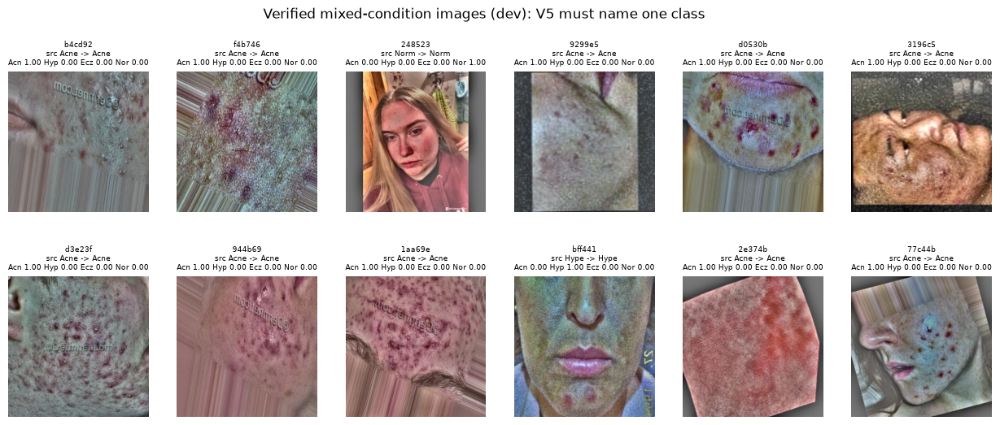

In [31]:
# 17.2 Part B - verified misclassification (needs verified labels in the dev splits; Unknown is never counted as an error).
def verified_combo_table(df):
    d = df[df.full_known].copy()
    if d.empty:
        return None
    d["v5_as_set"] = d.v5_pred.map(lambda p: "none" if p == "Normal" else p)
    return d


vd = verified_combo_table(DF[DF.split.isin(DEV)])
if vd is None:
    print("No fully verified images in the dev splits yet: verified-misclassification analysis NOT available (source-label analysis above is available).")
    VERIFIED_PAIRS = None
else:
    cmv = pd.crosstab(vd.combo, vd.v5_as_set); display(cmv)
    rows = []
    for t, p in [("none", "Hyperpigmentation"), ("Hyperpigmentation", "none"), ("Hyperpigmentation", "Eczema"), ("Eczema", "Hyperpigmentation"), ("Acne", "Eczema"), ("Eczema", "Acne")]:
        sub = vd[(vd.combo == t) & (vd.v5_as_set == p)]
        rows.append(dict(verified_truth=t, v5_predicted=p if p != "none" else "Normal", n=len(sub), of_truth_class=int((vd.combo == t).sum())))
    mixed = vd[vd.n_present >= 2]
    hit = mixed.apply(lambda r: r.v5_as_set in r.combo.split("+"), axis=1) if len(mixed) else pd.Series(dtype=bool)
    rows.append(dict(verified_truth="mixed (>=2 conditions)", v5_predicted="one single class", n=len(mixed), of_truth_class=len(mixed)))
    rows.append(dict(verified_truth="mixed: V5 single class is one of the true conditions", v5_predicted="(partial credit)", n=int(hit.sum()) if len(mixed) else 0, of_truth_class=len(mixed)))
    VERIFIED_PAIRS = pd.DataFrame(rows); display(VERIFIED_PAIRS)
    write_csv(VERIFIED_PAIRS, os.path.join(CFG.DIRS["v5_comparison"], "v5_dev_verified_error_pairs.csv"))
    gallery(vd[(vd.n_present >= 2)].sort_values("v5_conf", ascending=False), "Verified mixed-condition images (dev): V5 must name one class", "gallery_v5_verified_mixed")

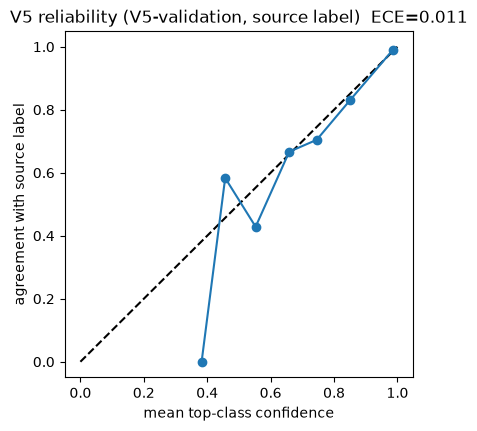

V5 ECE against the source label (historical; sibling leakage makes it optimistic): 0.0108


In [32]:
# 17.3 V5 calibration behaviour on the historical protocol (max-softmax vs agreement with the source label) and a per-class view.
def ece_binary(conf, correct, bins=10):
    conf = np.asarray(conf, float); correct = np.asarray(correct, float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0; rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0 else (conf >= lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean()); rows.append((lo, hi, int(m.sum()), float(conf[m].mean()), float(correct[m].mean())))
    return float(e), pd.DataFrame(rows, columns=["lo", "hi", "n", "mean_conf", "accuracy"])


v5val = DF[DF.v5_split == "validation"]
e, rel = ece_binary(v5val.v5_conf, v5val.v5_pred == v5val.src_label, CFG.CALIBRATION_BINS)
fig, ax = plt.subplots(figsize=(4.5, 4.5)); ax.plot([0, 1], [0, 1], "k--"); ax.plot(rel.mean_conf, rel.accuracy, "o-")
ax.set_xlabel("mean top-class confidence"); ax.set_ylabel("agreement with source label"); ax.set_title(f"V5 reliability (V5-validation, source label)  ECE={e:.3f}")
savefig(fig, "v5_reliability_source_label")
print(f"V5 ECE against the source label (historical; sibling leakage makes it optimistic): {e:.4f}")

## 18. Hard-example mining (train split only; the test set is never consulted)

Hard examples are *candidates* for extra weight or for human review, never automatic label changes:
* **Verified** labels may drive hard-negative sampling (a verified *Absent* condition that a model scores highly is a legitimate hard negative).
* **Weak/unverified** labels can only produce *review candidates* — an unknown condition is not a negative.

Categories: Hyperpigmentation→Normal, Hyperpigmentation→Eczema, Normal-skin variation scored as Hyperpigmentation, Acne↔Eczema, verified mixed-condition images, and (after Part VI) YOLO false-positive boxes on verified-absent conditions.

In [33]:
def mine_hard_examples(df, probs4, yolo_flags=None):
    """Returns a DataFrame of hard-example candidates for rows of `df` (use only train/dev). Verified-based entries are marked usable_for_training=True."""
    rows = []
    P = dict(zip(CFG.V5_CLASS_ORDER, probs4.T))
    for k, r in enumerate(df.itertuples()):
        pr = {c: P[c][k] for c in CFG.V5_CLASS_ORDER}
        ver = bool(r.full_known)
        truth = set(c for c, y in zip(CFG.CONDITIONS, [r.y_acne, r.y_hyperpigmentation, r.y_eczema]) if y == 1) if ver else None
        src = r.src_label
        def add(code, usable): rows.append(dict(image_id=r.image_id, split=r.split, reason=code, usable_for_training=bool(usable and ver), basis="verified" if ver else "weak_source_label", v5_pred=r.v5_pred, v5_conf=r.v5_conf))
        # hyperpigmentation present (verified) or labelled (weak) but V5 prefers Normal / Eczema
        hyper_pos = ("Hyperpigmentation" in truth) if ver else (src == "Hyperpigmentation")
        if hyper_pos and pr["Normal"] >= pr["Hyperpigmentation"]: add("hyperpigmentation_scored_as_normal", True)
        if hyper_pos and pr["Eczema"] >= pr["Hyperpigmentation"]: add("hyperpigmentation_scored_as_eczema", True)
        hyper_neg = ("Hyperpigmentation" not in truth) if ver else False
        if hyper_neg and pr["Hyperpigmentation"] >= 0.30: add("verified_not_hyperpigmentation_scored_as_hyperpigmentation", True)
        if (src == "Normal" and not ver) and pr["Hyperpigmentation"] >= 0.30: add("normal_label_with_pigment_like_score_(review)", False)
        acne_pos = ("Acne" in truth) if ver else (src == "Acne"); ecz_pos = ("Eczema" in truth) if ver else (src == "Eczema")
        if acne_pos and pr["Eczema"] >= pr["Acne"]: add("acne_scored_as_eczema", True)
        if ecz_pos and pr["Acne"] >= pr["Eczema"]: add("eczema_scored_as_acne", True)
        if ver and len(truth) >= 2: add("verified_mixed_conditions", True)
        if yolo_flags is not None and r.image_id in yolo_flags:
            for c in yolo_flags[r.image_id]:
                if ver and c not in truth: add(f"yolo_{c.lower()}_box_on_verified_absent_condition", True)
    return pd.DataFrame(rows, columns=["image_id", "split", "reason", "usable_for_training", "basis", "v5_pred", "v5_conf"])


_trn = DF[DF.split == "train"].reset_index(drop=True)
HARD = mine_hard_examples(_trn, _trn[[f"v5_{c}" for c in CFG.V5_CLASS_ORDER]].to_numpy())
assert (HARD.split == "train").all() if len(HARD) else True, "hard-example mining touched a non-train split"
print("hard-example candidates (train):", len(HARD), "images:", HARD.image_id.nunique())
display(HARD.groupby(["reason", "basis", "usable_for_training"]).size().rename("n").reset_index())
write_csv(HARD, os.path.join(CFG.DIRS["data"], "hard_examples_train_v5.csv"))
log_event("hard_examples", n=int(len(HARD)))

hard-example candidates (train): 316 images: 279


,reason,basis,usable_for_training,n
0,acne_scored_as_eczema,verified,True,28
1,acne_scored_as_eczema,weak_source_label,False,123
2,eczema_scored_as_acne,verified,True,8
3,eczema_scored_as_acne,weak_source_label,False,4
4,hyperpigmentation_scored_as_eczema,verified,True,33
5,hyperpigmentation_scored_as_eczema,weak_source_label,False,28
6,hyperpigmentation_scored_as_normal,verified,True,20
7,hyperpigmentation_scored_as_normal,weak_source_label,False,11
8,normal_label_with_pigment_like_score_(review),weak_source_label,False,9
9,verified_mixed_conditions,verified,True,28


'5782db44cafe436d26f8c5b895749a68958bee4dd4a8005f63a2be124dfa977c'

## 19. Annotation-review queue
Suspicious images are added to `hard_example_review_queue.csv` (existing reviewer decisions are **preserved**; only new candidates are appended). Reasons come from filename/label conflicts, image-type/label mismatches, V5 confidently disagreeing with the source label, a strong second condition in V5, and (later) YOLO flags. A model prediction is a *reason to look*, never a label.

In [34]:
def build_review_queue(extra_flags=None):
    rq = pd.read_csv(CFG.REVIEW_QUEUE_CSV, dtype=str).fillna("") if os.path.exists(CFG.REVIEW_QUEUE_CSV) else pd.DataFrame(columns=RQ_COLS)
    for c in RQ_COLS:
        if c not in rq.columns: rq[c] = ""
    reasons = {k: list(v) for k, v in STATIC_REASONS.items()}
    for r in DF[DF.split.isin(DEV + ["test"])].itertuples():                      # test images may be QUEUED for labelling, but are never inspected for model behaviour
        if r.split != "test":
            if r.v5_conf >= 0.85 and r.v5_pred != r.src_label: reasons.setdefault(r.image_id, []).append("v5_confident_disagreement_with_source_label")
            sec = sorted([(getattr(r, f"v5_{c}"), c) for c in CFG.V5_CLASS_ORDER if c != r.v5_pred], reverse=True)[0]
            if r.v5_pred == r.src_label and r.src_label != "Normal" and sec[1] != "Normal" and sec[0] >= 0.25: reasons.setdefault(r.image_id, []).append(f"v5_strong_second_condition_{sec[1].lower()}")
    for k, v in (extra_flags or {}).items(): reasons.setdefault(k, []).extend(v)
    have = set(rq.image_id)
    new = []
    byid = DF.set_index("image_id")
    for iid, rs in reasons.items():
        if iid in have or iid not in byid.index: continue
        r = byid.loc[iid]
        state = "verified" if r.full_known else "weak_source_label_only"
        new.append({"image_id": iid, "split": r.split, "reason_codes": ";".join(sorted(set(rs))), "v5_pred": r.v5_pred, "v5_conf": f"{r.v5_conf:.3f}", "v5_margin": f"{r.v5_margin:.3f}",
                    "yolo_flags": "", "current_label_state": state, "reviewer_decision": "", "reviewer_id": "", "reviewed_at": "", "notes": ""})
    out = pd.concat([rq, pd.DataFrame(new, columns=RQ_COLS)], ignore_index=True)
    write_csv(out, CFG.REVIEW_QUEUE_CSV)
    return out


RQ = build_review_queue()
print("review queue rows:", len(RQ), "| reviewer decisions already recorded:", int((RQ.reviewer_decision != "").sum()))
print(RQ.reason_codes.str.split(";").explode().str.replace(r"_\(.*\)", "", regex=True).value_counts().head(12).to_string())

review queue rows: 1184 | reviewer decisions already recorded: 0
reason_codes
filename_hints_hyperpigmentation_but_class_acne    418
disease_class_full_face                            386
v5_strong_second_condition_eczema                  168
normal_but_lesion_region_crop                       90
v5_confident_disagreement_with_source_label         66
v5_strong_second_condition_acne                     44
filename_hints_eczema_but_class_acne                24
v5_strong_second_condition_hyperpigmentation        24
filename_hints_acne_but_class_hyperpigmentation     17
same_group_different_class_labels                    5
filename_hints_acne_but_class_eczema                 1
filename_hints_acne_but_class_normal                 1


# Part IV — Improved Global MobileNetV2: Controlled Experiments

Sections: **(20) architecture · (21) global classifier training · (22) controlled fine-tuning · (31 part) per-condition metrics · regression analysis.**

Each global experiment is an **independent configuration** with its own directory and seeds; they are compared on the **validation** split (never test), with an explicit *regression check* so a gain in Hyperpigmentation that costs Acne, Eczema or Normal is visible.

| Exp | Mode | Initialisation | Training data | Extra technique | Question |
|---|---|---|---|---|---|
| **A** | 4-class softmax | V5 (unchanged) | — (evaluation only) | none | baseline |
| **B** | 4-class softmax | **V5 full model** | verified single-condition / none images | fine-tuning only | does correction by *verified* labels help? |
| **C** | 4-class softmax | V5 full model | as B | + class-balanced sampling + hard examples | do balance + hard examples add anything over B? |
| **D** | **3 sigmoids** (multilabel) | ImageNet backbone | all train images with masked loss | none | does multilabel support help (mixed conditions)? |
| **D2** | 3 sigmoids | ImageNet backbone | as D | + balancing + mixed oversampling + hard examples | do the extras help over D? |
| **E** | ROI MobileNetV2 | Part VII | | | YOLO-guided regions (evaluated as a system) |
| **F** | full hybrid fusion | Parts VII–VIII | | | evaluated as a system |

*Why two softmax and two multilabel experiments:* techniques are added **one at a time** (B → C; D → D2) so each effect can be measured. Mixed-condition images cannot be represented by a softmax target, so they are excluded from B/C training (and counted); they are the reason D exists.

**Dermatology-safe augmentation.** Allowed: horizontal flip, small rotation/translation, zoom/crop (it also simulates the *close-up vs full-face* shift), very small brightness/contrast change. **Not used:** hue/saturation/colour jitter, grayscale, channel shuffling, CutMix/MixUp (they fabricate multi-condition images with fabricated labels), random erasing/cut-out (can delete the lesion). Colour carries the clinical signal (erythema, pigmentation).

**Loss.** Multilabel: sigmoid binary cross-entropy **with a mask** (Unknown labels contribute nothing) and an optional per-condition `pos_weight = negatives/positives` (clipped) computed from *known* labels only. Softmax experiments: categorical cross-entropy with sample weights. Output layers are float32 under mixed precision.

In [35]:
# Metrics used by callbacks and by every evaluation section (defined once). y has -1 for Unknown and is never counted.
from sklearn.metrics import average_precision_score, roc_auc_score


def cond_metrics(y, s, thr, min_pos=None):
    """Per-condition metrics on the images where that condition's label is KNOWN. Returns a DataFrame (one row per condition)."""
    min_pos = CFG.MIN_POS_FOR_METRIC if min_pos is None else min_pos
    rows = []
    for j, c in enumerate(CFG.CONDITIONS):
        k = y[:, j] >= 0
        yy, ss = y[k, j], s[k, j]
        pos, neg = int((yy == 1).sum()), int((yy == 0).sum())
        pred = ss >= thr[j]
        tp = int((pred & (yy == 1)).sum()); fp = int((pred & (yy == 0)).sum()); fn = int((~pred & (yy == 1)).sum()); tn = int((~pred & (yy == 0)).sum())
        prec = tp / (tp + fp) if tp + fp else np.nan; rec = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
        f1 = 2 * prec * rec / (prec + rec) if (prec == prec and rec == rec and prec + rec > 0) else np.nan
        ok = pos >= min_pos and neg >= min_pos
        rows.append(dict(condition=c, n_known=int(k.sum()), pos=pos, neg=neg, threshold=float(thr[j]), precision=prec, recall=rec, sensitivity=rec, specificity=spec, f1=f1, tp=tp, fp=fp, fn=fn, tn=tn,
                         ap=float(average_precision_score(yy, ss)) if ok else np.nan, roc_auc=float(roc_auc_score(yy, ss)) if ok else np.nan))
    return pd.DataFrame(rows)


def set_metrics(y, s, thr):
    """Multilabel set metrics on FULLY-KNOWN rows: micro/macro F1, Hamming loss, exact match."""
    k = (y >= 0).all(axis=1)
    if k.sum() == 0:
        return dict(n=0, micro_f1=np.nan, macro_f1=np.nan, hamming_loss=np.nan, exact_match=np.nan)
    yy = y[k]; pp = (s[k] >= np.asarray(thr)[None, :]).astype(int)
    tp = ((pp == 1) & (yy == 1)).sum(); fp = ((pp == 1) & (yy == 0)).sum(); fn = ((pp == 0) & (yy == 1)).sum()
    micro = 2 * tp / max(2 * tp + fp + fn, 1)
    f1s = []
    for j in range(yy.shape[1]):
        t, f, n = ((pp[:, j] == 1) & (yy[:, j] == 1)).sum(), ((pp[:, j] == 1) & (yy[:, j] == 0)).sum(), ((pp[:, j] == 0) & (yy[:, j] == 1)).sum()
        f1s.append(2 * t / max(2 * t + f + n, 1) if (t + f + n) else np.nan)
    return dict(n=int(k.sum()), micro_f1=float(micro), macro_f1=float(np.nanmean(f1s)), hamming_loss=float((pp != yy).mean()), exact_match=float((pp == yy).all(axis=1).mean()))


def macro_ap(y, s):
    m = cond_metrics(y, s, [0.5] * CFG.N_COND)
    v = m.ap.dropna()
    return (float(v.mean()) if len(v) == CFG.N_COND else float("nan")), m


def best_f1_threshold(yy, ss, grid=None):
    grid = grid or CFG.THRESHOLD_GRID
    best, bt = -1, 0.5
    for t in grid:
        p = ss >= t; tp = (p & (yy == 1)).sum(); fp = (p & (yy == 0)).sum(); fn = (~p & (yy == 1)).sum()
        f = 2 * tp / max(2 * tp + fp + fn, 1)
        if f > best: best, bt = f, t
    return bt, best


def cluster_bootstrap(groups, fn, B=None, seed=None):
    """95% percentile interval of fn(index_array) when resampling leakage GROUPS (not images). Returns (lo, hi, n_valid)."""
    B = B or CFG.BOOTSTRAP_B; rng = np.random.RandomState(seed or CFG.BOOTSTRAP_SEED)
    g = np.asarray(groups); ug = np.unique(g); idx_by = {u: np.where(g == u)[0] for u in ug}
    vals = []
    for _ in range(B):
        pick = rng.choice(ug, len(ug), replace=True)
        v = fn(np.concatenate([idx_by[u] for u in pick]))
        if v == v: vals.append(v)
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)), len(vals)) if len(vals) >= max(20, B // 10) else (np.nan, np.nan, len(vals))

In [36]:
# 20.1 Data pipeline: decode -> (train only) dermatology-safe augmentation -> (p/127.5)-1. Batch-level augmentation keeps the CPU pipeline fast.
AUTOTUNE = 1
IMG_PX = CFG.IMG_SIZE                 # (never reuse a one-letter global: other cells assign S, H, W ...)


def decode_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)       # RGB
    img.set_shape([None, None, 3])
    return tf.cast(tf.image.resize(img, [IMG_PX, IMG_PX], method="bilinear"), tf.float32)


_aug_layers = []
if CFG.AUG["flip"]: _aug_layers.append(keras.layers.RandomFlip("horizontal"))
_aug_layers += [keras.layers.RandomRotation(CFG.AUG["rotation_deg"] / 360.0, fill_mode="reflect"),
                keras.layers.RandomTranslation(CFG.AUG["translation"], CFG.AUG["translation"], fill_mode="reflect"),
                keras.layers.RandomZoom(CFG.AUG["zoom"], fill_mode="reflect"),
                keras.layers.RandomBrightness(CFG.AUG["brightness"], value_range=(0, 255)),
                keras.layers.RandomContrast(CFG.AUG["contrast"])]
AUGMENT = keras.Sequential(_aug_layers, name="derm_safe_augmentation")


def scale_crop(x, p):
    """With probability p per image, crop a random 55-100% window and resize back (simulates close-up vs full-face framing)."""
    b = tf.shape(x)[0]
    s = tf.where(tf.random.uniform([b]) < p, tf.random.uniform([b], 0.55, 1.0), tf.ones([b]))
    cy = tf.random.uniform([b], s / 2, 1 - s / 2); cx = tf.random.uniform([b], s / 2, 1 - s / 2)
    boxes = tf.stack([cy - s / 2, cx - s / 2, cy + s / 2, cx + s / 2], axis=1)
    return tf.image.crop_and_resize(x, boxes, tf.range(b), [IMG_PX, IMG_PX], method="bilinear")


def augment_batch(x):
    x = scale_crop(x, CFG.AUG["scale_crop_p"])
    return tf.clip_by_value(AUGMENT(x, training=True), 0.0, 255.0)


def make_dataset(paths, y, w=None, training=False, batch=None):
    batch = batch or CFG.BATCH_SIZE
    paths = np.asarray(paths); y = np.asarray(y, np.float32)
    w = np.ones(len(paths), np.float32) if w is None else np.asarray(w, np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, y, w))
    if training:
        ds = ds.shuffle(min(CFG.SHUFFLE_BUFFER, len(paths)), reshuffle_each_iteration=True)
    ds = ds.map(lambda p, yy, ww: (decode_img(p), yy, ww), num_parallel_calls=AUTOTUNE).batch(batch)
    if training:
        ds = ds.map(lambda x, yy, ww: (augment_batch(x), yy, ww), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, yy, ww: (x / 127.5 - 1.0, yy, ww), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


def pack_ml(y_known, mask):
    """Multilabel target packing: [y(3) | mask(3)] -> (N,6)."""
    return np.concatenate([np.where(mask, np.clip(y_known, 0, 1), 0), mask.astype(np.float32)], axis=1).astype(np.float32)

In [37]:
# 20.2 Masked BCE loss, backbone, head, builders. The loss is registered so .keras checkpoints reload.
@keras.saving.register_keras_serializable(package="lumyvue")
class MaskedBCE(keras.losses.Loss):
    """Sigmoid BCE on logits with an UNKNOWN-label mask. y_true=[y(K)|mask(K)], y_pred = logits (K). Optional per-condition pos_weight."""
    def __init__(self, pos_weight=None, name="masked_bce", **kw):
        super().__init__(name=name, **kw)
        self.pos_weight = [1.0] * CFG.N_COND if pos_weight is None else [float(v) for v in pos_weight]

    def call(self, y_true, y_pred):
        k = CFG.N_COND
        y = tf.cast(y_true[:, :k], tf.float32); m = tf.cast(y_true[:, k:], tf.float32); z = tf.cast(y_pred, tf.float32)
        pw = tf.constant(self.pos_weight, tf.float32)[None, :]
        bce = tf.nn.sigmoid_cross_entropy_with_logits(labels=y, logits=z)
        wt = m * (1.0 + (pw - 1.0) * y)
        return tf.reduce_sum(bce * wt, axis=1) / tf.maximum(tf.reduce_sum(m, axis=1), 1.0)

    def get_config(self):
        c = super().get_config(); c.update(pos_weight=self.pos_weight); return c


def pretrained_backbone():
    kw = dict(input_shape=(IMG_PX, IMG_PX, 3), include_top=False)
    if CFG.PRETRAINED_WEIGHTS_PATH:
        require(os.path.isfile(CFG.PRETRAINED_WEIGHTS_PATH), f"PRETRAINED_WEIGHTS_PATH not found: {CFG.PRETRAINED_WEIGHTS_PATH}", gate=True)
        return keras.applications.MobileNetV2(weights=CFG.PRETRAINED_WEIGHTS_PATH, **kw)
    cache = os.path.join(os.path.expanduser("~"), ".keras", "models", "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5")
    require(os.path.isfile(cache) or not CFG.OFFLINE_MODE,
            "ImageNet MobileNetV2 weights are not cached and OFFLINE_MODE=True blocks the download.\nProvide the 'no_top' .h5 via LUMYVUE_PRETRAINED_WEIGHTS_PATH or set LUMYVUE_OFFLINE_MODE=false once.", gate=True)
    return keras.applications.MobileNetV2(weights="imagenet", **kw)


def find_backbone(model):
    for l in model.layers:
        if isinstance(l, keras.Model):
            return l
    raise V6Error("MobileNetV2 backbone (nested Model) not found in the model")


def build_head(x, k, final_activation=None, name_prefix="global"):
    x = keras.layers.GlobalAveragePooling2D(name=f"{name_prefix}_gap")(x)
    x = keras.layers.Dropout(CFG.HEAD_DROPOUT, name=f"{name_prefix}_drop1")(x)
    x = keras.layers.Dense(CFG.HEAD_UNITS, activation="relu", kernel_regularizer=keras.regularizers.l2(CFG.HEAD_L2), name=f"{name_prefix}_embedding")(x)
    x = keras.layers.Dropout(CFG.HEAD_DROPOUT, name=f"{name_prefix}_drop2")(x)
    return keras.layers.Dense(k, activation=final_activation, dtype="float32", name=f"{name_prefix}_logits" if final_activation is None else f"{name_prefix}_probs")(x)


def build_global(mode, init):
    """mode: 'softmax4' | 'multilabel3'. init: 'imagenet' | 'v5_full' | 'v5_backbone'. Returns (model, backbone). multilabel3 outputs LOGITS; softmax4 outputs probabilities."""
    if init == "v5_full":
        require(os.path.isfile(CFG.V5_KERAS), f"V5 Keras model not found: {CFG.V5_KERAS} (needed for experiments B/C)", gate=True)
        require(mode == "softmax4", "v5_full initialisation is only meaningful for the 4-class softmax experiments")
        m = keras.models.load_model(CFG.V5_KERAS, compile=False)               # read-only load into memory; the V5 file is never saved back
        return m, find_backbone(m)
    # v5_backbone builds the same architecture with no weights; V5 tensors are copied after the head exists, so the head draws the same random numbers as D.
    base = keras.applications.MobileNetV2(input_shape=(IMG_PX, IMG_PX, 3), include_top=False, weights=None) if init == "v5_backbone" else pretrained_backbone()
    base.trainable = False
    inp = keras.layers.Input((IMG_PX, IMG_PX, 3), name="image_nhwc_m1p1")
    x = base(inp, training=False)
    out = build_head(x, 4 if mode == "softmax4" else CFG.N_COND, "softmax" if mode == "softmax4" else None)
    if init == "v5_backbone":
        require(mode == "multilabel3", "v5_backbone initialisation is only defined for the multilabel3 head")
        write_json(os.path.join(CFG.DIRS["metrics"], "v5_transfer_report.json"), transfer_v5_backbone(base))
    return keras.Model(inp, out, name=f"lumyvue_global_{mode}"), base


def embedding_model(model):
    """Model returning [128-d embedding, final output]. The embedding is the 128-unit Dense before the output (V5 and V6 heads both have one)."""
    dense = [l for l in model.layers if isinstance(l, keras.layers.Dense) and l.units == CFG.HEAD_UNITS]
    require(dense, "no 128-unit Dense layer found to use as the embedding")
    return keras.Model(model.input, [dense[-1].output, model.output], name="global_features")


def set_trainable(model, base, phase, fine_tune_at):
    if phase == "A":
        base.trainable = False
    else:
        base.trainable = True
        for l in base.layers[:fine_tune_at]: l.trainable = False
        for l in base.layers:
            if isinstance(l, keras.layers.BatchNormalization): l.trainable = False          # keep ImageNet/V5 BN statistics
    n = sum(1 for l in base.layers if l.trainable)
    return n

In [38]:
# 21.1 Experiment definitions and training-table construction (labels, masks, weights). Gated: needs verified annotations + provenance.
EXPERIMENTS = {
    "B_v5_finetune_verified": dict(mode="softmax4", init="v5_full", data="verified_single", balance=False, hard=False, mixed_oversample=1, phase_a_lr=1e-4),
    "C_balanced_hard":        dict(mode="softmax4", init="v5_full", data="verified_single", balance=True, hard=True, mixed_oversample=1, phase_a_lr=1e-4),
    "D_multilabel3":          dict(mode="multilabel3", init="imagenet", data="all_masked", balance=False, hard=False, mixed_oversample=1, phase_a_lr=None),
    "D2_multilabel3_hard":    dict(mode="multilabel3", init="imagenet", data="all_masked", balance=True, hard=True, mixed_oversample=CFG.MIXED_OVERSAMPLE, phase_a_lr=None),
    "E_v5_backbone_multilabel3": dict(mode="multilabel3", init="v5_backbone", data="all_masked", balance=False, hard=False, mixed_oversample=1, phase_a_lr=None),  # identical to D except init
}
unknown_exp = [e for e in CFG.GLOBAL_EXPERIMENTS if e not in EXPERIMENTS]
require(not unknown_exp, f"Unknown experiment names in GLOBAL_EXPERIMENTS: {unknown_exp}. Valid: {list(EXPERIMENTS)}")
HARD_USABLE = set(HARD[HARD.usable_for_training].image_id) if len(HARD) else set()


def derive_softmax_label(df):
    """4-class index (V5 order) from VERIFIED labels: none->Normal, exactly one condition -> that condition. Mixed / not fully known -> -1 (excluded)."""
    lab = np.full(len(df), -1)
    for i, (n, fk, a, h, e) in enumerate(zip(df.n_present, df.full_known, df.y_acne, df.y_hyperpigmentation, df.y_eczema)):
        if not fk: continue
        if n == 0: lab[i] = 3
        elif n == 1: lab[i] = [a, h, e].index(1)
    return lab


def training_tables(exp):
    """Returns dict(train=(paths,y,w), val=(paths,y,w), info) for experiment `exp`. Raises GateError when the data requirements are not met."""
    gate("provenance_defined"); gate("annotations_train"); gate("annotations_validation")
    e = EXPERIMENTS[exp]
    tr = DF[(DF.split == "train") & DF.train_permitted].copy()
    if CFG.UNCERTAIN_IN_TRAIN == "exclude": tr = tr[tr.review_status != "disputed"]
    va = DF[(DF.split == "validation")].copy()
    info = dict(experiment=exp)
    if e["mode"] == "softmax4":
        tr["lab"] = derive_softmax_label(tr); va["lab"] = derive_softmax_label(va)
        info["excluded_mixed_or_unverified_train"] = int((tr.lab < 0).sum()); info["excluded_mixed_train_verified"] = int(((tr.n_present >= 2)).sum())
        tr = tr[tr.lab >= 0]; va = va[va.lab >= 0]
        require(len(tr) >= 50 and tr.lab.nunique() == 4, f"{exp}: not enough verified single-condition/none training images covering all 4 classes ({len(tr)} images, classes {sorted(tr.lab.unique())})", gate=True)
        ytr = np.eye(4, dtype=np.float32)[tr.lab.values]; yva = np.eye(4, dtype=np.float32)[va.lab.values]
        w = np.ones(len(tr), np.float32)
        if e["balance"]:
            cnt = np.bincount(tr.lab.values, minlength=4).astype(float); cw = cnt.sum() / (4 * np.maximum(cnt, 1)); w *= cw[tr.lab.values]
        if e["hard"]: w *= np.where(tr.image_id.isin(HARD_USABLE), CFG.HARD_UPWEIGHT, 1.0)
        info["class_counts_train"] = np.bincount(tr.lab.values, minlength=4).tolist()
        return dict(train=(tr.proc_path.values, ytr, w), val=(va.proc_path.values, yva, np.ones(len(va), np.float32)), info=info, train_df=tr)
    y, weak = TRAIN_Y[(DF.split == "train").values & DF.train_permitted.values], TRAIN_WEAK[(DF.split == "train").values & DF.train_permitted.values]
    tr = DF[(DF.split == "train") & DF.train_permitted].copy()
    if CFG.UNCERTAIN_IN_TRAIN == "exclude":
        keep = (tr.review_status != "disputed").values; tr, y, weak = tr[keep], y[keep], weak[keep]
    mask = (y >= 0)
    keep = mask.any(axis=1); tr, y, mask = tr[keep], y[keep], mask[keep]
    reps = np.ones(len(tr), int)
    if e["mixed_oversample"] > 1: reps = np.where(tr.n_present.values >= 2, e["mixed_oversample"], 1)
    idx = np.repeat(np.arange(len(tr)), reps)
    tr, y, mask = tr.iloc[idx], y[idx], mask[idx]
    w = np.ones(len(tr), np.float32)
    if e["hard"]: w *= np.where(tr.image_id.isin(HARD_USABLE), CFG.HARD_UPWEIGHT, 1.0)
    pw = [1.0] * CFG.N_COND
    if CFG.USE_CLASS_WEIGHTS and e["balance"]:
        pos = ((y == 1) & mask).sum(0).astype(float); neg = ((y == 0) & mask).sum(0).astype(float)
        pw = [float(np.clip(n / max(p, 1.0), *CFG.POS_WEIGHT_CLIP)) for p, n in zip(pos, neg)]
    ymask_va = (EVAL_Y[(DF.split == "validation").values] >= 0)
    kv = ymask_va.any(axis=1)
    va = va[kv]; yva_k = EVAL_Y[(DF.split == "validation").values][kv]
    info.update(pos_weight=pw, known_labels_train=mask.sum(0).tolist(), positives_train=((y == 1) & mask).sum(0).tolist(), negatives_train=((y == 0) & mask).sum(0).tolist(),
                n_train=int(len(tr)), n_val=int(len(va)))
    require(len(tr) >= 50, f"{exp}: fewer than 50 training images with any known label", gate=True)
    return dict(train=(tr.proc_path.values, pack_ml(y.astype(np.float32), mask), w), val=(va.proc_path.values, pack_ml(yva_k.astype(np.float32), yva_k >= 0), np.ones(len(va), np.float32)),
                info=info, train_df=tr, pos_weight=pw)

In [39]:
# 21.2 Validation-metric callback (VERIFIED validation images only) + checkpoint/resume machinery. `val_sel` = macro AP if computable else -val_loss.
def eval_global_scores(model, paths, mode, batch=None):
    """Returns per-condition scores (N,3): sigmoid of logits (multilabel) or the 3 condition softmax probabilities (softmax4)."""
    ds = make_dataset(paths, np.zeros((len(paths), 6 if mode == "multilabel3" else 4), np.float32), training=False, batch=batch or CFG.BATCH_SIZE)
    out = model.predict(ds.map(lambda x, y, w: x), verbose=0)
    out = np.asarray(out, np.float32)
    return 1 / (1 + np.exp(-out)) if mode == "multilabel3" else out[:, :3]


class ValMetrics(keras.callbacks.Callback):
    def __init__(self, mode, val_paths, val_y_eval):
        super().__init__(); self.mode, self.paths, self.y = mode, val_paths, val_y_eval
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        s = eval_global_scores(self.model, self.paths, self.mode)
        m = cond_metrics(self.y, s, [0.5] * CFG.N_COND)
        for r in m.itertuples():  # per-condition history, so no condition can be hidden by a macro average
            for k in ("precision", "recall", "f1", "ap"): logs[f"val_{r.condition}_{k}"] = float(getattr(r, k))
        ap = m.ap.dropna()
        logs["val_macro_ap"] = float(ap.mean()) if len(ap) == CFG.N_COND else float("nan")
        logs["val_macro_precision"] = float(np.nanmean(m.precision)) if m.precision.notna().any() else float("nan")
        logs["val_macro_recall"] = float(np.nanmean(m.recall)) if m.recall.notna().any() else float("nan")
        logs["val_macro_f1"] = float(np.nanmean(m.f1)) if m.f1.notna().any() else float("nan")
        logs["val_sel"] = logs["val_macro_ap"] if logs["val_macro_ap"] == logs["val_macro_ap"] else -float(logs.get("val_loss", 1e9))
        print(f"   val_macro_ap={logs['val_macro_ap']:.4f} val_macro_f1@0.5={logs['val_macro_f1']:.4f} val_sel={logs['val_sel']:.4f}")


def phase_paths(exp, seed, phase):
    d = os.path.join(CFG.DIRS["checkpoints"], exp, f"seed_{seed}"); os.makedirs(d, exist_ok=True)
    return dict(dir=d, latest=os.path.join(d, f"phase{phase}_latest.keras"), best=os.path.join(d, f"phase{phase}_best.weights.h5"),
                hist=os.path.join(d, f"phase{phase}_history.csv"), state=os.path.join(d, f"phase{phase}_state.json"))


def run_phase(exp, seed, phase, model, base, tabs, epochs, lr, loss, metrics):
    set_trainable(model, base, phase, CFG.FINE_TUNE_AT)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss, metrics=metrics, jit_compile=False)
    directory = phase_paths(exp,seed,phase)['dir']
    identity = training_identity(exp,phase,seed,dict(train=tabs['train'],val=tabs['val']))
    model, rec = recovery_fit(model,make_dataset(*tabs['train'],training=True),make_dataset(*tabs['val'],training=False),
        os.path.join(directory,'recovery_'+phase),identity,epochs,monitor='val_sel',mode='max',
        metric_callbacks=[ValMetrics(EXPERIMENTS[exp]['mode'],tabs['val'][0],tabs['val_y_eval'])], verbose=2)
    astra_phase_record(model,rec,directory,phase)
    return model

## 20.3 V5 backbone transfer for Experiment E (no training)
`E_v5_backbone_multilabel3` reuses the trained V5 MobileNetV2 backbone with a **new** three-condition head. V5's four-class head (and its Dense/BatchNorm layers) is not copied, and the V5 file is only read. The verification cell compares every tensor with V5, compares backbone outputs on the same input, checks the head, the output shapes and the freezing logic, and saves `metrics/v5_transfer_verification.json`. A mismatch raises an error; layers are never skipped silently.

**Known limit of this transfer.** V5 fine-tuned only the upper backbone with BatchNorm frozen, so most V5 backbone tensors equal ImageNet (the report counts them). D and E therefore start close together; any difference between them has to be shown, not assumed.


In [40]:
# 20.3 V5 -> V6 backbone transfer and its verification. Reads the V5 file only; trains nothing.
def v5_input_contract():
    meta = json.load(open(CFG.V5_LABELS_JSON, encoding="utf-8"))
    require(str(meta.get("channel_order", "")).upper() == "RGB", f"V5 channel order is not RGB: {meta.get('channel_order')}", gate=True)
    require(meta.get("normalization") == "(pixel / 127.5) - 1.0", f"V5 normalisation differs from V6: {meta.get('normalization')}", gate=True)
    require(list(meta.get("input_size", []))[:2] == [IMG_PX, IMG_PX], f"V5 input size differs from V6: {meta.get('input_size')}", gate=True)
    return {k: meta.get(k) for k in ("channel_order", "normalization", "input_size", "classes")}


def transfer_v5_backbone(target):
    """Copies V5's backbone weights into `target`, position by position. Any architecture mismatch stops; nothing is skipped silently."""
    require(os.path.isfile(CFG.V5_KERAS), f"V5 Keras model not found: {CFG.V5_KERAS} (needed for experiment E)", gate=True)
    contract = v5_input_contract()
    before = sha256_file(CFG.V5_KERAS)
    v5 = keras.models.load_model(CFG.V5_KERAS, compile=False)
    src = find_backbone(v5)
    require(len(src.layers) == len(target.layers), f"V5 backbone has {len(src.layers)} layers, V6 has {len(target.layers)}", gate=True)
    renamed, n_layers = [], 0
    for s, t in zip(src.layers, target.layers):
        require(type(s) is type(t), f"layer type differs: {s.name} {type(s).__name__} vs {t.name} {type(t).__name__}", gate=True)
        sw = s.get_weights()
        require([w.shape for w in sw] == [w.shape for w in t.get_weights()], f"weight shapes differ at layer {s.name}", gate=True)
        if s.name != t.name:
            require(not sw, f"a weighted layer has a different name: {s.name} vs {t.name}", gate=True)
            renamed.append([s.name, t.name])
        if sw:
            t.set_weights(sw); n_layers += 1
    different = [w.path for a, b, w in zip(src.get_weights(), target.get_weights(), target.weights) if not np.array_equal(a, b)]
    require(not different, f"V5 weights were not transferred exactly: {different[:5]}", gate=True)
    head = [l.name for l in v5.layers if l is not src and l.weights]
    n_tensors = len(src.get_weights())
    del v5, src
    require(sha256_file(CFG.V5_KERAS) == before, "the V5 model file changed during transfer", gate=True)
    return dict(source=redact(CFG.V5_KERAS), source_sha256=before, input_contract=contract, layers_total=len(target.layers), layers_with_weights_transferred=n_layers,
                tensors_transferred=n_tensors, layers_skipped=[], weightless_layers_renamed=renamed, v5_head_layers_not_transferred=head)


def verify_v5_transfer(seed=None):
    """Non-destructive proof that E holds V5's backbone. Runs on CPU under mixed_float16, the policy stored in V5's backbone layers, so both sides do the same arithmetic."""
    seed = CFG.SEEDS[0] if seed is None else seed
    old = keras.mixed_precision.global_policy().name
    keras.mixed_precision.set_global_policy("mixed_float16")
    try:
        with tf.device("/CPU:0"):
            head_names = ("global_embedding", "global_logits")
            keras.backend.clear_session(); keras.mixed_precision.set_global_policy("mixed_float16"); set_all_seeds(seed)  # clear_session resets the policy
            d_model, d_base = build_global("multilabel3", "imagenet")
            d_head = [w.copy() for n in head_names for w in d_model.get_layer(n).get_weights()]
            imagenet = d_base.get_weights()
            keras.backend.clear_session(); keras.mixed_precision.set_global_policy("mixed_float16"); set_all_seeds(seed)
            model, base = build_global("multilabel3", "v5_backbone")
            rep = transfer_v5_backbone(base)
            v5 = keras.models.load_model(CFG.V5_KERAS, compile=False); src = find_backbone(v5)
            sw = src.get_weights()
            rep["tensors_equal_to_v5"] = sum(np.array_equal(a, b) for a, b in zip(sw, base.get_weights()))
            changed = [float(np.abs(a - b).mean() / max(np.abs(b).mean(), 1e-12)) for a, b in zip(sw, imagenet) if not np.array_equal(a, b)]
            rep["v5_tensors_differing_from_imagenet"] = len(changed)
            rep["v5_vs_imagenet_mean_relative_change_of_those"] = float(np.mean(changed)) if changed else 0.0
            x = np.random.default_rng(seed).uniform(-1, 1, (4, IMG_PX, IMG_PX, 3)).astype(np.float32)
            rep["backbone_output_max_abs_diff_v5_vs_e"] = float(np.abs(src(x, training=False).numpy() - base(x, training=False).numpy()).max())
            rep["backbone_output_max_abs_diff_imagenet_vs_e"] = float(np.abs(d_base(x, training=False).numpy() - base(x, training=False).numpy()).max())
            e_head = [w for n in head_names for w in model.get_layer(n).get_weights()]
            rep["head_identical_to_D_at_same_seed"] = len(e_head) == len(d_head) and all(np.array_equal(a, b) for a, b in zip(e_head, d_head))
            v5_kernels = [w.shape for l in v5.layers if isinstance(l, keras.layers.Dense) for w in l.get_weights()]
            rep["head_shapes"] = [list(w.shape) for w in e_head]; rep["v5_dense_shapes"] = [list(s) for s in v5_kernels]
            emb, logits = embedding_model(model)(x, training=False)
            rep["output_shape"] = list(logits.shape); rep["embedding_shape"] = list(emb.shape)
            rep["output_is_raw_logits"] = model.get_layer("global_logits").activation.__name__ == "linear"
            rep["sigmoid_probabilities_in_0_1"] = bool(((tf.sigmoid(logits).numpy() > 0) & (tf.sigmoid(logits).numpy() < 1)).all())
            y = np.array([[1, 0, 0, 1, 1, 0]], np.float32)
            a = MaskedBCE()(y, logits[:1]); b = MaskedBCE()(y, tf.tensor_scatter_nd_update(logits[:1], [[0, 2]], [50.0]))
            rep["unknown_label_is_masked"] = bool(abs(float(a) - float(b)) < 1e-6)
            rep["trainable_backbone_layers_phase_A"] = set_trainable(model, base, "A", CFG.FINE_TUNE_AT)
            rep["trainable_backbone_layers_phase_B"] = set_trainable(model, base, "B", CFG.FINE_TUNE_AT)
            rep["batchnorm_frozen_phase_B"] = not any(l.trainable for l in base.layers if isinstance(l, keras.layers.BatchNormalization))
            rep["layers_below_fine_tune_at_frozen_phase_B"] = not any(l.trainable for l in base.layers[:CFG.FINE_TUNE_AT])
            del v5, src
    finally:
        keras.backend.clear_session(); keras.mixed_precision.set_global_policy(old)
    require(rep["tensors_equal_to_v5"] == rep["tensors_transferred"], "not every tensor equals V5")
    require(rep["backbone_output_max_abs_diff_v5_vs_e"] < 1e-5, f"backbone outputs differ from V5: {rep['backbone_output_max_abs_diff_v5_vs_e']}")
    require(rep["output_shape"] == [4, CFG.N_COND] and rep["embedding_shape"] == [4, CFG.HEAD_UNITS], f"unexpected shapes: {rep['output_shape']} {rep['embedding_shape']}")
    require(rep["output_is_raw_logits"] and rep["unknown_label_is_masked"] and rep["batchnorm_frozen_phase_B"] and rep["layers_below_fine_tune_at_frozen_phase_B"] and rep["trainable_backbone_layers_phase_A"] == 0,
            "logit, masking or freezing check failed: " + json.dumps(rep, default=str))
    write_json(os.path.join(CFG.DIRS["metrics"], "v5_transfer_verification.json"), rep)
    return rep


if "E_v5_backbone_multilabel3" in CFG.GLOBAL_EXPERIMENTS:
    print(json.dumps(verify_v5_transfer(), indent=1, default=str))
else:
    print("Experiment E is not in CFG.GLOBAL_EXPERIMENTS: transfer verification not run.")


E0000 00:00:1793586018.258312  248682 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


{
 "source": "<PROJECT>/runs/facial_only/models/final/precisionskin_best.keras",
 "source_sha256": "7710924820c4272bc0c2f9c06b42208953827f0e86bed5302621b841a7852f3e",
 "input_contract": {
  "channel_order": "RGB",
  "normalization": "(pixel / 127.5) - 1.0",
  "input_size": [
   224,
   224,
   3
  ],
  "classes": [
   "Acne",
   "Hyperpigmentation",
   "Eczema",
   "Normal"
  ]
 },
 "layers_total": 154,
 "layers_with_weights_transferred": 104,
 "tensors_transferred": 260,
 "layers_skipped": [],
 "weightless_layers_renamed": [
  [
   "input_layer_2",
   "input_layer"
  ]
 ],
 "v5_head_layers_not_transferred": [
  "batch_normalization_3",
  "dense_3",
  "batch_normalization_4",
  "dense_4",
  "batch_normalization_5",
  "dense_5"
 ],
 "tensors_equal_to_v5": 260,
 "v5_tensors_differing_from_imagenet": 18,
 "v5_vs_imagenet_mean_relative_change_of_those": 0.013118993982465731,
 "backbone_output_max_abs_diff_v5_vs_e": 0.0,
 "backbone_output_max_abs_diff_imagenet_vs_e": 6.0,
 "head_identical_t

## 21. Global classifier training — run cell by cell

The next cell trains **every experiment in `CFG.GLOBAL_EXPERIMENTS` for every seed in `CFG.SEEDS`**. It is safe to interrupt: re-running resumes from `phase*_latest.keras` and the epoch counter in `phase*_history.csv`; completed phases are skipped. Edit `CFG.GLOBAL_EXPERIMENTS` (or the environment variable) to train experiments one at a time. If a gate is closed, the cell stops *before* creating any dataset or model and prints the exact missing requirement.

Astra starts at batch 8. Measure actual duration and memory on the eligible data; synthetic checks do not establish full-epoch runtime or memory safety. Separate action cells below initiate Phase A and Phase B.

In [41]:
# Global training controls and independent phase entry points
GLOBAL_RESULTS = {}
def astra_global_phase(phase):
    require_source_permission(['train','validation'],'training')
    for exp in CFG.GLOBAL_EXPERIMENTS:
        tabs=training_tables(exp); e=EXPERIMENTS[exp]
        keep=DF[DF.split=='validation'].proc_path.isin(tabs['val'][0]).values
        tabs['val_y_eval']=EVAL_Y[(DF.split=='validation').values][keep]
        for seed in CFG.SEEDS:
            keras.backend.clear_session(); set_all_seeds(seed)
            directory=phase_paths(exp,seed,phase)['dir']
            if phase=='A': model,base=build_global(e['mode'],e['init'])
            else:
                record=json.load(open(os.path.join(directory,'phaseA_state.json')))
                model=keras.models.load_model(os.path.join(record['attempt'],record['selected']));base=find_backbone(model)
            loss=MaskedBCE(tabs['pos_weight']) if e['mode']=='multilabel3' else keras.losses.CategoricalCrossentropy()
            epochs=(CFG.PHASE_A_EPOCHS if e['init'] in ('imagenet','v5_backbone') else max(3,CFG.PHASE_A_EPOCHS//3)) if phase=='A' else CFG.PHASE_B_EPOCHS
            lr=(e['phase_a_lr'] or CFG.PHASE_A_LR) if phase=='A' else CFG.PHASE_B_LR
            model=run_phase(exp,seed,phase,model,base,tabs,epochs,lr,loss,[] if e['mode']=='multilabel3' else ['accuracy'])
            if phase=='B':
                model,selected=astra_select_phase(directory)
                save_selected_model(model,os.path.join(directory,'final_best.keras'))
        GLOBAL_RESULTS[exp]=dict(status='trained' if phase=='B' else 'phase_A_complete',info=tabs['info'])
    write_json(os.path.join(CFG.DIRS['metrics'],'global_training_status.json'),GLOBAL_RESULTS)

## Astra Global Phase A — EXPENSIVE, researcher initiated
Frozen backbone. Set the one-use action token `global_A` in a separate cell first.

In [42]:
astra_require_action('global_A')
astra_global_phase('A')

Epoch 1/12


E0000 00:00:1793554083.192726  151486 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
W0000 00:00:1793554083.272305  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT sha

   val_macro_ap=0.6422 val_macro_f1@0.5=0.4790 val_sel=0.6422
112/112 - 47s - 417ms/step - loss: 0.5387 - val_loss: 0.4398 - val_Acne_precision: 0.9474 - val_Acne_recall: 0.3121 - val_Acne_f1: 0.4696 - val_Acne_ap: 0.8014 - val_Hyperpigmentation_precision: 0.6102 - val_Hyperpigmentation_recall: 0.7725 - val_Hyperpigmentation_f1: 0.6818 - val_Hyperpigmentation_ap: 0.7638 - val_Eczema_precision: 0.5000 - val_Eczema_recall: 0.2000 - val_Eczema_f1: 0.2857 - val_Eczema_ap: 0.3614 - val_macro_ap: 0.6422 - val_macro_precision: 0.6858 - val_macro_recall: 0.4282 - val_macro_f1: 0.4790 - val_sel: 0.6422 - learning_rate: 0.0010
Epoch 2/12


W0000 00:00:1793554129.786441  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.6816 val_macro_f1@0.5=0.5859 val_sel=0.6816
112/112 - 32s - 288ms/step - loss: 0.4295 - val_loss: 0.4139 - val_Acne_precision: 0.9277 - val_Acne_recall: 0.4451 - val_Acne_f1: 0.6016 - val_Acne_ap: 0.8383 - val_Hyperpigmentation_precision: 0.6534 - val_Hyperpigmentation_recall: 0.7768 - val_Hyperpigmentation_f1: 0.7098 - val_Hyperpigmentation_ap: 0.8144 - val_Eczema_precision: 0.4386 - val_Eczema_recall: 0.4545 - val_Eczema_f1: 0.4464 - val_Eczema_ap: 0.3920 - val_macro_ap: 0.6816 - val_macro_precision: 0.6732 - val_macro_recall: 0.5588 - val_macro_f1: 0.5859 - val_sel: 0.6816 - learning_rate: 0.0010
Epoch 3/12


W0000 00:00:1793554162.097688  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

... (39 outputs left out)

W0000 00:00:1793554869.608124  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.8334 val_macro_f1@0.5=0.7439 val_sel=0.8334
112/112 - 34s - 299ms/step - loss: 0.2586 - val_loss: 0.3012 - val_Acne_precision: 0.8298 - val_Acne_recall: 0.9017 - val_Acne_f1: 0.8643 - val_Acne_ap: 0.9197 - val_Hyperpigmentation_precision: 0.9383 - val_Hyperpigmentation_recall: 0.6524 - val_Hyperpigmentation_f1: 0.7696 - val_Hyperpigmentation_ap: 0.8978 - val_Eczema_precision: 0.6905 - val_Eczema_recall: 0.5273 - val_Eczema_f1: 0.5979 - val_Eczema_ap: 0.6829 - val_macro_ap: 0.8334 - val_macro_precision: 0.8195 - val_macro_recall: 0.6938 - val_macro_f1: 0.7439 - val_sel: 0.8334 - learning_rate: 0.0010
Epoch 12/12


W0000 00:00:1793554903.146880  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.8388 val_macro_f1@0.5=0.7593 val_sel=0.8388
112/112 - 34s - 299ms/step - loss: 0.2541 - val_loss: 0.2857 - val_Acne_precision: 0.8834 - val_Acne_recall: 0.8324 - val_Acne_f1: 0.8571 - val_Acne_ap: 0.9263 - val_Hyperpigmentation_precision: 0.8687 - val_Hyperpigmentation_recall: 0.7382 - val_Hyperpigmentation_f1: 0.7981 - val_Hyperpigmentation_ap: 0.8942 - val_Eczema_precision: 0.6471 - val_Eczema_recall: 0.6000 - val_Eczema_f1: 0.6226 - val_Eczema_ap: 0.6958 - val_macro_ap: 0.8388 - val_macro_precision: 0.7997 - val_macro_recall: 0.7235 - val_macro_f1: 0.7593 - val_sel: 0.8388 - learning_rate: 5.0000e-04


## Astra Global Phase B and phase selection — EXPENSIVE, researcher initiated
Partial unfreeze with BatchNorm frozen, new optimizer. Restores the better A/B checkpoint; B wins ties.

In [43]:
astra_require_action('global_B')
astra_global_phase('B')

Epoch 1/20


E0000 00:00:1793554963.495876  151486 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
W0000 00:00:1793554963.550939  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT sha

   val_macro_ap=0.7722 val_macro_f1@0.5=0.6846 val_sel=0.7722
112/112 - 43s - 383ms/step - loss: 0.2799 - val_loss: 0.3526 - val_Acne_precision: 0.9231 - val_Acne_recall: 0.5549 - val_Acne_f1: 0.6931 - val_Acne_ap: 0.8676 - val_Hyperpigmentation_precision: 0.7615 - val_Hyperpigmentation_recall: 0.7811 - val_Hyperpigmentation_f1: 0.7712 - val_Hyperpigmentation_ap: 0.8561 - val_Eczema_precision: 0.7000 - val_Eczema_recall: 0.5091 - val_Eczema_f1: 0.5895 - val_Eczema_ap: 0.5928 - val_macro_ap: 0.7722 - val_macro_precision: 0.7949 - val_macro_recall: 0.6150 - val_macro_f1: 0.6846 - val_sel: 0.7722 - learning_rate: 1.0000e-05
Epoch 2/20


W0000 00:00:1793555006.378852  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.7825 val_macro_f1@0.5=0.6884 val_sel=0.7825
112/112 - 34s - 306ms/step - loss: 0.2589 - val_loss: 0.3433 - val_Acne_precision: 0.9259 - val_Acne_recall: 0.5780 - val_Acne_f1: 0.7117 - val_Acne_ap: 0.8766 - val_Hyperpigmentation_precision: 0.8049 - val_Hyperpigmentation_recall: 0.7082 - val_Hyperpigmentation_f1: 0.7534 - val_Hyperpigmentation_ap: 0.8594 - val_Eczema_precision: 0.6000 - val_Eczema_recall: 0.6000 - val_Eczema_f1: 0.6000 - val_Eczema_ap: 0.6116 - val_macro_ap: 0.7825 - val_macro_precision: 0.7769 - val_macro_recall: 0.6287 - val_macro_f1: 0.6884 - val_sel: 0.7825 - learning_rate: 1.0000e-05
Epoch 3/20


W0000 00:00:1793555040.713874  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

... (69 outputs left out)

W0000 00:00:1793556276.306639  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.8606 val_macro_f1@0.5=0.7913 val_sel=0.8606
112/112 - 34s - 302ms/step - loss: 0.1735 - val_loss: 0.2892 - val_Acne_precision: 0.8916 - val_Acne_recall: 0.8555 - val_Acne_f1: 0.8732 - val_Acne_ap: 0.9249 - val_Hyperpigmentation_precision: 0.9027 - val_Hyperpigmentation_recall: 0.7167 - val_Hyperpigmentation_f1: 0.7990 - val_Hyperpigmentation_ap: 0.9108 - val_Eczema_precision: 0.6780 - val_Eczema_recall: 0.7273 - val_Eczema_f1: 0.7018 - val_Eczema_ap: 0.7461 - val_macro_ap: 0.8606 - val_macro_precision: 0.8241 - val_macro_recall: 0.7665 - val_macro_f1: 0.7913 - val_sel: 0.8606 - learning_rate: 1.2500e-06
Epoch 20/20


W0000 00:00:1793556310.097379  151486 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: goo.gle/debugstr  op: "CropAndResize" attr { key: "T" value { type: DT_FLOAT } } attr { key: "extrapolation_value" value { f: 0 } } attr { key: "method" value { s: "bilinear" } } inputs { dtype: DT_FLOAT shape { dim { size: -38 } dim { size: 224 } dim { size: 224 } dim { size: 3 } } } inputs { dtype: DT_FLOAT shape { dim { size: -2 } dim { size: 4 } } } inputs { dtype: DT_INT32 shape { dim { size: -2 } } } inputs { dtype: DT_INT32 shape { dim { size: 2 } } value { dtype: DT_INT32 tensor_shape { dim { size: 2 } } int_val: 224 } } device { type: "CPU" vendor: "GenuineIntel" model: "111" frequency: 2688 num_cores: 20 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 49152 l2_cache_size: 1310720 l3_cache_size: 25165824 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { dim { s

   val_macro_ap=0.8634 val_macro_f1@0.5=0.7830 val_sel=0.8634
112/112 - 34s - 305ms/step - loss: 0.1754 - val_loss: 0.2875 - val_Acne_precision: 0.8757 - val_Acne_recall: 0.8555 - val_Acne_f1: 0.8655 - val_Acne_ap: 0.9249 - val_Hyperpigmentation_precision: 0.9016 - val_Hyperpigmentation_recall: 0.7082 - val_Hyperpigmentation_f1: 0.7933 - val_Hyperpigmentation_ap: 0.9119 - val_Eczema_precision: 0.6724 - val_Eczema_recall: 0.7091 - val_Eczema_f1: 0.6903 - val_Eczema_ap: 0.7535 - val_macro_ap: 0.8634 - val_macro_precision: 0.8166 - val_macro_recall: 0.7576 - val_macro_f1: 0.7830 - val_sel: 0.8634 - learning_rate: 1.2500e-06


## 22. Selecting the global model on validation data, with a regression check
For each trained experiment and seed, scores on the verified **validation** images are computed and compared with the V5 baseline (experiment A) on the *same images*. The **best seed per experiment** is chosen by validation macro-AP; the **improved global model** is the experiment with the highest macro-AP **among those without a per-condition regression** (F1@0.5 drop larger than `REGRESSION_TOLERANCE_F1` versus A). If every candidate regresses somewhere, the best is still reported but flagged. The choice is saved to `metrics/global_selection.json`; the test set plays no part.

In [44]:
def global_scores_for(exp, seed, df, tag="final_best.keras"):
    """Cached per-condition scores/embeddings of a trained global model for the rows of df (any split). Returns dict(scores, emb, pnormal)."""
    e = EXPERIMENTS[exp]
    cache = os.path.join(CFG.DIRS["predictions"], f"global_{exp}_seed{seed}_{hashlib.md5(','.join(df.image_id).encode()).hexdigest()[:10]}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return dict(scores=z["scores"], emb=z["emb"], pnormal=z["pnormal"])
    path = os.path.join(CFG.DIRS["checkpoints"], exp, f"seed_{seed}", tag)
    require(os.path.isfile(path), f"trained model not found: {path} (train experiment {exp} first)", gate=True)
    m = keras.models.load_model(path, custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
    fm = embedding_model(m)
    ds = make_dataset(df.proc_path.values, np.zeros((len(df), 4), np.float32), training=False, batch=64).map(lambda x, y, w: x)
    emb, out = fm.predict(ds, verbose=0); out = np.asarray(out, np.float32)
    if e["mode"] == "multilabel3":
        sc = 1 / (1 + np.exp(-out)); pn = np.full(len(df), np.nan, np.float32)
    else:
        sc, pn = out[:, :3], out[:, 3]
    np.savez_compressed(safe_path(cache), scores=sc, emb=emb.astype(np.float32), pnormal=pn)
    keras.backend.clear_session()
    return dict(scores=sc, emb=emb.astype(np.float32), pnormal=pn)


def v5_scores(df):
    return df[[f"v5_{c}" for c in CFG.CONDITIONS]].to_numpy(np.float32)


val_df = DF[DF.split == "validation"]
yv_all = EVAL_Y[(DF.split == "validation").values]
SEL = dict(candidates={})
if (yv_all >= 0).any():
    rowsA = cond_metrics(yv_all, v5_scores(val_df), [0.5] * 3); rowsA["experiment"] = "A_v5_baseline"; rowsA["seed"] = -1
    all_rows = [rowsA]
    for exp, res in GLOBAL_RESULTS.items():
        if res.get("status") != "trained": continue
        best = None
        for seed in CFG.SEEDS:
            try:
                gs = global_scores_for(exp, seed, val_df)
            except GateError as g:
                print("  ", g); continue
            m = cond_metrics(yv_all, gs["scores"], [0.5] * 3); ap = m.ap.mean(); m["experiment"] = exp; m["seed"] = seed; all_rows.append(m)
            if best is None or (ap == ap and ap > best[0]): best = (ap, seed)
        if best: SEL["candidates"][exp] = dict(best_seed=best[1], val_macro_ap=float(best[0]))
    CMP = pd.concat(all_rows, ignore_index=True)
    write_csv(CMP, os.path.join(CFG.DIRS["metrics"], "global_experiments_validation_per_condition.csv"))
    summ = CMP.groupby(["experiment", "seed"]).agg(macro_ap=("ap", "mean"), macro_f1=("f1", "mean")).reset_index()
    display(summ)
    base_f1 = rowsA.set_index("condition").f1
    for exp, c in SEL["candidates"].items():
        m = CMP[(CMP.experiment == exp) & (CMP.seed == c["best_seed"])].set_index("condition")
        c["delta_f1_vs_A"] = (m.f1 - base_f1).round(4).to_dict()
        c["regression"] = [k for k, v in c["delta_f1_vs_A"].items() if v == v and v < -CFG.REGRESSION_TOLERANCE_F1]
    ok = {e: c for e, c in SEL["candidates"].items() if not c["regression"] and c["val_macro_ap"] == c["val_macro_ap"]}
    ok = {e:c for e,c in ok.items() if EXPERIMENTS[e]['mode']=='multilabel3'}
    pool = ok or {e: c for e, c in SEL["candidates"].items() if c["val_macro_ap"] == c["val_macro_ap"] and EXPERIMENTS[e]['mode']=='multilabel3'}
    if pool:
        SEL["selected"] = max(pool, key=lambda e: pool[e]["val_macro_ap"]); SEL["selected_seed"] = pool[SEL["selected"]]["best_seed"]; SEL["selected_has_regression"] = bool(pool[SEL["selected"]]["regression"])
    write_json(os.path.join(CFG.DIRS["metrics"], "global_selection.json"), SEL)
    print(json.dumps(SEL, indent=1, default=str))
    if SEL.get("selected_has_regression"): print("NOTE: the selected model regresses on a condition versus V5 (see delta_f1_vs_A). Report it as such.")
else:
    print("Global-model comparison needs verified validation labels (and trained experiments): not available yet. Nothing was invented.")
GLOBAL_SELECTED = (SEL.get("selected"), SEL.get("selected_seed"))
print("improved global model:", GLOBAL_SELECTED)

,experiment,seed,macro_ap,macro_f1
0,A_v5_baseline,-1,0.800081,0.776232
1,D_multilabel3,42,0.796394,0.722827
2,E_v5_backbone_multilabel3,42,0.863413,0.783011


{
 "candidates": {
  "D_multilabel3": {
   "best_seed": 42,
   "val_macro_ap": 0.7963939929356001,
   "delta_f1_vs_A": {
    "Acne": -0.0948,
    "Hyperpigmentation": -0.0127,
    "Eczema": -0.0527
   },
   "regression": [
    "Acne",
    "Eczema"
   ]
  },
  "E_v5_backbone_multilabel3": {
   "best_seed": 42,
   "val_macro_ap": 0.8634127577818869,
   "delta_f1_vs_A": {
    "Acne": 0.005,
    "Hyperpigmentation": 0.0141,
    "Eczema": 0.0012
   },
   "regression": []
  }
 },
 "selected": "E_v5_backbone_multilabel3",
 "selected_seed": 42,
 "selected_has_regression": false
}
improved global model: ('E_v5_backbone_multilabel3', 42)


## 22b. D vs E with V5 exposure controlled
Most V6 images were in V5's own training split, so E's backbone may have seen them while D's has not. On those images E has an unfair advantage. This cell therefore compares D and E on three sets: all validation images, images V5 did not train on (by id, MD5 and leakage group), and the stricter subset from V5's own test split. When both were trained and one of them was selected, **the choice between D and E is made on the not-trained-by-V5 set**, across all three conditions. Nothing here touches the test split.


In [45]:
# 22b. Exposure-controlled comparison of D and E on validation (development data only)
def v5_exposure_flags():
    raw = pd.read_csv(CFG.V5_MANIFEST, usecols=["split", "md5"], dtype=str)
    train_md5 = set(raw[raw.split == "train"].md5.dropna())
    direct = (DF.v5_split == "train").values | DF.md5.astype(str).isin(train_md5).values
    groups = set(DF.group_id[direct])
    exposed = direct | DF.group_id.isin(groups).values
    return pd.DataFrame(dict(split=DF.split.values, v5_split=DF.v5_split.values, exposed=exposed), index=DF.index)


def hp_normal_errors(y, s, thr=0.5):
    """Primary development quantities at a fixed 0.5, on fully known rows: Hyperpigmentation missed as no target, and all-negative images flagged Hyperpigmentation."""
    j = CFG.CONDITIONS.index("Hyperpigmentation") if "Hyperpigmentation" in CFG.CONDITIONS else list(c.lower() for c in CFG.CONDITIONS).index("hyperpigmentation")
    full = (y >= 0).all(1); y, s = y[full], s[full]
    pos = y[:, j] == 1; neg = (y == 0).all(1); none = (s < thr).all(1)
    return dict(hp_pos=int(pos.sum()), hp_missed_as_no_target=int((pos & none).sum()), all_neg=int(neg.sum()), all_neg_flagged_hp=int((neg & (s[:, j] >= thr)).sum()))


def macro_ap(y, s):
    vals = [average_precision_score(y[y[:, j] >= 0, j], s[y[:, j] >= 0, j]) for j in range(CFG.N_COND) if (y[y[:, j] >= 0, j] == 1).any() and (y[y[:, j] >= 0, j] == 0).any()]
    return float(np.mean(vals)) if len(vals) == CFG.N_COND else float("nan")


EXPOSURE = v5_exposure_flags()
display(EXPOSURE.groupby("split").agg(images=("exposed", "size"), v5_exposed=("exposed", "sum")))
_d, _e = "D_multilabel3", "E_v5_backbone_multilabel3"
if _d in SEL["candidates"] and _e in SEL["candidates"]:
    _x = EXPOSURE[EXPOSURE.split == "validation"]
    _subsets = dict(all_validation=np.ones(len(_x), bool), not_trained_by_v5=~_x.exposed.values, v5_test_split_only=(~_x.exposed.values) & (_x.v5_split.values == "test"))
    _sd = global_scores_for(_d, SEL["candidates"][_d]["best_seed"], val_df)["scores"]; _se = global_scores_for(_e, SEL["candidates"][_e]["best_seed"], val_df)["scores"]
    _rows, _summary = [], {}
    for _name, _m in _subsets.items():
        for _exp, _s in ((_d, _sd), (_e, _se)):
            _t = cond_metrics(yv_all[_m], _s[_m], [0.5] * CFG.N_COND); _t["subset"] = _name; _t["experiment"] = _exp; _rows.append(_t)
            _summary.setdefault(_name, {})[_exp] = dict(macro_ap=macro_ap(yv_all[_m], _s[_m]), macro_f1=float(_t.f1.mean()), **hp_normal_errors(yv_all[_m], _s[_m]))
        _rng = np.random.default_rng(CFG.SEEDS[0]); _idx = np.flatnonzero(_m); _diff = []
        for _ in range(1000):
            _b = _rng.choice(_idx, len(_idx))
            _diff.append(macro_ap(yv_all[_b], _se[_b]) - macro_ap(yv_all[_b], _sd[_b]))
        _summary[_name]["e_minus_d_macro_ap_ci95"] = [float(v) for v in np.nanpercentile(_diff, [2.5, 97.5])]
    write_csv(pd.concat(_rows, ignore_index=True), os.path.join(CFG.DIRS["metrics"], "d_vs_e_validation_by_exposure.csv"))
    display(pd.concat(_rows, ignore_index=True)[["subset", "experiment", "condition", "pos", "neg", "precision", "recall", "f1", "ap"]])
    print(json.dumps(_summary, indent=1))
    SEL["d_vs_e"] = _summary
    _pool = {k: _summary["not_trained_by_v5"][k]["macro_ap"] for k in (_d, _e) if not SEL["candidates"][k]["regression"]} or {k: _summary["not_trained_by_v5"][k]["macro_ap"] for k in (_d, _e)}
    if SEL.get("selected") in (_d, _e) and all(v == v for v in _pool.values()):
        _win = max(_pool, key=lambda k: (_pool[k], k == _d))  # a tie keeps D: E has to earn its place
        SEL["d_vs_e_selection_basis"] = "macro AP on validation images not trained on by V5, no per-condition regression preferred"
        if _win != SEL["selected"]: print(f"Selection changed from {SEL['selected']} to {_win} after controlling for V5 exposure.")
        SEL["selected"] = _win; SEL["selected_seed"] = SEL["candidates"][_win]["best_seed"]; SEL["selected_has_regression"] = bool(SEL["candidates"][_win]["regression"])
    write_json(os.path.join(CFG.DIRS["metrics"], "global_selection.json"), SEL)
    GLOBAL_SELECTED = (SEL.get("selected"), SEL.get("selected_seed"))
    print("improved global model after exposure control:", GLOBAL_SELECTED)
else:
    print("D vs E comparison needs both experiments trained. Nothing was invented.")


,images,v5_exposed
split,,
fusion,1469,1203
test,1468,1246
train,5873,4799
validation,979,783


,subset,experiment,condition,pos,neg,precision,recall,f1,ap
0,all_validation,D_multilabel3,Acne,173,421,0.892308,0.670520,0.765677,0.888749
1,all_validation,D_multilabel3,Hyperpigmentation,233,363,0.812500,0.725322,0.766440,0.870890
2,all_validation,D_multilabel3,Eczema,55,537,0.636364,0.636364,0.636364,0.629543
3,all_validation,E_v5_backbone_multilabel3,Acne,173,421,0.875740,0.855491,0.865497,0.924881
4,all_validation,E_v5_backbone_multilabel3,Hyperpigmentation,233,363,0.901639,0.708155,0.793269,0.911885
5,all_validation,E_v5_backbone_multilabel3,Eczema,55,537,0.672414,0.709091,0.690265,0.753472
6,not_trained_by_v5,D_multilabel3,Acne,50,84,0.804878,0.660000,0.725275,0.888890
7,not_trained_by_v5,D_multilabel3,Hyperpigmentation,48,86,0.888889,0.666667,0.761905,0.854369
8,not_trained_by_v5,D_multilabel3,Eczema,18,114,0.625000,0.555556,0.588235,0.687114
9,not_trained_by_v5,E_v5_backbone_multilabel3,Acne,50,84,0.803571,0.900000,0.849057,0.926636


{
 "all_validation": {
  "D_multilabel3": {
   "macro_ap": 0.7963939929356001,
   "macro_f1": 0.7228267044391514,
   "hp_pos": 230,
   "hp_missed_as_no_target": 33,
   "all_neg": 168,
   "all_neg_flagged_hp": 19
  },
  "E_v5_backbone_multilabel3": {
   "macro_ap": 0.8634127577818869,
   "macro_f1": 0.7830105978394287,
   "hp_pos": 230,
   "hp_missed_as_no_target": 32,
   "all_neg": 168,
   "all_neg_flagged_hp": 10
  },
  "e_minus_d_macro_ap_ci95": [
   0.04549775424567642,
   0.0910810146309694
  ]
 },
 "not_trained_by_v5": {
  "D_multilabel3": {
   "macro_ap": 0.810124517371129,
   "macro_f1": 0.6918049270990448,
   "hp_pos": 47,
   "hp_missed_as_no_target": 9,
   "all_neg": 26,
   "all_neg_flagged_hp": 2
  },
  "E_v5_backbone_multilabel3": {
   "macro_ap": 0.8494774756161151,
   "macro_f1": 0.7320384757676656,
   "hp_pos": 47,
   "hp_missed_as_no_target": 10,
   "all_neg": 26,
   "all_neg_flagged_hp": 3
  },
  "e_minus_d_macro_ap_ci95": [
   0.0016820990309305507,
   0.07620585524358

# Part V — Three YOLOv8 Detectors: Loading, Deployed-Equivalent Inference, Diagnostics and Localisation Evaluation

Sections: **(23) loading and ONNX introspection · (24) ensemble inference and post-processing · detection diagnostics (duplicates / nesting / false positives) · localisation metrics.**

**Preserving the deployed behaviour.** The Python engine below re-implements the C# `LesionDetector` / `LesionEngine` algorithm step by step, so Python evidence matches what the application would produce:

1. letterbox to the model's `imgsz` (grey 114 padding, bilinear resize) → RGB → `/255` → NCHW float32;
2. ONNX output `[1, 4 + nc, N]` = `cx, cy, w, h` (letterbox pixels) then per-class scores, **no objectness**;
3. each ensemble member reports boxes down to confidence **0.02**, after *per-class NMS* (`nms_iou` from the detector JSON, ≤ 60 boxes);
4. **ensemble fusion**: boxes of one class are sorted by confidence and clustered (IoU ≥ 0.5 against the running confidence-weighted average); fused confidence = `min(1, Σ confidences / number_of_members)`; the **deployed per-condition threshold is applied after fusion**;
5. a single-model detector uses the same decoding with the threshold applied directly (a threshold never changes which boxes survive NMS, so keeping lower-confidence boxes as a *candidate pool* does not alter the deployed boxes);
6. optional face filter (box centre inside the face box + 25 %), used by the application on live frames.

Nothing is tuned: thresholds are the deployed values (`CFG.YOLO_THRESHOLDS`); an ensemble is never silently replaced by a single member; a detector that is not installed is **`detector_unavailable`**, never "no detection".

In [46]:
# 23.1 Detector registry: discovery follows the C# LesionEngine naming (lesion_detector_<class>.onnx [+ _m2.._m6], .json; else the 3-class lesion_detector_v1.onnx).
#      Every Eczema-specific value is adjustable (CFG.ECZEMA_* / CFG.YOLO_OVERRIDES). Nothing about Eczema training is assumed.
@dataclass
class Member:
    path: str; sha256: str; session: object; input_name: str; imgsz: int; layout: str; nc: int; class_names: list; out_shape: list


@dataclass
class DetectorSpec:
    condition: str; kind: str; members: list; imgsz: int; nms_iou: float; threshold: float; floor: float; class_col: dict; available: bool
    version: str = ""; notes: str = ""; meta: dict = field(default_factory=dict)
    fusion_iou: float = 0.5; location: str = ""; json_sha_matches: object = None       # json_sha_matches: None = JSON has no hash, True/False = JSON onnx_sha256 vs the primary file


def _read_json(p):
    return json.load(open(p, encoding="utf-8")) if p and os.path.isfile(p) else {}


def _introspect(path, meta, class_hint=None):
    sess = ort.InferenceSession(path, providers=CFG.YOLO_PROVIDERS)
    i, o = sess.get_inputs()[0], sess.get_outputs()[0]
    shp = [d if isinstance(d, int) else None for d in i.shape]
    require(len(shp) == 4 and shp[1] == 3, f"{os.path.basename(path)}: unexpected input shape {i.shape} (expected [1,3,H,W])")
    imgsz = shp[2] or meta.get("imgsz")
    require(imgsz, f"{os.path.basename(path)}: dynamic input size and no 'imgsz' in the JSON; set CFG.ECZEMA_IMGSZ or YOLO_OVERRIDES")
    classes = [c.lower() for c in meta.get("classes", [])]
    osh = [d if isinstance(d, int) else None for d in o.shape]
    require(len(osh) == 3, f"{os.path.basename(path)}: unexpected output rank {o.shape}")
    nc = (len(classes) if classes else None)
    a, b = osh[1], osh[2]
    if nc is not None and a == 4 + nc: layout = "rows_first"            # [1, 4+nc, N]   (deployed convention)
    elif nc is not None and b == 4 + nc: layout = "cols_first"           # [1, N, 4+nc]
    elif nc is None and a is not None and b is not None and a < b: layout, nc = "rows_first", a - 4
    elif nc is None and a is not None and b is not None: layout, nc = "cols_first", b - 4
    else: raise V6Error(f"{os.path.basename(path)}: cannot determine the output layout from {o.shape} and classes={classes}; add 'classes' to the JSON")
    if not classes: classes = [class_hint.lower()] if (nc == 1 and class_hint) else []
    require(len(classes) == nc, f"{os.path.basename(path)}: {nc} output classes but class names {classes}: add a 'classes' list to the JSON (class mapping is never guessed)")
    return Member(path=path, sha256=sha256_file(path), session=sess, input_name=i.name, imgsz=int(imgsz), layout=layout, nc=int(nc), class_names=classes, out_shape=list(o.shape))


def discover_detectors():
    specs, d = {}, CFG.YOLO_MODEL_DIR
    for cond in CFG.CONDITIONS:
        key = cond.lower(); ov = (CFG.YOLO_OVERRIDES or {}).get(cond, {})
        files = list(ov.get("onnx_files", [])); meta_p = ov.get("meta_json", "")
        if cond == "Eczema":
            files = files or list(CFG.ECZEMA_ONNX_FILES); meta_p = meta_p or CFG.ECZEMA_META_JSON
        kind = "override" if files else ""
        location = "explicit configuration" if files else ""
        for sd in ([d] if d else []) + (list(CFG.ECZEMA_SEARCH_DIRS) if cond == "Eczema" else []):        # the app's Model folder first; for Eczema also the read-only search folders
            if files or not sd: continue
            spec = os.path.join(sd, f"lesion_detector_{key}.onnx")
            if os.path.isfile(spec):
                files = [spec] + [f for f in (os.path.join(sd, f"lesion_detector_{key}_m{k}.onnx") for k in range(2, 7)) if os.path.isfile(f)]
                meta_p = meta_p or os.path.join(sd, f"lesion_detector_{key}.json"); kind = "specialist"
                location = "WPF Model folder" if sd == d else "OUTSIDE the WPF Model folder (found by read-only search; the app will not load it from here)"
        if not files and d:
            v1 = os.path.join(d, "lesion_detector_v1.onnx")
            alt = [p for p in CFG.YOLO_OVERRIDES.get("three_class_onnx", [])] if isinstance(CFG.YOLO_OVERRIDES, dict) else []
            v1 = (alt[0] if alt else v1)
            if os.path.isfile(v1):
                files = [v1]; meta_p = meta_p or v1.replace(".onnx", ".json"); kind = "three_class"; location = "WPF Model folder"
        thr = float(ov.get("threshold", CFG.ECZEMA_THRESHOLD if cond == "Eczema" else CFG.YOLO_THRESHOLDS[cond]))
        if not files:
            specs[cond] = DetectorSpec(cond, "none", [], 0, 0.45, thr, CFG.YOLO_FLOOR, {}, False,
                                       notes="no ONNX registered for this condition (specialist file, 3-class v1 file, or CFG override)")
            continue
        try:
            meta = _read_json(meta_p)
            members = [_introspect(f, meta, class_hint=cond) for f in files]
            jsha = (members[0].sha256 == meta["onnx_sha256"]) if meta.get("onnx_sha256") else None
            cls0 = members[0].class_names
            require(all(m.class_names == cls0 and m.imgsz == members[0].imgsz and m.layout == members[0].layout for m in members), f"{cond}: ensemble members disagree on classes/imgsz/layout")
            idx = ov.get("class_index", CFG.ECZEMA_CLASS_INDEX if cond == "Eczema" else None)
            name = (CFG.ECZEMA_CLASS_NAME if cond == "Eczema" else key).lower()
            if idx is None:
                require(name in cls0, f"{cond}: class '{name}' not in detector classes {cls0}. Set the class index explicitly (CFG.ECZEMA_CLASS_INDEX / YOLO_OVERRIDES).")
                idx = cls0.index(name)
            specs[cond] = DetectorSpec(cond, kind, members, int(ov.get("imgsz") or (CFG.ECZEMA_IMGSZ if cond == "Eczema" and CFG.ECZEMA_IMGSZ else members[0].imgsz)),
                                       float(ov.get("nms_iou") or (CFG.ECZEMA_NMS_IOU if cond == "Eczema" and CFG.ECZEMA_NMS_IOU else meta.get("nms_iou", 0.45))), thr, CFG.YOLO_FLOOR,
                                       {cond: int(idx)}, True, version=meta.get("model", os.path.basename(files[0])) + (f" ({kind}, {len(members)} member(s))"), meta=meta,
                                       fusion_iou=float(ov.get("fusion_iou") or (CFG.ECZEMA_FUSION_IOU if cond == "Eczema" and CFG.ECZEMA_FUSION_IOU else CFG.YOLO_FUSION_IOU)),
                                       location=location, json_sha_matches=jsha,
                                       notes=("" if jsha is not False else "JSON onnx_sha256 does NOT match the primary ONNX file (JSON written for another file?) - detector still loaded"))
        except Exception as ex:                                              # a broken/missing detector must be VISIBLE and mean 'unavailable'
            specs[cond] = DetectorSpec(cond, "error", [], 0, 0.45, thr, CFG.YOLO_FLOOR, {}, False, notes=f"{type(ex).__name__}: {str(ex)[:200]}")
    return specs


if os.path.isdir(CFG.YOLO_MODEL_DIR or ""):
    DETECTORS = discover_detectors()
else:
    DETECTORS = {c: DetectorSpec(c, "none", [], 0, 0.45, CFG.YOLO_THRESHOLDS[c], CFG.YOLO_FLOOR, {}, False, notes="YOLO_MODEL_DIR not set") for c in CFG.CONDITIONS}
reg_rows = []
for c, sp in DETECTORS.items():
    reg_rows.append(dict(condition=c, available=sp.available, kind=sp.kind, location=redact(sp.location), members=len(sp.members), imgsz=sp.imgsz, nms_iou=sp.nms_iou, fusion_iou=(sp.fusion_iou if len(sp.members) > 1 else None),
                         deployed_threshold=sp.threshold, floor=sp.floor, json_sha_matches=sp.json_sha_matches,
                         onnx_input=[m.session.get_inputs()[0].shape for m in sp.members][:1], onnx_output=[m.out_shape for m in sp.members][:1], layout=sp.members[0].layout if sp.members else "",
                         classes=sp.members[0].class_names if sp.members else [], sha256=[m.sha256[:12] for m in sp.members], notes=sp.notes))
REGISTRY = pd.DataFrame(reg_rows); display(REGISTRY)
YOLO_AVAILABLE = [c for c in CFG.CONDITIONS if DETECTORS[c].available]
YOLO_UNAVAILABLE = [c for c in CFG.CONDITIONS if not DETECTORS[c].available]
YOLO_CONFIG_HASH = hashlib.sha256(json.dumps({c: dict(av=sp.available, th=sp.threshold, nms=sp.nms_iou, sz=sp.imgsz, sha=[m.sha256 for m in sp.members], fl=sp.floor, fiou=sp.fusion_iou)
                                              for c, sp in DETECTORS.items()}, sort_keys=True).encode()).hexdigest()[:16]
write_json(os.path.join(CFG.DIRS["yolo"], "detector_registry.json"), dict(config_hash=YOLO_CONFIG_HASH, detectors=json.loads(REGISTRY.assign(onnx_input=REGISTRY.onnx_input.astype(str), onnx_output=REGISTRY.onnx_output.astype(str)).to_json(orient="records"))))
print("detectors available:", YOLO_AVAILABLE, "| unavailable:", YOLO_UNAVAILABLE, "| config hash:", YOLO_CONFIG_HASH)
set_gate("yolo_all_three", len(YOLO_UNAVAILABLE) == 0, f"detector(s) not available: {YOLO_UNAVAILABLE} - " + "; ".join(f"{c}: {DETECTORS[c].notes}" for c in YOLO_UNAVAILABLE))
set_gate("yolo_any", len(YOLO_AVAILABLE) > 0, "no YOLO detector could be loaded; check CFG.YOLO_MODEL_DIR")
if YOLO_UNAVAILABLE:
    print(f"\n>>> {YOLO_UNAVAILABLE} will be treated as 'detector_unavailable' (NOT as 'no detection'). Stages that REQUIRE all three detectors are gated;")
    print(">>> everything else (global CNN, the other detectors, the ROI branch for the available detectors, fusion with availability masks) still runs.")
    print(">>> To add the Eczema detector: set LUMYVUE_ECZEMA_ONNX_FILES (+ ECZEMA_META_JSON, ECZEMA_THRESHOLD), put lesion_detector_eczema[_m2..].onnx/.json in a folder listed in ECZEMA_SEARCH_DIRS, or install them in the WPF Model folder, then re-run from this cell.")
for c_, sp_ in DETECTORS.items():
    if sp_.available and "OUTSIDE" in sp_.location:
        print(f">>> NOTE: the {c_} detector was loaded from outside the WPF Model folder ({redact(os.path.dirname(sp_.members[0].path))}). Evidence from it is what the app WOULD produce once the files are installed there; the app does not load it from here.")
    if sp_.available and sp_.json_sha_matches is False:
        print(f">>> WARNING: {c_}: the JSON's onnx_sha256 does not match the primary ONNX file. The detector was loaded; reconcile the JSON before quoting its metrics.")

,condition,available,kind,location,members,imgsz,nms_iou,fusion_iou,deployed_threshold,floor,json_sha_matches,onnx_input,onnx_output,layout,classes,sha256,notes
0,Acne,True,specialist,WPF Model folder,3,800,0.6,0.5,0.275,0.02,True,"[[1, 3, 800, 800]]","[[1, 5, 13125]]",rows_first,[acne],"[2f0f09ebc376, f00c6e6bb333, 6dfb0969cf5c]",
1,Hyperpigmentation,True,specialist,WPF Model folder,3,800,0.6,0.5,0.225,0.02,False,"[[1, 3, 800, 800]]","[[1, 5, 13125]]",rows_first,[hyperpigmentation],"[f27affb73061, ed821543c9bc, 2a6fa1afa61f]",JSON onnx_sha256 does NOT match the primary ON...
2,Eczema,True,specialist,WPF Model folder,3,640,0.6,0.5,0.250,0.02,True,"[[1, 3, 640, 640]]","[[1, 5, 8400]]",rows_first,[eczema],"[a93b77460c2f, 8fbf857b3169, b5a6b50b9c50]",


detectors available: ['Acne', 'Hyperpigmentation', 'Eczema'] | unavailable: [] | config hash: ce6ae3186e771bfe
>>> WARNING: Hyperpigmentation: the JSON's onnx_sha256 does not match the primary ONNX file. The detector was loaded; reconcile the JSON before quoting its metrics.


In [47]:
# 24.1 Deployed-equivalent inference (letterbox -> decode -> per-class NMS -> ensemble fusion). Returns ALL pool boxes with their provenance.
def iou_xyxy(a, b):
    iw = min(a[2], b[2]) - max(a[0], b[0]); ih = min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0: return 0.0
    i = iw * ih; u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i
    return i / u if u > 0 else 0.0


def containment(a, b):
    iw = min(a[2], b[2]) - max(a[0], b[0]); ih = min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0: return 0.0
    return iw * ih / max(min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1])), 1e-9)


def nms_boxes(boxes, thr, cap):
    keep = []
    for b in sorted(boxes, key=lambda x: -x[4]):
        if any(iou_xyxy(b, k) > thr for k in keep): continue
        keep.append(b)
        if len(keep) >= cap: break
    return keep


def run_member(member, bgr, class_idx, nms_iou, floor):
    """One ONNX member on one frame -> boxes of class `class_idx` in frame pixels after per-class NMS. Mirrors LesionDetector.DetectSingle."""
    H, W = bgr.shape[:2]; S = member.imgsz
    scale = min(S / W, S / H); nw, nh = max(1, round(W * scale)), max(1, round(H * scale)); px, py = (S - nw) // 2, (S - nh) // 2
    canvas = np.full((S, S, 3), 114, np.uint8)
    canvas[py:py + nh, px:px + nw] = cv2.resize(bgr, (nw, nh), interpolation=cv2.INTER_LINEAR)
    x = (cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
    o = member.session.run(None, {member.input_name: x})[0][0]
    o = o if member.layout == "rows_first" else o.T                      # -> [4+nc, N]
    require(o.shape[0] == 4 + member.nc, f"{os.path.basename(member.path)}: output rows {o.shape[0]} != 4+{member.nc}")
    best = o[4:].argmax(0); sc = o[4:].max(0)                              # C#: best class per anchor, no objectness
    sel = np.where((best == class_idx) & (sc >= floor))[0]
    out = []
    for i in sel:
        cx, cy, bw, bh = o[0, i], o[1, i], o[2, i], o[3, i]
        x0 = (cx - bw / 2 - px) / scale; y0 = (cy - bh / 2 - py) / scale; x1 = (cx + bw / 2 - px) / scale; y1 = (cy + bh / 2 - py) / scale
        x0, x1 = max(0, min(W - 1, x0)), max(0, min(W - 1, x1)); y0, y1 = max(0, min(H - 1, y0)), max(0, min(H - 1, y1))
        if x1 - x0 < 2 or y1 - y0 < 2: continue
        out.append((float(x0), float(y0), float(x1), float(y1), float(sc[i])))
    return nms_boxes(out, nms_iou, CFG.YOLO_MAX_BOXES), int(len(sel))


def detect_condition(spec, bgr, face_box=None):
    """All pool boxes (conf >= YOLO_POOL_MIN_CONF) for one condition with provenance. `deployed` = conf >= the deployed threshold (what the app would show)."""
    if not spec.available: return None
    H, W = bgr.shape[:2]
    cidx = list(spec.class_col.values())[0]
    per_member, raw_counts = [], []
    for mi, m in enumerate(spec.members):
        bx, nraw = run_member(m, bgr, cidx, spec.nms_iou, spec.floor); per_member.append([b + (mi,) for b in bx]); raw_counts.append(nraw)
    if len(spec.members) == 1:
        fused = [dict(box=b[:4], conf=b[4], support=1) for b in per_member[0]]
    else:
        clusters = []
        def avg(cl):
            w = sum(b[4] for b in cl) or 1.0
            return [sum(b[k] * b[4] for b in cl) / w for k in range(4)]
        for b in sorted([b for pm in per_member for b in pm], key=lambda x: -x[4]):
            hit = None
            for cl in clusters:
                if iou_xyxy(avg(cl), b) >= spec.fusion_iou: hit = cl; break
            if hit is None: clusters.append([b])
            else: hit.append(b)
        fused = [dict(box=tuple(avg(cl)), conf=min(1.0, sum(x[4] for x in cl) / len(spec.members)), support=len({x[5] for x in cl})) for cl in clusters]
    fused = sorted([f for f in fused if f["conf"] >= CFG.YOLO_POOL_MIN_CONF], key=lambda f: -f["conf"])[:CFG.YOLO_MAX_BOXES]
    if face_box is not None and CFG.YOLO_FACE_FILTER:
        fx, fy, fw, fh = face_box; ex = 0.25
        fused = [f for f in fused if fx - ex * fw <= (f["box"][0] + f["box"][2]) / 2 <= fx + fw + ex * fw and fy - ex * fh <= (f["box"][1] + f["box"][3]) / 2 <= fy + fh + ex * fh]
    recs = []
    for k, f in enumerate(fused):
        x0, y0, x1, y1 = f["box"]
        recs.append(dict(condition=spec.condition, conf=round(float(f["conf"]), 5), x0=round(x0, 2), y0=round(y0, 2), x1=round(x1, 2), y1=round(y1, 2), frame_w=W, frame_h=H,
                         rel_area=round(((x1 - x0) * (y1 - y0)) / (W * H), 6), cx=round((x0 + x1) / 2 / W, 4), cy=round((y0 + y1) / 2 / H, 4), w_rel=round((x1 - x0) / W, 4), h_rel=round((y1 - y0) / H, 4),
                         deployed=bool(f["conf"] >= spec.threshold), ensemble_support=int(f["support"]), ensemble_size=len(spec.members), rank=k))
    return dict(boxes=recs, raw_counts=raw_counts)


def detect_all(bgr, face_box=None):
    """All three detectors on one frame. Unavailable detectors are reported as such (None), never as empty."""
    return {c: detect_condition(DETECTORS[c], bgr, face_box) for c in CFG.CONDITIONS}


def det_image_path(row):
    return (row.orig_path, "original") if row.has_orig else (row.proc_path, "processed_224_upsampled")

In [48]:
# 24.2 Run the detectors over the dataset images that matter (annotated images + region-annotated images), with append-only caching and resume.
#      Cost is roughly one second per image on CPU: run this cell once and let it finish; it resumes after interruption.
astra_require_action('yolo_evidence')
YOLO_SCOPE = "annotated"       # 'annotated' (images with any known label / any verified region)  |  'all'
DET_PATH = os.path.join(CFG.DIRS["yolo"], f"detections_{YOLO_CONFIG_HASH}.jsonl")


def yolo_target_ids():
    dev_ids=set(DF[DF.split.isin(['train','validation','fusion'])].image_id)
    if YOLO_SCOPE == 'all': return sorted(dev_ids)
    ids=set(DF[DF.eval_ok | DF.train_ok].image_id)
    if len(REG):ids |= set(REG.image_id)
    return sorted(ids & dev_ids)



def run_yolo_cache(ids, flush_every=25):
    for split in DF[DF.image_id.isin(ids)].split.unique():
        require_source_permission([split],'evaluation' if split=='test' else 'training')
    done = set()
    if os.path.exists(DET_PATH):
        with open(DET_PATH, "r", encoding="utf-8") as f:
            for line in f:
                try: done.add(json.loads(line)["image_id"])
                except Exception: pass                                      # a truncated last line from an interrupted run
    if os.path.exists(DET_PATH):
        with open(DET_PATH,'rb') as stream: lines=stream.readlines()
        valid=[]
        for line in lines:
            try: json.loads(line); valid.append(line.rstrip(b'\r\n')+b'\n')
            except (ValueError,UnicodeDecodeError): break
        if len(valid)!=len(lines):
            tmp=safe_path(DET_PATH+'.repair')
            with open(tmp,'wb') as stream: stream.writelines(valid)
            os.replace(tmp,safe_path(DET_PATH))
            done={json.loads(line)['image_id'] for line in valid}
    todo = [i for i in ids if i not in done]
    print(f"YOLO: {len(done)} cached, {len(todo)} to run ({len(ids)} targets, scope={YOLO_SCOPE})")
    byid = DF.set_index("image_id")
    t0 = time.time(); buf = []
    for n, iid in enumerate(todo):
        r = byid.loc[iid]; p, src = (r.orig_path, "original") if r.has_orig else (r.proc_path, "processed_224_upsampled")
        bgr = cv2.imread(p)
        if bgr is None:
            rec = dict(image_id=iid, error="unreadable_image", source=src)
        else:
            try:
                fb = None
                if CFG.YOLO_FACE_FILTER: fb, _ = detect_face(bgr)
                res = detect_all(bgr, fb)
                rec = dict(image_id=iid, source=src, frame_w=bgr.shape[1], frame_h=bgr.shape[0], registry=YOLO_CONFIG_HASH,
                           detectors={c: (None if v is None else v) for c, v in res.items()})
            except Exception as ex:                                       # a detector failure is recorded, never turned into 'no detection'
                rec = dict(image_id=iid, error=f"{type(ex).__name__}: {str(ex)[:120]}", source=src)
        buf.append(json.dumps(rec))
        if len(buf) >= flush_every or n == len(todo) - 1:
            with open(safe_path(DET_PATH), "a", encoding="utf-8") as f: f.write("\n".join(buf) + "\n")
            buf = []
            if (n + 1) % (flush_every * 4) == 0: print(f"  {n + 1}/{len(todo)}  {(time.time() - t0) / (n + 1):.2f}s/img")
    return done | set(todo)


if YOLO_AVAILABLE:
    run_yolo_cache(yolo_target_ids())
    DETRAW = [json.loads(l) for l in open(DET_PATH, encoding="utf-8") if l.strip()]
    print("images with detector output:", len(DETRAW), "| errors:", sum("error" in r for r in DETRAW))
    log_event("yolo_cached", n=len(DETRAW), registry=YOLO_CONFIG_HASH)
else:
    DETRAW = []
    print("No detector available: YOLO inference skipped.")

YOLO: 2946 cached, 0 to run (2946 targets, scope=annotated)
images with detector output: 2946 | errors: 0


In [49]:
# 24.3 Flatten to tables: DET (all pool boxes) and EVID (per image x condition: detector state + summary). States:
#      not_available (no detector / detector error)  |  no_qualifying (detector ran, no box >= deployed threshold)  |  detected (>=1 box >= deployed threshold)
rows, ev = [], []
for r in DETRAW:
    if "error" in r:
        for c in CFG.CONDITIONS: ev.append(dict(image_id=r["image_id"], condition=c, state="not_available", reason=r["error"], n_pool=0, n_deployed=0, max_conf=np.nan, best_rel_area=np.nan, best_cx=np.nan, best_cy=np.nan, source=r.get("source", "")))
        continue
    for c in CFG.CONDITIONS:
        d = r["detectors"].get(c)
        if d is None:
            ev.append(dict(image_id=r["image_id"], condition=c, state="not_available", reason="detector_unavailable", n_pool=0, n_deployed=0, max_conf=np.nan, best_rel_area=np.nan, best_cx=np.nan, best_cy=np.nan, source=r["source"])); continue
        bx = d["boxes"]; dep = [b for b in bx if b["deployed"]]
        for b in bx: rows.append(dict(image_id=r["image_id"], source=r["source"], registry=r["registry"], **b))
        best = max(dep, key=lambda b: b["conf"]) if dep else None
        ev.append(dict(image_id=r["image_id"], condition=c, state="detected" if dep else "no_qualifying", reason="", n_pool=len(bx), n_deployed=len(dep), max_conf=best["conf"] if best else np.nan,
                       best_rel_area=best["rel_area"] if best else np.nan, best_cx=best["cx"] if best else np.nan, best_cy=best["cy"] if best else np.nan, source=r["source"]))
DET = pd.DataFrame(rows); EVID = pd.DataFrame(ev)
if len(EVID):
    print(EVID.groupby(["condition", "state"]).size().unstack(fill_value=0))
    print("detection image source:", EVID.drop_duplicates("image_id").source.value_counts().to_dict(),
          "\n  (processed_224_upsampled = detectors were run on a 224x224 image upsampled to their input size: out-of-domain for 800-px detectors; provide ORIGINAL_IMAGE_ROOT.)")
    write_csv(EVID, os.path.join(CFG.DIRS["yolo"], "evidence_per_image_condition.csv")); write_csv(DET, os.path.join(CFG.DIRS["yolo"], "detections_flat.csv"))

state              detected  no_qualifying
condition                                 
Acne                   1525           1421
Eczema                 1626           1320
Hyperpigmentation      2100            846
detection image source: {'original': 2946} 
  (processed_224_upsampled = detectors were run on a 224x224 image upsampled to their input size: out-of-domain for 800-px detectors; provide ORIGINAL_IMAGE_ROOT.)


## 24.4 Detection diagnostics: duplicates, nesting, false-positive and missed regions
* **Duplicate** = same-condition boxes with IoU > `DUP_IOU` (NMS should normally have removed one); **Nested** = a small box inside a larger one (IoU low, containment ≥ `NESTED_CONTAINMENT`); **Overlap** = partial overlap. IoU-based NMS cannot remove nested boxes.
* The report compares per-member NMS output with the fused result so the *source* of overlap (loose per-member NMS, no post-fusion NMS, or genuinely separate patches) is visible. **This is diagnosis only — no box is removed and no setting is changed here.**
* False-positive and missed-region statistics need **verified** labels/regions and are reported only where they exist.

relation,images_with_detections,duplicate,nested,overlap
condition,,,,
Acne,1525,2,72,411
Hyperpigmentation,2100,4,167,287
Eczema,1626,2,199,182


,pool_boxes,deployed_boxes,mean_support
condition,,,
Acne,29370,10653,2.573408
Eczema,18546,4248,2.530141
Hyperpigmentation,14934,3558,2.427481


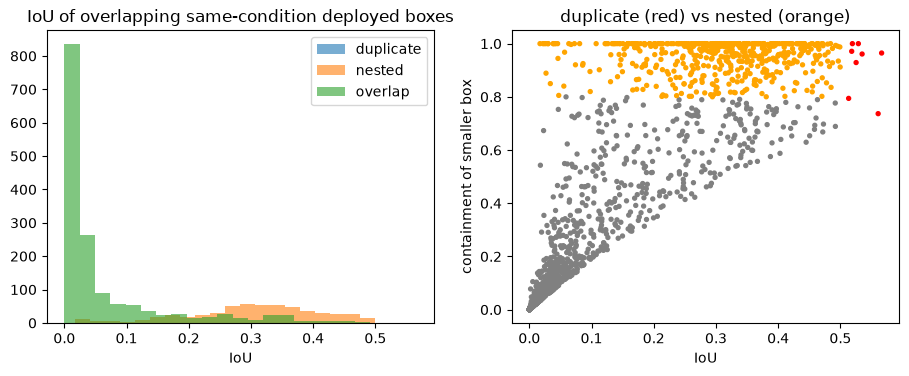

,condition,per_member_nms_iou,fusion_iou,members,deployed_threshold,post_fusion_nms
0,Acne,0.6,0.5,3,0.275,none (as deployed)
1,Hyperpigmentation,0.6,0.5,3,0.225,none (as deployed)
2,Eczema,0.6,0.5,3,0.250,none (as deployed)


coordinate-conversion round-trip check passed (3 aspect ratios).


In [50]:
def overlap_relation(a, b):
    i, c = iou_xyxy(a, b), containment(a, b)
    return "duplicate" if i > CFG.DUP_IOU else "nested" if c >= CFG.NESTED_CONTAINMENT else "overlap" if i > 0 else "none", i, c


def overlap_report(det_df, only_deployed=True):
    pairs = []
    d = det_df[det_df.deployed] if only_deployed else det_df
    for (iid, cond), g in d.groupby(["image_id", "condition"]):
        bx = g[["x0", "y0", "x1", "y1"]].to_numpy()
        for i in range(len(bx)):
            for j in range(i + 1, len(bx)):
                rel, iou_v, con = overlap_relation(bx[i], bx[j])
                if rel != "none": pairs.append(dict(image_id=iid, condition=cond, relation=rel, iou=iou_v, containment=con))
    return pd.DataFrame(pairs, columns=["image_id", "condition", "relation", "iou", "containment"])


if len(DET):
    OV = overlap_report(DET)
    n_img = EVID[EVID.state == "detected"].groupby("condition").image_id.nunique()
    summ = OV.groupby(["condition", "relation"]).image_id.nunique().unstack(fill_value=0) if len(OV) else pd.DataFrame()
    summ = summ.reindex(CFG.CONDITIONS).fillna(0).astype(int)
    summ.insert(0, "images_with_detections", n_img.reindex(CFG.CONDITIONS).fillna(0).astype(int))
    display(summ); write_csv(summ.reset_index(), os.path.join(CFG.DIRS["yolo"], "duplicate_overlap_summary.csv"))
    nm = DET.groupby(["condition"]).agg(pool_boxes=("conf", "size"), deployed_boxes=("deployed", "sum"), mean_support=("ensemble_support", "mean"))
    display(nm)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    if len(OV):
        for rel, g in OV.groupby("relation"): ax[0].hist(g.iou, bins=20, alpha=0.6, label=rel)
        ax[0].legend(); ax[0].set_title("IoU of overlapping same-condition deployed boxes"); ax[0].set_xlabel("IoU")
        ax[1].scatter(OV.iou, OV.containment, s=8, c=OV.relation.map({"duplicate": "r", "nested": "orange", "overlap": "gray"})); ax[1].set_xlabel("IoU"); ax[1].set_ylabel("containment of smaller box"); ax[1].set_title("duplicate (red) vs nested (orange)")
    savefig(fig, "yolo_overlap_diagnostics")
    cfgtbl = pd.DataFrame([dict(condition=c, per_member_nms_iou=sp.nms_iou, fusion_iou=sp.fusion_iou if len(sp.members) > 1 else None, members=len(sp.members), deployed_threshold=sp.threshold,
                                post_fusion_nms="none (as deployed)") for c, sp in DETECTORS.items() if sp.available])
    display(cfgtbl); write_csv(cfgtbl, os.path.join(CFG.DIRS["yolo"], "postprocessing_configuration.csv"))

    # coordinate-conversion self-check: a synthetic box pasted at a known position must be recovered by the letterbox inverse mapping
    def _letterbox_roundtrip(W, H, S, box):
        scale = min(S / W, S / H); nw, nh = round(W * scale), round(H * scale); px, py = (S - nw) // 2, (S - nh) // 2
        x0, y0, x1, y1 = box; lb = [x0 * scale + px, y0 * scale + py, x1 * scale + px, y1 * scale + py]
        return [(lb[0] - px) / scale, (lb[1] - py) / scale, (lb[2] - px) / scale, (lb[3] - py) / scale]
    for (_w, _h, _s) in [(640, 480, 800), (1280, 1280, 640), (300, 900, 800)]:
        rt = _letterbox_roundtrip(_w, _h, _s, [10.0, 20.0, 100.0, 120.0])
        assert np.allclose(rt, [10, 20, 100, 120], atol=1e-3), "letterbox coordinate conversion is not invertible"
    print("coordinate-conversion round-trip check passed (3 aspect ratios).")

In [51]:
# 24.5 False-positive / missed-region statistics on VERIFIED data only (dev splits here; the test split is evaluated later, once).
def cond_flag_rates(split_names):
    if not len(EVID): return None
    e = EVID.merge(DF[["image_id", "split", "y_acne", "y_hyperpigmentation", "y_eczema", "eval_ok", "image_origin"]], on="image_id")
    e = e[e.split.isin(split_names) & e.eval_ok]
    rows = []
    for c in CFG.CONDITIONS:
        col = "y_" + COND_COLS[c]; g = e[e.condition == c]
        for lab, name in [(1, "present"), (0, "absent")]:
            gg = g[g[col] == lab]
            if len(gg) == 0: continue
            rows.append(dict(condition=c, verified_label=name, n_images=len(gg), detector_not_available=int((gg.state == "not_available").sum()), detected=int((gg.state == "detected").sum()),
                             no_qualifying=int((gg.state == "no_qualifying").sum()), detection_rate_where_available=float((gg.state == "detected").sum() / max(1, (gg.state != "not_available").sum()))))
    return pd.DataFrame(rows)


FLAG_DEV = cond_flag_rates(DEV)
if FLAG_DEV is not None and len(FLAG_DEV):
    display(FLAG_DEV); write_csv(FLAG_DEV, os.path.join(CFG.DIRS["yolo"], "detector_vs_verified_label_dev.csv"))
    print("detection_rate on verified-Absent images = false-alarm rate (image level); on verified-Present = detector image-level recall.")
else:
    print("No verified labels with detector output in the dev splits yet: false-alarm / recall statistics not available.")

# hard negatives from YOLO false positives (verified-absent condition + deployed box) -> feeds hard-example mining and the review queue
YOLO_FLAGS = {}
if len(EVID):
    fp = EVID.merge(DF[["image_id", "split", "y_acne", "y_hyperpigmentation", "y_eczema", "full_known"]], on="image_id")
    fp = fp[(fp.state == "detected") & (fp.split == "train")]
    for r in fp.itertuples():
        if r.full_known and getattr(r, "y_" + COND_COLS[r.condition]) == 0: YOLO_FLAGS.setdefault(r.image_id, []).append(r.condition)
    _trn = DF[DF.split == "train"].reset_index(drop=True)
    HARD = mine_hard_examples(_trn, _trn[[f"v5_{c}" for c in CFG.V5_CLASS_ORDER]].to_numpy(), yolo_flags=YOLO_FLAGS)
    HARD_USABLE = set(HARD[HARD.usable_for_training].image_id)
    write_csv(HARD, os.path.join(CFG.DIRS["data"], "hard_examples_train_with_yolo.csv"))
    RQ = build_review_queue({k: [f"yolo_{c.lower()}_deployed_box" for c in v] for k, v in YOLO_FLAGS.items()})
    print("hard examples now:", len(HARD), "(YOLO false positives on verified-absent conditions:", sum(len(v) for v in YOLO_FLAGS.values()), ") | review queue rows:", len(RQ))

,condition,verified_label,n_images,detector_not_available,detected,no_qualifying,detection_rate_where_available
0,Acne,present,460,0,426,34,0.926087
1,Acne,absent,1378,0,382,996,0.277213
2,Hyperpigmentation,present,618,0,550,68,0.889968
3,Hyperpigmentation,absent,1223,0,627,596,0.512674
4,Eczema,present,331,0,293,38,0.885196
5,Eczema,absent,1512,0,586,926,0.387566


detection_rate on verified-Absent images = false-alarm rate (image level); on verified-Present = detector image-level recall.
hard examples now: 1109 (YOLO false positives on verified-absent conditions: 793 ) | review queue rows: 1646


In [52]:
# 24.6 Localisation metrics against VERIFIED region boxes (precision, recall, F1 at the deployed threshold; AP50 and AP50-95; localisation error; FP/FN counts).
#      Eligible (image, condition) pairs: verified-Absent image labels (no GT boxes) or images whose regions of that class were marked `exhaustive`.
def ap_from_matches(scores, tps, n_gt):
    if n_gt == 0: return np.nan
    o = np.argsort(-np.asarray(scores)); tp = np.cumsum(np.asarray(tps)[o]); fp = np.cumsum(1 - np.asarray(tps)[o])
    rec = tp / n_gt; prec = tp / np.maximum(tp + fp, 1e-9)
    mrec = np.concatenate([[0], rec, [1]]); mpre = np.concatenate([[0], prec, [0]])
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]).sum())


def localisation_metrics(split_names, cond, only_deployed=False):
    require_source_permission(split_names, "evaluation")
    sp = DETECTORS[cond]
    if not sp.available: return dict(condition=cond, status="detector_unavailable")
    if not len(REG) or not len(DET): return dict(condition=cond, status="no verified region annotations or no detections")
    cname = cond.lower()
    imgs = DF[DF.split.isin(split_names)]
    r = REG[(REG.split.isin(split_names)) & REG.eval_ok & (REG.label == cname)]
    exh = set(r[r.exhaustive].image_id)
    absent = set(imgs[(imgs["y_" + COND_COLS[cond]] == 0) & imgs.eval_ok].image_id)
    elig = (exh | absent) & set(EVID.image_id)
    gts = {i: g[["x0", "y0", "x1", "y1"]].to_numpy() for i, g in r.groupby("image_id") if i in elig}
    n_gt = int(sum(len(v) for v in gts.values()))
    if n_gt < 10 or len(elig) < 10: return dict(condition=cond, status=f"insufficient verified exhaustive regions ({n_gt} boxes in {len(elig)} images)")
    d = DET[(DET.condition == cond) & DET.image_id.isin(elig)]
    d = d[d.deployed] if only_deployed else d
    out = dict(condition=cond, status="ok", n_images=len(elig), n_gt_boxes=n_gt)
    aps = []
    for thr in np.arange(0.5, 0.96, 0.05):
        sc, tps = [], []
        for iid, g in d.groupby("image_id"):
            gt = gts.get(iid, np.zeros((0, 4))); used = np.zeros(len(gt), bool)
            for b in g.sort_values("conf", ascending=False).itertuples():
                bn = [b.x0 / b.frame_w, b.y0 / b.frame_h, b.x1 / b.frame_w, b.y1 / b.frame_h]
                ious = [iou_xyxy(bn, gg) if not used[k] else 0 for k, gg in enumerate(gt)]
                k = int(np.argmax(ious)) if len(ious) else -1
                if k >= 0 and ious[k] >= thr: used[k] = True; tps.append(1)
                else: tps.append(0)
                sc.append(b.conf)
        aps.append(ap_from_matches(sc, tps, n_gt))
        if abs(thr - 0.5) < 1e-9: out["AP50"] = aps[-1]
    out["AP50_95"] = float(np.nanmean(aps))
    dd = d[d.deployed]; tp = fp = 0; matched_iou = []; ratios = []
    fn = 0
    for iid in elig:
        gt = gts.get(iid, np.zeros((0, 4))); used = np.zeros(len(gt), bool); g = dd[dd.image_id == iid].sort_values("conf", ascending=False)
        for b in g.itertuples():
            bn = [b.x0 / b.frame_w, b.y0 / b.frame_h, b.x1 / b.frame_w, b.y1 / b.frame_h]
            ious = [iou_xyxy(bn, gg) if not used[k] else 0 for k, gg in enumerate(gt)]; k = int(np.argmax(ious)) if len(ious) else -1
            if k >= 0 and ious[k] >= 0.5:
                used[k] = True; tp += 1; matched_iou.append(ious[k]); ratios.append(((bn[2] - bn[0]) * (bn[3] - bn[1])) / max((gt[k][2] - gt[k][0]) * (gt[k][3] - gt[k][1]), 1e-9))
            else: fp += 1
        fn += int((~used).sum())
    out.update(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), tp=tp, fp=fp, fn=fn, median_iou_matched=float(np.median(matched_iou)) if matched_iou else np.nan,
               median_area_ratio_matched=float(np.median(ratios)) if ratios else np.nan, threshold=sp.threshold)
    out["f1"] = 2 * out["precision"] * out["recall"] / max(out["precision"] + out["recall"], 1e-9)
    return out


LOC_DEV = pd.DataFrame([localisation_metrics(DEV, c) for c in CFG.CONDITIONS])
display(LOC_DEV); write_csv(LOC_DEV, os.path.join(CFG.DIRS["yolo"], "localisation_metrics_dev.csv"))
print("(mAP here is computed over the candidate pool down to conf %.2f, not Ultralytics' 0.001; values are therefore comparable across detectors in this notebook but not numerically identical to the training notebooks.)" % CFG.YOLO_POOL_MIN_CONF)

,condition,status
0,Acne,insufficient verified exhaustive regions (0 bo...
1,Hyperpigmentation,insufficient verified exhaustive regions (0 bo...
2,Eczema,insufficient verified exhaustive regions (0 bo...


(mAP here is computed over the candidate pool down to conf 0.05, not Ultralytics' 0.001; values are therefore comparable across detectors in this notebook but not numerically identical to the training notebooks.)


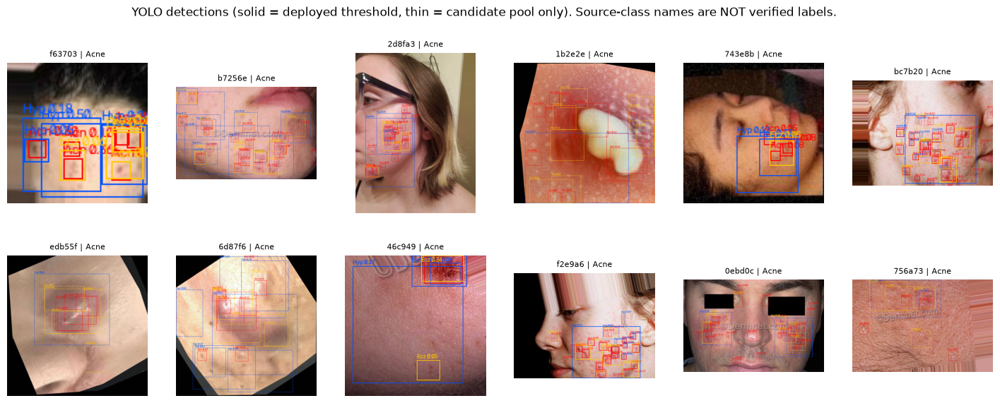

In [53]:
# 24.7 Example gallery of detections on annotated development images (box colour = condition; solid = deployed, dashed = pool-only). Saved for the thesis.
def draw_detections(bgr, recs):
    im = bgr.copy(); col = {"Acne": (0, 0, 255), "Hyperpigmentation": (255, 80, 0), "Eczema": (0, 200, 255)}
    for r in recs:
        p0, p1 = (int(r["x0"]), int(r["y0"])), (int(r["x1"]), int(r["y1"])); th = max(1, bgr.shape[1] // 400)
        cv2.rectangle(im, p0, p1, col[r["condition"]], th if r["deployed"] else 1)
        cv2.putText(im, f"{r['condition'][:3]} {r['conf']:.2f}", (p0[0], max(10, p0[1] - 3)), cv2.FONT_HERSHEY_SIMPLEX, max(0.35, bgr.shape[1] / 1600), col[r["condition"]], 1)
    return im


if len(DET):
    ids = [i for i in DET.image_id.unique() if DF.set_index("image_id").loc[i].split in DEV][:CFG.N_EXAMPLE_IMAGES]
    byid = DF.set_index("image_id"); fig, ax = plt.subplots(2, 6, figsize=(18, 6.5)); ax = ax.ravel()
    for a in ax: a.axis("off")
    for a, iid in zip(ax, ids):
        r = byid.loc[iid]; bgr = cv2.imread(r.orig_path if r.has_orig else r.proc_path)
        a.imshow(cv2.cvtColor(draw_detections(bgr, DET[DET.image_id == iid].to_dict("records")), cv2.COLOR_BGR2RGB)); a.set_title(f"{pseudo_id(iid)[-6:]} | {r.src_label}", fontsize=8)
    fig.suptitle("YOLO detections (solid = deployed threshold, thin = candidate pool only). Source-class names are NOT verified labels.")
    savefig(fig, "yolo_detection_gallery")

In [54]:
def astra_refresh_detector_tables():
    global DET, EVID, DETRAW
    DETRAW = [json.loads(line) for line in open(DET_PATH,encoding='utf-8') if line.strip()]
    # 24.3 Flatten to tables: DET (all pool boxes) and EVID (per image x condition: detector state + summary). States:
    #      not_available (no detector / detector error)  |  no_qualifying (detector ran, no box >= deployed threshold)  |  detected (>=1 box >= deployed threshold)
    rows, ev = [], []
    for r in DETRAW:
        if "error" in r:
            for c in CFG.CONDITIONS: ev.append(dict(image_id=r["image_id"], condition=c, state="not_available", reason=r["error"], n_pool=0, n_deployed=0, max_conf=np.nan, best_rel_area=np.nan, best_cx=np.nan, best_cy=np.nan, source=r.get("source", "")))
            continue
        for c in CFG.CONDITIONS:
            d = r["detectors"].get(c)
            if d is None:
                ev.append(dict(image_id=r["image_id"], condition=c, state="not_available", reason="detector_unavailable", n_pool=0, n_deployed=0, max_conf=np.nan, best_rel_area=np.nan, best_cx=np.nan, best_cy=np.nan, source=r["source"])); continue
            bx = d["boxes"]; dep = [b for b in bx if b["deployed"]]
            for b in bx: rows.append(dict(image_id=r["image_id"], source=r["source"], registry=r["registry"], **b))
            best = max(dep, key=lambda b: b["conf"]) if dep else None
            ev.append(dict(image_id=r["image_id"], condition=c, state="detected" if dep else "no_qualifying", reason="", n_pool=len(bx), n_deployed=len(dep), max_conf=best["conf"] if best else np.nan,
                           best_rel_area=best["rel_area"] if best else np.nan, best_cx=best["cx"] if best else np.nan, best_cy=best["cy"] if best else np.nan, source=r["source"]))
    DET = pd.DataFrame(rows); EVID = pd.DataFrame(ev)
    if len(EVID):
        print(EVID.groupby(["condition", "state"]).size().unstack(fill_value=0))
        print("detection image source:", EVID.drop_duplicates("image_id").source.value_counts().to_dict(),
              "\n  (processed_224_upsampled = detectors were run on a 224x224 image upsampled to their input size: out-of-domain for 800-px detectors; provide ORIGINAL_IMAGE_ROOT.)")
        write_csv(EVID, os.path.join(CFG.DIRS["yolo"], "evidence_per_image_condition.csv")); write_csv(DET, os.path.join(CFG.DIRS["yolo"], "detections_flat.csv"))

# Part VI — YOLO-Guided Regions of Interest and the ROI MobileNetV2

Sections: **(25) ROI extraction · (26) ROI training-set preparation · (27) ROI MobileNetV2 training · (28) ROI feature aggregation.**

This is where **YOLO information genuinely flows into MobileNetV2**: the boxes proposed by the three detectors select image regions; a MobileNetV2 looks at each region (its own pixels, with context) and produces an embedding and region-level condition scores that the fusion network later consumes.

**Design rules.**
* *Proposals are imperfect, so training uses imperfect proposals.* ROI training examples are the detectors' **actual proposals** on training images, labelled from **verified region annotations** (IoU ≥ 0.5 with a verified box of a class ⇒ that class; a reviewed `background_false_positive` region, or a proposal on a *verified-Normal* image ⇒ **Background**; anything else ⇒ **ignored**). The YOLO class is **never** the label.
* *Leakage control.* Crops are derived **after** the frozen split and only from images of the split being built; no ROI of a test image exists in any training table.
* *Variable ROI counts.* Tier 1 = boxes above the deployed threshold (round-robin across detectors, duplicates suppressed); Tier 2 = lower-confidence candidates from the pool; Tier 3 = **alternative context crops** (wider margin) of Tier-1 boxes — different pixels, used by the verification cycle. Empty detection ⇒ zero ROIs (an explicit mask), never a fabricated crop.
* *Crop procedure.* Expand the box by `ROI_MARGIN` on each side, make it **square** by extending the shorter side (context-preserving, no stretching), shift it inside the image (never zero-pad), resize bilinearly to the ROI input size, then `(p/127.5)−1`. Validity checks reject degenerate, out-of-range and too-small boxes with an explicit reason.
* *Memory.* ROI input is 224×224; Astra starts with batch 8 and a 4 GB TensorFlow cap. Only bounded synthetic batches have been tested; full-epoch memory safety is unverified. Training crops are cached under this run's `roi/crops/`.

In [55]:
# 25.1 Square, context-preserving crop and the ROI candidate builder.
ROI_S = 224          # ROI network input (the cached ImageNet weights exist for 224)


def square_crop_box(x0, y0, x1, y1, W, H, margin):
    """Margin-expanded SQUARE window containing the box, shifted to lie inside the image. Returns (cx0, cy0, side) ints, or None if the box is invalid."""
    vals = np.array([x0, y0, x1, y1], float)
    if not np.isfinite(vals).all() or x1 - x0 < 2 or y1 - y0 < 2: return None
    side = max(x1 - x0, y1 - y0) * (1 + 2 * margin)
    side = min(side, W, H)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    nx0 = min(max(cx - side / 2, 0), W - side); ny0 = min(max(cy - side / 2, 0), H - side)
    side_i = int(round(side))
    return int(round(nx0)), int(round(ny0)), max(side_i, 2)


def crop_roi(bgr, box, margin=None, size=None):
    """Returns (rgb_uint8 [size,size,3] or None, reason). reason == '' when valid."""
    H, W = bgr.shape[:2]; margin = CFG.ROI_MARGIN if margin is None else margin; size = size or ROI_S
    x0, y0, x1, y1 = box
    if max(x1 - x0, y1 - y0) < CFG.ROI_MIN_SIDE_FRAC * min(W, H): return None, "too_small"
    if x0 < -1 or y0 < -1 or x1 > W + 1 or y1 > H + 1: return None, "outside_image"
    sq = square_crop_box(x0, y0, x1, y1, W, H, margin)
    if sq is None: return None, "degenerate_box"
    cx0, cy0, side = sq
    crop = bgr[cy0:cy0 + side, cx0:cx0 + side]
    if crop.size == 0 or min(crop.shape[:2]) < 2: return None, "empty_crop"
    return cv2.cvtColor(cv2.resize(crop, (size, size), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB), ""


def roi_norm(rgb_uint8):
    return (rgb_uint8.astype(np.float32) / 127.5) - 1.0


def build_roi_candidates(det_rows, W, H):
    """det_rows: list of detection dicts for ONE image (all conditions, pool). Returns a list of ROI candidate dicts with tier/alt/geometry. Deterministic."""
    cand = sorted(det_rows, key=lambda r: -r["conf"])
    box = lambda r: (r["x0"], r["y0"], r["x1"], r["y1"])
    chosen = []
    def dup(r): return any(iou_xyxy(box(r), box(c)) > CFG.ROI_OVERLAP_SUPPRESS_IOU for c in chosen)
    # tier 1: deployed boxes, round-robin over detectors so that one chatty detector cannot fill every slot
    per = {c: [r for r in cand if r["deployed"] and r["condition"] == c] for c in CFG.CONDITIONS}
    t1 = []
    while len(t1) < CFG.ROI_MAX_TIER1 and any(per.values()):
        for c in CFG.CONDITIONS:
            if per[c] and len(t1) < CFG.ROI_MAX_TIER1:
                r = per[c].pop(0)
                if not dup(r): chosen.append(r); t1.append(r)
    n_alt = min(len(t1), max(0, CFG.ROI_MAX_TOTAL // 4))
    t2 = []
    for r in cand:
        if len(t1) + len(t2) + n_alt >= CFG.ROI_MAX_TOTAL: break
        if not r["deployed"] and not dup(r): chosen.append(r); t2.append(r)
    out = []
    for tier, lst, alt in [(1, t1, False), (2, t2, False), (3, t1[:n_alt], True)]:
        for r in lst:
            geo = dict(w_rel=(r["x1"] - r["x0"]) / W, h_rel=(r["y1"] - r["y0"]) / H)
            out.append(dict(tier=tier, alt=alt, condition=r["condition"], conf=r["conf"], deployed=r["deployed"], support_frac=r["ensemble_support"] / max(r["ensemble_size"], 1),
                            x0=r["x0"], y0=r["y0"], x1=r["x1"], y1=r["y1"], rel_area=r["rel_area"], cx=r["cx"], cy=r["cy"], w_rel=geo["w_rel"], h_rel=geo["h_rel"],
                            aspect=float(np.clip(geo["w_rel"] * W / max(geo["h_rel"] * H, 1e-6), 0.1, 10.0))))
    return out


YOLO_FEATURE_NAMES = ["cond_acne", "cond_hyper", "cond_eczema", "conf", "rel_area", "cx", "cy", "w_rel", "h_rel", "aspect_log", "deployed", "support_frac", "tier1", "tier2", "tier3_alt"]


def yolo_roi_features(c):
    onehot = [1.0 if c["condition"] == k else 0.0 for k in CFG.CONDITIONS]
    return onehot + [c["conf"], c["rel_area"], c["cx"], c["cy"], c["w_rel"], c["h_rel"], float(np.log(c["aspect"])), float(c["deployed"]), c["support_frac"],
                     float(c["tier"] == 1), float(c["tier"] == 2), float(c["tier"] == 3)]

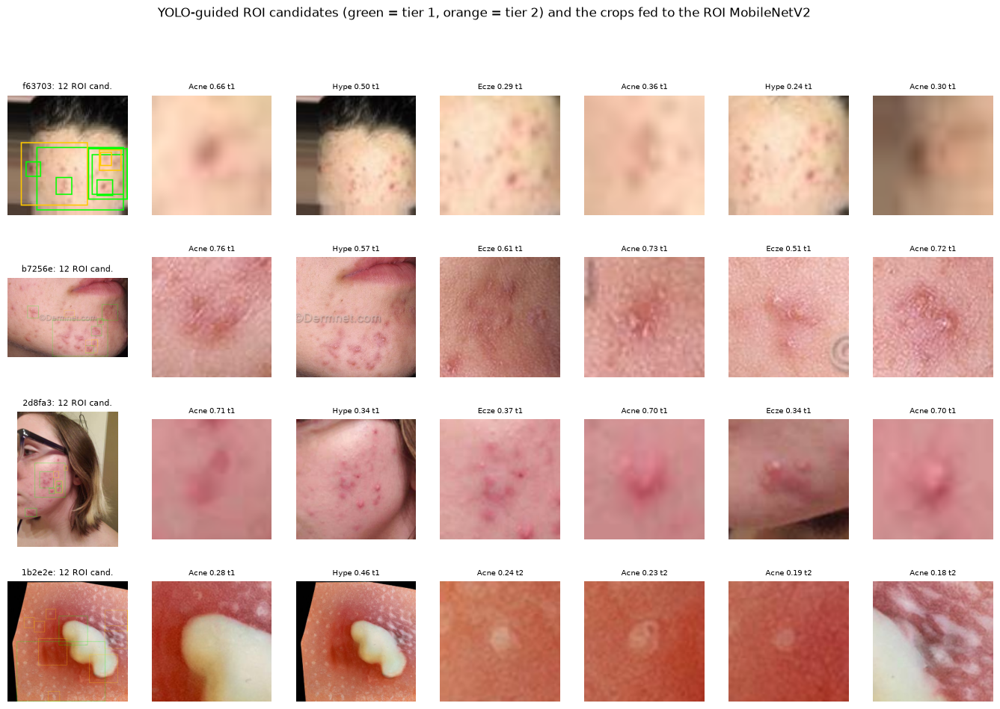

In [56]:
# 25.2 ROI visualisation on a few annotated development images (Tier 1 solid, Tier 2 dashed-look thin, Tier 3 = wider context window).
DET_BY_IMG = {iid: g.to_dict("records") for iid, g in DET.groupby("image_id")} if len(DET) else {}
EVID_IDS = set(EVID.image_id) if len(EVID) else set()


def det_rows_for(iid):
    return DET_BY_IMG.get(iid, [])


def show_roi_examples(n=4):
    if not len(DET): print("no detections yet"); return
    byid = DF.set_index("image_id"); ids = [i for i in DET.image_id.unique() if byid.loc[i].split in DEV and len(DET[(DET.image_id == i) & DET.deployed])][:n]
    if not ids: print("no development image with a deployed detection to illustrate"); return
    fig, ax = plt.subplots(n, 7, figsize=(17, 2.7 * n), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for row, iid in enumerate(ids):
        r = byid.loc[iid]; bgr = cv2.imread(r.orig_path if r.has_orig else r.proc_path); H, W = bgr.shape[:2]
        cands = build_roi_candidates(det_rows_for(iid), W, H); vis = bgr.copy()
        for c in cands:
            if c["alt"]: continue
            cv2.rectangle(vis, (int(c["x0"]), int(c["y0"])), (int(c["x1"]), int(c["y1"])), (0, 255, 0) if c["tier"] == 1 else (0, 200, 255), max(1, W // 400))
        ax[row, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[row, 0].set_title(f"{pseudo_id(iid)[-6:]}: {len(cands)} ROI cand.", fontsize=8)
        k = 1
        for c in cands[:6]:
            rgb, why = crop_roi(bgr, (c["x0"], c["y0"], c["x1"], c["y1"]), CFG.ROI_ALT_MARGIN if c["alt"] else CFG.ROI_MARGIN)
            if rgb is not None and k < 7: ax[row, k].imshow(rgb); ax[row, k].set_title(f"{c['condition'][:4]} {c['conf']:.2f} t{c['tier']}{' alt' if c['alt'] else ''}", fontsize=7); k += 1
    fig.suptitle("YOLO-guided ROI candidates (green = tier 1, orange = tier 2) and the crops fed to the ROI MobileNetV2")
    savefig(fig, "roi_examples")


show_roi_examples()

## 26. ROI training-set preparation (verified regions → labelled proposals)
The table below is built **separately for `train` and `validation`** (the `fusion` and `test` splits never produce ROI *training* rows). It needs verified region annotations (`regions_train`, `regions_validation` gates) and detector output for those images; otherwise it stops with the exact shortfall.

In [57]:
ROI_DIR = CFG.DIRS["roi"]; CROP_DIR = os.path.join(ROI_DIR, "crops"); os.makedirs(CROP_DIR, exist_ok=True)
try: os.chmod(CROP_DIR, 0o700)
except OSError: pass


def purge_roi_cache():
    """Delete cached ROI crops (they are derived from identifiable facial photographs)."""
    n = 0
    for f in glob.glob(os.path.join(CROP_DIR, "*.png")): os.remove(f); n += 1
    print("deleted", n, "cached ROI crops"); log_event("roi_cache_purged", n=n)


def label_proposal(c, W, H, regs, image_all_absent):
    """Label a proposal from VERIFIED regions of its image. Returns class 0..2, 3 (Background) or -1 (ignore). The detector's own class is never used."""
    bn = (c["x0"] / W, c["y0"] / H, c["x1"] / W, c["y1"] / H)
    best, bi = 0.0, -1
    for r in regs.itertuples():
        i = iou_xyxy(bn, (r.x0, r.y0, r.x1, r.y1))
        if i > best: best, bi = i, r.cls
    if bi >= 0 and best >= CFG.ROI_MATCH_IOU: return int(bi)                     # 0 acne, 1 hyper, 2 eczema, 3 background_false_positive (a reviewed negative proposal)
    if image_all_absent and best < CFG.ROI_BG_MAX_IOU: return 3                    # verified-Normal image: any proposal that touches no verified region is background
    return -1


def build_roi_table(split):
    require_source_permission([split], "training" if split in ("train", "validation", "fusion") else "evaluation")
    gate(f"regions_{split}")
    if not len(DET): raise GateError("No YOLO detections available: run Section 24 first.")
    ids = DF[(DF.split == split)].image_id
    rows = []; byid = DF.set_index("image_id"); regs_all = REG[(REG.split == split) & (REG.train_ok if split == "train" else REG.eval_ok)]
    reg_ids = set(regs_all.image_id)
    for iid in ids:
        r = byid.loc[iid]
        if iid not in EVID_IDS: continue                                           # YOLO was not run for this image
        if iid not in reg_ids and not (r.full_known and r.n_present == 0): continue   # no verified regions and not a verified-Normal image: nothing can be labelled
        src, _ = det_image_path(r); bgr = cv2.imread(src)
        if bgr is None: continue
        H, W = bgr.shape[:2]
        regs = regs_all[regs_all.image_id == iid]; all_absent = bool(r.full_known and r.n_present == 0)
        for k, c in enumerate([c for c in build_roi_candidates(det_rows_for(iid), W, H) if not c["alt"]]):
            lab = label_proposal(c, W, H, regs, all_absent)
            if lab < 0: continue
            rgb, why = crop_roi(bgr, (c["x0"], c["y0"], c["x1"], c["y1"]))
            if rgb is None: continue
            rid = pseudo_id(f"{iid}|{k}|{c['x0']:.0f}|{c['y0']:.0f}", "roi"); path = os.path.join(CROP_DIR, rid + ".png")
            if not os.path.exists(path): cv2.imwrite(safe_path(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
            rows.append(dict(roi_id=rid, image_id=iid, split=split, label=lab, path=path, det_condition=c["condition"], conf=c["conf"], tier=c["tier"], group_id=int(r.group_id), source=("original" if r.has_orig else "processed")))
    return pd.DataFrame(rows)


ROI_TABLES = {}
for sp in ["train", "validation"]:
    try:
        ROI_TABLES[sp] = build_roi_table(sp); print(sp, "ROI rows:", len(ROI_TABLES[sp]), ROI_TABLES[sp].label.value_counts().sort_index().to_dict() if len(ROI_TABLES[sp]) else "")
    except GateError as g:
        ROI_TABLES[sp] = None; print(f"[ROI table {sp}] BLOCKED - {g}")
if all(t is not None and len(t) for t in ROI_TABLES.values()):
    for sp, t in ROI_TABLES.items(): write_csv(t.drop(columns=["path"]), os.path.join(ROI_DIR, f"roi_table_{sp}.csv"))
    assert not (set(ROI_TABLES["train"].image_id) & set(ROI_TABLES["validation"].image_id)), "ROI leakage: an image is in both ROI tables"
    assert not (set(ROI_TABLES["train"].group_id) & set(ROI_TABLES["validation"].group_id)), "ROI leakage: a leakage group is in both ROI tables"
    cnt = pd.crosstab(ROI_TABLES["train"].det_condition, ROI_TABLES["train"].label.map(dict(enumerate(CFG.ROI_CLASSES))))
    display(cnt)
    print("ROI classes:", CFG.ROI_CLASSES, "| rows with source=processed are crops from 224x224 images (low detail):", int((ROI_TABLES['train'].source == 'processed').sum()))
    set_gate("roi_training_data", True)
else:
    set_gate("roi_training_data", False, "ROI training tables are empty: need verified region annotations + detector output for train and validation images")

train ROI rows: 4320 {0: 1583, 1: 778, 2: 743, 3: 1216}
validation ROI rows: 1378 {0: 275, 1: 132, 2: 99, 3: 872}


label,Acne,Background,Eczema,Hyperpigmentation
det_condition,,,,
Acne,1354,358,88,17
Eczema,197,437,575,112
Hyperpigmentation,32,421,80,649


ROI classes: ['Acne', 'Hyperpigmentation', 'Eczema', 'Background'] | rows with source=processed are crops from 224x224 images (low detail): 0


In [58]:
# 27.1 ROI MobileNetV2 (separate encoder, 4 classes: Acne / Hyperpigmentation / Eczema / Background) + resumable staged training.
ROI_INIT = "imagenet"            # 'imagenet' or 'global' (copy the selected global model's backbone weights as the starting point)
ROI_AUG = keras.Sequential([keras.layers.RandomFlip("horizontal_and_vertical"), keras.layers.RandomRotation(15 / 360.0, fill_mode="reflect"),
                            keras.layers.RandomZoom((-0.15, 0.10), fill_mode="reflect"), keras.layers.RandomBrightness(0.08, value_range=(0, 255)), keras.layers.RandomContrast(0.08)], name="roi_aug")


def make_roi_ds(paths, y, w=None, training=False, batch=None):
    batch = batch or CFG.ROI_BATCH
    w = np.ones(len(paths), np.float32) if w is None else np.asarray(w, np.float32)
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths), np.asarray(y, np.int32), w))
    if training: ds = ds.shuffle(min(4096, len(paths)), reshuffle_each_iteration=True)
    dec = lambda p: tf.image.resize(tf.cast(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False), tf.float32), [ROI_S, ROI_S])
    ds = ds.map(lambda p, yy, ww: (dec(p), yy, ww), num_parallel_calls=AUTOTUNE).batch(batch)
    if training: ds = ds.map(lambda x, yy, ww: (tf.clip_by_value(ROI_AUG(x, training=True), 0, 255), yy, ww), num_parallel_calls=AUTOTUNE)
    return ds.map(lambda x, yy, ww: (x / 127.5 - 1.0, yy, ww), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


def build_roi_model():
    base = pretrained_backbone(); base.trainable = False
    if ROI_INIT == "global":
        require(GLOBAL_SELECTED[0], "ROI_INIT='global' needs a selected global model (Section 22)", gate=True)
        gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
        base.set_weights(find_backbone(gm).get_weights())
    inp = keras.layers.Input((ROI_S, ROI_S, 3), name="roi_nhwc_m1p1")
    x = base(inp, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="roi_gap")(x); x = keras.layers.Dropout(CFG.HEAD_DROPOUT, name="roi_drop1")(x)
    x = keras.layers.Dense(CFG.ROI_EMB, activation="relu", kernel_regularizer=keras.regularizers.l2(CFG.HEAD_L2), name="roi_embedding")(x)
    x = keras.layers.Dropout(CFG.HEAD_DROPOUT, name="roi_drop2")(x)
    out = keras.layers.Dense(len(CFG.ROI_CLASSES), activation="softmax", dtype="float32", name="roi_probs")(x)
    return keras.Model(inp, out, name="lumyvue_roi_mobilenetv2"), base


class ValROI(keras.callbacks.Callback):
    def __init__(self, ds_val, y_val):
        super().__init__(); self.ds, self.y = ds_val, y_val
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        p = self.model.predict(self.ds.map(lambda x, y, w: x), verbose=0).argmax(1)
        f1 = []; rec = []
        for k in range(len(CFG.ROI_CLASSES)):
            tp = int(((p == k) & (self.y == k)).sum()); fp = int(((p == k) & (self.y != k)).sum()); fn = int(((p != k) & (self.y == k)).sum())
            f1.append(2 * tp / max(2 * tp + fp + fn, 1) if (tp + fp + fn) else np.nan); rec.append(tp / max(tp + fn, 1) if (tp + fn) else np.nan)
        logs["val_macro_f1"] = float(np.nanmean(f1)); logs["val_macro_recall"] = float(np.nanmean(rec)); logs["val_sel"] = logs["val_macro_f1"]
        print(f"   ROI val_macro_f1={logs['val_macro_f1']:.4f} recalls={np.round(rec, 3).tolist()}")


def restore_selected_roi_phase(model, checkpoint_dir, fA, fB):
    """Restore the phase actually selected by validation, including an A win."""
    phase = "B" if fB >= fA else "A"
    path = os.path.join(checkpoint_dir, f"phase{phase}_best.weights.h5")
    require(os.path.isfile(path), f"Selected ROI phase {phase} checkpoint is missing: {path}", gate=True)
    model.load_weights(path)
    return phase


def run_roi_phase(seed, phase, model, base, ds_tr, ds_va, y_va, epochs, lr):
    set_trainable(model,base,phase,CFG.FINE_TUNE_AT)
    model.compile(optimizer=keras.optimizers.Adam(lr),loss=keras.losses.SparseCategoricalCrossentropy(),metrics=['accuracy'],jit_compile=False)
    directory = os.path.join(CFG.DIRS['checkpoints'],'ROI',f'seed_{seed}')
    identity = training_identity('ROI',phase,seed,{k:t.to_dict('list') for k,t in ROI_TABLES.items()})
    model,rec = recovery_fit(model,ds_tr,ds_va,os.path.join(directory,'recovery_'+phase),identity,epochs,
        monitor='val_sel',mode='max',metric_callbacks=[ValROI(ds_va,y_va)],verbose=2)
    astra_phase_record(model,rec,directory,phase)
    return model

## 27. ROI classifier training — run cell by cell
Phase A trains the head with a frozen backbone; Phase B partially unfreezes it (BatchNorm frozen). The notebook **records the validation macro-F1 after Phase A and after Phase B** and keeps whichever is better, which answers the freezing / partial / full question empirically: *full fine-tuning is not run* (it overfits small ROI sets and costs memory on an 8 GB GPU) — full unfreezing is not implemented in Astra. Seeds are `CFG.SEEDS`; the best seed is chosen on validation macro-F1 only. **>>> THIS CELL TRAINS MODELS <<<**

In [59]:
ROI_RESULTS = {}
ROI_SELECTED_SEED = None
def astra_roi_phase(phase):
    global ROI_SELECTED_SEED
    require_source_permission(['train','validation'],'training')
    for g in ['roi_training_data','regions_train','regions_validation']: gate(g)
    tr,va=ROI_TABLES['train'],ROI_TABLES['validation']
    require(tr.label.nunique()==4 and len(tr)>=100,'ROI needs all four classes and >=100 matched training rows',gate=True)
    cw=len(tr)/(4*np.maximum(np.bincount(tr.label.values,minlength=4),1))
    ds_tr=make_roi_ds(tr.path.values,tr.label.values,cw[tr.label.values].astype(np.float32),True)
    ds_va=make_roi_ds(va.path.values,va.label.values,None,False)
    for seed in CFG.SEEDS:
        keras.backend.clear_session();set_all_seeds(seed)
        directory=os.path.join(CFG.DIRS['checkpoints'],'ROI',f'seed_{seed}')
        if phase=='A': model,base=build_roi_model()
        else:
            record=json.load(open(os.path.join(directory,'phaseA_state.json')))
            model=keras.models.load_model(os.path.join(record['attempt'],record['selected']));base=find_backbone(model)
        model=run_roi_phase(seed,phase,model,base,ds_tr,ds_va,va.label.values,
            CFG.ROI_PHASE_A_EPOCHS if phase=='A' else CFG.ROI_PHASE_B_EPOCHS,CFG.PHASE_A_LR if phase=='A' else CFG.PHASE_B_LR)
        if phase=='B':
            model,selected=astra_select_phase(directory,'val_macro_f1')
            save_selected_model(model,os.path.join(directory,'final_best.keras'))
            vals=[json.load(open(os.path.join(directory,f'phase{p}_state.json')))['best_metric'] for p in 'AB']
            ROI_RESULTS[seed]=dict(frozen_backbone_val_macro_f1=vals[0],partial_finetune_val_macro_f1=vals[1],chosen=selected)
    if phase=='B':
        ROI_SELECTED_SEED=max(ROI_RESULTS,key=lambda s:max(ROI_RESULTS[s]['frozen_backbone_val_macro_f1'],ROI_RESULTS[s]['partial_finetune_val_macro_f1']))
        write_json(os.path.join(CFG.DIRS['metrics'],'roi_training_summary.json'),dict(per_seed=ROI_RESULTS,selected_seed=ROI_SELECTED_SEED,init=ROI_INIT))

## Astra ROI Phase A — EXPENSIVE, researcher initiated
Requires reviewed proposal matches, all four ROI classes and at least 100 training rows.

In [60]:
astra_require_action('roi_A')
astra_roi_phase('A')

Epoch 6/8


E0000 00:00:1793586990.460087  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_20}}


   ROI val_macro_f1=0.7039 recalls=[0.88, 0.902, 0.586, 0.767]
540/540 - 322s - 597ms/step - accuracy: 0.8234 - loss: 0.4863 - val_accuracy: 0.7896 - val_loss: 0.6170 - val_macro_f1: 0.7039 - val_macro_recall: 0.7836 - val_sel: 0.7039 - learning_rate: 5.0000e-04
Epoch 7/8
   ROI val_macro_f1=0.7270 recalls=[0.916, 0.833, 0.677, 0.773]
540/540 - 302s - 559ms/step - accuracy: 0.8317 - loss: 0.4737 - val_accuracy: 0.8004 - val_loss: 0.5833 - val_macro_f1: 0.7270 - val_macro_recall: 0.7999 - val_sel: 0.7270 - learning_rate: 5.0000e-04
Epoch 8/8
   ROI val_macro_f1=0.7071 recalls=[0.862, 0.833, 0.758, 0.751]
540/540 - 297s - 550ms/step - accuracy: 0.8359 - loss: 0.4649 - val_accuracy: 0.7816 - val_loss: 0.6453 - val_macro_f1: 0.7071 - val_macro_recall: 0.8010 - val_sel: 0.7071 - learning_rate: 5.0000e-04


## Astra ROI Phase B and phase selection — EXPENSIVE, researcher initiated
Restores and saves the actual winning phase, with B winning ties.

In [61]:
astra_require_action('roi_B')
astra_roi_phase('B')

Epoch 1/12


E0000 00:00:1793588282.493231  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_20}}


   ROI val_macro_f1=0.7125 recalls=[0.902, 0.886, 0.616, 0.759]
540/540 - 304s - 563ms/step - accuracy: 0.8296 - loss: 0.4948 - val_accuracy: 0.7896 - val_loss: 0.5916 - val_macro_f1: 0.7125 - val_macro_recall: 0.7909 - val_sel: 0.7125 - learning_rate: 1.0000e-05
Epoch 2/12
   ROI val_macro_f1=0.7236 recalls=[0.873, 0.811, 0.778, 0.768]
540/540 - 301s - 557ms/step - accuracy: 0.8373 - loss: 0.4527 - val_accuracy: 0.7939 - val_loss: 0.5679 - val_macro_f1: 0.7236 - val_macro_recall: 0.8074 - val_sel: 0.7236 - learning_rate: 1.0000e-05
Epoch 3/12
   ROI val_macro_f1=0.7393 recalls=[0.909, 0.856, 0.667, 0.794]
540/540 - 293s - 542ms/step - accuracy: 0.8498 - loss: 0.4181 - val_accuracy: 0.8135 - val_loss: 0.5309 - val_macro_f1: 0.7393 - val_macro_recall: 0.8063 - val_sel: 0.7393 - learning_rate: 1.0000e-05
Epoch 4/12
   ROI val_macro_f1=0.6691 recalls=[0.865, 0.924, 0.606, 0.695]
540/540 - 298s - 551ms/step - accuracy: 0.8697 - loss: 0.3821 - val_accuracy: 0.7446 - val_loss: 0.8018 - val_m

## 28. ROI feature aggregation for fusion
For every image of the `fusion` and `test` splits (and for `validation` when diagnosing) the notebook builds a **padded ROI set** of at most `ROI_MAX_TOTAL` regions: for each ROI the ROI-network *embedding* (64-d), its 4 *softmax scores*, and the YOLO geometry/evidence features. A boolean **mask** marks real ROIs, so images with no detections contribute an *all-false mask* (not a zero crop). The fusion network's **masked attention pooling** (Part VII) aggregates a variable number of ROIs into fixed-size per-condition vectors.

The ROI CNN and the global CNN are used **frozen**, and were trained only on `train` (ROI also selected on `validation`), so features for `fusion` and `test` are out-of-sample.

In [62]:
ROI_FEAT_DIM = CFG.ROI_EMB + len(CFG.ROI_CLASSES) + len(YOLO_FEATURE_NAMES)


def load_roi_feature_model(seed=None):
    seed = seed or ROI_SELECTED_SEED
    require(seed is not None, "no trained ROI model: run Section 27 first", gate=True)
    m = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], "ROI", f"seed_{seed}", "final_best.keras"), compile=False)
    return keras.Model(m.input, [m.get_layer("roi_embedding").output, m.output], name="roi_features")


def roi_sets_for(df, tiers=(1, 2, 3), fm=None):
    """Padded ROI feature tensors for the images in df. Returns dict(feat [N,R,D], mask [N,R], tier [N,R], meta list). Uses detections already cached in DET."""
    R = CFG.ROI_MAX_TOTAL; fm = fm or load_roi_feature_model()
    missing = [i for i in df.image_id if i not in EVID_IDS]
    require(not missing, f"YOLO has not been run for {len(missing)} of these images (e.g. {missing[:2]}): run Section 24 first. An image without detector output must never be treated as 'no detection'.", gate=True)
    N = len(df); feat = np.zeros((N, R, ROI_FEAT_DIM), np.float32); mask = np.zeros((N, R), bool); tier = np.zeros((N, R), np.int8); meta = [[] for _ in range(N)]
    crops, where = [], []
    def flush():
        if not crops: return
        emb, pr = fm.predict(np.stack(crops), verbose=0)
        for j,(n,k,c) in enumerate(where):
            feat[n,k] = np.concatenate([emb[j],pr[j],yolo_roi_features(c)])
            mask[n,k] = True; tier[n,k] = c['tier']
            meta[n].append(dict(tier=c['tier'],alt=c['alt'],condition=c['condition'],conf=c['conf'],roi_probs=pr[j].round(4).tolist()))
        crops.clear(); where.clear()
    for n, r in enumerate(df.itertuples()):
        src, _ = det_image_path(r); bgr = cv2.imread(src)
        if bgr is None: continue
        H, W = bgr.shape[:2]; k = 0
        for c in build_roi_candidates(det_rows_for(r.image_id), W, H):
            if c["tier"] not in tiers or k >= R: continue
            rgb, why = crop_roi(bgr, (c["x0"], c["y0"], c["x1"], c["y1"]), CFG.ROI_ALT_MARGIN if c["alt"] else CFG.ROI_MARGIN)
            if rgb is None: continue
            crops.append(roi_norm(rgb)); where.append((n, k, c)); k += 1
            if len(crops) >= CFG.ROI_BATCH: flush()
    flush()
    return dict(feat=feat, mask=mask, tier=tier, meta=meta)


def cached_roi_sets(split, tiers=(1, 2, 3)):
    require_source_permission([split], "training" if split in ("train", "validation", "fusion") else "evaluation")
    df = DF[(DF.split == split) & (DF.eval_ok | DF.train_ok)] if split != "train" else DF[(DF.split == split) & (DF.eval_ok | DF.train_ok)]
    key = content_digest(dict(ids=df.image_id.values,tiers=tiers,config=vars(CFG),detector=YOLO_CONFIG_HASH,
        model=sha256_file(os.path.join(CFG.DIRS['checkpoints'],'ROI',f'seed_{ROI_SELECTED_SEED}','final_best.keras'))))[:24]
    path = os.path.join(ROI_DIR, f"roi_sets_{split}_{key}.npz")
    if os.path.exists(path):
        z = np.load(path, allow_pickle=True); return df, dict(feat=z["feat"], mask=z["mask"], tier=z["tier"], meta=json.loads(str(z["meta"])))
    s = roi_sets_for(df, tiers)
    np.savez_compressed(safe_path(path), feat=s["feat"], mask=s["mask"], tier=s["tier"], meta=json.dumps(s["meta"]))
    return df, s


print("ROI feature dimension per region:", ROI_FEAT_DIM, "=", CFG.ROI_EMB, "(ROI embedding) +", len(CFG.ROI_CLASSES), "(ROI scores) +", len(YOLO_FEATURE_NAMES), "(YOLO geometry/evidence)")

ROI feature dimension per region: 83 = 64 (ROI embedding) + 4 (ROI scores) + 15 (YOLO geometry/evidence)


# Part VII — Trainable Multilabel Fusion, Cross-Fitting, Calibration and Thresholds

Sections: **(29) fusion architecture · (30) fusion training · (31) calibration and threshold selection.**

## Fusion network
Inputs per image (all produced by frozen, out-of-sample models):

| Group | Content | Notes |
|---|---|---|
| Global | 128-d embedding, 3 **logits** of the selected global model (probabilities are clipped and logit-transformed), `p(Normal)` (softmax models) + flag | calibrated *by the fusion*, not averaged with anything |
| Detector evidence (per condition, 7 numbers) | `available`, `detected` (≥ deployed threshold), max deployed confidence, max pool confidence, relative area, centre x, centre y | **no box counts** (not severity/prevalence). `available = 0` ⇒ all other numbers 0 (**missing detector ≠ zero detections**) |
| ROI set (≤ 12 regions) | ROI-CNN embedding (64) + 4 ROI scores + YOLO geometry/evidence features per region, with a **mask** | variable counts, empty set allowed |
| Quality (optional, off by default) | a few technical-quality numbers | only enable if Section 38 shows they carry information |

**Aggregation of regions:** *masked attention pooling* — three attention heads (one per condition) score each region, a softmax over the **real** regions (masked) gives weights, and the weighted sums are concatenated with the global and detector features → MLP → **3 logits** (one per condition). **Modality dropout** randomly hides the whole detector-evidence group and/or the ROI group during training, so the network cannot learn to simply trust YOLO and learns how to behave when a branch is missing (Eczema detector unavailable, no detections, …).

**Loss:** the same *masked* binary cross-entropy (Unknown labels contribute nothing). Labels for the fusion split come from the **reference standard** (dermatologist-verified).

## Leakage control (the reason for the `fusion` split)
The CNNs were trained on `train` (selected on `validation`). The fusion network is trained and calibrated on `fusion` images held out from the new V6 CNN fits (historical V5/YOLO exposure remains documented), using **grouped K-fold cross-fitting**: every `fusion` image receives an *out-of-fold* fusion logit from a model that never saw its group. Out-of-fold logits are the only data used to fit **calibration**, **thresholds**, the **Stage-1 reliability rule** and the **abstention bands** — all frozen before the `test` split is opened. The final fusion models (one per seed, trained on all `fusion` data, logits averaged) are applied to `test` once.

In [63]:
# 29.1 Feature assembly. A missing detector is encoded by available=0 (never by 'detected=0').
DET_EV_DIM = 7


def logit(p, eps=1e-4):
    p = np.clip(np.asarray(p, np.float64), eps, 1 - eps)
    return np.log(p / (1 - p)).astype(np.float32)


def global_inputs(df, choice=None):
    choice = choice or GLOBAL_SELECTED
    require(choice[0], "no improved global model selected (Section 22)", gate=True)
    g = global_scores_for(choice[0], choice[1], df)
    pn = g["pnormal"]; has = (~np.isnan(pn)).astype(np.float32)
    return dict(emb=g["emb"].astype(np.float32), logit=logit(g["scores"]), extra=np.stack([np.nan_to_num(pn, nan=0.0), has], 1).astype(np.float32), scores=g["scores"].astype(np.float32))


def detector_evidence(df):
    """[N,3,7]: available, detected, max deployed conf, max pool conf, rel area, cx, cy. Unavailable detector (or image without detector output) -> all zeros incl. available=0."""
    ev = np.zeros((len(df), CFG.N_COND, DET_EV_DIM), np.float32)
    if not len(EVID): return ev
    E = EVID.set_index(["image_id", "condition"])
    pool_max = DET.groupby(["image_id", "condition"]).conf.max() if len(DET) else pd.Series(dtype=float)
    for n, iid in enumerate(df.image_id):
        for j, c in enumerate(CFG.CONDITIONS):
            if (iid, c) not in E.index: continue
            r = E.loc[(iid, c)]
            if r.state == "not_available": continue
            det = r.state == "detected"
            ev[n, j] = [1.0, float(det), 0.0 if not det else float(r.max_conf), float(pool_max.get((iid, c), 0.0)), 0.0 if not det else float(np.sqrt(r.best_rel_area)),
                        0.0 if not det else float(r.best_cx), 0.0 if not det else float(r.best_cy)]
    return ev


QUALITY_FEATURES = ["laplacian_var", "mean_brightness", "over_frac", "under_frac", "uneven_lr", "gray_world_dev"]
FUSION_USE_QUALITY = False


def quality_matrix(df):
    rows = []
    for r in df.itertuples():
        q = image_quality_metrics(cv2.imread(r.orig_path if r.has_orig else r.proc_path), with_face=False)
        rows.append([math.log1p(q["laplacian_var"]), q["mean_brightness"] / 255.0, q["over_frac"], q["under_frac"], q["uneven_lr"], q["gray_world_dev"]])
    return np.asarray(rows, np.float32)


VARIANTS = {                      # which input groups are visible; drop = detectors whose evidence and ROIs are removed
    "full": dict(global_=True, roi=True, det=True, drop=[]),
    "global_yolo": dict(global_=True, roi=False, det=True, drop=[]),         # system E: global + YOLO evidence, no ROI CNN
    "global_only": dict(global_=True, roi=False, det=False, drop=[]),         # trainable re-calibration of the global model only
    "roi_only": dict(global_=False, roi=True, det=False, drop=[]),            # system D: ROI MobileNetV2 branch (with its YOLO geometry), no global model
    "no_acne_evidence": dict(global_=True, roi=True, det=True, drop=["Acne"]),
    "no_eczema_evidence": dict(global_=True, roi=True, det=True, drop=["Eczema"]),
    "no_hyper_evidence": dict(global_=True, roi=True, det=True, drop=["Hyperpigmentation"]),
}


def assemble(df, roi_sets, variant="full", choice=None, max_tier=3):
    """Returns the model-input dict for `df` (rows aligned with roi_sets). Ablations are implemented by hiding groups (zeros + masks), so one architecture serves all variants."""
    v = VARIANTS[variant]; N = len(df); R = CFG.ROI_MAX_TOTAL
    g = global_inputs(df, choice)
    ev = detector_evidence(df); feat = roi_sets["feat"].copy(); mask = roi_sets["mask"] & (roi_sets["tier"] <= max_tier)      # max_tier = evidence available at this verification pass
    for c in v["drop"]:
        j = CFG.CONDITIONS.index(c); ev[:, j, :] = 0
        cond_col = CFG.ROI_EMB + len(CFG.ROI_CLASSES) + YOLO_FEATURE_NAMES.index("cond_" + ("hyper" if c == "Hyperpigmentation" else c.lower()))
        drop = feat[:, :, cond_col] > 0.5
        mask &= ~drop; feat[drop] = 0
    feat[~mask] = 0
    X = dict(g_emb=g["emb"] * v["global_"], g_logit=g["logit"] * v["global_"], g_extra=g["extra"] * v["global_"],
             det_ev=(ev * v["det"]).reshape(N, -1), roi_feat=feat * (v["roi"] or 0), roi_mask=(mask & bool(v["roi"])).astype(np.float32))
    if FUSION_USE_QUALITY: X["quality"] = quality_matrix(df)
    return X, g["scores"]

In [64]:
# 29.2 Fusion network (float32 inside; mixed precision is switched off while it is built because the inputs are tiny and numerically sensitive).
@keras.saving.register_keras_serializable(package="lumyvue")
class MaskedAttentionPool(keras.layers.Layer):
    """K attention heads over a padded set. h: [B,R,H], mask: [B,R] (1 = real region). Returns [B, K*H]; an all-masked set yields zeros."""
    def __init__(self, heads=3, **kw):
        super().__init__(**kw); self.heads = heads; self.score = keras.layers.Dense(heads, name="att_score")
    def call(self, inputs):
        h, m = inputs
        # Calculate masked softmax in float32 even when a preceding cell enables mixed precision.
        # A -1e9 sentinel becomes -inf in float16; an entirely masked row then yields NaNs.
        h32 = tf.cast(h, tf.float32)
        mask32 = tf.cast(m, tf.float32)
        scores = tf.cast(self.score(h), tf.float32)
        scores = tf.where(mask32[..., None] > 0, scores, tf.constant(-1e4, tf.float32))
        weights = tf.nn.softmax(scores, axis=1) * mask32[..., None]
        weights = tf.math.divide_no_nan(weights, tf.reduce_sum(weights, axis=1, keepdims=True))
        pooled = tf.einsum("brk,brh->bkh", weights, h32)
        return tf.reshape(pooled, [tf.shape(h)[0], self.heads * h.shape[-1]])
    def get_config(self):
        c = super().get_config(); c.update(heads=self.heads); return c


@keras.saving.register_keras_serializable(package="lumyvue")
class MaskFraction(keras.layers.Layer):
    """Fraction of the R region slots that hold a real region: [B,R] -> [B,1]."""
    def call(self, m):
        return tf.reduce_sum(m, axis=1, keepdims=True) / tf.cast(tf.shape(m)[1], m.dtype)


@keras.saving.register_keras_serializable(package="lumyvue")
class ModalityDropout(keras.layers.Layer):
    """Training only: zero a whole input group for a random fraction of samples (a missing branch must be tolerated, never relied on)."""
    def __init__(self, rate=0.25, **kw):
        super().__init__(**kw); self.rate = rate
    def call(self, x, training=None):
        if not training or self.rate <= 0: return x
        keep = tf.cast(tf.random.uniform([tf.shape(x)[0]] + [1] * (len(x.shape) - 1)) >= self.rate, x.dtype)
        return x * keep
    def get_config(self):
        c = super().get_config(); c.update(rate=self.rate); return c


def build_fusion(dims):
    """dims: dict(g_emb, det_ev, roi_feat=(R,D), quality (optional))."""
    H = CFG.FUSION_HIDDEN
    old = keras.mixed_precision.global_policy().name; keras.mixed_precision.set_global_policy("float32")
    try:
        i_emb = keras.layers.Input((dims["g_emb"],), name="g_emb"); i_lg = keras.layers.Input((CFG.N_COND,), name="g_logit"); i_ex = keras.layers.Input((2,), name="g_extra")
        i_det = keras.layers.Input((dims["det_ev"],), name="det_ev"); i_roi = keras.layers.Input(dims["roi_feat"], name="roi_feat"); i_m = keras.layers.Input((dims["roi_feat"][0],), name="roi_mask")
        ins = [i_emb, i_lg, i_ex, i_det, i_roi, i_m]
        g = keras.layers.Dense(H, activation="relu", name="g_proj")(keras.layers.Dropout(CFG.FUSION_DROPOUT)(i_emb))
        det = ModalityDropout(CFG.FUSION_MODALITY_DROPOUT, name="det_modality_dropout")(i_det)
        m = ModalityDropout(CFG.FUSION_MODALITY_DROPOUT, name="roi_modality_dropout")(i_m)   # hiding the whole ROI group = all-false mask
        h = keras.layers.Dense(H, activation="relu", name="roi_proj")(i_roi)
        pooled = MaskedAttentionPool(CFG.N_COND, name="roi_attention_pool")([h, m])
        n_roi = MaskFraction(name="roi_fraction")(m)
        parts = [g, i_lg, i_ex, det, pooled, n_roi]
        if dims.get("quality"):
            i_q = keras.layers.Input((dims["quality"],), name="quality"); ins.append(i_q); parts.append(i_q)
        x = keras.layers.Concatenate(name="fusion_concat")(parts)
        x = keras.layers.Dense(H, activation="relu", kernel_regularizer=keras.regularizers.l2(CFG.HEAD_L2), name="fusion_hidden")(x)
        x = keras.layers.Dropout(CFG.FUSION_DROPOUT)(x)
        out = keras.layers.Dense(CFG.N_COND, dtype="float32", name="fusion_logits")(x)
        model = keras.Model(ins, out, name="lumyvue_fusion")
    finally:
        keras.mixed_precision.set_global_policy(old)
    return model


def fusion_dims(X):
    d = dict(g_emb=X["g_emb"].shape[1], det_ev=X["det_ev"].shape[1], roi_feat=tuple(X["roi_feat"].shape[1:]))
    if "quality" in X: d["quality"] = X["quality"].shape[1]
    return d


FUSION_ORDER = ["g_emb", "g_logit", "g_extra", "det_ev", "roi_feat", "roi_mask"]
x_list = lambda X: [X[k] for k in FUSION_ORDER] + ([X["quality"]] if "quality" in X else [])

In [65]:
# 30.1 Grouped K-fold cross-fitting on the `fusion` split -> out-of-fold logits; final models trained with a grouped inner validation holdout from fusion data (one per seed).
from sklearn.model_selection import GroupKFold


def train_one_fusion(Xtr,ytr,Xva,yva,seed,pos_weight=None,epochs=None,job=None,groups=None):
    require(job is not None,'Fusion job identity is required',gate=True)
    keras.backend.clear_session();set_all_seeds(seed)
    model=build_fusion(fusion_dims(Xtr))
    model.compile(optimizer=keras.optimizers.Adam(CFG.FUSION_LR),loss=MaskedBCE(pos_weight),jit_compile=False)
    pack=lambda y:pack_ml(np.clip(y,0,1).astype(np.float32),y>=0)
    identity=training_identity('fusion',job,seed,dict(Xtr=Xtr,ytr=ytr,Xva=Xva,yva=yva,groups=groups))
    model,record=recovery_fit(model,x_list(Xtr),(x_list(Xva),pack(yva)),os.path.join(CFG.DIRS['fusion'],'recovery',job),
        identity,epochs or CFG.FUSION_EPOCHS,monitor='val_loss',mode='min',restart_incomplete=True,
        patience=CFG.FUSION_PATIENCE,use_plateau=False,y=pack(ytr),batch_size=CFG.FUSION_BATCH,verbose=2)
    return model


def subset(X, idx):
    return {k: v[idx] for k, v in X.items()}


def split_groups(groups, frac, rng):
    ug = np.unique(groups); require(len(ug)>=2, 'Need at least two distinct groups for inner validation', gate=True); rng.shuffle(ug); k = max(1, int(len(ug) * frac)); va = set(ug[:k])
    m = np.array([g in va for g in groups]); return np.where(~m)[0], np.where(m)[0]


def fusion_pos_weights(y):
    pos = (y == 1).sum(0).astype(float); neg = (y == 0).sum(0).astype(float)
    return [float(np.clip(n / max(p, 1.0), *CFG.POS_WEIGHT_CLIP)) for p, n in zip(pos, neg)]


def concat_views(Xs, idx):
    return {k: np.concatenate([x[k][idx] for x in Xs]) for k in Xs[0]}


def crossfit_fusion(Xs, y, groups, variant, seeds=None, folds=None):
    """Xs = list of 'evidence views' of the SAME rows (e.g. ROI tiers <=1, <=2, <=3), so the fusion learns to cope with fewer regions.
    Returns (list of OOF logit arrays, one per view, mean over seeds; final model paths). Rows without ANY known label are skipped for fitting but still receive OOF logits."""
    seeds = seeds or CFG.SEEDS; folds = folds or CFG.FUSION_CV_FOLDS; V = len(Xs)
    known = (y >= 0).any(axis=1); N = len(y); oof = [np.zeros((N, CFG.N_COND), np.float32) for _ in range(V)]; cnt = np.zeros(N)
    gkf = GroupKFold(n_splits=min(folds, len(np.unique(groups))))
    for seed in seeds:
        rng = np.random.RandomState(seed)
        for f, (tr, te) in enumerate(gkf.split(np.zeros(N), groups=groups)):
            tr = tr[known[tr]]; a, b = split_groups(groups[tr], 0.15, rng); itr, iva = tr[a], tr[b]
            require(not (set(groups[itr]) & set(groups[iva])) and not (set(groups[tr]) & set(groups[te])), 'Fusion group leakage', gate=True)
            require(len(itr)>=20 and len(iva)>=5,'Insufficient labelled rows in fusion inner fold',gate=True)
            m = train_one_fusion(concat_views(Xs, itr), np.tile(y[itr], (V, 1)), concat_views(Xs, iva), np.tile(y[iva], (V, 1)), seed, fusion_pos_weights(y[itr]),job=f'{variant}/seed_{seed}/fold_{f}',groups=dict(all=groups,train=itr,val=iva,heldout=te))
            for v in range(V): oof[v][te] += m.predict(x_list(subset(Xs[v], te)), verbose=0)
            cnt[te] += 1
            keras.backend.clear_session()
    require((cnt > 0).all(), "cross-fitting left some rows without an out-of-fold prediction (too few labelled rows per fold)", gate=True)
    oof = [o / cnt[:, None] for o in oof]
    finals = []
    for seed in seeds:
        rng = np.random.RandomState(seed); idx = np.where(known)[0]; a, b = split_groups(groups[idx], 0.15, rng)
        m = train_one_fusion(concat_views(Xs, idx[a]), np.tile(y[idx[a]], (V, 1)), concat_views(Xs, idx[b]), np.tile(y[idx[b]], (V, 1)), seed, fusion_pos_weights(y[idx[a]]),job=f'{variant}/seed_{seed}/final',groups=dict(all=groups,train=idx[a],val=idx[b]))
        p = os.path.join(CFG.DIRS["fusion"], variant, f"final_seed{seed}.keras"); os.makedirs(os.path.dirname(p), exist_ok=True); save_selected_model(m,p); finals.append(p)
        keras.backend.clear_session()
    return oof, finals


def fusion_predict(X, variant, seeds=None):
    """Mean logit of the final fusion models of `variant` (no refitting)."""
    seeds = seeds or CFG.SEEDS; outs = []
    for s in seeds:
        p = os.path.join(CFG.DIRS["fusion"], variant, f"final_seed{s}.keras")
        require(os.path.isfile(p), f"final fusion model missing: {p}", gate=True)
        m = keras.models.load_model(p, custom_objects={"MaskedBCE": MaskedBCE, "MaskedAttentionPool": MaskedAttentionPool, "ModalityDropout": ModalityDropout, "MaskFraction": MaskFraction}, compile=False)
        outs.append(m.predict(x_list(X), verbose=0)); keras.backend.clear_session()
    return np.mean(outs, axis=0).astype(np.float32)

## 30. Fusion training — run cell by cell
The next cell prepares fusion-split features and trains every variant in `FUSION_RUN` with grouped cross-fitting. It requires trained global/ROI models, detector evidence, eligible references and the one-use `fusion_train` action. Missing prerequisites stop explicitly. This is expensive; duration must be measured. Completed folds are reused; incomplete folds restart independently.

In [70]:
astra_require_action('fusion_train')
FUSION_RUN = ["full", "global_yolo", "global_only", "roi_only", "no_acne_evidence", "no_eczema_evidence", "no_hyper_evidence"]
FUSION_STATE = {}
try:
    gate("annotations_fusion"); gate("yolo_any")
    require(GLOBAL_SELECTED[0], "no selected global model (Section 22)", gate=True)
    require(ROI_SELECTED_SEED is not None, "no trained ROI model (Section 27)", gate=True)
    fdf, fsets = cached_roi_sets("fusion")
    fdf = fdf.reset_index(drop=True)
    _b = DF.set_index("image_id").loc[fdf.image_id]
    yf = _b[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy().copy()
    yf[~_b.eval_ok.values] = -1                                               # fusion labels = reference standard only
    gf = fdf.group_id.values
    require((yf >= 0).any(axis=1).sum() >= CFG.MIN_VERIFIED["fusion"], f"fusion split has fewer than {CFG.MIN_VERIFIED['fusion']} images with verified labels", gate=True)
    FUSION_STATE = dict(df=fdf, y=yf, groups=gf, oof={}, oof_views={}, X={}, roi_sets=fsets)
    for var in FUSION_RUN:
        tiers = (1, 2, 3) if VARIANTS[var]["roi"] else (3,)
        Xs = [assemble(fdf, fsets, var, max_tier=t)[0] for t in tiers]; gscores = assemble(fdf, fsets, var, max_tier=3)[1]
        FUSION_STATE["X"][var] = Xs[-1]
        oofs, finals = crossfit_fusion(Xs, yf, gf, var)
        FUSION_STATE["oof"][var] = oofs[-1]; FUSION_STATE["oof_views"][var] = dict(zip(tiers, oofs))
        np.save(safe_path(os.path.join(CFG.DIRS["fusion"], var, "oof_logits.npy")), oofs[-1])
        print(f"fusion variant '{var}': OOF macro-AP = {macro_ap(yf, 1 / (1 + np.exp(-oofs[-1])))[0]:.4f}  (fusion split, cross-fitted; NOT a test result)")
    FUSION_STATE["global_scores"] = gscores
    np.save(safe_path(os.path.join(CFG.DIRS["fusion"], "fusion_split_image_order.npy")), fdf.image_id.values.astype(str))
    log_event("fusion_trained", variants=FUSION_RUN)
except GateError as g:
    print(f"[fusion] BLOCKED - {g}")

E0000 00:00:1793595058.364761  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}
E0000 00:00:1793595069.292489  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

fusion variant 'full': OOF macro-AP = 0.8660  (fusion split, cross-fitted; NOT a test result)
Epoch 1/150
124/124 - 9s - 74ms/step - loss: 0.7758 - val_loss: 0.4739
Epoch 2/150
124/124 - 8s - 63ms/step - loss: 0.5536 - val_loss: 0.3842
Epoch 3/150
124/124 - 8s - 61ms/step - loss: 0.5825 - val_loss: 0.3675
Epoch 4/150
124/124 - 8s - 63ms/step - loss: 0.4709 - val_loss: 0.3458
Epoch 5/150
124/124 - 7s - 55ms/step - loss: 0.4772 - val_loss: 0.3609
Epoch 6/150
124/124 - 8s - 61ms/step - loss: 0.5083 - val_loss: 0.4410
Epoch 7/150
124/124 - 8s - 63ms/step - loss: 0.4220 - val_loss: 0.3585
Epoch 8/150
124/124 - 8s - 62ms/step - loss: 0.3744 - val_loss: 0.3580
Epoch 9/150
124/124 - 8s - 63ms/step - loss: 0.3802 - val_loss: 0.3594
Epoch 10/150
124/124 - 8s - 67ms/step - loss: 0.4500 - val_loss: 0.3259
Epoch 11/150
124/124 - 7s - 56ms/step - loss: 0.3936 - val_loss: 0.3904
Epoch 12/150
124/124 - 8s - 63ms/step - loss: 0.3968 - val_loss: 0.4627
Epoch 13/150
124/124 - 8s - 63ms/step - loss: 0.339

E0000 00:00:1793595543.926154  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


Epoch 1/150


E0000 00:00:1793595557.729666  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_20}}


121/121 - 10s - 79ms/step - loss: 0.6358 - val_loss: 0.3741
Epoch 2/150
121/121 - 10s - 82ms/step - loss: 0.4394 - val_loss: 0.3596
Epoch 3/150
121/121 - 9s - 72ms/step - loss: 0.4178 - val_loss: 0.3684
Epoch 4/150
121/121 - 10s - 82ms/step - loss: 0.3877 - val_loss: 0.3516
Epoch 5/150
121/121 - 8s - 67ms/step - loss: 0.4096 - val_loss: 0.3534
Epoch 6/150
121/121 - 9s - 76ms/step - loss: 0.3374 - val_loss: 0.3523
Epoch 7/150
121/121 - 10s - 84ms/step - loss: 0.3139 - val_loss: 0.3455
Epoch 8/150
121/121 - 9s - 76ms/step - loss: 0.3363 - val_loss: 0.3390
Epoch 9/150
121/121 - 8s - 69ms/step - loss: 0.2888 - val_loss: 0.3617
Epoch 10/150
121/121 - 9s - 77ms/step - loss: 0.3198 - val_loss: 0.3446
Epoch 11/150
121/121 - 9s - 74ms/step - loss: 0.3050 - val_loss: 0.3460
Epoch 12/150
121/121 - 9s - 71ms/step - loss: 0.2477 - val_loss: 0.3771
Epoch 13/150
121/121 - 9s - 75ms/step - loss: 0.2486 - val_loss: 0.3785
Epoch 14/150
121/121 - 8s - 68ms/step - loss: 0.2277 - val_loss: 0.3951
Epoch 15/

... (112 outputs left out)

E0000 00:00:1793607947.360425  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


Epoch 1/150


E0000 00:00:1793607961.636551  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_20}}
E0000 00:00:1793607975.789688  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

461/461 - 19s - 41ms/step - loss: 0.6011 - val_loss: 0.3285
Epoch 2/150
461/461 - 17s - 36ms/step - loss: 0.4023 - val_loss: 0.3647
Epoch 3/150
461/461 - 17s - 38ms/step - loss: 0.3602 - val_loss: 0.3799
Epoch 4/150
461/461 - 17s - 37ms/step - loss: 0.3089 - val_loss: 0.4101
Epoch 5/150
461/461 - 17s - 38ms/step - loss: 0.2607 - val_loss: 0.4272
Epoch 6/150
461/461 - 17s - 37ms/step - loss: 0.2810 - val_loss: 0.4765
Epoch 7/150
461/461 - 17s - 37ms/step - loss: 0.2348 - val_loss: 0.4984
Epoch 8/150
461/461 - 17s - 37ms/step - loss: 0.2196 - val_loss: 0.5468
Epoch 9/150
461/461 - 17s - 38ms/step - loss: 0.2045 - val_loss: 0.5427
Epoch 10/150
461/461 - 17s - 38ms/step - loss: 0.1731 - val_loss: 0.5819
Epoch 11/150
461/461 - 17s - 38ms/step - loss: 0.1600 - val_loss: 0.4954
Epoch 12/150
461/461 - 16s - 36ms/step - loss: 0.1584 - val_loss: 0.6232
Epoch 13/150
461/461 - 17s - 38ms/step - loss: 0.1365 - val_loss: 0.6720
Epoch 14/150
461/461 - 16s - 35ms/step - loss: 0.1344 - val_loss: 0.6340

In [71]:
import glob, json, os
rows = []
for s in sorted(glob.glob(os.path.join(CFG.DIRS["fusion"], "**", "state.json"), recursive=True)):
    st = json.load(open(s))
    name = os.path.relpath(os.path.dirname(os.path.dirname(s)), CFG.DIRS["fusion"])
    rows.append((name, st.get("epoch"), "DONE" if st.get("complete") else "in progress"))
for r in rows:
    print(f"{r[0]:60s} epoch {r[1]:>3}  {r[2]}")
print(f"\n{sum(r[2]=='DONE' for r in rows)}/{len(rows)} fold fits complete")

recovery/full/seed_42/final                                  epoch  21  DONE
recovery/full/seed_42/fold_0                                 epoch  23  DONE
recovery/full/seed_42/fold_1                                 epoch  21  DONE
recovery/full/seed_42/fold_2                                 epoch  21  DONE
recovery/full/seed_42/fold_3                                 epoch  29  DONE
recovery/full/seed_42/fold_4                                 epoch  39  DONE
recovery/global_only/seed_42/final                           epoch  24  DONE
recovery/global_only/seed_42/fold_0                          epoch  51  DONE
recovery/global_only/seed_42/fold_1                          epoch  28  DONE
recovery/global_only/seed_42/fold_2                          epoch  31  DONE
recovery/global_only/seed_42/fold_3                          epoch  37  DONE
recovery/global_only/seed_42/fold_4                          epoch  41  DONE
recovery/global_yolo/seed_42/final                           epoch  24  DONE

In [67]:
def macro_ap(y, s):
    m = cond_metrics(y, s, [0.5] * CFG.N_COND)
    v = m.ap.dropna()
    return (float(v.mean()) if len(v) == CFG.N_COND else float("nan")), m

## 31. Calibration, thresholds and selective-prediction preparation (fusion split, out-of-fold only)
* **Calibration:** per-condition *Platt scaling* of the out-of-fold fusion logit (`p = σ(a·z + b)`), fitted by regularised maximum likelihood on known labels. Skipped (identity, with a visible flag) for a condition with fewer than `MIN_POS_FOR_METRIC` positives or negatives — **no calibration is claimed without enough data**.
* **Thresholds:** per condition, the threshold on the **calibrated OOF probability** that maximises F1 (grid `THRESHOLD_GRID`); sensitivity/specificity at the threshold are reported with it. No threshold is ever chosen on `test`.
* **Metrics:** Brier score, ECE, reliability bins (OOF, before and after calibration). Calibration performance on the *test* split is reported later as an honest out-of-sample check.

,variant,condition,brier_raw,brier_calibrated,ece_raw,ece_calibrated,calibrated,threshold
0,full,Acne,0.064930,0.060918,0.052116,0.038595,True,0.43
1,full,Hyperpigmentation,0.058508,0.058673,0.034103,0.021103,True,0.34
2,full,Eczema,0.065062,0.043669,0.071928,0.017991,True,0.33
3,global_yolo,Acne,0.063226,0.058162,0.035775,0.023663,True,0.42
4,global_yolo,Hyperpigmentation,0.057159,0.056182,0.033744,0.019882,True,0.37
5,global_yolo,Eczema,0.059978,0.045377,0.071179,0.028534,True,0.27
6,global_only,Acne,0.065304,0.062714,0.039348,0.020581,True,0.51
7,global_only,Hyperpigmentation,0.066357,0.065140,0.042734,0.028168,True,0.39
8,global_only,Eczema,0.071290,0.044988,0.091195,0.025775,True,0.25
9,roi_only,Acne,0.087712,0.082215,0.054645,0.009792,True,0.46


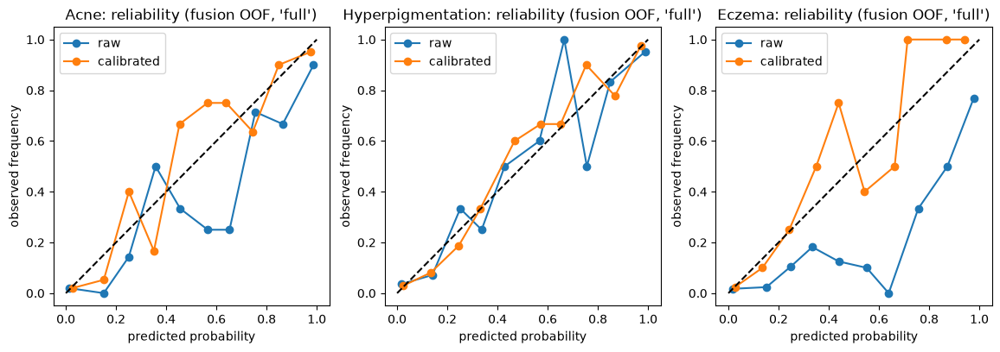

In [72]:
from scipy.optimize import minimize


def fit_platt(z, y, l2=1e-3):
    k = y >= 0; zz, yy = z[k].astype(float), y[k].astype(float)
    if (yy == 1).sum() < CFG.MIN_POS_FOR_METRIC or (yy == 0).sum() < CFG.MIN_POS_FOR_METRIC: return None
    def nll(p):
        a, b = p; s = a * zz + b
        return float(np.mean(np.logaddexp(0, s) - yy * s) + l2 * (a - 1) ** 2)
    r = minimize(nll, x0=np.array([1.0, 0.0]), method="L-BFGS-B")
    return dict(a=float(r.x[0]), b=float(r.x[1]))


def apply_platt(z, cal):
    out = np.zeros_like(z, dtype=np.float32)
    for j in range(z.shape[1]):
        c = cal[j]
        out[:, j] = 1 / (1 + np.exp(-(z[:, j] if c is None else c["a"] * z[:, j] + c["b"])))
    return out


def brier_ece(y, p, bins=None):
    bins = bins or CFG.CALIBRATION_BINS; rows = []
    for j, c in enumerate(CFG.CONDITIONS):
        k = y[:, j] >= 0; yy, pp = y[k, j], p[k, j]
        if len(yy) < 10: rows.append(dict(condition=c, n=len(yy), brier=np.nan, ece=np.nan)); continue
        rows.append(dict(condition=c, n=int(len(yy)), brier=float(np.mean((pp - yy) ** 2)), ece=float(ece_binary(pp, yy, bins)[0])))
    return pd.DataFrame(rows)


astra_require_action('calibration')
CALIB = {}
if FUSION_STATE.get("oof"):
    require_source_permission(["fusion"], "training")
    yf = FUSION_STATE["y"]; rows = []
    for var, z in FUSION_STATE["oof"].items():
        cal = [fit_platt(z[:, j], yf[:, j]) for j in range(CFG.N_COND)]
        pc = apply_platt(z, cal); praw = 1 / (1 + np.exp(-z))
        thr = []
        for j in range(CFG.N_COND):
            k = yf[:, j] >= 0
            thr.append(best_f1_threshold(yf[k, j], pc[k, j])[0] if ((yf[k, j] == 1).sum() >= CFG.MIN_POS_FOR_METRIC and (yf[k, j] == 0).sum() >= CFG.MIN_POS_FOR_METRIC) else 0.5)
        CALIB[var] = dict(platt=cal, thresholds=thr, calibrated_conditions=[c for c, x in zip(CFG.CONDITIONS, cal) if x is not None])
        b0, b1 = brier_ece(yf, praw), brier_ece(yf, pc)
        for c in CFG.CONDITIONS:
            rows.append(dict(variant=var, condition=c, brier_raw=float(b0.set_index("condition").brier[c]), brier_calibrated=float(b1.set_index("condition").brier[c]),
                             ece_raw=float(b0.set_index("condition").ece[c]), ece_calibrated=float(b1.set_index("condition").ece[c]), calibrated=cal[CFG.CONDITIONS.index(c)] is not None,
                             threshold=thr[CFG.CONDITIONS.index(c)]))
    CAL_TBL = pd.DataFrame(rows); display(CAL_TBL)
    write_csv(CAL_TBL, os.path.join(CFG.DIRS["metrics"], "fusion_calibration_oof.csv")); write_json(os.path.join(CFG.DIRS["fusion"], "calibration_thresholds.json"), CALIB)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
    for j, c in enumerate(CFG.CONDITIONS):
        k = yf[:, j] >= 0
        if k.sum() >= 30:
            for lab, p in [("raw", 1 / (1 + np.exp(-FUSION_STATE["oof"]["full"][:, j]))), ("calibrated", apply_platt(FUSION_STATE["oof"]["full"], CALIB["full"]["platt"])[:, j])]:
                _, rel = ece_binary(p[k], yf[k, j], CFG.CALIBRATION_BINS); ax[j].plot(rel.mean_conf, rel.accuracy, "o-", label=lab)
            ax[j].plot([0, 1], [0, 1], "k--"); ax[j].set_title(f"{c}: reliability (fusion OOF, 'full')"); ax[j].set_xlabel("predicted probability"); ax[j].set_ylabel("observed frequency"); ax[j].legend()
    savefig(fig, "fusion_oof_reliability")
else:
    print("Calibration/thresholds need the cross-fitted fusion logits (Section 30): not available yet.")

# Part VIII — Trustworthiness: Quality, OOD, Stage 1, Stage 2 (AI verification), Final Assessment, Abstention and the Dermatologist-Review Contract

Sections: **(32) Stage 1 · (33) Stage-1 reliability · (34) Stage 2 · (35) adaptive verification controller · (36) unified final result · (37) safe abstention · (38) OOD and input-quality evaluation.**

## Information flow
```
image ─▶ validity + quality gate ─▶ OOD score
      ─▶ STAGE 1: global CNN + 3 YOLO detectors ─▶ (fusion variant "global_yolo", no ROI) ─▶ calibrated per-condition probabilities
                  ├─ reliability rule (band selected on out-of-fold data): no conflict, no near-threshold, quality & OOD fine ─▶ AI-ACCEPT
                  └─ otherwise ─▶ STAGE 2 = AI VERIFICATION (not clinical validation): YOLO-guided ROI MobileNetV2 + full fusion ("full")
                                    └─ bounded AI verification passes; each pass must add NEW evidence
                                         pass 1: Tier-1 regions (deployed boxes)   pass 2: + Tier-2 candidates   pass 3: + Tier-3 alternative-context crops
                                         stop: resolved · converged · no new evidence · max passes · time budget · recapture needed
      ─▶ final structured AI assessment (conditions, scores, regions, provenance, stage, passes, stop reason) or an explicit abstention, SEALED (SHA-256)
      ─▶ status PENDING_DERMATOLOGIST_REVIEW for EVERY assessment (any state, any confidence, either stage); the dermatologist records findings in a SEPARATE record
```
**Rules that cannot be bypassed.** (1) Re-running the *same* tensor is never a verification action. (2) Probabilities after a pass come from **one fusion forward over the union of evidence** — they are not averaged or compounded, so repeated passes cannot inflate confidence. (3) Unstable decisions across passes ⇒ *uncertain*. (4) Any technical failure ⇒ `INFERENCE_ERROR`, a blocking quality problem ⇒ `RECAPTURE_REQUIRED`; neither is ever reported as Normal. (5) *Absence* is only "supported" when a working detector covers the condition (configurable) **and** the calibrated probability is clearly below its threshold.

**Provisional parameters.** The reliability bands are *selected on out-of-fold data* to meet `TARGET_ACCEPTED_ERROR`; the quality thresholds are heuristics. Neither is a validated clinical criterion; both are re-evaluated on the test split as an honest check and reported with their limitations.

In [73]:
# 32.1 Result object (ONE structure for the Results screen, overlays, patient record, dermatologist review, receipt and A4 report) and the state vocabulary.
#      EVERY assessment is issued as PENDING_DERMATOLOGIST_REVIEW, whatever its state, confidence, stage or findings, and is SEALED (SHA-256) at issue: the AI output is
#      immutable afterwards. The dermatologist's findings live in a SEPARATE record (next cell) that points at the AI assessment by its hash.
import copy
STATES = ["FINDINGS_SUPPORTED", "MULTIPLE_FINDINGS_SUPPORTED", "NO_FINDINGS_SUPPORTED", "UNCERTAIN_REVIEW_REQUIRED", "RECAPTURE_REQUIRED", "OUT_OF_SCOPE_REVIEW_REQUIRED", "INFERENCE_ERROR"]
# These states describe how well the AI EVIDENCE supports a result. They are not diagnoses and not clinical confirmation.
# NO_FINDINGS_SUPPORTED is an addition to the requested list: a *positively supported absence in the AI evidence* (never used for uncertainty or technical failure).
REVIEW_STATUS_PENDING = "PENDING_DERMATOLOGIST_REVIEW"
REVIEW_STATUSES = [REVIEW_STATUS_PENDING, "DERMATOLOGIST_REVIEW_IN_PROGRESS", "DERMATOLOGIST_REVIEW_COMPLETED", "DERMATOLOGIST_REVIEW_UNABLE_TO_ASSESS"]   # the first is the only status an AI assessment is ever issued with
CLINICAL_STATUS = "NOT_CLINICALLY_VALIDATED"
SCHEMA_VERSION = "lumyvue-final-assessment/1.1"
REVIEW_SCHEMA_VERSION = "lumyvue-dermatologist-review/1.0"
AI_VERIFICATION_STATEMENT = ("AI verification: additional automated models (YOLO-guided regions, ROI classifier, fusion) re-examined the image evidence. It is NOT clinical validation, "
                             "does not confirm a diagnosis, and does not replace dermatologist review, which is required for every assessment.")


def canonical_json(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), default=_json_default)


@dataclass
class FinalAssessment:
    scan_id: str
    state: str
    predicted_conditions: list = field(default_factory=list)
    condition_scores: dict = field(default_factory=dict)         # per condition: calibrated_probability, threshold, decision (present|absent|uncertain), absence_supported, evidence_state, ...
    regions: list = field(default_factory=list)                  # localisation regions associated with each condition (normalised coords) + ROI scores
    evidence_provenance: dict = field(default_factory=dict)
    detector_availability: dict = field(default_factory=dict)
    uncertainty: dict = field(default_factory=dict)
    stage_reached: int = 1
    verification_passes: int = 0
    stop_reason: str = ""
    model_versions: dict = field(default_factory=dict)
    fusion_config: dict = field(default_factory=dict)
    original_cnn_scores: dict = field(default_factory=dict)      # raw outputs of the global CNN(s), untouched
    original_yolo_outputs: dict = field(default_factory=dict)    # every box of the candidate pool, untouched
    intermediate_results: list = field(default_factory=list)
    quality: dict = field(default_factory=dict)
    ood: dict = field(default_factory=dict)
    recapture_advice: list = field(default_factory=list)
    review_status: str = REVIEW_STATUS_PENDING                   # status AT ISSUE; the live review status is read from the separate review record
    requires_dermatologist_review: bool = True                   # always True: there is no state, confidence or stage that waives review
    clinical_status: str = CLINICAL_STATUS
    ai_verification: dict = field(default_factory=dict)          # what the AI stages did; clinical_validation is always False
    state_meaning: str = "AI evidence assessment only: not a diagnosis and not a clinical confirmation."
    ai_content_sha256: str = ""                                  # SHA-256 of every other field, set by seal()
    schema_version: str = SCHEMA_VERSION
    created_utc: str = ""

    def __setattr__(self, key, value):
        if self.__dict__.get("_sealed", False):
            raise AttributeError(f"This AI assessment is sealed (immutable after issue); cannot set '{key}'. Issue a new assessment (new scan id) instead.")
        object.__setattr__(self, key, value)

    def to_dict(self):
        d = asdict(self)
        assert d["state"] in STATES, f"invalid state {d['state']}"
        assert d["review_status"] == REVIEW_STATUS_PENDING, "an AI assessment is always issued as PENDING_DERMATOLOGIST_REVIEW (the review status lives in the separate review record)"
        assert d["requires_dermatologist_review"] is True, "dermatologist review is required for every assessment"
        assert d["clinical_status"] == CLINICAL_STATUS, "an AI assessment is never clinically validated"
        assert d["ai_verification"].get("clinical_validation", False) is False, "AI verification is not clinical validation"
        return d

    def _hash(self):
        d = asdict(self); d.pop("ai_content_sha256", None)
        return hashlib.sha256(canonical_json(d).encode("utf-8")).hexdigest()

    def seal(self):
        self.to_dict()                                           # contract check first
        h = self._hash(); object.__setattr__(self, "ai_content_sha256", h); object.__setattr__(self, "_sealed", True)
        return self

    def verify_integrity(self):
        """True when no field (including nested dicts/lists) changed since seal()."""
        return bool(self.ai_content_sha256) and self._hash() == self.ai_content_sha256


def finalize_assessment(fa):
    """Last step of EVERY assessment path (success, abstention, technical failure): record what the AI stages did, mark them as not clinical, seal."""
    if fa.__dict__.get("_sealed", False): return fa
    fa.ai_verification = dict(performed_by="automated AI pipeline (no human involved)", stage_reached=fa.stage_reached, verification_passes=fa.verification_passes, stop_reason=fa.stop_reason,
                              clinical_validation=False, statement=AI_VERIFICATION_STATEMENT)
    return fa.seal()

## 32.2 Dermatologist review contract — AI output and clinical findings are SEPARATE records
* The **AI assessment** (`FinalAssessment`) is sealed at issue and is never edited — not after review, not after a second review, not to correct a mistake (a correction is a *new* assessment with a new scan id).
* The **dermatologist review** (`DermatologistReview`) is a different object with its own id, status, reviewer, timestamp, blinding flags and **per-condition findings** `present / absent / unknown` (blank = *unknown*, never *absent*). It points at the AI assessment by `scan_id` **and** `ai_content_sha256`, so it is always clear *which* AI output was reviewed; a review that does not match the hash is refused.
* `compose_case_record` joins the two **for display only** (deep copies); `agreement_*` functions compute agreement, disagreement and classification metrics between the AI's per-condition decisions and the **independently recorded** dermatologist findings. An AI *uncertain* decision is counted as uncertain — it is not forced into agreement or disagreement.
* Review status: the AI object always says `PENDING_DERMATOLOGIST_REVIEW` (status at issue); the review record carries `DERMATOLOGIST_REVIEW_IN_PROGRESS`, `DERMATOLOGIST_REVIEW_COMPLETED` or `DERMATOLOGIST_REVIEW_UNABLE_TO_ASSESS`.
* **Stage 2 is AI verification, not clinical validation.** Nothing in this notebook labels any AI output "validated", "confirmed" or "verified by a clinician".
* Reviews must **not** be used to retrain models automatically; to use them for training they must pass the same annotation protocol (blind, dermatologist, verified) and enter the *annotation file*, never the test split.

In [74]:
FINDING_VALUES = ("present", "absent", "unknown")
REVIEW_RECORD_STATUSES = REVIEW_STATUSES[1:]
REVIEW_COLS = ["review_id", "scan_id", "ai_content_sha256", "review_status", "reviewer_id", "reviewer_role", "blinded_to_ai", "ai_shown_before_review", "reviewed_at", "image_adequate",
               "acne", "hyperpigmentation", "eczema", "notes"]


@dataclass(frozen=True)
class DermatologistReview:
    review_id: str
    scan_id: str
    ai_content_sha256: str                     # the exact AI assessment that was reviewed
    review_status: str
    reviewer_id: str                           # pseudonymous code, never a name
    reviewer_role: str                         # must be 'dermatologist'
    reviewed_at_utc: str
    blinded_to_ai: object                      # True / False / None (not recorded)
    ai_shown_before_review: object             # True / False / None
    image_adequate: str                        # yes / no / unknown
    findings: dict                             # condition -> present | absent | unknown   (independent clinical findings)
    notes: str = ""
    schema_version: str = REVIEW_SCHEMA_VERSION

    def to_dict(self):
        return asdict(self)


def validate_review(r):
    require(r.review_status in REVIEW_RECORD_STATUSES, f"review_status must be one of {REVIEW_RECORD_STATUSES}; got '{r.review_status}'")
    require(r.reviewer_role == "dermatologist", f"only a dermatologist review is accepted as clinical ground truth (reviewer_role='{r.reviewer_role}')")
    require(bool(r.reviewer_id) and bool(r.review_id) and bool(r.scan_id), "review_id, scan_id and reviewer_id are required")
    require(isinstance(r.ai_content_sha256, str) and len(r.ai_content_sha256) == 64, "ai_content_sha256 (64 hex characters) is required: it identifies the AI assessment that was reviewed")
    require(set(r.findings) == set(CFG.CONDITIONS) and all(v in FINDING_VALUES for v in r.findings.values()), f"findings must give present|absent|unknown for exactly {CFG.CONDITIONS}; got {r.findings}")
    require(r.image_adequate in ("yes", "no", "unknown"), "image_adequate must be yes | no | unknown")
    if r.review_status == "DERMATOLOGIST_REVIEW_COMPLETED":
        require(isinstance(r.blinded_to_ai, bool) and isinstance(r.ai_shown_before_review, bool), "a COMPLETED review must record blinded_to_ai and ai_shown_before_review explicitly (true/false)")
        require(bool(r.reviewed_at_utc), "a COMPLETED review needs reviewed_at")
    return r


def _ai_checked(ai):
    """Returns a deep copy of a sealed AI assessment after verifying its hash (FinalAssessment or its dict)."""
    if isinstance(ai, FinalAssessment):
        require(ai.verify_integrity(), "AI assessment failed its integrity check (changed after seal?)")
        return ai.to_dict()
    d = copy.deepcopy(ai); h = d.get("ai_content_sha256"); d2 = dict(d); d2.pop("ai_content_sha256", None)
    require(bool(h) and hashlib.sha256(canonical_json(d2).encode("utf-8")).hexdigest() == h, "AI assessment dictionary does not match its sealed hash (modified after issue?)")
    return d


def compose_case_record(ai, review=None):
    """Display/exchange view: the sealed AI assessment (unchanged) next to the separate dermatologist review. Never modifies either."""
    a = _ai_checked(ai)
    if review is not None:
        validate_review(review)
        require(review.scan_id == a["scan_id"], "the review belongs to a different scan")
        require(review.ai_content_sha256 == a["ai_content_sha256"], "the review refers to a DIFFERENT version of the AI assessment; it was not made against this one")
    return dict(schema="lumyvue-case-record/1.0", ai_assessment=a, dermatologist_review=(review.to_dict() if review else None),
                review_status=(review.review_status if review else a["review_status"]), note="The AI assessment is sealed and is not changed by the review; the review is a separate record.")


# ---- agreement / disagreement / classification metrics vs the independently recorded dermatologist findings --------------------------------------
AI_CODE = {"present": 1, "absent": 0, "uncertain": 2, "none": -2}          # none = the AI produced no per-condition decision (recapture / out-of-scope / error)
DERM_CODE = {"present": 1, "absent": 0, "unknown": -1}


def agreement_core(ai, derm):
    """ai codes {1,0,2 uncertain,-2 no result}; derm codes {1,0,-1 unknown}. Agreement/disagreement is counted ONLY where both decided;
    AI-uncertain, AI-no-result and dermatologist-unknown are reported separately, never forced into agreement or disagreement."""
    ai = np.asarray(ai); derm = np.asarray(derm); kd = derm >= 0; both = kd & np.isin(ai, [0, 1])
    tp = int(((ai == 1) & (derm == 1) & both).sum()); fp = int(((ai == 1) & (derm == 0) & both).sum()); fn = int(((ai == 0) & (derm == 1) & both).sum()); tn = int(((ai == 0) & (derm == 0) & both).sum())
    n = int(both.sum()); po = (tp + tn) / n if n else np.nan
    pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / (n * n) if n else np.nan
    return dict(n_pairs=int(len(ai)), derm_unknown=int((~kd).sum()), ai_uncertain=int(((ai == 2) & kd).sum()), ai_no_result=int(((ai == -2) & kd).sum()), n_both_decided=n, agree=tp + tn, disagree=fp + fn,
                ai_present_derm_absent=fp, ai_absent_derm_present=fn, agreement=po, cohen_kappa=(po - pe) / (1 - pe) if n and pe == pe and pe < 1 else np.nan,
                ppv=tp / (tp + fp) if tp + fp else np.nan, sensitivity=tp / (tp + fn) if tp + fn else np.nan, specificity=tn / (tn + fp) if tn + fp else np.nan)


def agreement_table(ai_codes, derm_codes):
    """Per-condition table from arrays [N,3]. Also returns the all-conditions exact-agreement rate over images where every condition is decided on both sides."""
    ai_codes = np.asarray(ai_codes); derm_codes = np.asarray(derm_codes)
    t = pd.DataFrame([dict(condition=c, **agreement_core(ai_codes[:, j], derm_codes[:, j])) for j, c in enumerate(CFG.CONDITIONS)])
    allk = (derm_codes >= 0).all(1) & np.isin(ai_codes, [0, 1]).all(1)
    return t, dict(n_all_decided=int(allk.sum()), exact_agreement=float((ai_codes[allk] == derm_codes[allk]).all(1).mean()) if allk.any() else np.nan)


def cases_to_codes(cases, completed_only=True, blinded_only=False):
    ai, dm = [], []
    for c in cases:
        r = c["dermatologist_review"]
        if r is None or (completed_only and r["review_status"] != "DERMATOLOGIST_REVIEW_COMPLETED") or (blinded_only and r["blinded_to_ai"] is not True): continue
        cs = c["ai_assessment"].get("condition_scores", {})
        ai.append([AI_CODE[cs[k]["decision"]] if k in cs else AI_CODE["none"] for k in CFG.CONDITIONS]); dm.append([DERM_CODE[r["findings"][k]] for k in CFG.CONDITIONS])
    return np.array(ai).reshape(-1, CFG.N_COND), np.array(dm).reshape(-1, CFG.N_COND)


# ---- append-only store of sealed AI assessments + review loader -----------------------------------------------------------------------------------
SEALED_PATH = os.path.join(CFG.DIRS["predictions"], "sealed_assessments.jsonl")


def load_sealed_assessments(path=SEALED_PATH):
    out = {}
    if os.path.exists(path):
        for line in open(path, encoding="utf-8"):
            if line.strip():
                d = json.loads(line); _ai_checked(d); out[d["scan_id"]] = d                      # every record is re-verified on load
    return out


def store_sealed_assessment(fa, path=SEALED_PATH):
    """Append-only. The same scan_id can never be stored twice with different content."""
    require(isinstance(fa, FinalAssessment) and fa.verify_integrity(), "only sealed, intact assessments can be stored")
    old = load_sealed_assessments(path).get(fa.scan_id)
    if old is not None:
        require(old["ai_content_sha256"] == fa.ai_content_sha256, f"scan {fa.scan_id} already stored with different content: AI assessments are immutable; issue a new scan id")
        return path
    with open(safe_path(path), "a", encoding="utf-8") as f: f.write(canonical_json(fa.to_dict()) + "\n")
    return path


def load_dermatologist_reviews(path=None):
    path = path or CFG.DERM_REVIEW_CSV
    if not os.path.exists(path):
        write_csv(pd.DataFrame(columns=REVIEW_COLS), path); return []
    t = pd.read_csv(path, dtype=str).fillna("")
    require(all(c in t.columns for c in REVIEW_COLS), f"review file lacks columns {[c for c in REVIEW_COLS if c not in t.columns]}")
    tobool = lambda v: {"true": True, "yes": True, "false": False, "no": False}.get(v.strip().lower())
    out = [validate_review(DermatologistReview(review_id=r.review_id.strip(), scan_id=r.scan_id.strip(), ai_content_sha256=r.ai_content_sha256.strip().lower(), review_status=r.review_status.strip(),
                                               reviewer_id=r.reviewer_id.strip(), reviewer_role=r.reviewer_role.strip().lower(), reviewed_at_utc=r.reviewed_at.strip(),
                                               blinded_to_ai=tobool(r.blinded_to_ai), ai_shown_before_review=tobool(r.ai_shown_before_review), image_adequate=(r.image_adequate.strip().lower() or "unknown"),
                                               findings={c: (getattr(r, col).strip().lower() or "unknown") for c, col in zip(CFG.CONDITIONS, ["acne", "hyperpigmentation", "eczema"])}, notes=r.notes))
           for r in t.itertuples()]
    require(len({r.review_id for r in out}) == len(out), "duplicate review_id values in the review file")
    return out


REVIEWS = load_dermatologist_reviews()
SEALED = load_sealed_assessments()
if REVIEWS and SEALED:
    cases = [compose_case_record(SEALED[r.scan_id], r) for r in REVIEWS if r.scan_id in SEALED]
    for label, kw in [("all completed reviews", dict()), ("blinded reviews only", dict(blinded_only=True))]:
        a, d = cases_to_codes(cases, **kw)
        if len(a):
            t, ov = agreement_table(a, d); display(t.round(4)); write_csv(t, os.path.join(CFG.DIRS["metrics"], f"live_dermatologist_agreement_{label.split()[0]}.csv")); print(label, ov)
    print("Every AI assessment remains", REVIEW_STATUS_PENDING, "at issue; these tables use the separate review records.")
else:
    print(f"No dermatologist reviews with matching sealed AI assessments yet ({len(REVIEWS)} reviews, {len(SEALED)} stored assessments). Template: {redact(CFG.DERM_REVIEW_CSV)}.")
print("Review contract active: every AI assessment is issued as", REVIEW_STATUS_PENDING, "and sealed; dermatologist findings are recorded separately.")

No dermatologist reviews with matching sealed AI assessments yet (0 reviews, 0 stored assessments). Template: <PROJECT>/v6/annotations/dermatologist_reviews.csv.
Review contract active: every AI assessment is issued as PENDING_DERMATOLOGIST_REVIEW and sealed; dermatologist findings are recorded separately.


In [75]:
# 33.1 Input validity + quality screening. Never turns a technical problem into 'Normal'.
BLOCKING_QUALITY = ["low_resolution", "blur", "underexposed", "overexposed", "face_not_found_or_wrong_crop"]
ADVICE = {"low_resolution": "Move closer or use a higher-resolution camera setting.", "blur": "Hold still / refocus and retake the photograph.",
          "underexposed": "Increase the lighting evenly on the face.", "overexposed": "Reduce direct light and avoid reflections.",
          "uneven_lighting_or_shadow": "Light the face evenly; avoid strong side light and shadows.", "glare": "Avoid shiny reflections on the skin.",
          "white_balance_cast": "Use neutral white lighting.", "heavy_compression": "Use the original, uncompressed photograph.",
          "possible_text_or_watermark_overlay": "Use a photograph without text or watermarks.", "face_not_found_or_wrong_crop": "Face the camera with the whole face in the frame.",
          "face_detector_unavailable": "Face presence could not be checked (no face detector available)."}


def validate_input(bgr):
    """Returns (ok, reason). Invalid images raise INFERENCE_ERROR upstream - they are never silently scored."""
    if bgr is None: return False, "image could not be decoded"
    if not isinstance(bgr, np.ndarray) or bgr.ndim != 3 or bgr.shape[2] != 3: return False, f"image must be HxWx3 (got {getattr(bgr, 'shape', None)})"
    if bgr.dtype != np.uint8: return False, f"image must be 8-bit (got {bgr.dtype})"
    if min(bgr.shape[:2]) < 32: return False, f"image too small ({bgr.shape[:2]})"
    return True, ""


def assess_quality(bgr):
    q = image_quality_metrics(bgr, with_face=True); flags = quality_flags(q)
    blocking = [f for f in flags if f in BLOCKING_QUALITY]
    return dict(metrics={k: (None if (isinstance(v, float) and not np.isfinite(v)) else v) for k, v in q.items()}, flags=flags, blocking=blocking, advice=[ADVICE[f] for f in flags if f in ADVICE],
                note="heuristic thresholds (unvalidated); they recommend a re-capture and never certify clinical suitability")

In [76]:
# 38.1 OOD score: Mahalanobis distance of the global embedding to the training distribution (shrinkage covariance). Threshold = OOD_PERCENTILE of
#      out-of-sample IN-distribution (fusion-split) scores. A flag means 'unlike the training data' - it is NOT recognition of an unknown condition.
from sklearn.covariance import LedoitWolf


class OODModel:
    def __init__(self): self.mu = None; self.prec = None; self.threshold = None
    def fit(self, emb_train):
        lw = LedoitWolf().fit(emb_train.astype(np.float64)); self.mu = lw.location_; self.prec = lw.precision_; return self
    def score(self, emb):
        d = emb.astype(np.float64) - self.mu
        return np.sqrt(np.einsum("ij,jk,ik->i", d, self.prec, d))
    def set_threshold(self, in_dist_scores, pct): self.threshold = float(np.percentile(in_dist_scores, pct)); return self
    def save(self, path): np.savez_compressed(safe_path(path), mu=self.mu, prec=self.prec, thr=self.threshold)
    @classmethod
    def load(cls, path):
        z = np.load(path); m = cls(); m.mu, m.prec, m.threshold = z["mu"], z["prec"], float(z["thr"]); return m


OOD = None
try:
    gate("annotations_train"); gate("annotations_fusion"); require(GLOBAL_SELECTED[0], "no selected global model", gate=True)
    OOD_PATH = os.path.join(CFG.DIRS["stages"], "ood_model.npz")
    if os.path.exists(OOD_PATH):
        OOD = OODModel.load(OOD_PATH)
    else:
        tr_df = DF[(DF.split == "train") & DF.train_permitted].sample(frac=1.0, random_state=1).head(3000)
        OOD = OODModel().fit(global_scores_for(GLOBAL_SELECTED[0], GLOBAL_SELECTED[1], tr_df)["emb"])
        fus_df = FUSION_STATE["df"] if FUSION_STATE.get("df") is not None else DF[DF.split == "fusion"]
        OOD.set_threshold(OOD.score(global_scores_for(GLOBAL_SELECTED[0], GLOBAL_SELECTED[1], fus_df)["emb"]), CFG.OOD_PERCENTILE); OOD.save(OOD_PATH)
    print(f"OOD model ready; threshold (p{CFG.OOD_PERCENTILE:.0f} of in-distribution fusion-split scores) = {OOD.threshold:.2f}")
except (GateError, KeyError, AttributeError) as e:
    print("[OOD] not available yet:", str(e)[:160])

OOD model ready; threshold (p99 of in-distribution fusion-split scores) = 14.74


In [77]:
# 33.2 Stage-1 reliability rule: flags (conflict / near-threshold / quality / OOD) and a band selected on OUT-OF-FOLD fusion data to meet TARGET_ACCEPTED_ERROR.
def stage1_flags(pg, ps1, thr_g, thr_s1, avail, detected, qflags_blocking, qflags_all, ood_flag, band):
    flags, info = [], []
    for j, c in enumerate(CFG.CONDITIONS):
        if avail[j]:
            if (pg[j] >= thr_g[j]) != bool(detected[j]): flags.append(f"cnn_yolo_conflict_{c}")
        else:
            info.append(f"no_detector_{c}")                                          # restricts absence support; does not block a presence decision
        if abs(ps1[j] - thr_s1[j]) < band: flags.append(f"near_threshold_{c}")
    if ood_flag: flags.append("ood")
    flags += [f"quality_{f}" for f in qflags_blocking]
    warn = [f for f in qflags_all if f not in qflags_blocking and f != "face_detector_unavailable"]
    if warn: flags.append("quality_warning:" + ",".join(warn))
    return flags, info


def accepted_error(y, pred_present, accepted):
    """Fraction of accepted images with any KNOWN-condition mismatch."""
    k = accepted & (y >= 0).any(axis=1)
    if k.sum() == 0: return np.nan, 0
    mism = ((pred_present != (y == 1)) & (y >= 0)).any(axis=1)
    return float(mism[k].mean()), int(k.sum())


def select_band(p, thr, y, extra_ok, target, min_cov, grid=None):
    """Smallest margin band (largest coverage) whose accepted-case error <= target. Returns dict(band, coverage, error) or None."""
    grid = grid if grid is not None else np.round(np.arange(0.0, 0.46, 0.02), 2)
    pred = p >= np.asarray(thr)[None, :]; res = None
    for b in grid:
        acc = extra_ok & (np.abs(p - np.asarray(thr)[None, :]) >= b).all(axis=1)
        err, n = accepted_error(y, pred, acc)
        cov = acc.mean()
        if n >= 20 and err == err and err <= target and cov >= min_cov:
            res = dict(band=float(b), coverage=float(cov), error=float(err), n_accepted_known=n); break
    return res


astra_require_action('stage_rules')
STAGE1 = None
if CALIB.get("global_yolo") and CALIB.get("global_only") and FUSION_STATE.get("oof"):
    yf = FUSION_STATE["y"]; fdf = FUSION_STATE["df"]
    pg = apply_platt(FUSION_STATE["oof"]["global_only"], CALIB["global_only"]["platt"]); ps1 = apply_platt(FUSION_STATE["oof"]["global_yolo"], CALIB["global_yolo"]["platt"])
    thr_g, thr_s1 = CALIB["global_only"]["thresholds"], CALIB["global_yolo"]["thresholds"]
    ev = detector_evidence(fdf); avail = ev[:, :, 0] > 0.5; det = ev[:, :, 1] > 0.5
    conflict = np.array([[avail[i, j] and ((pg[i, j] >= thr_g[j]) != det[i, j]) for j in range(CFG.N_COND)] for i in range(len(fdf))]).any(axis=1)
    sel = select_band(ps1, thr_s1, yf, ~conflict, CFG.TARGET_ACCEPTED_ERROR, CFG.MIN_ACCEPT_COVERAGE)
    STAGE1 = dict(band=(sel or {}).get("band"), selection=sel, thr_global=thr_g, thr_stage1=thr_s1, target_error=CFG.TARGET_ACCEPTED_ERROR, min_coverage=CFG.MIN_ACCEPT_COVERAGE,
                  accepts_nothing=sel is None,
                  note="band selected on out-of-fold fusion-split data; PROVISIONAL, re-checked on the test split. If accepts_nothing=True every scan escalates to Stage 2.")
    write_json(os.path.join(CFG.DIRS["stages"], "stage1_rule.json"), STAGE1); print(json.dumps(STAGE1, indent=1, default=str))
else:
    print("Stage-1 rule needs the calibrated 'global_only' and 'global_yolo' fusion variants (Sections 30-31): not available yet.")

{
 "band": 0.0,
 "selection": {
  "band": 0.0,
  "coverage": 0.4083333333333333,
  "error": 0.05442176870748299,
  "n_accepted_known": 147
 },
 "thr_global": [
  0.51,
  0.39,
  0.25
 ],
 "thr_stage1": [
  0.42,
  0.37,
  0.27
 ],
 "target_error": 0.1,
 "min_coverage": 0.3,
 "accepts_nothing": false,
 "note": "band selected on out-of-fold fusion-split data; PROVISIONAL, re-checked on the test split. If accepts_nothing=True every scan escalates to Stage 2."
}


## 35. Bounded adaptive AI-verification controller
The controller is **pure logic** (no models inside), so it can be unit-tested with fake evidence and reused unchanged in the evaluation and in a future C# port. At each pass it asks an *evidence provider* for the next **new** evidence; it never re-scores the same evidence.

| Stop reason | Meaning |
|---|---|
| `resolved` | every condition is clearly above/below its threshold (margin ≥ band) and the decisions are stable |
| `converged` | the calibrated probabilities moved less than `CONVERGENCE_EPS` and decisions did not change, but the result is still uncertain → the extra evidence does not help |
| `no_new_evidence` | the provider offered fewer than `MIN_NEW_ROIS` genuinely new regions / crops (**redundancy detected — no re-inference**) |
| `max_passes` / `time_budget` | configured bounds reached |
| `recapture_needed` | the only remaining useful action is a new controlled capture |
| `unstable` | decisions flip between passes → treated as uncertain |

In [78]:
@dataclass
class VerifyCfg:
    max_passes: int = CFG.MAX_VERIFICATION_PASSES
    max_seconds: float = CFG.MAX_VERIFICATION_SECONDS
    min_new_rois: int = CFG.MIN_NEW_ROIS
    eps: float = CFG.CONVERGENCE_EPS


def verification_cycle(p0, thr, band, provider, vc=None, clock=time.monotonic):
    """p0: calibrated probabilities after Stage 2's first evidence (array of 3). provider(k, seen) -> dict(action, signatures:set, probs:array or None, recapture:bool) or None when no further action exists.
    Returns dict(passes=[...], probs, stop_reason, stable). Terminates after at most vc.max_passes provider calls (the pass-1 evidence counts as pass 1)."""
    vc = vc or VerifyCfg(); thr = np.asarray(thr, float); t0 = clock()
    seen = set(); passes = []; probs = np.asarray(p0, float)
    decision = lambda p: tuple((p >= thr).astype(int))
    certain = lambda p: bool((np.abs(p - thr) >= band).all())
    passes.append(dict(pass_no=1, action="stage2_initial_regions", new_signatures=None, probs=probs.round(5).tolist(), decision=decision(probs)))
    stop = None
    if certain(probs): stop = "resolved"
    k = 1
    while stop is None:
        if k >= vc.max_passes: stop = "max_passes"; break
        if clock() - t0 > vc.max_seconds: stop = "time_budget"; break
        k += 1
        ev = provider(k, set(seen))
        if ev is None: stop = "no_new_evidence"; break
        if ev.get("recapture"): stop = "recapture_needed"; passes.append(dict(pass_no=k, action=ev.get("action", "recapture"), new_signatures=0, probs=None, decision=None)); break
        new = set(ev["signatures"]) - seen
        if len(new) < vc.min_new_rois or ev.get("probs") is None: stop = "no_new_evidence"; break          # redundancy: do NOT score the same evidence again
        seen |= new
        newp = np.asarray(ev["probs"], float)
        passes.append(dict(pass_no=k, action=ev["action"], new_signatures=len(new), probs=newp.round(5).tolist(), decision=decision(newp)))
        moved = float(np.abs(newp - probs).max()); same = decision(newp) == decision(probs); probs = newp
        if certain(probs): stop = "resolved"
        elif same and moved < vc.eps: stop = "converged"
    flips = sum(passes[i]["decision"] != passes[i - 1]["decision"] for i in range(1, len(passes)) if passes[i]["decision"] is not None and passes[i - 1]["decision"] is not None)
    stable = flips < 2
    if not stable: stop = "unstable"
    return dict(passes=passes, probs=probs, stop_reason=stop, stable=stable, n_passes=len(passes))

In [79]:
# 36.1 Final decision logic: per-condition decisions + one overall state. Pure function (unit-tested).
def decide(probs, thr, band, avail, quality, ood_flag, flags, stable=True, error=None, require_all_detectors=None):
    """Returns dict(state, predicted, per_condition, reasons). probs/thr: arrays over CFG.CONDITIONS; avail: detector availability booleans."""
    require_all = CFG.ABSENCE_REQUIRES_ALL_DETECTORS if require_all_detectors is None else require_all_detectors
    if error: return dict(state="INFERENCE_ERROR", predicted=[], per_condition={}, reasons=[f"error: {error}"])
    if quality and quality.get("blocking"): return dict(state="RECAPTURE_REQUIRED", predicted=[], per_condition={}, reasons=[f"blocking quality: {quality['blocking']}"])
    if ood_flag: return dict(state="OUT_OF_SCOPE_REVIEW_REQUIRED", predicted=[], per_condition={}, reasons=["input unlike the training distribution (OOD)"])
    if band is None or not np.isfinite(band):
        return dict(state='UNCERTAIN_REVIEW_REQUIRED',predicted=[],
                    per_condition={c:dict(calibrated_probability=float(probs[j]),threshold=float(thr[j]),band=None,
                                          decision='uncertain',absence_supported=False,detector_available=bool(avail[j]))
                                   for j,c in enumerate(CFG.CONDITIONS)},reasons=['No eligible calibrated reliability band; supported decisions disabled'])
    per, predicted, uncertain, absent_ok = {}, [], [], []
    for j, c in enumerate(CFG.CONDITIONS):
        p, t = float(probs[j]), float(thr[j])
        if p >= t + band: dec = "present"
        elif p < t - band: dec = "absent"
        else: dec = "uncertain"
        supp = (dec == "absent") and (bool(avail[j]) or not require_all)
        per[c] = dict(calibrated_probability=round(p, 5), threshold=round(t, 4), band=round(float(band), 4), decision=dec, absence_supported=supp, detector_available=bool(avail[j]))
        if dec == "present": predicted.append(c)
        elif dec == "uncertain": uncertain.append(c)
        elif not supp: uncertain.append(c)                                              # 'absent' without detector coverage is not a supported absence
        else: absent_ok.append(c)
    reasons = []
    if uncertain: reasons.append(f"uncertain or unsupported-absence for: {uncertain}")
    if not stable: reasons.append("decisions were unstable across verification passes")
    if flags: reasons.append(f"unresolved flags: {flags}")
    if uncertain or not stable or flags:
        return dict(state="UNCERTAIN_REVIEW_REQUIRED", predicted=predicted, per_condition=per, reasons=reasons)
    if len(predicted) >= 2: return dict(state="MULTIPLE_FINDINGS_SUPPORTED", predicted=predicted, per_condition=per, reasons=[])
    if len(predicted) == 1: return dict(state="FINDINGS_SUPPORTED", predicted=predicted, per_condition=per, reasons=[])
    return dict(state="NO_FINDINGS_SUPPORTED", predicted=[], per_condition=per, reasons=[])


def flags_after_stage2(p_cnn_only, thr_g, avail, detected):
    """Conflicts that REMAIN as information after Stage 2 (they never block the fusion decision by themselves; they are reported)."""
    return [f"cnn_yolo_conflict_{c}" for j, c in enumerate(CFG.CONDITIONS) if avail[j] and ((p_cnn_only[j] >= thr_g[j]) != bool(detected[j]))]

## 32–36 (batch form). Stage logic on a whole split
The function below applies the **same** `stage1_flags` / `verification_cycle` / `decide` functions to pre-computed features of a split (global-only, Stage-1 and per-pass full-fusion logits, detector evidence, quality, OOD). It is used for the **fusion-split sanity check** now and for the **test split** in Part IX — one code path, so test results describe exactly the deployed logic. The live single-image reference implementation (`assess_image`, next section) calls the same three functions.

In [80]:
def batch_stage_logic(df, X_by_var, roi_tier_counts, calib, stage1, band2, quality_list, ood_scores, logits_fn):
    """df: rows; logits_fn(var, view_tier) -> logits [N,3] from the fusion models (or OOF logits for the fusion split).
    quality_list: list of assess_quality dicts (or None). Returns DataFrame with one row per image: state, predicted, passes, stop_reason, stage_reached, calibrated probabilities."""
    for var in ['global_only','global_yolo','full']:
        require(all(c is not None for c in calib[var]['platt']), 'Incomplete calibration: '+var, gate=True)
    N = len(df)
    pg = apply_platt(logits_fn("global_only", 3), calib["global_only"]["platt"]); ps1 = apply_platt(logits_fn("global_yolo", 3), calib["global_yolo"]["platt"])
    thr_g, thr_s1, thr_f = calib["global_only"]["thresholds"], calib["global_yolo"]["thresholds"], calib["full"]["thresholds"]
    ev = detector_evidence(df); avail = ev[:, :, 0] > 0.5; det = ev[:, :, 1] > 0.5
    rows = []
    for i in range(N):
        q = quality_list[i] if quality_list else dict(blocking=[], flags=[])
        ood_flag = bool(OOD is not None and ood_scores is not None and ood_scores[i] > OOD.threshold)
        try:
            s1_band = (stage1 or {}).get("band")
            flags, info = stage1_flags(pg[i], ps1[i], thr_g, thr_s1, avail[i], det[i], q["blocking"], q["flags"], ood_flag, s1_band if s1_band is not None else 1.0)
            accepted = (stage1 or {}).get("band") is not None and not flags and not q["blocking"] and not ood_flag
            if q["blocking"] or ood_flag:
                d = decide(ps1[i], thr_s1, 0.0, avail[i], q, ood_flag, flags); stage, passes, stop, final_p = 1, 0, "gate_before_inference", ps1[i]
            elif accepted:
                d = decide(ps1[i], thr_s1, stage1["band"], avail[i], q, ood_flag, []); stage, passes, stop, final_p = 1, 0, "stage1_accepted", ps1[i]
            else:
                views = {t: apply_platt(logits_fn("full", t), calib["full"]["platt"])[i] for t in (1, 2, 3)}
                counts = roi_tier_counts[i]       # number of ROIs available per tier (1,2,3)
                def provider(k, seen):
                    if counts.get(k, 0) == 0: return None
                    return dict(action={2: "add_tier2_candidate_regions", 3: "add_alternative_context_crops"}[k] if k in (2, 3) else "other",
                                signatures={f"t{k}_{n}" for n in range(counts[k])}, probs=views[k])
                vcres = verification_cycle(views[1], thr_f, band2, provider)
                d = decide(vcres["probs"], thr_f, band2, avail[i], q, ood_flag, [], stable=vcres["stable"])
                stage, passes, stop, final_p = 2, vcres["n_passes"], vcres["stop_reason"], vcres["probs"]
            rows.append(dict(image_id=df.image_id.iloc[i], state=d["state"], predicted="|".join(d["predicted"]), stage=stage, passes=passes, stop_reason=stop,
                             **{f"p_{c}": float(final_p[j]) for j, c in enumerate(CFG.CONDITIONS)}, **{f"dec_{c}": d["per_condition"].get(c, {}).get("decision", "none") for c in CFG.CONDITIONS},
                             flags="|".join(flags), reasons=" ; ".join(d["reasons"]), review_status=REVIEW_STATUS_PENDING, requires_dermatologist_review=True))
        except Exception as ex:                                  # never silently Normal
            rows.append(dict(image_id=df.image_id.iloc[i], state="INFERENCE_ERROR", predicted="", stage=0, passes=0, stop_reason=f"{type(ex).__name__}", reasons=str(ex)[:120],
                             **{f"p_{c}": float('nan') for c in CFG.CONDITIONS}, flags="",
                             **{f"dec_{c}": "none" for c in CFG.CONDITIONS}, review_status=REVIEW_STATUS_PENDING, requires_dermatologist_review=True))
    return pd.DataFrame(rows)


# Stage-2 band (selected like the Stage-1 band, on the FULL variant's out-of-fold probabilities after all passes)
BAND2 = None
if CALIB.get("full") and FUSION_STATE.get("oof"):
    pf = apply_platt(FUSION_STATE["oof"]["full"], CALIB["full"]["platt"])
    sel2 = select_band(pf, CALIB["full"]["thresholds"], FUSION_STATE["y"], np.ones(len(pf), bool), CFG.TARGET_ACCEPTED_ERROR, CFG.MIN_ACCEPT_COVERAGE)
    BAND2 = (sel2 or {}).get("band")
    write_json(os.path.join(CFG.DIRS["stages"], "stage2_rule.json"), dict(band=BAND2, selection=sel2, note="Stage-2 margin band selected on out-of-fold fusion data; None disables supported decisions and produces explicit abstention."))
    print("Stage-2 band:", BAND2, sel2)
    if BAND2 is None: BAND2 = float('inf')   # an infinite band can never be satisfied: every case stays UNCERTAIN rather than guessing

Stage-2 band: 0.14 {'band': 0.14, 'coverage': 0.8416666666666667, 'error': 0.09900990099009901, 'n_accepted_known': 303}


## 36–37. Live single-image reference implementation (`assess_image`) and abstention handling
`assess_image` runs the **complete pipeline on one image file**: validity → quality → OOD → global CNN → three YOLO detectors → ROI crops → fusion → stages → `FinalAssessment`. It is the *Python reference* that the future C# port must reproduce within numerical tolerance (Section 51). It needs every trained component; it raises a `GateError` (reported as `INFERENCE_ERROR` in the result) when one is missing, and **never** returns a Normal-looking result after a failure.

In [81]:
class InferenceBundle:
    """Everything needed for single-image inference. Loading verifies SHA-256 hashes of the original models against the start-of-run fingerprint."""
    def __init__(self):
        require(GLOBAL_SELECTED[0] and ROI_SELECTED_SEED is not None and CALIB.get("full") and STAGE1 is not None and OOD is not None, "trained components / calibration / stage rules are not all available yet", gate=True)
        ok, bad = verify_originals_unchanged(); require(ok, f"original model files changed: {bad}")
        gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
        self.gfm = embedding_model(gm); self.gmode = EXPERIMENTS[GLOBAL_SELECTED[0]]["mode"]; self.rfm = load_roi_feature_model()
        self.fus = {}
        for var in ("global_only", "global_yolo", "full"):
            self.fus[var] = [keras.models.load_model(os.path.join(CFG.DIRS["fusion"], var, f"final_seed{s}.keras"),
                             custom_objects={"MaskedBCE": MaskedBCE, "MaskedAttentionPool": MaskedAttentionPool, "ModalityDropout": ModalityDropout, "MaskFraction": MaskFraction}, compile=False) for s in CFG.SEEDS]
        self.versions = dict(global_model=GLOBAL_SELECTED, roi_seed=ROI_SELECTED_SEED, yolo_config_hash=YOLO_CONFIG_HASH, v5_onnx_sha256=V5_SHA,
                             yolo={c: [m.sha256 for m in sp.members] for c, sp in DETECTORS.items()}, schema=SCHEMA_VERSION)

    def global_forward(self, bgr):
        x = preprocess_global(bgr)[None]; emb, out = self.gfm.predict(x, verbose=0); out = np.asarray(out, np.float32)[0]
        if self.gmode == "multilabel3": sc, pn = 1 / (1 + np.exp(-out)), np.nan
        else: sc, pn = out[:3], float(out[3])
        return emb[0], sc, pn, out


def _assess_image_core(bundle, path_or_bgr, scan_id=None):
    t0 = time.monotonic(); bgr = cv2.imread(path_or_bgr) if isinstance(path_or_bgr, str) else path_or_bgr
    sid = scan_id or pseudo_id(path_or_bgr if isinstance(path_or_bgr, str) else str(time.time()), "scan")
    fa = FinalAssessment(scan_id=sid, state="INFERENCE_ERROR", created_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), model_versions=bundle.versions if bundle else {})
    try:
        for var in ['global_only','global_yolo','full']:
            require(all(c is not None for c in CALIB[var]['platt']), 'Incomplete calibration: '+var, gate=True)
        ok, why = validate_input(bgr)
        if not ok: fa.stop_reason = "invalid_input"; fa.uncertainty = dict(reasons=[why]); return fa
        q = assess_quality(bgr); fa.quality = q; fa.recapture_advice = q["advice"]
        emb, sc, pn, raw = bundle.global_forward(bgr); fa.original_cnn_scores = dict(model=GLOBAL_SELECTED, scores_per_condition=dict(zip(CFG.CONDITIONS, sc.round(6).tolist())), p_normal=None if pn != pn else pn, raw_output=raw.round(6).tolist())
        ood_score = float(OOD.score(emb[None])[0]); ood_flag = ood_score > OOD.threshold; fa.ood = dict(score=ood_score, threshold=OOD.threshold, flagged=bool(ood_flag), note="distance to the training distribution; not unknown-condition recognition")
        det = detect_all(bgr); fa.detector_availability = {c: det[c] is not None for c in CFG.CONDITIONS}
        fa.original_yolo_outputs = {c: (None if det[c] is None else det[c]["boxes"]) for c in CFG.CONDITIONS}
        H, W = bgr.shape[:2]; rows = [b for c in CFG.CONDITIONS if det[c] is not None for b in det[c]["boxes"]]
        # ---- features exactly as in training --------------------------------------------------------------------------------
        ev = np.zeros((1, CFG.N_COND, DET_EV_DIM), np.float32)
        for j, c in enumerate(CFG.CONDITIONS):
            if det[c] is None: continue
            dep = [b for b in det[c]["boxes"] if b["deployed"]]; best = max(dep, key=lambda b: b["conf"]) if dep else None
            ev[0, j] = [1.0, float(bool(dep)), best["conf"] if best else 0.0, max([b["conf"] for b in det[c]["boxes"]] + [0.0]), np.sqrt(best["rel_area"]) if best else 0.0, best["cx"] if best else 0.0, best["cy"] if best else 0.0]
        cands = build_roi_candidates(rows, W, H); crops, kept = [], []
        for c in cands:
            rgb, why2 = crop_roi(bgr, (c["x0"], c["y0"], c["x1"], c["y1"]), CFG.ROI_ALT_MARGIN if c["alt"] else CFG.ROI_MARGIN)
            if rgb is not None: crops.append(roi_norm(rgb)); kept.append(c)
        R = CFG.ROI_MAX_TOTAL; feat = np.zeros((1, R, ROI_FEAT_DIM), np.float32); mask = np.zeros((1, R), bool); tier = np.zeros((1, R), np.int8)
        if crops:
            remb, rpr = bundle.rfm.predict(np.stack(crops[:R]), verbose=0)
            for k, c in enumerate(kept[:R]):
                feat[0, k] = np.concatenate([remb[k], rpr[k], yolo_roi_features(c)]); mask[0, k] = True; tier[0, k] = c["tier"]
                fa.regions.append(dict(condition=c["condition"], tier=c["tier"], alt_context=c["alt"], detector_confidence=c["conf"], box_norm=[round(c["x0"] / W, 4), round(c["y0"] / H, 4), round(c["x1"] / W, 4), round(c["y1"] / H, 4)],
                                       roi_scores=dict(zip(CFG.ROI_CLASSES, rpr[k].round(4).tolist()))))
        g = dict(g_emb=emb[None].astype(np.float32), g_logit=logit(sc)[None], g_extra=np.array([[0.0 if pn != pn else pn, 0.0 if pn != pn else 1.0]], np.float32))
        def fwd(var, max_tier):
            v = VARIANTS[var]; m = mask & (tier <= max_tier) & bool(v["roi"]); f = feat * m[..., None]
            X = dict(g_emb=g["g_emb"] * v["global_"], g_logit=g["g_logit"] * v["global_"], g_extra=g["g_extra"] * v["global_"], det_ev=(ev * v["det"]).reshape(1, -1), roi_feat=f * (v["roi"] or 0), roi_mask=m.astype(np.float32))
            z = np.mean([mm.predict(x_list(X), verbose=0) for mm in bundle.fus[var]], axis=0)
            return apply_platt(z, CALIB[var]["platt"])[0]
        avail = np.array([det[c] is not None for c in CFG.CONDITIONS]); detected = ev[0, :, 1] > 0.5
        pg, ps1 = fwd("global_only", 3), fwd("global_yolo", 3)
        flags, info = stage1_flags(pg, ps1, CALIB["global_only"]["thresholds"], CALIB["global_yolo"]["thresholds"], avail, detected, q["blocking"], q["flags"], ood_flag, STAGE1["band"] if STAGE1["band"] is not None else 1.0)
        fa.uncertainty = dict(stage1_flags=flags, informational=info)
        fa.intermediate_results.append(dict(stage=1, probs=dict(zip(CFG.CONDITIONS, ps1.round(5).tolist())), cnn_only=dict(zip(CFG.CONDITIONS, pg.round(5).tolist()))))
        if q["blocking"] or ood_flag:
            d = decide(ps1, CALIB["global_yolo"]["thresholds"], 0.0, avail, q, ood_flag, flags); fa.stop_reason = "gate_before_inference"; final_p, thr = ps1, CALIB["global_yolo"]["thresholds"]
        elif STAGE1["band"] is not None and not flags:
            d = decide(ps1, CALIB["global_yolo"]["thresholds"], STAGE1["band"], avail, q, ood_flag, []); fa.stop_reason = "stage1_accepted"; final_p, thr = ps1, CALIB["global_yolo"]["thresholds"]
        else:
            fa.stage_reached = 2; thr = CALIB["full"]["thresholds"]; counts = {t: int(((tier[0] == t) & mask[0]).sum()) for t in (1, 2, 3)}
            def provider(k, seen):
                if counts.get(k, 0) == 0: return None
                return dict(action={2: "add_tier2_candidate_regions", 3: "add_alternative_context_crops"}.get(k, "other"), signatures={f"t{k}_{n}" for n in range(counts[k])}, probs=fwd("full", k))
            vres = verification_cycle(fwd("full", 1), thr, BAND2, provider)
            fa.verification_passes = vres["n_passes"]; fa.stop_reason = vres["stop_reason"]; fa.intermediate_results += vres["passes"]; final_p = vres["probs"]
            d = decide(final_p, thr, BAND2, avail, q, ood_flag, [], stable=vres["stable"])
        fa.state = d["state"]; fa.predicted_conditions = d["predicted"]; fa.condition_scores = d["per_condition"]
        fa.uncertainty["reasons"] = d["reasons"]
        fa.evidence_provenance = dict(global_model=GLOBAL_SELECTED, detectors={c: DETECTORS[c].version for c in CFG.CONDITIONS}, roi_model_seed=ROI_SELECTED_SEED, fusion_variants_used=["global_yolo"] + (["full"] if fa.stage_reached == 2 else []),
                                      latency_s=round(time.monotonic() - t0, 3))
        fa.fusion_config = dict(stage1_band=STAGE1["band"], stage2_band=(BAND2 if BAND2 is not None and np.isfinite(BAND2) else None), stage2_accepts_nothing=(BAND2 is None or not np.isfinite(BAND2)), thresholds=dict(zip(CFG.CONDITIONS, np.round(thr, 4).tolist())), max_passes=CFG.MAX_VERIFICATION_PASSES)
    except Exception as ex:                                                  # any failure => explicit error state, details logged, never Normal
        fa.state = "INFERENCE_ERROR"; fa.stop_reason = f"{type(ex).__name__}"; fa.uncertainty = dict(reasons=[str(ex)[:200]])
        log_event("inference_error", scan=sid, error=type(ex).__name__)
    return fa


def assess_image(bundle, path_or_bgr, scan_id=None):
    """Complete single-image reference pipeline. EVERY result - success, abstention or technical failure - is finalised the same way: marked as AI verification only
    (clinical_validation = False), issued as PENDING_DERMATOLOGIST_REVIEW and sealed (SHA-256). The caller can store it with store_sealed_assessment()."""
    return finalize_assessment(_assess_image_core(bundle, path_or_bgr, scan_id))


print("assess_image() defined. Single-image reference inference needs the trained components (it reports INFERENCE_ERROR, never Normal, when they are missing).")

assess_image() defined. Single-image reference inference needs the trained components (it reports INFERENCE_ERROR, never Normal, when they are missing).


# Part IX — Evaluation of Systems A–G on the Frozen Test Split, Ablations, Robustness and Visualisations

Sections: **(39) classification evaluation · (40) YOLO localisation evaluation · (41) fusion ablations · (42) robustness · (43) Grad-CAM++ · (44–48) learning curves, confusion matrices, PR/ROC, calibration, risk–coverage · (49) V5 vs V6.**

## The seven systems (all evaluated on the **same** test images with the **same** verified labels)
| | System | Decision rule |
|---|---|---|
| **A** | original V5 MobileNetV2 | arg-max of the 4-way softmax (Normal ⇒ no condition) — exactly what V5 does; threshold-free scores are used for AP/AUC |
| **B** | improved global MobileNetV2 | selected in Section 22; per-condition thresholds chosen on the **fusion** split |
| **C** | YOLO-only (three detectors) | `detected` at the deployed threshold; **Eczema (no detector) is "not evaluable", never counted as negative** |
| **D** | YOLO-guided ROI MobileNetV2 | fusion variant `roi_only`, calibrated, thresholds from fusion split |
| **E** | global CNN + YOLO evidence fusion | variant `global_yolo` |
| **F** | global + ROI CNN + three-detector fusion | variant `full` |
| **G** | full two-stage system with adaptive **AI** verification | Stage 1 → Stage 2 (AI verification, not clinical validation) → bounded verification → abstention; reported **on AI-accepted cases** *and* with abstentions listed |

**Test-set discipline.** The test split is opened **once**: a lock file records the first evaluation; a second run raises a `GateError` unless `ALLOW_TEST_REEVALUATION=True` (use only to reproduce a reported number). Nothing computed here feeds back into any model, threshold, calibration or band. Where a number cannot be computed (too few verified positives/negatives, missing labels, missing detector) the cell says so.

**Human review is never replaced.** "Accepted" means *accepted by the AI reliability rule*; it does not mean clinically confirmed. Every assessment of every system is issued as `PENDING_DERMATOLOGIST_REVIEW`. The test split's reference labels are dermatologist-verified annotations recorded **independently** of the AI, so the same agreement computation (Section 39.4) later applies to live reviews.

**Reading the metrics.** Per-condition metrics use only images where that condition's reference label is *Present/Absent* (Unknown excluded); exact-match uses fully-known images. 95 % intervals resample **leakage groups**. *Agreement with another model is not a correctness metric.* Selective-prediction results (system G) are reported with their coverage, so a lower error on accepted cases is never presented without the abstention rate.

In [82]:
# 39.1 Test lock + helpers for decision-based metrics (decisions may be NaN where a condition cannot be evaluated, e.g. Eczema for YOLO-only).
TEST_LOCK = os.path.join(CFG.DIRS["metrics"], "test_evaluated.lock.json")


def open_test_once():
    require_source_permission(["test"], "evaluation")
    if os.path.exists(TEST_LOCK) and not CFG.ALLOW_TEST_REEVALUATION:
        raise GateError(f"The test split was already evaluated ({json.load(open(TEST_LOCK))['when']}). Re-evaluating would let you tune against it. "
                        "Set LUMYVUE_ALLOW_TEST_REEVALUATION=true ONLY to reproduce a reported number.")
    write_json(TEST_LOCK, dict(evaluation_scope=ASTRA_EVALUATION_NOTE, when=datetime.datetime.now().isoformat(timespec="seconds"), run_id=CFG.RUN_ID, split_sha=json.load(open(SPLIT_FP_PATH))["sha256"], reeval_allowed=CFG.ALLOW_TEST_REEVALUATION))
    log_event("test_split_opened", reeval=CFG.ALLOW_TEST_REEVALUATION)


def metrics_dec(y, s, dec, min_pos=None):
    """Per-condition metrics from DECISIONS (1/0/NaN) and SCORES (may contain NaN). NaN decisions = not evaluable (excluded, reported as n_evaluable)."""
    min_pos = CFG.MIN_POS_FOR_METRIC if min_pos is None else min_pos; rows = []
    for j, c in enumerate(CFG.CONDITIONS):
        kn = y[:, j] >= 0; ok = kn & ~np.isnan(dec[:, j])
        yy, dd = y[ok, j], dec[ok, j] > 0.5
        tp = int((dd & (yy == 1)).sum()); fp = int((dd & (yy == 0)).sum()); fn = int((~dd & (yy == 1)).sum()); tn = int((~dd & (yy == 0)).sum())
        prec = tp / (tp + fp) if tp + fp else np.nan; rec = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
        f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
        ks = kn & ~np.isnan(s[:, j]); ys, ss = y[ks, j], s[ks, j]
        okc = ((ys == 1).sum() >= min_pos) and ((ys == 0).sum() >= min_pos)
        rows.append(dict(condition=c, n_evaluable=int(ok.sum()), pos=int((yy == 1).sum()), neg=int((yy == 0).sum()), precision=prec, recall=rec, specificity=spec, f1=f1, tp=tp, fp=fp, fn=fn, tn=tn,
                         ap=float(average_precision_score(ys, ss)) if okc else np.nan, roc_auc=float(roc_auc_score(ys, ss)) if okc else np.nan))
    return pd.DataFrame(rows)


def set_metrics_dec(y, dec):
    k = (y >= 0).all(axis=1) & ~np.isnan(dec).any(axis=1)
    if k.sum() == 0: return dict(n=0, micro_f1=np.nan, macro_f1=np.nan, hamming_loss=np.nan, exact_match=np.nan)
    yy, pp = y[k], (dec[k] > 0.5).astype(int)
    tp = ((pp == 1) & (yy == 1)).sum(); fp = ((pp == 1) & (yy == 0)).sum(); fn = ((pp == 0) & (yy == 1)).sum()
    f1s = [2 * ((pp[:, j] == 1) & (yy[:, j] == 1)).sum() / max(2 * ((pp[:, j] == 1) & (yy[:, j] == 1)).sum() + ((pp[:, j] == 1) & (yy[:, j] == 0)).sum() + ((pp[:, j] == 0) & (yy[:, j] == 1)).sum(), 1)
           for j in range(yy.shape[1]) if ((yy[:, j] == 1).any() or (pp[:, j] == 1).any())]
    return dict(n=int(k.sum()), micro_f1=float(2 * tp / max(2 * tp + fp + fn, 1)), macro_f1=float(np.mean(f1s)) if f1s else np.nan, hamming_loss=float((pp != yy).mean()), exact_match=float((pp == yy).all(axis=1).mean()))


def macro_f1_dec(y, dec):
    m = metrics_dec(y, np.full(dec.shape, np.nan), dec); return float(m.f1.mean()) if m.f1.notna().any() else np.nan


def v5_argmax_decisions(df):
    p = df[[f"v5_{c}" for c in CFG.V5_CLASS_ORDER]].to_numpy(); top = p.argmax(1); dec = np.zeros((len(df), 3))
    for i, t in enumerate(top):
        if t < 3: dec[i, t] = 1.0
    return dec


def combo_label(d):
    names = [c for c, v in zip(CFG.CONDITIONS, d) if v > 0.5]; return "none" if not names else "+".join(names)

## Astra development evaluation and derived Normal — researcher initiated
Fusion OOF results are development estimates: the same development labels select calibration and reliability rules. They are **not independent performance estimates**. Validation images also selected the CNN checkpoints. Stage comparisons below preserve abstentions and report corrected/introduced errors only on paired accepted, fully reviewed references.

In [83]:
def astra_normal_metrics(y,states):
    y=np.asarray(y);states=np.asarray(states)
    eligible=(y>=0).all(1);accepted=np.isin(states,['FINDINGS_SUPPORTED','MULTIPLE_FINDINGS_SUPPORTED','NO_FINDINGS_SUPPORTED'])
    truth=(y==0).all(1);pred=states=='NO_FINDINGS_SUPPORTED';k=eligible & accepted
    tp=int((k & truth & pred).sum());fp=int((k & ~truth & pred).sum());fn=int((k & truth & ~pred).sum());tn=int((k & ~truth & ~pred).sum())
    ratio=lambda a,b:float(a/b) if b else None
    return dict(reference_n=int(eligible.sum()),accepted_n=int(k.sum()),tp=tp,fp=fp,fn=fn,tn=tn,
        precision=ratio(tp,tp+fp),recall_accepted=ratio(tp,tp+fn),recall_all_references=ratio(tp,int((eligible & truth).sum())),
        specificity=ratio(tn,tn+fp),f1=ratio(2*tp,2*tp+fp+fn),false_normal=fp,missed_condition_called_normal=fp,
        incorrect_disease_on_normal=fn,uncertain_normal_candidates=int((eligible & truth & ~accepted).sum()),
        abstention_rate=ratio(int((eligible & ~accepted).sum()),int(eligible.sum())),confusion_matrix=[[tn,fp],[fn,tp]])


def astra_paired_stages(df,y,quality,ood_scores,logits_fn,final,prefix):
    ev=detector_evidence(df);pg=apply_platt(logits_fn('global_only',3),CALIB['global_only']['platt'])
    ps=apply_platt(logits_fn('global_yolo',3),CALIB['global_yolo']['platt']);thresholds=CALIB['global_yolo']['thresholds']
    states=[];dec=[]
    for i in range(len(df)):
        avail=ev[i,:,0]>0.5;det=ev[i,:,1]>0.5;q=quality[i]
        oo=bool(OOD is not None and ood_scores is not None and ood_scores[i]>OOD.threshold)
        band=STAGE1.get('band');flags,_=stage1_flags(pg[i],ps[i],CALIB['global_only']['thresholds'],thresholds,avail,det,q['blocking'],q['flags'],oo,band if band is not None else float('inf'))
        d=decide(ps[i],thresholds,band if band is not None else float('inf'),avail,q,oo,flags)
        states.append(d['state']);dec.append([int(c in d['predicted']) for c in CFG.CONDITIONS])
    before=np.array(dec);after=np.array([[int(c in str(p).split('|')) for c in CFG.CONDITIONS] for p in final.predicted])
    accepted=lambda s:np.isin(s,['FINDINGS_SUPPORTED','MULTIPLE_FINDINGS_SUPPORTED','NO_FINDINGS_SUPPORTED'])
    a1=accepted(states);a2=accepted(final.state.values);known=(y>=0).all(1);paired=known&a1&a2
    e1=(before!=y).any(1);e2=(after!=y).any(1)
    summary=dict(n=len(df),paired_accepted_reference_n=int(paired.sum()),stage2_triggered=int((final.stage==2).sum()),
        errors_corrected=int((paired&e1&~e2).sum()),errors_introduced=int((paired&~e1&e2).sum()),
        additional_cases_resolved_correct=int((known&~a1&a2&~e2).sum()),additional_cases_resolved_wrong=int((known&~a1&a2&e2).sum()),
        stage1_abstentions=int((~a1).sum()),final_abstentions=int((~a2).sum()),passes=final.passes.value_counts().to_dict(),
        stage1_normal=astra_normal_metrics(y,states),final_normal=astra_normal_metrics(y,final.state.values))
    records=pd.DataFrame(dict(image_id=df.image_id.values,stage1_state=states,final_state=final.state.values,
        fully_reviewed=known,stage1_wrong=e1,final_wrong=e2,paired_accepted=paired,passes=final.passes.values))
    write_csv(records,os.path.join(CFG.DIRS['metrics'],prefix+'_paired_stage_cases.csv'))
    write_json(os.path.join(CFG.DIRS['metrics'],prefix+'_paired_stages_normal.json'),summary)
    frames=[]
    for label,p,d,a in [('stage1',ps,before,a1),('final',final[[f'p_{c}' for c in CFG.CONDITIONS]].to_numpy(float),after,a2)]:
        frames.append(metrics_dec(y,p,np.where(a[:,None],d,np.nan)).assign(stage=label))
    write_csv(pd.concat(frames),os.path.join(CFG.DIRS['metrics'],prefix+'_stage_per_condition.csv'))
    fig,axs=plt.subplots(1,2,figsize=(9,4))
    for ax,key in zip(axs,['stage1_normal','final_normal']):
        cm=np.array(summary[key]['confusion_matrix']);ax.imshow(cm,cmap='Blues');ax.set_title(key+' (accepted only)')
        ax.set_xticks([0,1],['condition','no target']);ax.set_yticks([0,1],['condition','no target']);ax.set_xlabel('prediction');ax.set_ylabel('reviewed reference')
        for r in range(2):
            for c in range(2):ax.text(c,r,str(cm[r,c]),ha='center',va='center')
    savefig(fig,prefix+'_normal_confusion')
    return summary


def astra_development_evaluation():
    require_source_permission(['validation','fusion'],'training')
    gate('annotations_fusion');require(FUSION_STATE.get('oof') and STAGE1 is not None and OOD is not None,'Complete models, calibration and stage rules required',gate=True)
    df=FUSION_STATE['df'];y=FUSION_STATE['y'];sets=FUSION_STATE['roi_sets']
    def logits(var,t):return FUSION_STATE['oof_views'][var].get(t,FUSION_STATE['oof'][var])
    q=[assess_quality(cv2.imread(r.orig_path if r.has_orig else r.proc_path)) for r in df.itertuples()]
    oo=OOD.score(global_inputs(df)['emb'])
    counts=[{t:int(((sets['tier'][i]==t)&sets['mask'][i]).sum()) for t in (1,2,3)} for i in range(len(df))]
    start=time.perf_counter();final=batch_stage_logic(df,None,counts,CALIB,STAGE1,BAND2,q,oo,logits);elapsed=time.perf_counter()-start
    summary=astra_paired_stages(df,y,q,oo,logits,final,'development_oof')
    summary['cached_batch_decision_seconds']=elapsed
    summary['runtime_scope']='Decision logic on precomputed evidence; not end-to-end latency or Stage 2 acquisition overhead.'
    write_json(os.path.join(CFG.DIRS['metrics'],'development_oof_summary.json'),summary)
    for var,z in FUSION_STATE['oof'].items():
        p=apply_platt(z,CALIB[var]['platt']);d=(p>=CALIB[var]['thresholds']).astype(float)
        write_csv(metrics_dec(y,p,d),os.path.join(CFG.DIRS['metrics'],f'development_{var}_per_condition.csv'))
        write_json(os.path.join(CFG.DIRS['metrics'],f'development_{var}_multilabel.json'),set_metrics_dec(y,d))
    display(summary)

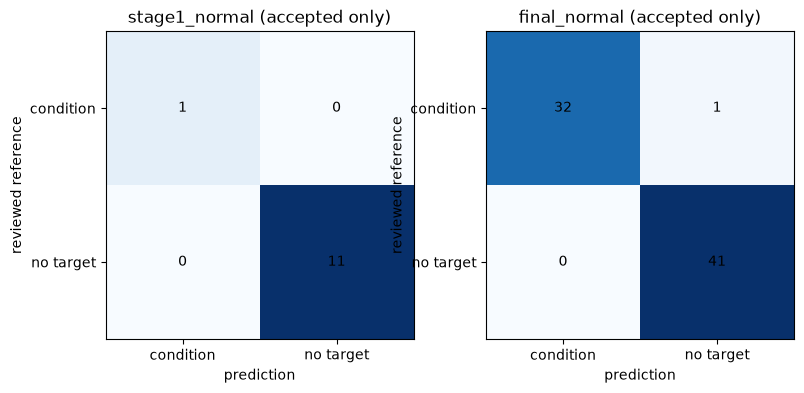

{'n': 360,
 'paired_accepted_reference_n': 12,
 'stage2_triggered': 67,
 'errors_corrected': 0,
 'errors_introduced': 0,
 'additional_cases_resolved_correct': 57,
 'additional_cases_resolved_wrong': 5,
 'stage1_abstentions': 348,
 'final_abstentions': 286,
 'passes': {0: 293, 1: 60, 2: 5, 3: 2},
 'stage1_normal': {'reference_n': 347,
  'accepted_n': 12,
  'tp': 11,
  'fp': 0,
  'fn': 0,
  'tn': 1,
  'precision': 1.0,
  'recall_accepted': 1.0,
  'recall_all_references': 0.10891089108910891,
  'specificity': 1.0,
  'f1': 1.0,
  'false_normal': 0,
  'missed_condition_called_normal': 0,
  'incorrect_disease_on_normal': 0,
  'uncertain_normal_candidates': 90,
  'abstention_rate': 0.9654178674351584,
  'confusion_matrix': [[1, 0], [0, 11]]},
 'final_normal': {'reference_n': 347,
  'accepted_n': 74,
  'tp': 41,
  'fp': 1,
  'fn': 0,
  'tn': 32,
  'precision': 0.9761904761904762,
  'recall_accepted': 1.0,
  'recall_all_references': 0.40594059405940597,
  'specificity': 0.9696969696969697,
  'f

In [84]:
astra_require_action('development_evaluation')
astra_development_evaluation()

## Astra runtime profiling — optional researcher-controlled validation images
Call `astra_profile_runtime(path)` on an eligible development image. It times actual model forwards and reports wall-clock overhead separately. It does not alter thresholds. The reference computes ROI evidence before deciding whether Stage 2 is needed, so current ROI precomputation is part of initial latency.

In [85]:
def astra_profile_runtime(path):
    require_source_permission(['validation'],'training')
    allowed=DF[DF.split=='validation']
    require(path in set(allowed.proc_path)|set(allowed.orig_path),'Use a validation image only',gate=True)
    bundle=InferenceBundle()
    timings={}
    class TimedPredict:
        def __init__(self,model,label):self.model,self.label=model,label
        def predict(self,*args,**kwargs):
            t=time.perf_counter()
            try:return self.model.predict(*args,**kwargs)
            finally:timings[self.label]=timings.get(self.label,0.0)+time.perf_counter()-t
    bundle.gfm=TimedPredict(bundle.gfm,'global_cnn')
    bundle.rfm=TimedPredict(bundle.rfm,'roi_precomputation')
    for var,models in bundle.fus.items():bundle.fus[var]=[TimedPredict(m,'fusion_'+var) for m in models]
    start=time.perf_counter();result=assess_image(bundle,path);elapsed=time.perf_counter()-start
    out=dict(wall_seconds=elapsed,state=result.state,stage=result.stage_reached,passes=result.verification_passes,
        model_forward_seconds=timings,additional_stage2_fusion_seconds=timings.get('fusion_full',0.0),
        scope='Full reference with eager ROI precomputation; additional_stage2_fusion_seconds excludes already paid ROI and detector costs',assessment=asdict(result))
    write_json(os.path.join(CFG.DIRS['metrics'],'development_runtime_'+pseudo_id(path)+'.json'),out)
    return out

## Astra ROI validation report — development data, researcher initiated
Four-class region performance is separate from the three-condition image outcome. These references selected the ROI checkpoint; this is a development report, not independent evaluation.

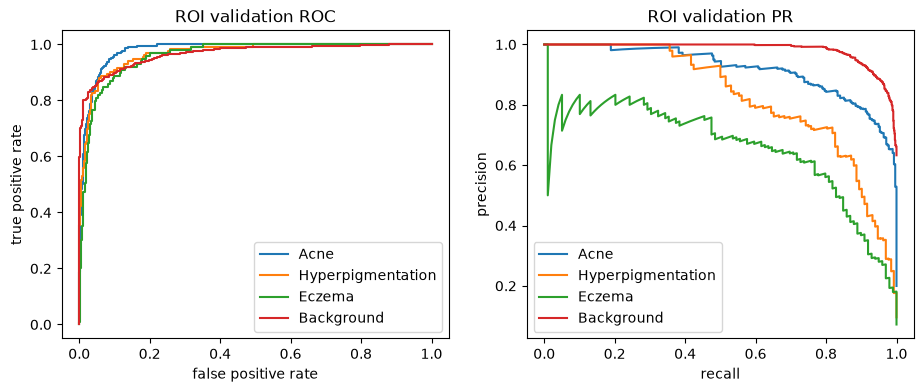

,region_class,support,precision,recall,specificity,f1,roc_auc,pr_auc,brier
0,Acne,275,0.752212,0.927273,0.923844,0.830619,0.979649,0.919322,0.050320
1,Hyperpigmentation,132,0.619565,0.863636,0.943820,0.721519,0.968286,0.827499,0.046573
2,Eczema,99,0.578947,0.777778,0.956216,0.663793,0.959793,0.661311,0.044466
3,Background,872,0.986150,0.816514,0.980237,0.893350,0.966748,0.982493,0.102798


In [86]:
def astra_roi_validation():
    from sklearn.metrics import confusion_matrix,precision_recall_fscore_support,roc_curve,precision_recall_curve
    require_source_permission(['validation'],'training');gate('regions_validation')
    require(ROI_SELECTED_SEED is not None,'Selected ROI model required',gate=True)
    table=ROI_TABLES['validation'];y=table.label.to_numpy()
    model=keras.models.load_model(os.path.join(CFG.DIRS['checkpoints'],'ROI',f'seed_{ROI_SELECTED_SEED}','final_best.keras'),compile=False)
    ds=make_roi_ds(table.path.values,y,None,False)
    p=model.predict(ds.map(lambda x,y,w:x),verbose=0);pred=p.argmax(1)
    cm=confusion_matrix(y,pred,labels=range(4));pr,rc,f1,support=precision_recall_fscore_support(y,pred,labels=range(4),zero_division=0)
    rows=[];fig,axs=plt.subplots(1,2,figsize=(11,4))
    for j,c in enumerate(CFG.ROI_CLASSES):
        truth=y==j;tp=cm[j,j];fn=cm[j].sum()-tp;fp=cm[:,j].sum()-tp;tn=cm.sum()-tp-fn-fp
        valid=truth.any() and (~truth).any()
        rows.append(dict(region_class=c,support=int(support[j]),precision=pr[j],recall=rc[j],specificity=float(tn/(tn+fp)) if tn+fp else None,f1=f1[j],
            roc_auc=float(roc_auc_score(truth,p[:,j])) if valid else None,pr_auc=float(average_precision_score(truth,p[:,j])) if valid else None,brier=float(np.mean((p[:,j]-truth)**2))))
        if valid:
            x,t,_=roc_curve(truth,p[:,j]);axs[0].plot(x,t,label=c)
            pp,rr,_=precision_recall_curve(truth,p[:,j]);axs[1].plot(rr,pp,label=c)
    axs[0].set(xlabel='false positive rate',ylabel='true positive rate',title='ROI validation ROC')
    axs[1].set(xlabel='recall',ylabel='precision',title='ROI validation PR')
    for ax in axs:ax.legend()
    savefig(fig,'roi_validation_curves');write_csv(pd.DataFrame(rows),os.path.join(CFG.DIRS['metrics'],'roi_validation_per_class.csv'))
    write_json(os.path.join(CFG.DIRS['metrics'],'roi_validation_summary.json'),dict(confusion_matrix=cm.tolist(),accuracy=float((pred==y).mean()),macro_f1=float(np.mean(f1)),loss=float(-np.log(np.clip(p[np.arange(len(y)),y],1e-7,1)).mean())))
    return pd.DataFrame(rows)

astra_require_action('roi_validation')
display(astra_roi_validation())

## Overnight run: everything before the locked test has finished
If you read this heading with a printed summary below it, the pre-test pipeline ran to the end (Global D and E, YOLO evidence, ROI, fusion, calibration, stage rules and the development reports). The next cell is the **locked test**, which is switched off on purpose (`OPEN_ALLOW_FINAL_TEST = False`), so Run All stops there with a GateError. That error is the expected end of an overnight run, not a failure.

In [87]:
# Overnight status: records what the run produced before the locked test. Reads only; trains nothing.
_status = dict(finished_at=datetime.datetime.now().isoformat(timespec="seconds"), run_id=CFG.RUN_ID, global_selected=list(GLOBAL_SELECTED) if GLOBAL_SELECTED else None,
               roi_selected_seed=ROI_SELECTED_SEED if "ROI_SELECTED_SEED" in globals() else None)
for _k, _expr in (("fusion_oof_ready", "bool(FUSION_STATE.get('oof'))"), ("calibration_ready", "bool(CALIB.get('full'))"), ("stage1_ready", "STAGE1 is not None"), ("ood_ready", "OOD is not None")):
    try: _status[_k] = bool(eval(_expr))
    except Exception as _e: _status[_k] = "not available: " + type(_e).__name__
_status["gates"] = {k: v["ok"] for k, v in GATES.items()}
write_json(os.path.join(CFG.DIRS["metrics"], "overnight_status.json"), _status)
print(json.dumps(_status, indent=1, default=str))
print("PRE-TEST PIPELINE COMPLETE. The next cell opens the locked test and is switched off: stopping there is expected.")


{
 "finished_at": "2026-11-02T16:38:51",
 "run_id": "open_run02",
 "global_selected": [
  "E_v5_backbone_multilabel3",
  42
 ],
 "roi_selected_seed": 42,
 "fusion_oof_ready": true,
 "calibration_ready": true,
 "stage1_ready": true,
 "ood_ready": true,
 "gates": {
  "provenance_defined": true,
  "annotations_train": true,
  "annotations_validation": true,
  "annotations_fusion": true,
  "annotations_test": false,
  "regions_train": true,
  "regions_validation": true,
  "regions_fusion": false,
  "regions_test": false,
  "yolo_all_three": true,
  "yolo_any": true,
  "roi_training_data": true
 }
}
PRE-TEST PIPELINE COMPLETE. The next cell opens the locked test and is switched off: stopping there is expected.


## 39. Classification evaluation (opens the test split once)
This is the **single** evaluation of the test split. If a prerequisite is missing, the cell stops without opening the test split (no lock file is written).

In [88]:
astra_require_action('final_test')
require(bool(ASTRA_EVALUATION_NOTE.strip()), 'Record adviser-approved evaluation scope/limitations before opening test', gate=True)
TEST = {}
try:
    for g in ["annotations_test", "annotations_fusion", "yolo_any"]: gate(g)
    require(GLOBAL_SELECTED[0] and ROI_SELECTED_SEED is not None and CALIB.get("full") and FUSION_STATE.get("oof"), "trained global/ROI/fusion components and calibration are required before the test split may be opened", gate=True)
    require(all(all(c is not None for c in CALIB[var]['platt']) for var in FUSION_RUN), 'Every evaluated fusion variant requires complete calibration', gate=True)
    require_source_permission(['test'],'evaluation')
    # Test baseline inference happens only inside this researcher-authorized cell.
    _testmask = DF.split == 'test'
    _vp = v5_probs_for(DF[_testmask])
    for _j,_c in enumerate(CFG.V5_CLASS_ORDER): DF.loc[_testmask,f'v5_{_c}'] = _vp[:,_j]
    run_yolo_cache(list(DF[_testmask & DF.eval_ok].image_id))
    astra_refresh_detector_tables()
    # build every test input BEFORE opening the lock, so a missing prerequisite never burns the single evaluation
    tdf, tsets = cached_roi_sets("test"); tdf = tdf.reset_index(drop=True)
    _b = DF.set_index("image_id").loc[tdf.image_id]; yt = _b[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy().copy(); yt[~_b.eval_ok.values] = -1
    gt = tdf.group_id.values
    require((yt >= 0).all(axis=1).sum() >= CFG.MIN_VERIFIED["test"], f"test split has fewer than {CFG.MIN_VERIFIED['test']} fully verified images", gate=True)
    LOGITS = {}
    for var in FUSION_RUN:
        for t in ((1, 2, 3) if VARIANTS[var]["roi"] else (3,)):
            X, _ = assemble(tdf, tsets, var, max_tier=t); LOGITS[(var, t)] = fusion_predict(X, var)
    logits_fn_test = lambda var, t: LOGITS[(var, t if VARIANTS[var]["roi"] else 3)]
    gtest = global_inputs(tdf); ffd = FUSION_STATE["df"]; gfus = global_inputs(ffd)
    evt = detector_evidence(tdf); detected_t = evt[:, :, 1] > 0.5; avail_t = evt[:, :, 0] > 0.5
    TEST = dict(df=tdf, y=yt, groups=gt)
    # thresholds for A2/B come from the FUSION split only
    yfus = FUSION_STATE["y"]; v5f = v5_scores(ffd)
    thr_B = [best_f1_threshold(yfus[yfus[:, j] >= 0, j], gfus["scores"][yfus[:, j] >= 0, j])[0] if ((yfus[:, j] == 1).sum() >= CFG.MIN_POS_FOR_METRIC) else 0.5 for j in range(3)]
    thr_A2 = [best_f1_threshold(yfus[yfus[:, j] >= 0, j], v5f[yfus[:, j] >= 0, j])[0] if ((yfus[:, j] == 1).sum() >= CFG.MIN_POS_FOR_METRIC) else 0.5 for j in range(3)]
    S = {}
    S["A_v5_argmax"] = dict(s=v5_scores(tdf), dec=v5_argmax_decisions(tdf))
    S["A2_v5_thresholded"] = dict(s=v5_scores(tdf), dec=(v5_scores(tdf) >= np.array(thr_A2)).astype(float))
    S["B_improved_global"] = dict(s=gtest["scores"], dec=(gtest["scores"] >= np.array(thr_B)).astype(float))
    ysc = np.where(avail_t, np.maximum(evt[:, :, 2], 0.0), np.nan)                      # YOLO score = max deployed confidence (0 if none); NaN when no detector
    ydec = np.where(avail_t, detected_t.astype(float), np.nan)
    S["C_yolo_only"] = dict(s=np.where(avail_t, np.maximum(evt[:, :, 3], evt[:, :, 2]), np.nan), dec=ydec)
    for name, var in [("D_roi_only", "roi_only"), ("E_global_plus_yolo", "global_yolo"), ("F_full_fusion", "full"), ("X_global_recalibrated", "global_only")]:
        p = apply_platt(logits_fn_test(var, 3), CALIB[var]["platt"]); S[name] = dict(s=p, dec=(p >= np.array(CALIB[var]["thresholds"])).astype(float), thr=CALIB[var]["thresholds"])
    # system G: two-stage logic with abstention
    qlist = [assess_quality(cv2.imread(r.orig_path if r.has_orig else r.proc_path)) for r in tdf.itertuples()]
    ood_t = OOD.score(gtest["emb"]) if OOD is not None else None
    tier_counts = [{t: int(((tsets["tier"][i] == t) & tsets["mask"][i]).sum()) for t in (1, 2, 3)} for i in range(len(tdf))]
    GRES = batch_stage_logic(tdf, None, tier_counts, CALIB, STAGE1, BAND2, qlist, ood_t, logits_fn_test)
    gd = np.array([[1.0 if c in str(p).split("|") else 0.0 for c in CFG.CONDITIONS] for p in GRES.predicted])
    accepted = GRES.state.isin(["FINDINGS_SUPPORTED", "MULTIPLE_FINDINGS_SUPPORTED", "NO_FINDINGS_SUPPORTED"]).values
    pF = GRES[[f"p_{c}" for c in CFG.CONDITIONS]].to_numpy(float)
    S["G_two_stage_accepted_only"] = dict(s=np.where(accepted[:, None], pF, np.nan), dec=np.where(accepted[:, None], gd, np.nan))
    TEST.update(S=S, GRES=GRES, accepted=accepted, qlist=qlist, tsets=tsets, thr_B=thr_B, thr_A2=thr_A2, avail=avail_t, detected=detected_t, ood=ood_t)
    # ---- per-system tables + cluster bootstrap CIs. Predictions above used NO test labels; the lock is taken here, right before the first metric is computed ----
    open_test_once()
    rows, setrows, cis = [], [], []
    for name, d in S.items():
        m = metrics_dec(yt, d["s"], d["dec"]); m.insert(0, "system", name); rows.append(m)
        sm = set_metrics_dec(yt, d["dec"]); sm["system"] = name; setrows.append(sm)
        lo, hi, nv = cluster_bootstrap(gt, lambda idx, d=d: macro_f1_dec(yt[idx], d["dec"][idx]))
        cis.append(dict(system=name, macro_f1=macro_f1_dec(yt, d["dec"]), ci_lo=lo, ci_hi=hi, n_boot_valid=nv))
    PERCOND = pd.concat(rows, ignore_index=True); SETM = pd.DataFrame(setrows).set_index("system"); CI = pd.DataFrame(cis).set_index("system")
    display(PERCOND.round(4)); display(SETM.round(4)); display(CI.round(4))
    write_csv(PERCOND, os.path.join(CFG.DIRS["metrics"], "test_per_condition_by_system.csv")); write_csv(SETM.reset_index(), os.path.join(CFG.DIRS["metrics"], "test_set_metrics_by_system.csv"))
    write_csv(CI.reset_index(), os.path.join(CFG.DIRS["metrics"], "test_macro_f1_ci_by_system.csv"))
    np.savez_compressed(safe_path(os.path.join(CFG.DIRS["predictions"], "test_system_scores.npz")), image_id=tdf.image_id.values.astype(str), y=yt, **{f"{k}__s": v["s"] for k, v in S.items()}, **{f"{k}__d": v["dec"] for k, v in S.items()})
    write_csv(GRES, os.path.join(CFG.DIRS["predictions"], "test_final_assessments_batch.csv"))
    astra_paired_stages(tdf,yt,qlist,ood_t,logits_fn_test,GRES,'test')
    log_event("test_evaluated", n=len(tdf), systems=list(S))
except GateError as g:
    print(f"[test evaluation] NOT RUN - {g}")

Not run (by design): Locked test evaluation is off: set OPEN_ALLOW_FINAL_TEST = True in a separate cell only when the evaluation cohort is ready.
The locked test split has no verified labels (0 of 1,468), so the final test evaluation was not opened in run02.


In [89]:
# 39.2 Paired comparisons (cluster bootstrap of the macro-F1 difference): is F better than A, B, C, E; is G's accepted-case behaviour different from F?
if TEST:
    def paired(a, b):
        S = TEST["S"]; yt, gt = TEST["y"], TEST["groups"]
        lo, hi, nv = cluster_bootstrap(gt, lambda idx: macro_f1_dec(yt[idx], S[a]["dec"][idx]) - macro_f1_dec(yt[idx], S[b]["dec"][idx]))
        return dict(system_1=a, system_2=b, macro_f1_difference=macro_f1_dec(yt, S[a]["dec"]) - macro_f1_dec(yt, S[b]["dec"]), ci_lo=lo, ci_hi=hi, interval_excludes_zero=bool(lo == lo and (lo > 0 or hi < 0)))
    PAIRED = pd.DataFrame([paired("F_full_fusion", x) for x in ["A_v5_argmax", "A2_v5_thresholded", "B_improved_global", "E_global_plus_yolo", "D_roi_only"]] + [paired("E_global_plus_yolo", "B_improved_global"), paired("B_improved_global", "A2_v5_thresholded")])
    display(PAIRED.round(4)); write_csv(PAIRED, os.path.join(CFG.DIRS["metrics"], "test_paired_differences.csv"))
    print("An interval that includes 0 means the data do not show a difference; it does NOT show equivalence. Yolo-only (C) is excluded from paired tests because Eczema is not evaluable for it.")

Not run (by design): this cell needs the locked test evaluation above, which was not opened in run02. The development and fair-set evaluations are in Part XI and Part XII.


In [90]:
# 39.3 Single / mixed / none subsets, misclassification pairs (Normal vs Hyperpigmentation, Hyperpigmentation vs Eczema, Acne vs Eczema), mixed combinations, camera vs source.
if TEST:
    S, yt, tdf = TEST["S"], TEST["y"], TEST["df"]; full = (yt >= 0).all(axis=1); npres = (yt == 1).sum(1)
    sub_rows = []
    for name, d in S.items():
        for label, m in [("none (Normal)", full & (npres == 0)), ("single condition", full & (npres == 1)), ("mixed (>=2)", full & (npres >= 2))]:
            if m.sum() == 0: continue
            sm = set_metrics_dec(yt[m], d["dec"][m]); sub_rows.append(dict(system=name, subset=label, **sm))
    SUBSETS = pd.DataFrame(sub_rows); display(SUBSETS.pivot(index="system", columns="subset", values="exact_match").round(4)); write_csv(SUBSETS, os.path.join(CFG.DIRS["metrics"], "test_subset_metrics.csv"))
    truth = np.array([combo_label((yt[i] == 1).astype(float)) if full[i] else "unknown" for i in range(len(yt))])
    pair_defs = [("none", "Hyperpigmentation"), ("Hyperpigmentation", "none"), ("Hyperpigmentation", "Eczema"), ("Eczema", "Hyperpigmentation"), ("Acne", "Eczema"), ("Eczema", "Acne")]
    prow = []
    for name in ["A_v5_argmax", "B_improved_global", "E_global_plus_yolo", "F_full_fusion"]:
        dec = S[name]["dec"]; pred = np.array([combo_label(dec[i]) for i in range(len(yt))])
        for t, p in pair_defs:
            prow.append(dict(system=name, verified_truth=("Normal" if t == "none" else t), predicted=("Normal (no condition)" if p == "none" else p), n=int(((truth == t) & (pred == p)).sum()), n_truth=int((truth == t).sum())))
    PAIRS_TEST = pd.DataFrame(prow); display(PAIRS_TEST.pivot_table(index=["verified_truth", "predicted"], columns="system", values="n")); write_csv(PAIRS_TEST, os.path.join(CFG.DIRS["metrics"], "test_misclassification_pairs.csv"))
    mixed_combos = pd.Series(truth[truth.astype(str) != "unknown"]).value_counts(); mixed_combos = mixed_combos[[("+" in k) for k in mixed_combos.index]]
    print("verified mixed combinations in the test split:", mixed_combos.to_dict())
    by_origin = tdf.assign(_i=np.arange(len(tdf))).groupby("image_origin")._i.apply(list)
    for org, idx in by_origin.items():
        idx = np.array(idx); print(f"image_origin={org}: n={len(idx)} fully verified={int(full[idx].sum())} | F macro-F1 = {macro_f1_dec(yt[idx], S['F_full_fusion']['dec'][idx]):.4f}")
    if len(by_origin) < 2: print("(only one image origin is annotated: camera-vs-source performance cannot be compared; annotate camera captures with image_origin=camera_capture.)")

Not run (by design): this cell needs the locked test evaluation above, which was not opened in run02. The development and fair-set evaluations are in Part XI and Part XII.


In [91]:
# 39.4 Agreement / disagreement of system G with the INDEPENDENT dermatologist reference (test). AI-uncertain and AI-no-result are reported separately; they are not forced into agreement.
if TEST:
    G, yt = TEST["GRES"], TEST["y"]
    assert (G.review_status == REVIEW_STATUS_PENDING).all() and G.requires_dermatologist_review.all(), "every assessment must carry PENDING_DERMATOLOGIST_REVIEW"
    ai_codes = np.array([[AI_CODE.get(G[f"dec_{c}"].iloc[i], AI_CODE["none"]) for c in CFG.CONDITIONS] for i in range(len(G))]); derm_codes = np.where(yt >= 0, yt, -1)
    AGREE_T, AGREE_OV = agreement_table(ai_codes, derm_codes); display(AGREE_T.round(4)); print(AGREE_OV)
    write_csv(AGREE_T, os.path.join(CFG.DIRS["metrics"], "test_agreement_with_dermatologist_reference_G.csv")); write_json(os.path.join(CFG.DIRS["metrics"], "test_agreement_overall_G.json"), AGREE_OV)
    print("All", len(G), "assessments remain", REVIEW_STATUS_PENDING, "- this table measures the AI against the reference; it does not waive review.")
else:
    print("Skipped: test split not evaluated.")

Not run (by design): this cell needs the locked test evaluation above, which was not opened in run02. The development and fair-set evaluations are in Part XI and Part XII.


## 40. YOLO localisation evaluation (test split)
Box-level precision, recall, mAP50 and mAP50–95 against **verified exhaustive region boxes** (Section 24.6 logic), plus image-level false-alarm/recall against verified labels. Detectors without verified regions or with too few boxes report *why* instead of a number.

In [92]:
if TEST:
    LOC_TEST = pd.DataFrame([localisation_metrics(["test"], c) for c in CFG.CONDITIONS]); display(LOC_TEST); write_csv(LOC_TEST, os.path.join(CFG.DIRS["metrics"], "test_localisation_metrics.csv"))
    FLAG_TEST = cond_flag_rates(["test"]);
    if FLAG_TEST is not None and len(FLAG_TEST): display(FLAG_TEST); write_csv(FLAG_TEST, os.path.join(CFG.DIRS["metrics"], "test_detector_vs_verified_label.csv"))
    OV_TEST = overlap_report(DET[DET.image_id.isin(TEST["df"].image_id)]) if len(DET) else pd.DataFrame()
    if len(OV_TEST): display(OV_TEST.groupby(["condition", "relation"]).image_id.nunique().unstack(fill_value=0))
else:
    print("Skipped: test split not evaluated.")

Not run (by design): this cell needs the locked test evaluation above, which was not opened in run02. The development and fair-set evaluations are in Part XI and Part XII.


## 41. Fusion ablation studies
Each ablation removes one source of evidence and **re-trains** the (tiny) fusion with the same cross-fitting, thresholds and calibration procedure (Section 30–31), then evaluates on the same test images: *without Acne / Eczema / Hyperpigmentation evidence* (detector evidence **and** its ROIs), *without the ROI branch* (= E), *without the global branch* (= D), *without trainable fusion* (a fixed rule), and *without adaptive verification* (Stage 1 only). The question answered is whether each component adds **measurable** value, with intervals.

In [93]:
if TEST:
    S, yt, gt, tdf = TEST["S"], TEST["y"], TEST["groups"], TEST["df"]
    abl = {}
    for name, var in [("full", "full"), ("without Acne evidence", "no_acne_evidence"), ("without Eczema evidence", "no_eczema_evidence"), ("without Hyperpigmentation evidence", "no_hyper_evidence"),
                      ("without ROI branch (= E)", "global_yolo"), ("without global branch (= D)", "roi_only"), ("without detector evidence and ROI (global only, recalibrated)", "global_only")]:
        if var not in CALIB: continue
        p = apply_platt(logits_fn_test(var, 3), CALIB[var]["platt"]); dec = (p >= np.array(CALIB[var]["thresholds"])).astype(float)
        abl[name] = dec
    # no trainable fusion: fixed YOLO-prioritising rule (present if the calibrated global model OR a detector says so); available detectors only
    pg_t = apply_platt(logits_fn_test("global_only", 3), CALIB["global_only"]["platt"]); rule = (pg_t >= np.array(CALIB["global_only"]["thresholds"])) | (TEST["detected"] & TEST["avail"])
    abl["without trainable fusion (fixed OR rule)"] = rule.astype(float)
    # no adaptive verification: Stage-1 decisions only (E) vs the full two-stage system on the SAME images
    abl["Stage 1 only (E decisions, no verification)"] = S["E_global_plus_yolo"]["dec"]
    rows = []
    for name, dec in abl.items():
        lo, hi, nv = cluster_bootstrap(gt, lambda idx, dec=dec: macro_f1_dec(yt[idx], dec[idx]))
        full_dec = abl["full"]
        dlo, dhi, _ = cluster_bootstrap(gt, lambda idx, dec=dec: macro_f1_dec(yt[idx], full_dec[idx]) - macro_f1_dec(yt[idx], dec[idx]))
        sm = set_metrics_dec(yt, dec)
        rows.append(dict(configuration=name, macro_f1=macro_f1_dec(yt, dec), ci_lo=lo, ci_hi=hi, exact_match=sm["exact_match"], hamming_loss=sm["hamming_loss"], full_minus_this=macro_f1_dec(yt, full_dec) - macro_f1_dec(yt, dec), diff_ci_lo=dlo, diff_ci_hi=dhi,
                         full_is_better_with_ci=bool(dlo == dlo and dlo > 0)))
    ABL = pd.DataFrame(rows); display(ABL.round(4)); write_csv(ABL, os.path.join(CFG.DIRS["metrics"], "test_ablation.csv"))
    fig, ax = plt.subplots(figsize=(9, 4.2)); y_ = np.arange(len(ABL))
    ax.barh(y_, ABL.macro_f1, xerr=[ABL.macro_f1 - ABL.ci_lo, ABL.ci_hi - ABL.macro_f1], color="#4c78a8"); ax.set_yticks(y_); ax.set_yticklabels(ABL.configuration, fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("macro-F1 on the test split (95% cluster-bootstrap CI)"); ax.set_title("Fusion ablation (each bar re-trained without the component)")
    savefig(fig, "ablation_study")
else:
    print("Skipped: test split not evaluated.")

Not run (by design): this cell needs the locked test evaluation above, which was not opened in run02. The development and fair-set evaluations are in Part XI and Part XII.


## 42. Stage 1 vs Stage 2, verification statistics and robustness
* **Verification statistics**: escalation rate, passes, stop reasons, resolved-vs-unresolved CNN–YOLO disagreements (judged against the **verified** label), false-confidence rate (accepted cases that are wrong), abstention rate, evidence redundancy (`no_new_evidence`), recapture frequency, **risk–coverage**.
* **Robustness**: the global CNN is re-run on perturbed copies of test images (brightness, blur, JPEG, small rotation, crop, white-balance shift, down-/up-scaling) and the *change in calibrated score* and *decision flips* are reported — these are sensitivity statistics, not accuracy.
* **Latency** of the Python reference pipeline (`assess_image`) is measured on a small subset when every component is available (CPU YOLO dominates).

In [ ]:
if TEST:
    G, yt, tdf = TEST["GRES"], TEST["y"], TEST["df"]; S = TEST["S"]
    N = len(G); acc = TEST["accepted"]; full = (yt >= 0).all(axis=1)
    rate = lambda m: float(np.mean(m)) if len(m) else np.nan
    wrong = ((np.nan_to_num(S["G_two_stage_accepted_only"]["dec"]) > 0.5) != (yt == 1)) & (yt >= 0)
    stats = dict(n_test=N, state_counts=G.state.value_counts().to_dict(), escalation_rate_to_stage2=rate(G.stage == 2), abstention_rate_uncertain=rate(G.state == "UNCERTAIN_REVIEW_REQUIRED"),
                 recapture_rate=rate(G.state == "RECAPTURE_REQUIRED"), out_of_scope_rate=rate(G.state == "OUT_OF_SCOPE_REVIEW_REQUIRED"), inference_error_rate=rate(G.state == "INFERENCE_ERROR"),
                 coverage_accepted=rate(acc), accepted_case_error_rate=float(wrong[acc & (yt >= 0).any(1)].any(1).mean()) if (acc & (yt >= 0).any(1)).any() else np.nan,
                 mean_passes_stage2=float(G[G.stage == 2].passes.mean()) if (G.stage == 2).any() else np.nan, pass_distribution=G[G.stage == 2].passes.value_counts().sort_index().to_dict(),
                 stop_reasons=G.stop_reason.value_counts().to_dict(), no_new_evidence_rate=rate(G.stop_reason == "no_new_evidence"))
    # disagreements: stage-1 CNN-vs-YOLO conflict images, judged against verified labels
    conflict = G.flags.fillna("").str.contains("cnn_yolo_conflict").values
    res = acc & conflict; unres = ~acc & conflict
    err_c = ((np.nan_to_num(S["G_two_stage_accepted_only"]["dec"]) > 0.5) != (yt == 1)) & (yt >= 0)
    stats.update(conflicts=int(conflict.sum()), conflicts_resolved_to_supported=int(res.sum()), conflicts_resolved_correct=int((res & ~err_c.any(1) & full).sum()), conflicts_resolved_incorrect=int((res & err_c.any(1)).sum()), conflicts_left_uncertain=int(unres.sum()))
    # risk-coverage on the final fusion probabilities: confidence = smallest margin to threshold over conditions
    pF, thrF = S["F_full_fusion"]["s"], np.array(CALIB["full"]["thresholds"]); conf = np.abs(pF - thrF[None, :]).min(1); pred = pF >= thrF[None, :]
    err = ((pred != (yt == 1)) & (yt >= 0)).any(1); ok = (yt >= 0).any(1); order = np.argsort(-conf[ok]); e_sorted = err[ok][order]
    cov = np.arange(1, len(e_sorted) + 1) / len(e_sorted); risk = np.cumsum(e_sorted) / np.arange(1, len(e_sorted) + 1)
    RC = pd.DataFrame(dict(coverage=cov, risk=risk)); write_csv(RC, os.path.join(CFG.DIRS["metrics"], "test_risk_coverage_F.csv"))
    _trap = getattr(np, "trapezoid", None) or getattr(np, "trapz")
    stats["aurc_F"] = float(_trap(risk, cov)); write_json(os.path.join(CFG.DIRS["metrics"], "test_verification_statistics.json"), stats); print(json.dumps(stats, indent=1, default=str))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4)); ax[0].plot(cov, risk); ax[0].set_xlabel("coverage (most confident first)"); ax[0].set_ylabel("error rate (any known condition wrong)"); ax[0].set_title("Risk-coverage, system F (test)")
    G[G.stage > 0].state.value_counts().plot(kind="barh", ax=ax[1]); ax[1].set_title("Final states (system G)"); savefig(fig, "risk_coverage_and_states")
    # Stage 1 vs Stage 2 on the same images
    s1_err = ((np.nan_to_num(S["E_global_plus_yolo"]["dec"]) > 0.5) != (yt == 1)) & (yt >= 0); s2_err = ((np.nan_to_num(S["F_full_fusion"]["dec"]) > 0.5) != (yt == 1)) & (yt >= 0)
    esc = (G.stage == 2).values & ok
    print(f"Among the {int(esc.sum())} escalated images with a verified label: any-condition error Stage-1-style (E) = {float(s1_err[esc].any(1).mean()):.3f}  vs Stage-2-style (F) = {float(s2_err[esc].any(1).mean()):.3f}" if esc.any() else "no escalated images with verified labels")
else:
    print("Skipped: test split not evaluated.")

In [ ]:
# 42.2 Robustness of the global CNN to perturbations (sensitivity only) + latency of the reference pipeline.
def perturb(bgr, kind):
    h, w = bgr.shape[:2]
    if kind == "brightness_x0.7": return np.clip(bgr * 0.7, 0, 255).astype(np.uint8)
    if kind == "brightness_x1.3": return np.clip(bgr * 1.3, 0, 255).astype(np.uint8)
    if kind == "gaussian_blur_s2": return cv2.GaussianBlur(bgr, (0, 0), 2)
    if kind == "jpeg_q30": return cv2.imdecode(cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, 30])[1], 1)
    if kind == "rotate_+8deg": return cv2.warpAffine(bgr, cv2.getRotationMatrix2D((w / 2, h / 2), 8, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT)
    if kind == "center_crop_85": dh, dw = int(h * 0.075), int(w * 0.075); return cv2.resize(bgr[dh:h - dh, dw:w - dw], (w, h))
    if kind == "white_balance_warm": b = bgr.astype(np.float32); b[..., 2] *= 1.15; b[..., 0] *= 0.88; return np.clip(b, 0, 255).astype(np.uint8)
    if kind == "downscale_x0.4": return cv2.resize(cv2.resize(bgr, (int(w * 0.4), int(h * 0.4))), (w, h))
    raise V6Error(kind)


PERTURBATIONS = ["brightness_x0.7", "brightness_x1.3", "gaussian_blur_s2", "jpeg_q30", "rotate_+8deg", "center_crop_85", "white_balance_warm", "downscale_x0.4"]
ROBUST = None
if TEST and GLOBAL_SELECTED[0]:
    sub = TEST["df"].sample(min(CFG.ROBUSTNESS_N, len(TEST["df"])), random_state=5).reset_index(drop=True)
    gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False); mode_g = EXPERIMENTS[GLOBAL_SELECTED[0]]["mode"]
    imgs = [cv2.imread(r.orig_path if r.has_orig else r.proc_path) for r in sub.itertuples()]
    def gscore(ims):
        out = np.asarray(gm.predict(np.stack([preprocess_global(i) for i in ims]), verbose=0), np.float32); return 1 / (1 + np.exp(-out)) if mode_g == "multilabel3" else out[:, :3]
    base = gscore(imgs); thr_ = np.array(TEST["thr_B"]); rows = []
    for k in PERTURBATIONS:
        p = gscore([perturb(i, k) for i in imgs])
        for j, c in enumerate(CFG.CONDITIONS):
            rows.append(dict(perturbation=k, condition=c, mean_abs_score_change=float(np.abs(p[:, j] - base[:, j]).mean()), decision_flip_rate=float(((p[:, j] >= thr_[j]) != (base[:, j] >= thr_[j])).mean())))
    ROBUST = pd.DataFrame(rows); display(ROBUST.pivot(index="perturbation", columns="condition", values="decision_flip_rate").round(3)); write_csv(ROBUST, os.path.join(CFG.DIRS["metrics"], "test_robustness_global_cnn.csv"))
    keras.backend.clear_session()

LATENCY = None
try:
    BUNDLE = InferenceBundle(); lat = []; sub_l = DF[DF.split == "fusion"].head(8)
    for r in sub_l.itertuples():
        t0 = time.monotonic(); assess_image(BUNDLE, r.orig_path if r.has_orig else r.proc_path); lat.append(time.monotonic() - t0)
    LATENCY = dict(n=len(lat), median_s=float(np.median(lat)), p95_s=float(np.percentile(lat, 95)), note="Python reference on this machine (CPU YOLO ensemble dominates); not the C# latency")
    write_json(os.path.join(CFG.DIRS["metrics"], "latency_reference_pipeline.json"), LATENCY); print(LATENCY)
except GateError as g:
    BUNDLE = None; print("[latency/single-image reference] not available:", str(g)[:160])

## 43. Grad-CAM++ explanations (attribution, not segmentation)
Grad-CAM++ (Chattopadhyay et al., 2018) shows which image areas influenced the **selected global model's** score for a condition, computed on the MobileNetV2 feature map (`out_relu`, 7×7). Maps are percentile-normalised and alpha-blended so low-attention areas stay transparent. **Wording for the thesis:** *"Grad-CAM++ visualises facial regions contributing to the model's score for a condition."* It does **not** perform lesion segmentation, and a map is not evidence that a lesion is present; YOLO boxes are overlaid *separately* so the two kinds of evidence stay distinguishable.

In [ ]:
def _head_f32(layers, x):
    """Runs the classifier head in FLOAT32 from the last feature map (mixed-precision models would otherwise compute gradients in float16). The final Dense is evaluated
    WITHOUT its softmax/sigmoid: Grad-CAM++ uses the pre-activation score, because a saturated probability has a vanishing gradient."""
    for l in layers:
        if isinstance(l, keras.layers.GlobalAveragePooling2D): x = tf.reduce_mean(x, axis=[1, 2])
        elif isinstance(l, keras.layers.BatchNormalization):
            g = tf.cast(l.gamma, tf.float32) if l.scale else 1.0; b = tf.cast(l.beta, tf.float32) if l.center else 0.0
            x = (x - tf.cast(l.moving_mean, tf.float32)) * tf.math.rsqrt(tf.cast(l.moving_variance, tf.float32) + l.epsilon) * g + b
        elif isinstance(l, (keras.layers.Dropout, keras.layers.InputLayer)): continue
        elif isinstance(l, keras.layers.Dense):
            x = tf.matmul(x, tf.cast(l.kernel, tf.float32)) + (tf.cast(l.bias, tf.float32) if l.use_bias else 0.0)
            act = getattr(l.activation, "__name__", "linear")
            if act == "relu": x = tf.nn.relu(x)
            elif act not in ("linear", "softmax", "sigmoid"): x = l.activation(x)
        else:
            raise V6Error(f"Grad-CAM++ head layer type not supported: {type(l).__name__}")
    return x


def gradcampp(model, bgr, cond_idx):
    """Grad-CAM++ of condition `cond_idx` on the LAST MobileNetV2 feature map (7x7x1280, `out_relu`) of a nested-backbone model. Returns heat [H,W] in 0..1."""
    require(CFG.GRADCAM_LAYER == "out_relu", "this implementation explains the last feature map ('out_relu'); other layers are not supported")
    base = find_backbone(model); post = model.layers[model.layers.index(base) + 1:]
    x = tf.convert_to_tensor(preprocess_global(bgr)[None])
    a = tf.cast(base(x, training=False), tf.float32)                          # feature map, then everything downstream in float32
    with tf.GradientTape() as tape:
        tape.watch(a)
        score = _head_f32(post, a)[:, cond_idx]
    g = tape.gradient(score, a)
    require(g is not None, "Grad-CAM++: gradient is None")
    g = g.numpy()[0]; a_ = a.numpy()[0]
    g2, g3 = g ** 2, g ** 3; denom = 2 * g2 + a_.sum(axis=(0, 1), keepdims=True) * g3; denom = np.where(denom != 0, denom, 1e-9)
    alpha = g2 / denom; w = (alpha * np.maximum(g, 0)).sum(axis=(0, 1)); cam = np.maximum((w * a_).sum(-1), 0)
    require(np.isfinite(cam).all() and cam.max() > 0, "Grad-CAM++ produced NaN/Inf or an all-zero map: the model has no positive evidence for this condition on this image")
    lo, hi = np.percentile(cam, 1), np.percentile(cam, 99); cam = np.clip((cam - lo) / max(hi - lo, 1e-9), 0, 1)
    return cv2.resize(cam, (bgr.shape[1], bgr.shape[0]), interpolation=cv2.INTER_CUBIC).clip(0, 1)


def overlay_heat(bgr, heat, alpha=0.55):
    cm = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET); a = (heat[..., None] * alpha)
    return (bgr * (1 - a) + cm * a).astype(np.uint8)


if TEST and GLOBAL_SELECTED[0]:
    gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
    S, yt, tdf = TEST["S"], TEST["y"], TEST["df"]; pred = S["F_full_fusion"]["dec"] > 0.5
    pick = [i for i in range(len(tdf)) if (yt[i] == 1).any() and (pred[i] == (yt[i] == 1)).all()][:4] + [i for i in range(len(tdf)) if (yt[i] >= 0).all() and (pred[i] != (yt[i] == 1)).any()][:4]
    fig, ax = plt.subplots(len(pick), 4, figsize=(13, 3.2 * len(pick)), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for r_, i in enumerate(pick):
        r = tdf.iloc[i]; bgr = cv2.imread(r.orig_path if r.has_orig else r.proc_path); j = int(np.argmax(S["F_full_fusion"]["s"][i]))
        ax[r_, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[r_, 0].set_title(f"{pseudo_id(r.image_id)[-6:]} truth={combo_label((yt[i] == 1).astype(float))} F={combo_label(pred[i].astype(float))}", fontsize=7)
        try:
            heat = gradcampp(gm, bgr, j); ax[r_, 1].imshow(cv2.cvtColor(overlay_heat(bgr, heat), cv2.COLOR_BGR2RGB)); ax[r_, 1].set_title(f"Grad-CAM++ for {CFG.CONDITIONS[j]}", fontsize=7)
        except V6Error as e_:                                          # no positive evidence in the global model for this condition: say so instead of drawing noise
            heat = np.zeros(bgr.shape[:2], np.float32); ax[r_, 1].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[r_, 1].set_title("no Grad-CAM++ map: " + str(e_)[:60], fontsize=6)
        ax[r_, 2].imshow(cv2.cvtColor(draw_detections(bgr, det_rows_for(r.image_id)), cv2.COLOR_BGR2RGB)); ax[r_, 2].set_title("YOLO boxes (separate evidence)", fontsize=7)
        both = draw_detections(overlay_heat(bgr, heat, 0.4), det_rows_for(r.image_id)); ax[r_, 3].imshow(cv2.cvtColor(both, cv2.COLOR_BGR2RGB)); ax[r_, 3].set_title("both (outputs remain independent)", fontsize=7)
    fig.suptitle("Grad-CAM++ and YOLO evidence: first rows = correct F predictions, last rows = incorrect (test; explanations only)")
    savefig(fig, "gradcampp_and_yolo_examples"); keras.backend.clear_session()
else:
    print("Skipped: needs the evaluated test split and a trained global model.")

## 44–48. Learning curves, confusion matrices, ROC / PR curves, threshold plots, calibration and example galleries
All figures below are generated from **saved experiment files** (training histories, out-of-fold fusion logits, test scores); a figure is skipped with a message when its source file does not exist.

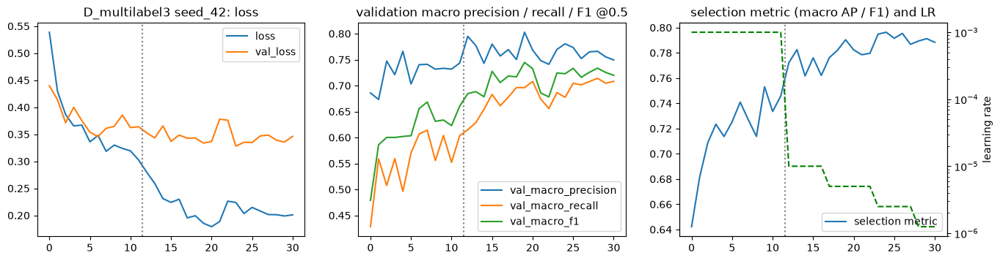

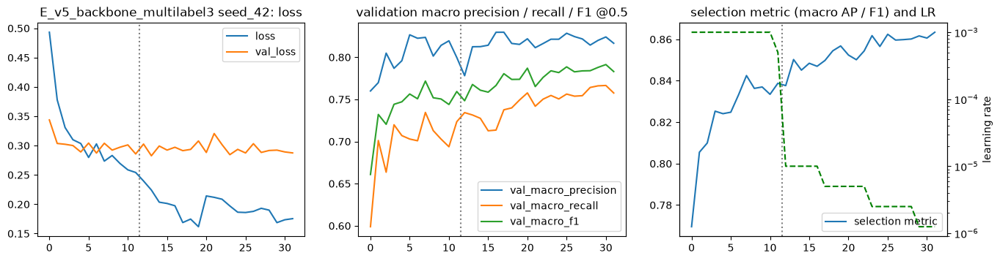

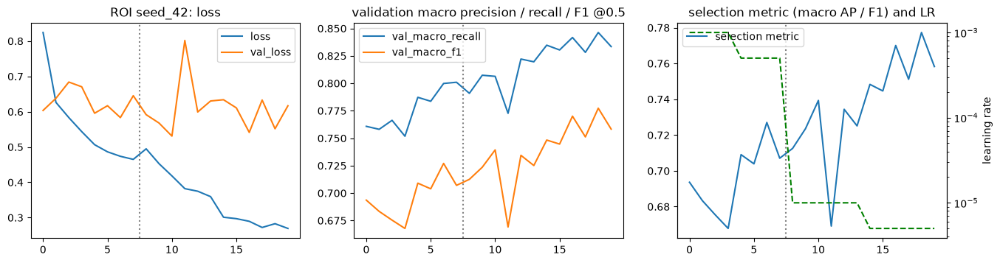

In [104]:
# 44.1 Training and validation curves (loss; precision / recall / F1) for every trained global experiment and the ROI model.
def plot_histories():
    exps = [e for e in CFG.GLOBAL_EXPERIMENTS if os.path.isdir(os.path.join(CFG.DIRS["checkpoints"], e))] + (["ROI"] if os.path.isdir(os.path.join(CFG.DIRS["checkpoints"], "ROI")) else [])
    if not exps: print("No training histories yet."); return
    for e in exps:
        for sd in sorted(os.listdir(os.path.join(CFG.DIRS["checkpoints"], e))):
            hs = [(ph, os.path.join(CFG.DIRS["checkpoints"], e, sd, f"phase{ph}_history.csv")) for ph in "AB"]; hs = [(ph, p) for ph, p in hs if os.path.exists(p)]
            if not hs: continue
            h = pd.concat([pd.read_csv(p).assign(phase=ph) for ph, p in hs], ignore_index=True); h["epoch_total"] = np.arange(len(h))
            fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
            for col in ["loss", "val_loss"]:
                if col in h: ax[0].plot(h.epoch_total, h[col], label=col)
            ax[0].set_title(f"{e} {sd}: loss"); ax[0].legend()
            for col in ["val_macro_precision", "val_macro_recall", "val_macro_f1"]:
                if col in h: ax[1].plot(h.epoch_total, h[col], label=col)
            ax[1].set_title("validation macro precision / recall / F1 @0.5"); ax[1].legend()
            if "val_sel" in h: ax[2].plot(h.epoch_total, h.val_sel, label="selection metric")
            if "learning_rate" in h: ax2 = ax[2].twinx(); ax2.plot(h.epoch_total, h.learning_rate, "g--"); ax2.set_yscale("log"); ax2.set_ylabel("learning rate")
            ax[2].set_title("selection metric (macro AP / F1) and LR"); ax[2].legend()
            for a in ax: a.axvline((h.phase == "A").sum() - 0.5, color="gray", ls=":")
            savefig(fig, f"history_{e}_{sd}", "figures")


plot_histories()

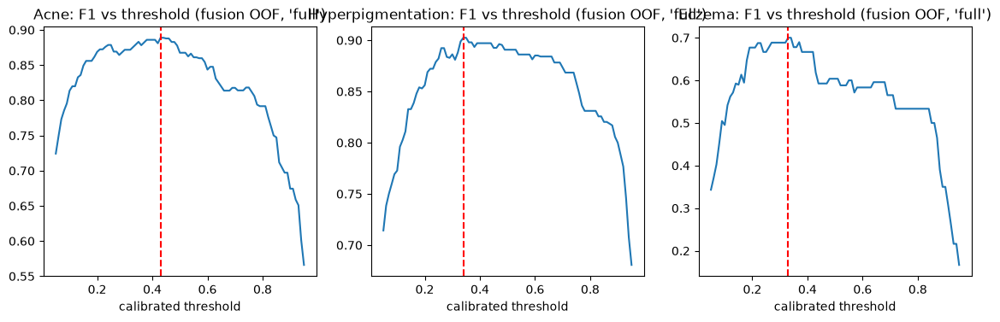

In [105]:
# 45.1 Threshold-vs-F1 (fusion OOF), ROC and PR curves, per-condition multilabel confusion matrices and reliability on the TEST split.
from sklearn.metrics import precision_recall_curve, roc_curve, multilabel_confusion_matrix
if FUSION_STATE.get("oof") and CALIB.get("full"):
    yf = FUSION_STATE["y"]; pf = apply_platt(FUSION_STATE["oof"]["full"], CALIB["full"]["platt"]); fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for j, c in enumerate(CFG.CONDITIONS):
        k = yf[:, j] >= 0
        if (yf[k, j] == 1).sum() < 5: ax[j].set_title(f"{c}: too few positives"); continue
        fs = []
        for t in CFG.THRESHOLD_GRID:
            p = pf[k, j] >= t; tp = (p & (yf[k, j] == 1)).sum(); fp = (p & (yf[k, j] == 0)).sum(); fn = (~p & (yf[k, j] == 1)).sum(); fs.append(2 * tp / max(2 * tp + fp + fn, 1))
        ax[j].plot(CFG.THRESHOLD_GRID, fs); ax[j].axvline(CALIB["full"]["thresholds"][j], color="r", ls="--"); ax[j].set_title(f"{c}: F1 vs threshold (fusion OOF, 'full')"); ax[j].set_xlabel("calibrated threshold")
    savefig(fig, "threshold_vs_f1")
if TEST:
    S, yt = TEST["S"], TEST["y"]; show = ["A2_v5_thresholded", "B_improved_global", "C_yolo_only", "D_roi_only", "E_global_plus_yolo", "F_full_fusion"]
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    for j, c in enumerate(CFG.CONDITIONS):
        k0 = yt[:, j] >= 0
        for name in show:
            s = S[name]["s"][:, j]; k = k0 & ~np.isnan(s)
            if k.sum() < 10 or (yt[k, j] == 1).sum() < CFG.MIN_POS_FOR_METRIC or (yt[k, j] == 0).sum() < CFG.MIN_POS_FOR_METRIC: continue
            fpr, tpr, _ = roc_curve(yt[k, j], s[k]); ax[0, j].plot(fpr, tpr, label=name); pr, rc, _ = precision_recall_curve(yt[k, j], s[k]); ax[1, j].plot(rc, pr, label=name)
        ax[0, j].plot([0, 1], [0, 1], "k:"); ax[0, j].set_title(f"{c}: ROC (test)"); ax[1, j].set_title(f"{c}: precision-recall (test)"); ax[0, j].set_xlabel("FPR"); ax[0, j].set_ylabel("TPR"); ax[1, j].set_xlabel("recall"); ax[1, j].set_ylabel("precision")
    ax[0, 0].legend(fontsize=6); savefig(fig, "roc_pr_curves_test")
    fig, ax = plt.subplots(2, 3, figsize=(12, 7))
    for r_, name in enumerate(["A_v5_argmax", "F_full_fusion"]):
        d = S[name]["dec"]; full = (yt >= 0).all(axis=1) & ~np.isnan(d).any(1)
        if full.sum() == 0: continue
        mcm = multilabel_confusion_matrix(yt[full], (d[full] > 0.5).astype(int))
        for j, c in enumerate(CFG.CONDITIONS):
            ax[r_, j].imshow(mcm[j], cmap="Blues"); ax[r_, j].set_xticks([0, 1]); ax[r_, j].set_yticks([0, 1]); ax[r_, j].set_xticklabels(["pred absent", "pred present"]); ax[r_, j].set_yticklabels(["true absent", "true present"])
            for a_ in range(2):
                for b_ in range(2): ax[r_, j].text(b_, a_, int(mcm[j][a_, b_]), ha="center", va="center")
            ax[r_, j].set_title(f"{name[:2]} {c}", fontsize=9)
    savefig(fig, "multilabel_confusion_matrices_test")
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for j, c in enumerate(CFG.CONDITIONS):
        for name in ["B_improved_global", "F_full_fusion"]:
            s = S[name]["s"][:, j]; k = (yt[:, j] >= 0) & ~np.isnan(s)
            if k.sum() >= 30: _, rel = ece_binary(s[k], yt[k, j], CFG.CALIBRATION_BINS); ax[j].plot(rel.mean_conf, rel.accuracy, "o-", label=name)
        ax[j].plot([0, 1], [0, 1], "k--"); ax[j].set_title(f"{c}: reliability (test)"); ax[j].legend(fontsize=7)
    savefig(fig, "reliability_test")
    cal_rows = []
    for name in ["B_improved_global", "E_global_plus_yolo", "F_full_fusion"]:
        bt = brier_ece(yt, np.nan_to_num(S[name]["s"], nan=0.5)); bt.insert(0, "system", name); cal_rows.append(bt)
    CALT = pd.concat(cal_rows); display(CALT.round(4)); write_csv(CALT, os.path.join(CFG.DIRS["metrics"], "test_calibration.csv"))

In [106]:
# 46.1 Galleries: correct predictions, incorrect predictions, multi-condition predictions (test; images are shown only after the single evaluation).
def eval_gallery(idx, title, fname, S_name="F_full_fusion"):
    if not len(idx): print("(none:", title, ")"); return
    tdf, yt, S = TEST["df"], TEST["y"], TEST["S"]; idx = list(idx)[:CFG.N_EXAMPLE_IMAGES]; cols = 6; rows = int(math.ceil(len(idx) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.7, rows * 3.1), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), idx):
        r = tdf.iloc[i]; bgr = cv2.imread(r.orig_path if r.has_orig else r.proc_path); a.imshow(cv2.cvtColor(draw_detections(bgr, [b for b in det_rows_for(r.image_id) if b["deployed"]]), cv2.COLOR_BGR2RGB))
        a.set_title(f"truth: {combo_label((yt[i] == 1).astype(float)) if (yt[i] >= 0).all() else 'partial'}\npred: {combo_label(S[S_name]['dec'][i])}\n" + " ".join(f"{c[:3]} {S[S_name]['s'][i, j]:.2f}" for j, c in enumerate(CFG.CONDITIONS)), fontsize=6.5)
    fig.suptitle(title); savefig(fig, fname)


if TEST:
    S, yt = TEST["S"], TEST["y"]; d = S["F_full_fusion"]["dec"] > 0.5; full = (yt >= 0).all(1)
    ok_ = np.where(full & (d == (yt == 1)).all(1) & ((yt == 1).sum(1) >= 1))[0]; bad_ = np.where(full & (d != (yt == 1)).any(1))[0]; multi_ = np.where(full & (d.sum(1) >= 2))[0]
    eval_gallery(ok_, "Correct predictions (system F, test)", "gallery_test_correct"); eval_gallery(bad_, "Incorrect predictions (system F, test)", "gallery_test_incorrect"); eval_gallery(multi_, "Multi-condition predictions (system F, test)", "gallery_test_multi")

## 49. V5 versus V6 — what can and cannot be compared
| Comparison | Valid? | Why |
|---|---|---|
| V5's *published* test metrics (4-class, single-label, V5 test split) vs V6 test metrics | **No** | different label scheme (softmax class vs per-condition Present/Absent), different population (V5 split leaks siblings and contains images V6 trains on), different metric definitions |
| V5 (system A) vs V6 systems on the **V6 test split with verified multilabel labels** | **Yes, with a caveat** | same images, same labels, same metrics. Caveat: V5 saw some of these images (or their siblings) during training, which *favours V5*; the **V5-unseen subset** below removes images whose leakage group appears in the V5 training split |
| Normal-vs-Hyperpigmentation confusion, mixed-condition detection | **Yes** (on verified labels) | V5 can name only one class, so "mixed" exact-match is structurally 0 for V5 |
| Deployment behaviour on kiosk/upload captures | **Descriptive only** | there are no verified labels for the captures; outputs are compared, not scored |

In [107]:
# 49.1 V5 original reported metrics (read from the V5 logs; NOT comparable to V6) + V5-vs-V6 on the verified test split, all images and V5-unseen only.
V5_REPORTED = None
ea = os.path.join(CFG.V5_RUN_DIR, "logs", "error_analysis_with_leak_flag.csv")
if os.path.exists(ea):
    e = pd.read_csv(ea); rows = []
    for c in CFG.V5_CLASS_ORDER:
        tp = int(((e.true_class == c) & (e.pred_class == c)).sum()); fp = int(((e.true_class != c) & (e.pred_class == c)).sum()); fn = int(((e.true_class == c) & (e.pred_class != c)).sum())
        rows.append(dict(class_=c, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), support=int((e.true_class == c).sum())))
    V5_REPORTED = pd.DataFrame(rows); V5_REPORTED["accuracy_overall"] = float((e.true_class == e.pred_class).mean())
    if "leaky" in e: V5_REPORTED["accuracy_without_leaky_siblings"] = float((e[~e.leaky].true_class == e[~e.leaky].pred_class).mean())
    display(V5_REPORTED.round(4)); write_csv(V5_REPORTED, os.path.join(CFG.DIRS["v5_comparison"], "v5_reported_single_label_test_metrics.csv"))
    print("These are V5's own single-label results on the V5 test split. They are shown for context and must NOT be compared numerically with the V6 multilabel tables.")
else:
    print("V5 error-analysis log not found; V5's historical metrics are not shown (the V5-on-V6-test comparison below does not need it).")

if TEST:
    v5train_groups = set(DF[DF.v5_split == "train"].group_id); tdf = TEST["df"]; unseen = ~tdf.group_id.isin(v5train_groups).values
    print(f"V6 test images whose leakage group was in the V5 TRAIN split: {int((~unseen).sum())} of {len(tdf)}  -> V5-unseen subset n = {int(unseen.sum())}")
    cmp = []
    for scope, m in [("all V6 test images", np.ones(len(tdf), bool)), ("V5-unseen subset", unseen)]:
        if m.sum() < 20: cmp.append(dict(scope=scope, note=f"only {int(m.sum())} images: not enough for a comparison")); continue
        for name in ["A_v5_argmax", "A2_v5_thresholded", "B_improved_global", "E_global_plus_yolo", "F_full_fusion"]:
            d = TEST["S"][name]["dec"][m]; sm = set_metrics_dec(TEST["y"][m], d); mc = metrics_dec(TEST["y"][m], TEST["S"][name]["s"][m], d)
            cmp.append(dict(scope=scope, system=name, n=int(m.sum()), macro_f1=macro_f1_dec(TEST["y"][m], d), exact_match=sm["exact_match"], hamming_loss=sm["hamming_loss"], **{f"f1_{c}": float(mc.f1[j]) for j, c in enumerate(CFG.CONDITIONS)}))
    V5V6 = pd.DataFrame(cmp); display(V5V6.round(4)); write_csv(V5V6, os.path.join(CFG.DIRS["v5_comparison"], "v5_vs_v6_verified_test.csv"))
    hyper = (TEST["y"][:, 1] == 1) & (TEST["y"] >= 0).all(1)
    nh = {n: float(((np.nan_to_num(TEST["S"][n]["dec"]).sum(1) == 0) & hyper).sum() / max(hyper.sum(), 1)) for n in ["A_v5_argmax", "B_improved_global", "E_global_plus_yolo", "F_full_fusion"]}
    print("verified Hyperpigmentation images scored as 'no condition' (Normal):", {k: round(v, 3) for k, v in nh.items()}, f"(n verified hyperpigmentation = {int(hyper.sum())})")
    write_json(os.path.join(CFG.DIRS["v5_comparison"], "hyperpigmentation_missed_as_normal.json"), dict(rates=nh, n=int(hyper.sum())))

,class_,precision,recall,f1,support,accuracy_overall,accuracy_without_leaky_siblings
0,Acne,0.9566,0.8538,0.9023,465,0.9289,0.9086
1,Hyperpigmentation,0.9708,0.9515,0.9611,454,0.9289,0.9086
2,Eczema,0.7404,0.9295,0.8242,227,0.9289,0.9086
3,Normal,0.9804,0.9825,0.9815,458,0.9289,0.9086


These are V5's own single-label results on the V5 test split. They are shown for context and must NOT be compared numerically with the V6 multilabel tables.


# Part X — ONNX Export, Deployment Metadata, Audit Logging, Automated Tests and Thesis Report

Sections: **(50) ONNX export · (51) Keras-vs-ONNX verification · (52) deployment metadata · (53) structured audit logging · (54) unit and integration tests · (55) Chapter IV tables and visualisations · (56) final experiment and artifact summary.**

**Protection of production models.** Everything is written under `…/v6/astra_runs/<RUN_ID>/export/` with a `v6_` file-name prefix. `export_path()` refuses any path that is, or lies under, the V5 model folder, the YOLO/WPF `Model` folder, or any protected directory — and the end-of-run check re-computes SHA-256 hashes of every original model and raises if one changed. **Deployment of any exported file into the WPF application is a separate, manual, approved step that this notebook does not perform.**

In [94]:
# 50.1 Export helpers (guarded) + contract checks used by the export verification and by the unit tests.
def export_path(name):
    p = os.path.join(CFG.DIRS["export"], "v6_" + name)
    require(not is_protected(p), f"export path is protected: {p}")
    return safe_path(p)


def assert_contract(in_shape, out_shape, expected_in=(224, 224, 3), expected_out=None):
    """Shape contract of an ONNX/Keras model: input [N,H,W,C] and the last output dimension. Raises V6Error on a mismatch (never silently adapts)."""
    require(len(in_shape) == len(expected_in) + 1 and tuple(in_shape[1:]) == tuple(expected_in), f"input shape {tuple(in_shape)} != [N,{','.join(map(str, expected_in))}]")
    if expected_out is not None: require(out_shape[-1] == expected_out, f"output has {out_shape[-1]} values, expected {expected_out}")


def validate_label_map(classes, expected):
    require(list(classes) == list(expected), f"label map {list(classes)} does not match the expected order {list(expected)}")


def load_onnx_verified(path, expected_sha256=None):
    """Hash check BEFORE loading; a corrupted or substituted model raises V6Error (never loaded silently)."""
    require(os.path.isfile(path), f"model file not found: {path}")
    if expected_sha256: require(sha256_file(path) == expected_sha256, f"SHA-256 mismatch for {os.path.basename(path)}: the model file is not the one that was registered")
    try:
        return ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    except Exception as e:
        raise V6Error(f"model file is corrupted or not a valid ONNX model: {os.path.basename(path)} ({type(e).__name__})")


def to_onnx(model,name,opset=13):
    """Concrete tf.function avoids Keras 3 private save-signature dependencies."""
    import tf2onnx
    path=export_path(name+'.onnx')
    sig=[tf.TensorSpec([None]+list(i.shape[1:]),tf.float32,name=i.name.split(':')[0]) for i in model.inputs]
    @tf.function(input_signature=sig)
    def serving(*args):
        result=model(args[0] if len(args)==1 else list(args),training=False)
        return tuple(result) if isinstance(result,(list,tuple)) else (result,)
    try:
        tf2onnx.convert.from_function(serving,input_signature=sig,opset=opset,output_path=path)
        return dict(status='exported',path=path,sha256=sha256_file(path),attempt='from_function')
    except Exception as e:
        return dict(status='FAILED',path=None,error=f'{type(e).__name__}: {e}')


def dump_keras_weights_json(model, name):
    """Fallback for tiny custom models: architecture summary + every weight as float32 lists (a C# port can implement the few layers natively)."""
    path = export_path(name + "_weights.json")
    write_json(path, dict(layers=[dict(name=l.name, cls=type(l).__name__, config={k: v for k, v in l.get_config().items() if isinstance(v, (int, float, str, bool, list, tuple, type(None)))},
                                       weights={str(i)+":"+getattr(w,"path",w.name): np.asarray(w).astype(np.float32).tolist() for i,w in enumerate(l.weights)}) for l in model.layers], inputs=[i.name for i in model.inputs]))
    return path

## 50. Export of the newly trained components
Exports the selected global/ROI Keras models, their feature models, and every seed of runtime fusion variants `global_only`, `global_yolo`, `full`. Failed ONNX conversions are recorded explicitly. JSON weights are a reference for a future native port, not a tested C# implementation. YOLO detectors and V5 are not re-exported. Runtime deployment must average all per-seed fusion logits before calibration.

In [95]:
astra_require_action('export')
EXPORT_STATUS = {}
try:
    require(GLOBAL_SELECTED[0], "no selected global model: nothing to export yet", gate=True)
    gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
    save_selected_model(gm,export_path('global_selected.keras'))
    fm = embedding_model(gm); save_selected_model(fm,export_path('global_features.keras')); EXPORT_STATUS["global_features"] = to_onnx(fm, "global_features_mobilenetv2")
    EXPORT_STATUS["global_features"]["outputs"] = ["embedding_128", "logits (multilabel3: apply sigmoid; softmax4: probabilities)"]
    if ROI_SELECTED_SEED is not None:
        rfm = load_roi_feature_model(); save_selected_model(rfm,export_path('roi_features.keras'))
        _roi_model = keras.models.load_model(os.path.join(CFG.DIRS['checkpoints'],'ROI',f'seed_{ROI_SELECTED_SEED}','final_best.keras'),compile=False)
        save_selected_model(_roi_model,export_path('roi_selected.keras'))
        EXPORT_STATUS["roi_features"] = to_onnx(rfm, "roi_features_mobilenetv2"); EXPORT_STATUS["roi_features"]["outputs"] = [f"embedding_{CFG.ROI_EMB}", "softmax_" + "_".join(CFG.ROI_CLASSES)]
    for var in ("global_only", "global_yolo", "full"):
        for export_seed in CFG.SEEDS:
            p = os.path.join(CFG.DIRS["fusion"], var, f"final_seed{export_seed}.keras")
            if os.path.exists(p):
                fmod = keras.models.load_model(p, custom_objects={"MaskedBCE": MaskedBCE, "MaskedAttentionPool": MaskedAttentionPool, "ModalityDropout": ModalityDropout, "MaskFraction": MaskFraction}, compile=False)
                st = to_onnx(fmod, f"fusion_{var}_seed{export_seed}"); st["weights_json"] = dump_keras_weights_json(fmod, f"fusion_{var}_seed{export_seed}"); EXPORT_STATUS[f"fusion_{var}_seed{export_seed}"] = st
    keras.backend.clear_session()
    write_json(os.path.join(CFG.DIRS["export"], "v6_export_status.json"), EXPORT_STATUS); display(pd.DataFrame(EXPORT_STATUS).T[["status"] + [c for c in ["attempt", "error"] if c in pd.DataFrame(EXPORT_STATUS).T.columns]])
except GateError as g:
    print(f"[export] SKIPPED - {g}")

,status,attempt
global_features,exported,from_function
roi_features,exported,from_function
fusion_global_only_seed42,exported,from_function
fusion_global_yolo_seed42,exported,from_function
fusion_full_seed42,exported,from_function


## 51. Keras-versus-ONNX verification (and the Python reference for C# parity)
For every exported component the notebook feeds **identical inputs** to Keras and ONNX Runtime and reports the maximum absolute difference per output, the exact ONNX input/output **names and shapes**, and the SHA-256 of each file. Tolerance for float32 CPU runs is `1e-4` (probabilities) — larger differences are flagged, not hidden. The same procedure, with the C# application's output on the same tensor (`SkinDevApp.exe --diagnose`), is the **deployment parity test** (see the deployment guide): the Python reference `assess_image` must be reproduced by the C# port within these tolerances.

In [96]:
PARITY_EXPORT = {}
TOL = 1e-4
if EXPORT_STATUS:
    sample = DF[DF.split.isin(["validation", "fusion"])].head(16)
    xs = np.stack([read_rgb_norm(p) for p in sample.proc_path]).astype(np.float32)
    def compare(name, keras_model, feed):
        st = EXPORT_STATUS.get(name)
        if not st or st["status"] != "exported": PARITY_EXPORT[name] = dict(status="not exported" if not st else st["status"]); return
        sess = load_onnx_verified(st["path"], st["sha256"]); names = [i.name for i in sess.get_inputs()]
        k_out = keras_model.predict(feed, verbose=0); k_out = [k_out] if not isinstance(k_out, (list, tuple)) else list(k_out)
        o_out = sess.run(None, {n: f for n, f in zip(names, feed if isinstance(feed, list) else [feed])})
        diffs = [float(np.abs(np.asarray(a, np.float32) - np.asarray(b, np.float32)).max()) for a, b in zip(k_out, o_out)]
        PARITY_EXPORT[name] = dict(status="compared", max_abs_diff_per_output=diffs, within_tolerance=bool(max(diffs) <= TOL), onnx_inputs=[(i.name, i.shape) for i in sess.get_inputs()], onnx_outputs=[(o.name, o.shape) for o in sess.get_outputs()], sha256=st["sha256"])
    try:
        gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
        compare("global_features", embedding_model(gm), xs); keras.backend.clear_session()
        if ROI_SELECTED_SEED is not None:
            rx = np.stack([roi_norm(cv2.cvtColor(cv2.resize(cv2.imread(p), (ROI_S, ROI_S)), cv2.COLOR_BGR2RGB)) for p in sample.proc_path]); compare("roi_features", load_roi_feature_model(), rx); keras.backend.clear_session()
        if FUSION_STATE.get("X"):
            for var in ("global_only", "global_yolo", "full"):
                for export_seed in CFG.SEEDS:
                    p = os.path.join(CFG.DIRS["fusion"], var, f"final_seed{export_seed}.keras")
                    if os.path.exists(p) and var in FUSION_STATE["X"]:
                        fmod = keras.models.load_model(p, custom_objects={"MaskedBCE": MaskedBCE, "MaskedAttentionPool": MaskedAttentionPool, "ModalityDropout": ModalityDropout, "MaskFraction": MaskFraction}, compile=False)
                        feed = x_list(subset(FUSION_STATE["X"][var], np.arange(min(16, len(FUSION_STATE["df"]))))); compare(f"fusion_{var}_seed{export_seed}", fmod, feed); keras.backend.clear_session()
    except Exception as e:
        PARITY_EXPORT["error"] = f"{type(e).__name__}: {str(e)[:200]}"; print("verification could not complete:", PARITY_EXPORT["error"])
    write_json(os.path.join(CFG.DIRS["export"], "v6_keras_vs_onnx_verification.json"), PARITY_EXPORT); display(pd.DataFrame(PARITY_EXPORT).T)
else:
    print("Nothing exported yet: verification not run.")

E0000 00:00:1793608977.246024  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1793608982.804728  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,status,max_abs_diff_per_output,within_tolerance,onnx_inputs,onnx_outputs,sha256
global_features,compared,"[0.0425724983215332, 0.03326225280761719]",False,"[(image_nhwc_m1p1, [unk__657, 224, 224, 3])]","[(Identity:0, [unk__658, 128]), (Identity_1:0,...",82662184cc526f267d977f8fa4dec9ec1362429aeec3be...
roi_features,compared,"[0.05155324935913086, 0.019429385662078857]",False,"[(roi_nhwc_m1p1, [unk__1314, 224, 224, 3])]","[(Identity:0, [unk__1315, 64]), (Identity_1:0,...",45a65103d89c4c5911809930d8f7bceb45ee82c77dfd53...
fusion_global_only_seed42,compared,[0.000469207763671875],False,"[(g_emb, [unk__1442, 128]), (g_logit, [unk__14...","[(Identity:0, [unk__1448, 3])]",fd9ef9a6803f30a9647084c5632d801d3a0b4c4a247631...
fusion_global_yolo_seed42,compared,[0.0005065202713012695],False,"[(g_emb, [unk__1574, 128]), (g_logit, [unk__15...","[(Identity:0, [unk__1580, 3])]",f25a741cae5d87b5a2b17701ad861fac51b20118bbcaac...
fusion_full_seed42,compared,[0.0005545616149902344],False,"[(g_emb, [unk__1706, 128]), (g_logit, [unk__17...","[(Identity:0, [unk__1712, 3])]",1dbea01249c76fa2c6947ce9320f838d1a8a72270d723b...


## 51.5 Export schemas of the final-assessment and dermatologist-review contract
Two JSON Schemas and a short contract description are written next to the model exports. They are the **data contract the future WPF application must implement**: the AI assessment (schema `1.1`, sealed, always `PENDING_DERMATOLOGIST_REVIEW` at issue, never clinically validated) and the **separate** dermatologist review (findings per condition, blinding flags, link to the reviewed AI version by hash). The notebook validates its own output against them (a small built-in validator; no extra package needed).

In [97]:
def _json_type(t):
    return {"string": str, "boolean": bool, "object": dict, "array": list, "number": (int, float), "integer": int, "null": type(None)}[t]


def validate_contract_lite(d, schema):
    """Minimal JSON-Schema subset check (required, type, enum, const, pattern, nested 'properties'). Returns a list of error strings (empty = valid)."""
    errs = [f"missing required field '{k}'" for k in schema.get("required", []) if k not in d]
    for k, sp in schema.get("properties", {}).items():
        if k not in d: continue
        v = d[k]; types = sp.get("type"); types = [types] if isinstance(types, str) else (types or [])
        if types and not any(isinstance(v, _json_type(t)) and not (t == "integer" and isinstance(v, bool)) and not (t == "number" and isinstance(v, bool)) for t in types): errs.append(f"'{k}' has type {type(v).__name__}, expected {types}")
        if "const" in sp and v != sp["const"]: errs.append(f"'{k}' must be {sp['const']!r}, got {v!r}")
        if "enum" in sp and v not in sp["enum"]: errs.append(f"'{k}' must be one of {sp['enum']}, got {v!r}")
        if "pattern" in sp and isinstance(v, str) and not re.fullmatch(sp["pattern"], v): errs.append(f"'{k}' does not match {sp['pattern']}")
        if isinstance(v, dict) and sp.get("properties"): errs += [f"{k}.{e}" for e in validate_contract_lite(v, sp)]
    return errs


_AI_FIELDS = [f.name for f in __import__("dataclasses").fields(FinalAssessment)]
FINAL_ASSESSMENT_JSON_SCHEMA = {
    "$schema": "https://json-schema.org/draft/2020-12/schema", "title": "LUMYVUE final AI assessment", "type": "object", "required": _AI_FIELDS,
    "description": "Sealed AI output. Issued ONLY as PENDING_DERMATOLOGIST_REVIEW; never edited after issue (corrections = a new assessment with a new scan_id). ai_content_sha256 = SHA-256 of the canonical JSON (sorted keys, compact separators) of every other field.",
    "properties": {
        "scan_id": {"type": "string"}, "state": {"type": "string", "enum": STATES}, "predicted_conditions": {"type": "array"}, "condition_scores": {"type": "object"}, "regions": {"type": "array"},
        "detector_availability": {"type": "object"}, "original_cnn_scores": {"type": "object"}, "original_yolo_outputs": {"type": "object", "description": "per condition: list of boxes, or null when the detector was unavailable (null is NOT an empty list)"},
        "review_status": {"type": "string", "const": REVIEW_STATUS_PENDING}, "requires_dermatologist_review": {"type": "boolean", "const": True},
        "clinical_status": {"type": "string", "const": CLINICAL_STATUS},
        "ai_verification": {"type": "object", "properties": {"clinical_validation": {"type": "boolean", "const": False}}, "required": ["clinical_validation", "stage_reached", "verification_passes", "stop_reason", "statement"]},
        "ai_content_sha256": {"type": "string", "pattern": "[0-9a-f]{64}"}, "schema_version": {"type": "string", "const": SCHEMA_VERSION}, "created_utc": {"type": "string"}}}
DERMATOLOGIST_REVIEW_JSON_SCHEMA = {
    "$schema": "https://json-schema.org/draft/2020-12/schema", "title": "LUMYVUE dermatologist review (separate from the AI assessment)", "type": "object",
    "required": ["review_id", "scan_id", "ai_content_sha256", "review_status", "reviewer_id", "reviewer_role", "reviewed_at_utc", "blinded_to_ai", "ai_shown_before_review", "image_adequate", "findings", "schema_version"],
    "properties": {"review_id": {"type": "string"}, "scan_id": {"type": "string"}, "ai_content_sha256": {"type": "string", "pattern": "[0-9a-f]{64}"}, "review_status": {"type": "string", "enum": REVIEW_RECORD_STATUSES},
                   "reviewer_id": {"type": "string"}, "reviewer_role": {"type": "string", "const": "dermatologist"}, "reviewed_at_utc": {"type": "string"}, "blinded_to_ai": {"type": ["boolean", "null"]},
                   "ai_shown_before_review": {"type": ["boolean", "null"]}, "image_adequate": {"type": "string", "enum": ["yes", "no", "unknown"]},
                   "findings": {"type": "object", "required": list(CFG.CONDITIONS), "properties": {c: {"type": "string", "enum": list(FINDING_VALUES)} for c in CFG.CONDITIONS}, "description": "independent clinical findings; unknown is never absent"},
                   "schema_version": {"type": "string", "const": REVIEW_SCHEMA_VERSION}}}
REVIEW_CONTRACT = dict(
    rule="Every AI assessment, whatever its state, confidence, stage or findings, is issued as PENDING_DERMATOLOGIST_REVIEW and requires dermatologist review.",
    ai_assessment=dict(schema=SCHEMA_VERSION, status_at_issue=REVIEW_STATUS_PENDING, immutable_after_issue=True, seal="ai_content_sha256 = SHA-256(canonical JSON of all other fields)", corrections="issue a NEW assessment with a new scan_id; never edit"),
    dermatologist_review=dict(schema=REVIEW_SCHEMA_VERSION, separate_record=True, statuses=REVIEW_RECORD_STATUSES, links_to="scan_id + ai_content_sha256 (a review for a different AI version is refused)",
                              findings="present | absent | unknown per condition; blank/unknown is never treated as absent", reviewer_role="dermatologist", blinding_fields=["blinded_to_ai", "ai_shown_before_review"]),
    ai_verification="Stage 2 and the adaptive verification cycle are AI verification; clinical_validation is always false and the AI statement says so",
    metrics="agreement, disagreement, Cohen's kappa, PPV, sensitivity, specificity per condition from AI per-condition decisions vs dermatologist findings; AI-uncertain / AI-no-result / dermatologist-unknown are reported separately",
    states_meaning="state describes how well the AI evidence supports a result; it is not a diagnosis and not clinical confirmation")
write_json(export_path("final_assessment.schema.json"), FINAL_ASSESSMENT_JSON_SCHEMA); write_json(export_path("dermatologist_review.schema.json"), DERMATOLOGIST_REVIEW_JSON_SCHEMA); write_json(export_path("review_contract.json"), REVIEW_CONTRACT)
_probe = FinalAssessment(scan_id="schema_probe", state="UNCERTAIN_REVIEW_REQUIRED", created_utc="2026-01-01T00:00:00+00:00"); finalize_assessment(_probe)
_errs = validate_contract_lite(_probe.to_dict(), FINAL_ASSESSMENT_JSON_SCHEMA)
require(not _errs, f"the notebook's own assessment output violates its exported schema: {_errs}")
print("exported: final_assessment.schema.json, dermatologist_review.schema.json, review_contract.json | a freshly issued assessment validates against the schema:", not _errs)

exported: final_assessment.schema.json, dermatologist_review.schema.json, review_contract.json | a freshly issued assessment validates against the schema: True


## 52. Deployment metadata and C# mapping
`v6_model_metadata.json` collects everything the application needs: class/condition order, normalisation, tensor schemas, ROI procedure, detector execution order, post-processing, fusion input/output schemas, calibration and thresholds, Stage-1/2 rules, verification limits, versions and hashes. The **future** WPF implementation must use **one shared final-result object** (`FinalAssessment`, schema `lumyvue-final-assessment/1.0`) for the Results screen, localisation overlays, patient record, dermatologist review, thermal receipt and A4 report, keeping original CNN and YOLO outputs accessible. Parameters marked *provisional* must stay configuration, not constants.

In [98]:
def build_deployment_metadata():
    return dict(
        feature_schema_version='astra-fusion/1', evaluation_scope=ASTRA_EVALUATION_NOTE,
        schema=SCHEMA_VERSION, review_contract=REVIEW_CONTRACT, created=datetime.datetime.now().isoformat(timespec="seconds"), run_id=CFG.RUN_ID, status="EXPERIMENTAL - not validated for deployment; produced by an unexecuted-by-author notebook",
        condition_order=CFG.CONDITIONS, normal_definition="Normal = all three conditions verified Absent (derived; never a model output)", v5_class_order=CFG.V5_CLASS_ORDER,
        global_cnn=dict(experiment=GLOBAL_SELECTED, input="float32 NHWC [N,224,224,3]", preprocessing="BGR->RGB, bilinear (INTER_LINEAR) stretch to 224x224, (p/127.5)-1", outputs=["embedding_128", "logits/probabilities"],
                        note="multilabel3: apply sigmoid; fusion consumes logit(clip(sigmoid(z), 1e-4, 1-1e-4)) i.e. z clipped to +-9.21"),
        yolo=dict(execution_order=CFG.CONDITIONS, preprocessing="letterbox to imgsz (pad 114, bilinear), RGB, /255, NCHW", output="[1,4+nc,N] cx,cy,w,h (letterbox px) + class scores, no objectness",
                  postprocessing=dict(per_member_nms_iou={c: DETECTORS[c].nms_iou for c in CFG.CONDITIONS}, member_floor=CFG.YOLO_FLOOR, ensemble_fusion_iou={c: DETECTORS[c].fusion_iou for c in CFG.CONDITIONS}, fused_confidence="min(1, sum(conf)/members)",
                                      deployed_thresholds={c: DETECTORS[c].threshold for c in CFG.CONDITIONS}, candidate_pool_min_conf=CFG.YOLO_POOL_MIN_CONF, max_boxes=CFG.YOLO_MAX_BOXES, face_filter="optional (centre inside face box +25%)"),
                  availability={c: DETECTORS[c].available for c in CFG.CONDITIONS}, location={c: DETECTORS[c].location for c in CFG.CONDITIONS}, versions={c: DETECTORS[c].version for c in CFG.CONDITIONS}, sha256={c: [m.sha256 for m in DETECTORS[c].members] for c in CFG.CONDITIONS}, config_hash=YOLO_CONFIG_HASH,
                  note="Detectors that are not installed are 'unavailable' (availability flag 0), never 'zero detections'."),
        roi=dict(size=ROI_S, margin=CFG.ROI_MARGIN, alt_context_margin=CFG.ROI_ALT_MARGIN, square_window="extend shorter side, shift inside image, no padding", tiers={"1": "deployed boxes (round-robin over detectors, IoU>%.2f suppressed)" % CFG.ROI_OVERLAP_SUPPRESS_IOU, "2": "lower-confidence pool boxes", "3": "alternative wider-context crops of tier-1 boxes"},
                 max_tier1=CFG.ROI_MAX_TIER1, max_total=CFG.ROI_MAX_TOTAL, classes=CFG.ROI_CLASSES, preprocessing="RGB, bilinear, (p/127.5)-1", feature_dim=ROI_FEAT_DIM, yolo_feature_names=YOLO_FEATURE_NAMES),
        fusion=dict(inputs=dict(g_emb=[128], g_logit=[3], g_extra=[2], det_ev=[CFG.N_COND * DET_EV_DIM], roi_feat=[CFG.ROI_MAX_TOTAL, ROI_FEAT_DIM], roi_mask=[CFG.ROI_MAX_TOTAL]), det_ev_layout=["available", "detected", "max_deployed_conf", "max_pool_conf", "sqrt_rel_area", "cx", "cy"],
                    output="[3] logits in CFG.CONDITIONS order", ensemble="mean of per-seed logits", seeds=CFG.SEEDS, calibration=CALIB, variants_used_at_runtime=["global_only", "global_yolo", "full"]),
        stages=dict(stage1_rule=STAGE1, stage2_band=(BAND2 if BAND2 is not None and np.isfinite(BAND2) else None), stage2_accepts_nothing=(BAND2 is None or not np.isfinite(BAND2)), verification=dict(max_passes=CFG.MAX_VERIFICATION_PASSES, max_seconds=CFG.MAX_VERIFICATION_SECONDS, min_new_rois=CFG.MIN_NEW_ROIS, convergence_eps=CFG.CONVERGENCE_EPS,
                    actions=["pass1: tier-1 regions", "pass2: + tier-2 candidates", "pass3: + tier-3 alternative-context crops", "recapture request", "external AI verifier (if configured)"], nature="AI verification only - not clinical validation"),
                    quality_thresholds=CFG.QUALITY, quality_status="provisional heuristics, unvalidated", ood=dict(method="Mahalanobis on global embedding", percentile=CFG.OOD_PERCENTILE, threshold=(None if OOD is None else OOD.threshold)), states=STATES),
        versions=dict(v5_onnx_sha256=V5_SHA, yolo_config_hash=YOLO_CONFIG_HASH, python=sys.version.split()[0], tensorflow=tf.__version__, onnxruntime=ort.__version__), export_status=EXPORT_STATUS,
        parity_procedure="Run `SkinDevApp.exe --diagnose <image> <dir>` for the C# tensor/probabilities, then Section 15.4; compare per-output differences with the tolerances recorded in v6_keras_vs_onnx_verification.json.",
        production_guard="Nothing here replaces or overwrites the V5 model or any YOLO file.")


META_V6 = build_deployment_metadata(); write_json(export_path("model_metadata.json"), META_V6)
write_json(export_path("labels.json"), dict(conditions=CFG.CONDITIONS, roi_classes=CFG.ROI_CLASSES, v5_classes=CFG.V5_CLASS_ORDER, states=STATES, normal="derived: all conditions absent"))
print("deployment metadata written to", redact(CFG.DIRS["export"]))

deployment metadata written to /mnt/c/Users/<USER>/source/repos/SkinDevApp/v6/astra_runs/open_run02/export


## 53. Structured audit logging
Every gate, training phase, test-split opening, export and (when used) inference error is appended to a **hash-chained** `logs/audit_log.jsonl`; each record contains the hash of its predecessor, so an edit or deletion is detectable (`verify_audit_chain`). Logs contain **no images, no filenames and no identifiers except pseudonyms**. `log_assessment` writes one compact record per scan assessment (state, stage, passes, stop reason, model hashes) — never the image or the regions' pixels. **Production note:** the C# application must implement its own protected audit trail; this log protects the *research* run.

In [99]:
def log_assessment(fa):
    d = fa.to_dict() if hasattr(fa, "to_dict") else fa
    return log_event("assessment", scan=d["scan_id"], state=d["state"], review_status=d["review_status"], ai_sha=d.get("ai_content_sha256", "")[:16], stage=d["stage_reached"], passes=d["verification_passes"], stop=d["stop_reason"], predicted=d["predicted_conditions"],
                     model_hash=hashlib.sha256(json.dumps(d["model_versions"], sort_keys=True, default=str).encode()).hexdigest()[:16])


ok_chain, bad_at = verify_audit_chain()
print("audit chain intact:", ok_chain, "" if ok_chain else f"(first broken record: {bad_at})")
require(ok_chain, "The audit log hash chain is broken: the log was modified.")

audit chain intact: True 


## 54. Automated unit and integration tests
The suite checks the **logic that guards against silent failure**: invalid images, RGB/BGR and normalisation, shape and label-map contracts, missing/corrupted/substituted models, empty/duplicate/overlapping boxes, missing detectors and detector failures, ROI coordinate errors, fusion shape mismatches, calibration failure, mixed/conflicting/low-confidence decisions, Stage-2 escalation, **bounded** verification termination, lack of new evidence, abstention, recapture, out-of-scope, deterministic replay, raw-prediction preservation and reproducibility of the final result, split leakage, write-protection of originals, *Unknown ≠ Absent*, and the audit chain. Tests that need trained components are **skipped with a reason**, never reported as passed. The notebook raises an error if any test fails.

In [100]:
import unittest, tempfile, copy


class StubSession:
    """Fake ONNX session: returns a fixed output so detector logic can be tested without model files."""
    def __init__(self, out=None, raises=None): self.out, self.raises = out, raises
    def run(self, names, feed):
        if self.raises: raise self.raises
        return [self.out]
    def get_inputs(self): return [SimpleNamespace(name="images", shape=[1, 3, 64, 64])]


def stub_spec(out=None, raises=None, available=True, nms=0.5):
    m = Member(path="stub.onnx", sha256="0" * 64, session=StubSession(out, raises), input_name="images", imgsz=64, layout="rows_first", nc=1, class_names=["acne"], out_shape=[1, 5, 10])
    return DetectorSpec("Acne", "specialist", [m] if available else [], 64, nms, 0.25, 0.02, {"Acne": 0}, available)


def anchors(boxes, n=10):
    """Build a [1,5,n] YOLO-style output from [(cx,cy,w,h,score)] in 64px letterbox coordinates."""
    o = np.zeros((1, 5, n), np.float32)
    for i, (cx, cy, w, h, s) in enumerate(boxes): o[0, :, i] = [cx, cy, w, h, s]
    return o


class TestV6(unittest.TestCase):
    # ---- inputs, preprocessing, contracts --------------------------------------------------------------------------------------
    def test_invalid_images(self):
        for bad in [None, np.zeros((10, 10), np.uint8), np.zeros((64, 64, 3), np.float32), np.zeros((8, 8, 3), np.uint8)]:
            self.assertFalse(validate_input(bad)[0])
        self.assertTrue(validate_input(np.zeros((64, 64, 3), np.uint8))[0])

    def test_rgb_bgr_order_and_normalisation(self):
        red_bgr = np.zeros((40, 40, 3), np.uint8); red_bgr[..., 2] = 255
        t = preprocess_global(red_bgr)
        self.assertEqual(t.shape, (224, 224, 3)); self.assertAlmostEqual(float(t[0, 0, 0]), 1.0, places=5); self.assertAlmostEqual(float(t[0, 0, 2]), -1.0, places=5)
        wrong = (cv2.resize(red_bgr, (224, 224)).astype(np.float32) / 255.0)                      # the classic 0..1 mistake must differ
        self.assertFalse(np.allclose(wrong, t, atol=1e-3))

    def test_shape_and_label_contracts(self):
        assert_contract([1, 224, 224, 3], [1, 4], expected_out=4)
        with self.assertRaises(V6Error): assert_contract([1, 128, 128, 3], [1, 4], expected_out=4)
        with self.assertRaises(V6Error): assert_contract([1, 224, 224, 3], [1, 3], expected_out=4)
        validate_label_map(CFG.V5_CLASS_ORDER, CFG.V5_CLASS_ORDER)
        with self.assertRaises(V6Error): validate_label_map(["Acne", "Eczema", "Hyperpigmentation", "Normal"], CFG.V5_CLASS_ORDER)

    def test_missing_corrupted_and_substituted_models(self):
        with self.assertRaises(V6Error): load_onnx_verified("/nonexistent/model.onnx")
        with tempfile.TemporaryDirectory() as d:
            p = os.path.join(d, "bad.onnx"); open(p, "wb").write(b"not an onnx file")
            with self.assertRaises(V6Error): load_onnx_verified(p)
            with self.assertRaises(V6Error): load_onnx_verified(p, expected_sha256="0" * 64)          # hash mismatch is checked before loading

    # ---- detectors, boxes, ROI ------------------------------------------------------------------------------------------------------
    def test_empty_detections_and_missing_detector(self):
        img = np.full((100, 100, 3), 128, np.uint8)
        r = detect_condition(stub_spec(anchors([])), img)
        self.assertEqual(r["boxes"], [])                                                            # detector ran, found nothing
        self.assertIsNone(detect_condition(stub_spec(available=False), img))                        # detector missing is NOT an empty result
        self.assertEqual(build_roi_candidates([], 100, 100), [])

    def test_detector_runtime_failure_is_not_swallowed(self):
        with self.assertRaises(RuntimeError): detect_condition(stub_spec(raises=RuntimeError("boom")), np.zeros((100, 100, 3), np.uint8))

    def test_duplicate_nested_and_overlapping_boxes(self):
        self.assertEqual(overlap_relation((0, 0, 100, 100), (2, 2, 101, 99))[0], "duplicate")
        self.assertEqual(overlap_relation((0, 0, 100, 100), (10, 10, 40, 40))[0], "nested")
        self.assertEqual(overlap_relation((0, 0, 100, 100), (60, 60, 160, 160))[0], "overlap")
        keep = nms_boxes([(0, 0, 100, 100, .9), (2, 2, 101, 99, .8), (10, 10, 40, 40, .7)], 0.5, 60)
        self.assertEqual(len(keep), 2)                                                              # duplicate removed, nested kept (IoU-NMS cannot see nesting)

    def test_decoding_and_letterbox_coordinates(self):
        img = np.full((100, 200, 3), 128, np.uint8)                                                 # wide image: letterbox pads top/bottom
        r = detect_condition(stub_spec(anchors([(32, 32, 20, 10, 0.9)])), img)
        b = r["boxes"][0]
        self.assertTrue(0 <= b["x0"] < b["x1"] <= 200 and 0 <= b["y0"] < b["y1"] <= 100)

    def test_roi_coordinate_errors_and_square_crops(self):
        img = np.random.RandomState(0).randint(0, 255, (120, 200, 3), np.uint8)
        self.assertEqual(crop_roi(img, (10, 10, 11, 11))[1], "too_small")
        self.assertEqual(crop_roi(img, (-50, 10, 40, 60))[1], "outside_image")
        self.assertEqual(crop_roi(img, (50, 50, 50, 80))[1] in ("too_small", "degenerate_box"), True)
        rgb, why = crop_roi(img, (150, 70, 199, 119)); self.assertEqual(why, ""); self.assertEqual(rgb.shape, (ROI_S, ROI_S, 3))
        cx0, cy0, side = square_crop_box(150, 70, 199, 119, 200, 120, 0.25); self.assertTrue(cx0 >= 0 and cy0 >= 0 and cx0 + side <= 200 and cy0 + side <= 120)

    def test_roi_candidate_caps(self):
        rows = [dict(condition=CFG.CONDITIONS[i % 3], conf=0.9 - 0.01 * i, deployed=True, x0=10.0 * i, y0=5.0, x1=10.0 * i + 8, y1=13.0, ensemble_support=3, ensemble_size=3, rel_area=0.001, cx=.5, cy=.5) for i in range(30)]
        c = build_roi_candidates(rows, 400, 100)
        self.assertLessEqual(len(c), CFG.ROI_MAX_TOTAL); self.assertLessEqual(sum(1 for x in c if x["tier"] == 1), CFG.ROI_MAX_TIER1)

    # ---- fusion, calibration ---------------------------------------------------------------------------------------------------------
    def test_fusion_shape_mismatch_and_masked_pool(self):
        m = build_fusion(dict(g_emb=8, det_ev=21, roi_feat=(4, 10)))
        ok = [np.zeros((2, 8), np.float32), np.zeros((2, 3), np.float32), np.zeros((2, 2), np.float32), np.zeros((2, 21), np.float32), np.zeros((2, 4, 10), np.float32), np.zeros((2, 4), np.float32)]
        self.assertEqual(m.predict(ok, verbose=0).shape, (2, 3))
        bad = list(ok); bad[4] = np.zeros((2, 4, 11), np.float32)
        with self.assertRaises(Exception): m.predict(bad, verbose=0)
        pool = MaskedAttentionPool(3); h = tf.ones((2, 4, 5)); out = pool([h, tf.zeros((2, 4))]).numpy()
        self.assertTrue(np.allclose(out, 0.0))                                                      # an empty ROI set yields zeros, not a fabricated crop

    def test_calibration_failure_is_explicit(self):
        z = np.random.RandomState(0).randn(30); y = np.array([1] * 3 + [0] * 27)
        self.assertIsNone(fit_platt(z, y))                                                          # too few positives: no calibration is claimed
        p = apply_platt(np.stack([z, z, z], 1), [None, None, None]); self.assertTrue(np.allclose(p, 1 / (1 + np.exp(-np.stack([z, z, z], 1))), atol=1e-6))
        self.assertTrue(np.isfinite(fit_platt(np.r_[np.random.RandomState(1).randn(40) + 2, np.random.RandomState(2).randn(40) - 2], np.r_[np.ones(40), np.zeros(40)])["a"]))

    def test_unknown_is_not_negative(self):
        if not CFG.USE_SOURCE_LABEL_AS_WEAK_POSITIVE: self.skipTest("weak positives disabled in this configuration")
        df = pd.DataFrame(dict(y_acne=[-1, 0], y_hyperpigmentation=[-1, 1], y_eczema=[-1, 0], train_ok=[False, True], src_label=["Acne", "Normal"]))
        y, weak = build_train_labels(df)
        self.assertEqual(y[0].tolist(), [1, -1, -1]); self.assertTrue(weak[0, 0])                    # weak positive only; the other two stay Unknown
        self.assertEqual(y[1].tolist(), [0, 1, 0])

    # ---- decisions, stages, verification ---------------------------------------------------------------------------------------------
    def test_decide_states(self):
        thr = [0.5, 0.5, 0.5]; av = [True, True, True]; q = dict(blocking=[], flags=[])
        self.assertEqual(decide(np.array([.9, .05, .05]), thr, .1, av, q, False, [])["state"], "FINDINGS_SUPPORTED")
        self.assertEqual(decide(np.array([.9, .9, .05]), thr, .1, av, q, False, [])["state"], "MULTIPLE_FINDINGS_SUPPORTED")
        self.assertEqual(decide(np.array([.05, .05, .05]), thr, .1, av, q, False, [])["state"], "NO_FINDINGS_SUPPORTED")
        self.assertEqual(decide(np.array([.52, .05, .05]), thr, .1, av, q, False, [])["state"], "UNCERTAIN_REVIEW_REQUIRED")            # low margin
        self.assertEqual(decide(np.array([.05, .05, .05]), thr, .1, [True, True, False], q, False, [])["state"], "UNCERTAIN_REVIEW_REQUIRED")  # absence without a detector is not supported
        self.assertEqual(decide(np.array([.9, .05, .05]), thr, .1, av, q, False, ["cnn_yolo_conflict_Acne"])["state"], "UNCERTAIN_REVIEW_REQUIRED")
        self.assertEqual(decide(np.array([.9, .05, .05]), thr, .1, av, dict(blocking=["blur"], flags=["blur"]), False, [])["state"], "RECAPTURE_REQUIRED")
        self.assertEqual(decide(np.array([.9, .05, .05]), thr, .1, av, q, True, [])["state"], "OUT_OF_SCOPE_REVIEW_REQUIRED")
        self.assertEqual(decide(None, thr, .1, av, q, False, [], error="boom")["state"], "INFERENCE_ERROR")
        for s in STATES: self.assertIsInstance(s, str)

    def test_technical_failure_never_normal(self):
        for kw in [dict(error="x"), dict(quality=dict(blocking=["blur"]))]:
            d = decide(np.array([.01, .01, .01]), [.5] * 3, .1, [True] * 3, kw.get("quality", dict(blocking=[], flags=[])), False, [], error=kw.get("error"))
            self.assertNotIn(d["state"], ("NO_FINDINGS_SUPPORTED",)); self.assertEqual(d["predicted"], [])
        fa = assess_image(None, np.zeros((4, 4), np.uint8)); self.assertEqual(fa.state, "INFERENCE_ERROR")

    def test_conflicting_outputs_flag(self):
        flags, info = stage1_flags(np.array([.9, .1, .1]), np.array([.9, .1, .1]), [.5] * 3, [.5] * 3, [True, True, False], [False, False, False], [], [], False, 0.05)
        self.assertIn("cnn_yolo_conflict_Acne", flags); self.assertIn("no_detector_Eczema", info)

    def test_stage_escalation_and_bounded_verification(self):
        thr = [.5, .5, .5]; calls = []
        def provider(k, seen):
            calls.append(k); return dict(action="x", signatures={f"s{k}_{i}" for i in range(2)}, probs=np.array([.5 + (0.01 if k % 2 else -0.01), .1, .1]))
        r = verification_cycle(np.array([.52, .1, .1]), thr, 0.2, provider)
        self.assertLessEqual(r["n_passes"], CFG.MAX_VERIFICATION_PASSES); self.assertLessEqual(len(calls), CFG.MAX_VERIFICATION_PASSES - 1)
        self.assertIn(r["stop_reason"], ("max_passes", "converged", "unstable", "resolved"))
        r2 = verification_cycle(np.array([.95, .05, .05]), thr, 0.1, provider); self.assertEqual(r2["stop_reason"], "resolved"); self.assertEqual(r2["n_passes"], 1)   # no escalation when already clear

    def test_no_new_evidence_stops_without_reinference(self):
        n = {"calls": 0}
        def provider(k, seen):
            n["calls"] += 1; return dict(action="same", signatures={"a", "b"}, probs=np.array([.58, .1, .1]))      # pass 2: new evidence moves p by 0.08 (> eps) but is not yet certain; pass 3 offers the SAME signatures
        r = verification_cycle(np.array([.5, .1, .1]), [.5] * 3, .2, provider)
        self.assertEqual(r["stop_reason"], "no_new_evidence"); self.assertEqual(r["n_passes"], 2); self.assertEqual(n["calls"], 2)      # the repeated evidence was detected and NOT scored again
        r3 = verification_cycle(np.array([.5, .1, .1]), [.5] * 3, .2, lambda k, s: None); self.assertEqual(r3["stop_reason"], "no_new_evidence"); self.assertEqual(r3["n_passes"], 1)

    def test_time_budget_and_recapture(self):
        t = {"now": 0.0}
        def clock(): t["now"] += 100.0; return t["now"]
        r = verification_cycle(np.array([.5, .1, .1]), [.5] * 3, .2, lambda k, s: dict(action="x", signatures={f"n{k}"}, probs=np.array([.5, .1, .1])), VerifyCfg(max_seconds=1.0), clock=clock)
        self.assertEqual(r["stop_reason"], "time_budget")
        r2 = verification_cycle(np.array([.5, .1, .1]), [.5] * 3, .2, lambda k, s: dict(recapture=True, action="recapture"))
        self.assertEqual(r2["stop_reason"], "recapture_needed")

    def test_confidence_not_inflated_by_passes(self):
        probs = []
        def provider(k, seen): p = np.array([.55, .1, .1]); probs.append(p); return dict(action="x", signatures={f"n{k}"}, probs=p)
        r = verification_cycle(np.array([.55, .1, .1]), [.5] * 3, .2, provider); self.assertLessEqual(float(r["probs"][0]), 0.55 + 1e-9)   # final = last evidence-union score, never compounded

    # ---- reproducibility, preservation, security -------------------------------------------------------------------------------------
    def test_deterministic_replay_and_result_reproducibility(self):
        img = np.random.RandomState(3).randint(0, 255, (80, 90, 3), np.uint8)
        self.assertTrue(np.array_equal(preprocess_global(img), preprocess_global(img.copy())))
        a = decide(np.array([.8, .2, .1]), [.5] * 3, .1, [True] * 3, dict(blocking=[], flags=[]), False, []); b = decide(np.array([.8, .2, .1]), [.5] * 3, .1, [True] * 3, dict(blocking=[], flags=[]), False, [])
        self.assertEqual(json.dumps(a, sort_keys=True), json.dumps(b, sort_keys=True))

    def test_raw_predictions_preserved(self):
        cnn = dict(scores_per_condition=dict(Acne=0.1234567, Hyperpigmentation=0.001, Eczema=0.7), raw_output=[0.1, 0.2, 0.3]); yolo = {"Acne": [dict(conf=0.3, x0=1, y0=2, x1=3, y1=4, deployed=True)], "Eczema": None}
        fa = FinalAssessment(scan_id="scan_x", state="UNCERTAIN_REVIEW_REQUIRED", original_cnn_scores=copy.deepcopy(cnn), original_yolo_outputs=copy.deepcopy(yolo))
        d = fa.to_dict(); self.assertEqual(d["original_cnn_scores"], cnn); self.assertEqual(d["original_yolo_outputs"], yolo); self.assertIsNone(d["original_yolo_outputs"]["Eczema"])   # unavailable stays None, not []
        with self.assertRaises(AssertionError): FinalAssessment(scan_id="s", state="HEALTHY").to_dict()

    def test_split_has_no_leakage_and_unique_ids(self):
        self.assertTrue((DF.groupby("group_id").split.nunique() == 1).all()); self.assertFalse(DF.image_id.duplicated().any())

    def test_write_protection_of_originals(self):
        for prot in [CFG.V5_ONNX, CFG.V5_KERAS, os.path.join(CFG.YOLO_MODEL_DIR or "/nonexistent_yolo", "x.onnx"), os.path.join(CFG.PROCESSED_ROOT, "x.png")]:
            with self.assertRaises(V6Error): safe_path(prot)
        with self.assertRaises(V6Error): safe_path("/tmp/outside_workspace.txt")
        self.assertTrue(safe_path(os.path.join(CFG.DIRS["tests"], "ok.txt")))

    def test_pseudonyms_and_redaction(self):
        self.assertEqual(pseudo_id("a"), pseudo_id("a")); self.assertNotEqual(pseudo_id("a"), pseudo_id("b")); self.assertNotIn("someone", redact("/mnt/c/Users/someone/x"))

    def test_audit_chain_detects_tampering(self):
        with tempfile.TemporaryDirectory() as d:
            p = os.path.join(d, "audit.jsonl"); prev = "0" * 64
            with open(p, "w") as f:
                for i in range(3):
                    rec = dict(ts=str(i), event="e", data={"i": i}, prev=prev); rec["hash"] = hashlib.sha256(json.dumps({k: rec[k] for k in ("ts", "event", "data", "prev")}, sort_keys=True).encode()).hexdigest(); prev = rec["hash"]; f.write(json.dumps(rec) + "\n")
            self.assertTrue(verify_audit_chain(p)[0])
            lines = open(p).read().splitlines(); r1 = json.loads(lines[1]); r1["data"] = {"i": 99}; lines[1] = json.dumps(r1); open(p, "w").write("\n".join(lines) + "\n")
            self.assertFalse(verify_audit_chain(p)[0])

    # ---- dermatologist-review contract -----------------------------------------------------------------------------------------------
    def _assessment(self, state="FINDINGS_SUPPORTED", scan="scan_t1"):
        fa = FinalAssessment(scan_id=scan, state=state, predicted_conditions=["Acne"], created_utc="2026-01-01T00:00:00+00:00",
                             condition_scores={"Acne": dict(decision="present", calibrated_probability=0.9, threshold=0.5), "Hyperpigmentation": dict(decision="absent"), "Eczema": dict(decision="uncertain")},
                             original_cnn_scores={"s": [0.1, 0.2]}, original_yolo_outputs={"Acne": [dict(conf=0.5)], "Eczema": None})
        return finalize_assessment(fa)

    def _review(self, ai, **kw):
        base = dict(review_id="rev_1", scan_id=ai.scan_id, ai_content_sha256=ai.ai_content_sha256, review_status="DERMATOLOGIST_REVIEW_COMPLETED", reviewer_id="derm01", reviewer_role="dermatologist",
                    reviewed_at_utc="2026-01-02T00:00:00+00:00", blinded_to_ai=True, ai_shown_before_review=False, image_adequate="yes", findings={"Acne": "present", "Hyperpigmentation": "present", "Eczema": "unknown"})
        base.update(kw); return DermatologistReview(**base)

    def test_every_state_is_issued_pending_review_and_sealed(self):
        for s in STATES:                                           # including NO_FINDINGS_SUPPORTED, RECAPTURE_REQUIRED and INFERENCE_ERROR: no state waives review
            fa = self._assessment(s); d = fa.to_dict()
            self.assertEqual(d["review_status"], REVIEW_STATUS_PENDING); self.assertTrue(d["requires_dermatologist_review"]); self.assertEqual(d["clinical_status"], CLINICAL_STATUS); self.assertTrue(fa.verify_integrity())
        for bad in [dict(requires_dermatologist_review=False), dict(review_status="DERMATOLOGIST_REVIEW_COMPLETED"), dict(clinical_status="CLINICALLY_VALIDATED")]:
            with self.assertRaises(AssertionError): FinalAssessment(scan_id="x", state="FINDINGS_SUPPORTED", **bad).to_dict()

    def test_failures_and_abstentions_are_also_pending_review(self):
        fa = assess_image(None, np.zeros((4, 4), np.uint8)); self.assertEqual((fa.state, fa.review_status), ("INFERENCE_ERROR", REVIEW_STATUS_PENDING)); self.assertTrue(fa.verify_integrity())

    def test_sealed_assessment_is_immutable(self):
        fa = self._assessment()
        with self.assertRaises(AttributeError): fa.state = "NO_FINDINGS_SUPPORTED"
        with self.assertRaises(AttributeError): fa.review_status = "DERMATOLOGIST_REVIEW_COMPLETED"
        fa.condition_scores["Acne"]["decision"] = "absent"                                       # nested mutation cannot be blocked in Python ...
        self.assertFalse(fa.verify_integrity())                                                  # ... but it is detected, and compose_case_record refuses it
        with self.assertRaises(V6Error): compose_case_record(fa)

    def test_review_is_a_separate_record_and_never_changes_the_ai_assessment(self):
        ai = self._assessment(); h0 = ai.ai_content_sha256; before = copy.deepcopy(ai.to_dict())
        case = compose_case_record(ai, self._review(ai))
        self.assertEqual(ai.ai_content_sha256, h0); self.assertTrue(ai.verify_integrity()); self.assertEqual(ai.to_dict(), before)
        self.assertEqual(case["ai_assessment"]["review_status"], REVIEW_STATUS_PENDING)                  # the AI record still says: pending at issue
        self.assertEqual(case["review_status"], "DERMATOLOGIST_REVIEW_COMPLETED"); self.assertEqual(case["dermatologist_review"]["findings"]["Hyperpigmentation"], "present")
        case["ai_assessment"]["state"] = "tampered"; self.assertTrue(ai.verify_integrity() and ai.state == "FINDINGS_SUPPORTED")   # the case record is a deep copy
        self.assertIsNone(compose_case_record(ai)["dermatologist_review"]); self.assertEqual(compose_case_record(ai)["review_status"], REVIEW_STATUS_PENDING)

    def test_review_validation_rules(self):
        ai = self._assessment()
        with self.assertRaises(V6Error): compose_case_record(ai, self._review(ai, ai_content_sha256="0" * 64))        # reviewed a different AI version
        with self.assertRaises(V6Error): compose_case_record(ai, self._review(ai, scan_id="other"))
        with self.assertRaises(V6Error): validate_review(self._review(ai, reviewer_role="researcher"))                 # only dermatologists are clinical ground truth
        with self.assertRaises(V6Error): validate_review(self._review(ai, blinded_to_ai=None))                         # a COMPLETED review must state blinding explicitly
        with self.assertRaises(V6Error): validate_review(self._review(ai, findings={"Acne": "present", "Hyperpigmentation": "absent"}))
        with self.assertRaises(V6Error): validate_review(self._review(ai, findings={"Acne": "yes", "Hyperpigmentation": "absent", "Eczema": "absent"}))
        validate_review(self._review(ai, review_status="DERMATOLOGIST_REVIEW_IN_PROGRESS", blinded_to_ai=None, ai_shown_before_review=None))
        self.assertEqual(self._review(ai).findings["Eczema"], "unknown")                                               # unknown stays unknown

    def test_agreement_metrics_keep_uncertain_and_unknown_separate(self):
        ai = np.array([1, 1, 0, 0, 2, -2, 1, 0]); dm = np.array([1, 0, 0, 1, 1, 1, -1, -1]); r = agreement_core(ai, dm)
        self.assertEqual((r["n_both_decided"], r["agree"], r["disagree"]), (4, 2, 2)); self.assertEqual((r["ai_present_derm_absent"], r["ai_absent_derm_present"]), (1, 1))
        self.assertEqual((r["ai_uncertain"], r["ai_no_result"], r["derm_unknown"]), (1, 1, 2)); self.assertAlmostEqual(r["agreement"], 0.5); self.assertAlmostEqual(r["cohen_kappa"], 0.0)
        self.assertAlmostEqual(r["sensitivity"], 0.5); self.assertAlmostEqual(r["specificity"], 0.5); self.assertAlmostEqual(r["ppv"], 0.5)
        t, ov = agreement_table(np.tile(ai[:, None], (1, 3)), np.tile(dm[:, None], (1, 3))); self.assertEqual(len(t), 3); self.assertEqual(ov["n_all_decided"], 4)

    def test_cases_to_codes_uses_only_completed_reviews_and_their_blinding(self):
        a1 = self._assessment(scan="s1"); a2 = self._assessment(scan="s2"); a3 = self._assessment(scan="s3")
        cases = [compose_case_record(a1, self._review(a1, review_id="r1")), compose_case_record(a2, self._review(a2, review_id="r2", blinded_to_ai=False)),
                 compose_case_record(a3, self._review(a3, review_id="r3", review_status="DERMATOLOGIST_REVIEW_IN_PROGRESS", blinded_to_ai=None, ai_shown_before_review=None))]
        self.assertEqual(len(cases_to_codes(cases)[0]), 2); self.assertEqual(len(cases_to_codes(cases, blinded_only=True)[0]), 1)

    def test_stage2_is_ai_verification_not_clinical_validation(self):
        fa = self._assessment(); self.assertIs(fa.ai_verification["clinical_validation"], False); self.assertIn("NOT clinical validation", fa.ai_verification["statement"]); self.assertIn("not a diagnosis", fa.state_meaning)
        self.assertEqual(fa.ai_verification["performed_by"], "automated AI pipeline (no human involved)")

    def test_exported_contract_schemas(self):
        fa = self._assessment(); self.assertEqual(validate_contract_lite(fa.to_dict(), FINAL_ASSESSMENT_JSON_SCHEMA), [])
        bad = fa.to_dict(); bad["review_status"] = "DERMATOLOGIST_REVIEW_COMPLETED"; self.assertTrue(validate_contract_lite(bad, FINAL_ASSESSMENT_JSON_SCHEMA))
        bad = fa.to_dict(); del bad["ai_content_sha256"]; self.assertTrue(validate_contract_lite(bad, FINAL_ASSESSMENT_JSON_SCHEMA))
        rv = self._review(fa).to_dict(); self.assertEqual(validate_contract_lite(rv, DERMATOLOGIST_REVIEW_JSON_SCHEMA), [])
        rv["reviewer_role"] = "researcher"; self.assertTrue(validate_contract_lite(rv, DERMATOLOGIST_REVIEW_JSON_SCHEMA))
        rv = self._review(fa).to_dict(); rv["findings"]["Acne"] = "maybe"; self.assertTrue(validate_contract_lite(rv, DERMATOLOGIST_REVIEW_JSON_SCHEMA))

    def test_sealed_store_is_append_only(self):
        p = os.path.join(CFG.DIRS["tests"], "sealed_test.jsonl")
        if os.path.exists(p): os.remove(p)
        a = self._assessment(scan="scan_store"); store_sealed_assessment(a, p); store_sealed_assessment(a, p)               # idempotent for identical content
        self.assertEqual(len(load_sealed_assessments(p)), 1)
        other = FinalAssessment(scan_id="scan_store", state="NO_FINDINGS_SUPPORTED", created_utc="2026-01-01T00:00:00+00:00"); finalize_assessment(other)
        with self.assertRaises(V6Error): store_sealed_assessment(other, p)                                                    # same scan id, different content: refused
        os.remove(p)

    # ---- tests that need trained components (skipped, never 'passed', when unavailable) -----------------------------------------------
    def test_end_to_end_reference_parity_with_batch_logic(self):
        if BUNDLE is None or not TEST: self.skipTest("needs all trained components and the evaluated test split")
        r = DF[DF.split == "fusion"].iloc[0]; fa = assess_image(BUNDLE, r.orig_path if r.has_orig else r.proc_path)
        self.assertIn(fa.state, STATES); self.assertTrue(fa.original_cnn_scores and fa.original_yolo_outputs)


def run_unit_tests():
    suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestV6)
    buf = io.StringIO(); res = unittest.TextTestRunner(stream=buf, verbosity=2).run(suite); print(buf.getvalue()[-3500:])
    rep = dict(ran=res.testsRun, failures=[str(t[0]) for t in res.failures], errors=[str(t[0]) for t in res.errors], skipped=[(str(t[0]), t[1]) for t in res.skipped], passed=res.testsRun - len(res.failures) - len(res.errors) - len(res.skipped))
    write_json(os.path.join(CFG.DIRS["tests"], "unit_test_report.json"), rep); log_event("unit_tests", **{k: (v if isinstance(v, int) else len(v)) for k, v in rep.items()})
    return rep, res


BUNDLE = globals().get("BUNDLE", None); TEST = globals().get("TEST", {})
TEST_REPORT, _res = run_unit_tests()
print({k: (v if isinstance(v, int) else len(v)) for k, v in TEST_REPORT.items()})
require(_res.wasSuccessful(), "Unit tests failed - see the report above. Do not trust any downstream result until they pass.")

E0000 00:00:1793609020.229592  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}
W0000 00:00:1793609020.929696  249243 local_rendezvous.cc:412] Local rendezvous is aborting with status: INVALID_ARGUMENT: Matrix size-incompatible: In[0]: [8,11], In[1]: [10,64]
	 [[{{node lumyvue_fusion_1/roi_proj_1/Tensordot/MatMul}}]]


6.test_conflicting_outputs_flag) ... ok
test_decide_states (__main__.TestV6.test_decide_states) ... ok
test_decoding_and_letterbox_coordinates (__main__.TestV6.test_decoding_and_letterbox_coordinates) ... ok
test_detector_runtime_failure_is_not_swallowed (__main__.TestV6.test_detector_runtime_failure_is_not_swallowed) ... ok
test_deterministic_replay_and_result_reproducibility (__main__.TestV6.test_deterministic_replay_and_result_reproducibility) ... ok
test_duplicate_nested_and_overlapping_boxes (__main__.TestV6.test_duplicate_nested_and_overlapping_boxes) ... ok
test_empty_detections_and_missing_detector (__main__.TestV6.test_empty_detections_and_missing_detector) ... ok
test_end_to_end_reference_parity_with_batch_logic (__main__.TestV6.test_end_to_end_reference_parity_with_batch_logic) ... skipped 'needs all trained components and the evaluated test split'
test_every_state_is_issued_pending_review_and_sealed (__main__.TestV6.test_every_state_is_issued_pending_review_and_sealed) ... 

## 55. Chapter IV tables and visualisations — built **only** from saved artifacts
The cells below read the files written by the evaluation sections. For every table the report states its **source file and status**: `RESULT` (file exists, values shown) or `NOT RUN` (file missing — nothing is substituted). The Markdown report `report/chapter4_report.md` and the CSV/PNG files in `metrics/`, `figures/` and `report/` are the thesis inputs. Interpretation text in the report is generated **from the numbers** with hedged language; any interpretation of significance must come from the confidence intervals in the tables.

In [101]:
def md_table(df, floatfmt="{:.4f}"):
    if df is None or len(df) == 0: return "_(empty)_"
    d = df.copy()
    for c in d.columns:
        if d[c].dtype.kind == "f": d[c] = d[c].map(lambda v: "" if v != v else floatfmt.format(v))
    head = "| " + " | ".join(map(str, d.columns)) + " |"; sep = "|" + "|".join(["---"] * len(d.columns)) + "|"
    return "\n".join([head, sep] + ["| " + " | ".join(map(str, r)) + " |" for r in d.astype(str).values.tolist()])


def read_artifact(rel, kind="csv"):
    p = os.path.join(CFG.EXP_DIR, rel)
    if not os.path.exists(p): return None, f"NOT RUN (missing {rel})"
    return (pd.read_csv(p) if kind == "csv" else json.load(open(p))), "RESULT"


REPORT = [f"# LUMYVUE V6 - Chapter IV material (generated {datetime.datetime.now().isoformat(timespec='seconds')}, run `{CFG.RUN_ID}`)\n",
          "> Every table is read from a saved experiment artifact. `NOT RUN` means the artifact does not exist; no value is estimated or substituted. "
          "Results are **experimental**, obtained on the data and annotations supplied by the researcher, and carry the limitations listed at the end.\n"]


def add_section(title, items):
    REPORT.append(f"\n## {title}\n")
    for label, rel, kind in items:
        obj, status = read_artifact(rel, kind)
        REPORT.append(f"**{label}** - source `{rel}` - status: **{status}**\n")
        if obj is not None: REPORT.append(md_table(obj) if kind == "csv" else "```json\n" + json.dumps(obj, indent=1, default=str)[:3000] + "\n```")
        REPORT.append("")


add_section("1. Dataset characteristics and integrity", [("Dataset policy log", "audit/dataset_policy_log.csv", "csv"), ("Inventory: class by V5 split", "audit/inventory_class_by_v5split.csv", "csv"), ("Image type per class", "audit/inventory_image_type.csv", "csv"),
                                                        ("Leakage summary (V5 split)", "audit/v5_leakage_summary.json", "json"), ("Annotation gates", "audit/annotation_gate_table.csv", "csv"), ("Region annotation gates", "audit/region_gate_table.csv", "csv"),
                                                        ("Quality/domain audit (medians)", "audit/quality_domain_audit.csv", "csv")])
add_section("2. Deployment parity and V5 baseline", [("Parity summary", "audit/parity_summary.json", "json"), ("Python vs C# app records", "audit/parity_python_vs_app_records.csv", "csv"), ("V5 dev error pairs (source labels)", "v5_comparison/v5_dev_source_label_error_pairs.csv", "csv"),
                                                    ("V5 dev error pairs (verified labels)", "v5_comparison/v5_dev_verified_error_pairs.csv", "csv")])
add_section("3. Model training summary", [("Global experiment status", "metrics/global_training_status.json", "json"), ("Global experiments on validation (per condition)", "metrics/global_experiments_validation_per_condition.csv", "csv"), ("Global model selection", "metrics/global_selection.json", "json"),
                                          ("ROI training summary", "metrics/roi_training_summary.json", "json"), ("Fusion calibration (out-of-fold)", "metrics/fusion_calibration_oof.csv", "csv")])
add_section("4. Classification performance on the test split (single evaluation)", [("Per condition, by system", "metrics/test_per_condition_by_system.csv", "csv"), ("Set metrics by system", "metrics/test_set_metrics_by_system.csv", "csv"), ("Macro-F1 with 95% cluster-bootstrap CI", "metrics/test_macro_f1_ci_by_system.csv", "csv"),
                                                                              ("Paired differences", "metrics/test_paired_differences.csv", "csv"), ("Single / mixed / none subsets", "metrics/test_subset_metrics.csv", "csv"), ("Calibration", "metrics/test_calibration.csv", "csv")])
add_section("5. Localisation evaluation", [("YOLO registry", "yolo/detector_registry.json", "json"), ("Duplicate/overlap summary (dev)", "yolo/duplicate_overlap_summary.csv", "csv"), ("Localisation metrics (dev)", "yolo/localisation_metrics_dev.csv", "csv"), ("Localisation metrics (test)", "metrics/test_localisation_metrics.csv", "csv"),
                                           ("Detector vs verified label (test)", "metrics/test_detector_vs_verified_label.csv", "csv")])
add_section("6. Fusion system, ablation and verification statistics", [("Ablation", "metrics/test_ablation.csv", "csv"), ("Verification statistics", "metrics/test_verification_statistics.json", "json"), ("Risk-coverage (F)", "metrics/test_risk_coverage_F.csv", "csv"), ("Robustness (global CNN)", "metrics/test_robustness_global_cnn.csv", "csv"),
                                                              ("Latency (Python reference)", "metrics/latency_reference_pipeline.json", "json")])
add_section("6b. Agreement with the dermatologist reference (AI-uncertain and AI-no-result reported separately; every assessment remains PENDING_DERMATOLOGIST_REVIEW)", [("System G vs reference, per condition", "metrics/test_agreement_with_dermatologist_reference_G.csv", "csv"), ("Overall", "metrics/test_agreement_overall_G.json", "json"),
                                                                                                                                                  ("Live dermatologist reviews (all completed)", "metrics/live_dermatologist_agreement_all.csv", "csv"), ("Live reviews (blinded only)", "metrics/live_dermatologist_agreement_blinded.csv", "csv")])
add_section("7. Comparison against V5 and misclassification analysis", [("V5 reported (single-label; NOT comparable)", "v5_comparison/v5_reported_single_label_test_metrics.csv", "csv"), ("V5 vs V6 on the verified test split", "v5_comparison/v5_vs_v6_verified_test.csv", "csv"),
                                                                        ("Misclassification pairs (test)", "metrics/test_misclassification_pairs.csv", "csv"), ("Hyperpigmentation missed as Normal", "v5_comparison/hyperpigmentation_missed_as_normal.json", "json")])
REPORT.append("\n## 8. Limitations (always applicable)\n" + "\n".join(f"* {t}" for t in [
    "No subject/session identifiers exist; group separation uses filename-stem, exact-hash and perceptual-hash proxies and cannot prove patient-level independence.",
    "Reference labels are only as good as the reviewers; inter-rater agreement was not measured here (use `blinded_to_ai` and a double-read subset for Chapter III).",
    "Quality thresholds, Stage-1/Stage-2 bands and the OOD threshold are provisional and selected on out-of-fold data; they are not validated clinical criteria.",
    "OOD scores measure distance from the training distribution; they do not identify unknown conditions.",
    "Eczema localisation depends on the registered Eczema detector; if none was registered, Eczema evidence is `detector_unavailable` and Eczema localisation metrics are not reported.",
    "ROI crops from 224x224 processed images (when originals are missing) carry little detail; check the per-image `source` columns.",
    "Python reference timing is not the C# latency; the C# parity of the new components is **untested** until the parity procedure is run.",
    "A single test split, small verified sets and many comparisons: unadjusted intervals; non-significance is not equivalence.",
    "Every AI assessment requires dermatologist review. 'Supported', 'accepted' and Stage-2 'verification' describe the strength of AI evidence only; none of them is a clinical confirmation."]))
write_text(os.path.join(CFG.DIRS["report"], "chapter4_report.md"), "\n".join(REPORT)); print("report written:", redact(os.path.join(CFG.DIRS["report"], "chapter4_report.md")), "| sections with data:", sum("**RESULT**" in r for r in REPORT))

report written: /mnt/c/Users/<USER>/source/repos/SkinDevApp/v6/astra_runs/open_run02/report/chapter4_report.md | sections with data: 19


## 56. Final experiment and artifact summary
Re-verifies that **no original model or dataset file changed**, that the audit chain is intact, lists every artifact produced (size and SHA-256), and prints the stage board: what ran, what was blocked and why. This is the cell to read before writing anything in the thesis.

In [102]:
ok_orig, bad_orig = verify_originals_unchanged()
ok_chain, bad_at = verify_audit_chain()
ART = []
for root, _, files in os.walk(CFG.EXP_DIR):
    for f in files:
        p = os.path.join(root, f)
        if f.endswith((".png", ".csv", ".json", ".md", ".jsonl", ".onnx", ".keras", ".h5", ".npz", ".npy", ".txt")) and os.path.getsize(p) < 600e6:
            ART.append(dict(file=os.path.relpath(p, CFG.EXP_DIR), kb=round(os.path.getsize(p) / 1024, 1), sha256=sha256_file(p)[:16] if os.path.getsize(p) < 80e6 else "(large file)"))
ART = pd.DataFrame(ART)
BOARD = pd.DataFrame([dict(gate=k, open=v["ok"], reason=("" if v["ok"] else v["why"][:140])) for k, v in GATES.items()])
display(BOARD)
summary = dict(run_id=CFG.RUN_ID, finished=datetime.datetime.now().isoformat(timespec="seconds"), originals_unchanged=ok_orig, changed_originals=bad_orig, audit_chain_intact=ok_chain,
               gates_open=int(BOARD.open.sum()), gates_blocked=int((~BOARD.open).sum()), artifacts=len(ART), unit_tests=TEST_REPORT, test_split_evaluated=os.path.exists(TEST_LOCK),
               trained=dict(global_selected=GLOBAL_SELECTED, roi_seed=ROI_SELECTED_SEED, fusion_variants=list(FUSION_STATE.get("oof", {}).keys())),
               dermatologist_review_required_for_every_assessment=True, review_status_at_issue=REVIEW_STATUS_PENDING,
               honesty="Values appear only in files produced by this run. Where a stage was blocked, its outputs do not exist and no placeholder was created.")
write_json(os.path.join(CFG.DIRS["report"], "final_summary.json"), summary); write_csv(ART, os.path.join(CFG.DIRS["report"], "artifact_index.csv")); write_csv(BOARD, os.path.join(CFG.DIRS["report"], "stage_gate_board.csv"))
print(json.dumps({k: v for k, v in summary.items() if k != "unit_tests"}, indent=1, default=str))
require(ok_orig, f"ORIGINAL FILES CHANGED DURING THIS RUN: {bad_orig}")
require(ok_chain, "audit chain broken")
print("\nDone. Original models and datasets verified unchanged; audit chain intact.")

,gate,open,reason
0,provenance_defined,True,
1,annotations_train,True,
2,annotations_validation,True,
3,annotations_fusion,True,
4,annotations_test,False,test: verified photos 0 < 250; Acne present 0 ...
5,regions_train,True,
6,regions_validation,True,
7,regions_fusion,False,fusion: fewer than 20 verified regions for ['a...
8,regions_test,False,test: fewer than 20 verified regions for ['acn...
9,yolo_all_three,True,


{
 "run_id": "open_run02",
 "finished": "2026-11-02T16:54:05",
 "originals_unchanged": true,
 "changed_originals": [],
 "audit_chain_intact": true,
 "gates_open": 9,
 "gates_blocked": 3,
 "artifacts": 6139,
 "test_split_evaluated": false,
 "trained": {
  "global_selected": [
   "E_v5_backbone_multilabel3",
   42
  ],
  "roi_seed": 42,
  "fusion_variants": [
   "full",
   "global_yolo",
   "global_only",
   "roi_only",
   "no_acne_evidence",
   "no_eczema_evidence",
   "no_hyper_evidence"
  ]
 },
 "dermatologist_review_required_for_every_assessment": true,
 "review_status_at_issue": "PENDING_DERMATOLOGIST_REVIEW",
 "honesty": "Values appear only in files produced by this run. Where a stage was blocked, its outputs do not exist and no placeholder was created."
}

Done. Original models and datasets verified unchanged; audit chain intact.


## Astra export run manifest
Every file below belongs to this Astra run. JSON weights are a reference for a future native implementation, not a validated C# runtime. Every seed is required to reproduce the fusion ensemble.

In [103]:
_exports={os.path.basename(p):sha256_file(p) for p in glob.glob(os.path.join(CFG.DIRS['export'],'*')) if os.path.isfile(p) and not p.endswith('run_manifest.json')}
write_json(export_path('run_manifest.json'),dict(run_id=CFG.RUN_ID,config_sha256=_astra_digest,artifacts=_exports,
    keras_onnx_parity=PARITY_EXPORT,calibration=CALIB,conditions=CFG.CONDITIONS,roi_classes=CFG.ROI_CLASSES,
    detector_feature_order=[f'{c}:{n}' for c in CFG.CONDITIONS for n in ['available','detected','max_deployed_conf','max_pool_conf','sqrt_rel_area','cx','cy']],
    roi_feature_order=['embedding_'+str(i) for i in range(CFG.ROI_EMB)]+CFG.ROI_CLASSES+YOLO_FEATURE_NAMES,
    mask=dict(shape=[None,CFG.ROI_MAX_TOTAL],valid=1,padding=0,empty_allowed=True),
    fusion_seed_aggregation='mean logits, then Platt calibration',deployment='pending separate C# parity and workflow validation'))

'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/export/v6_run_manifest.json'

In [108]:
# 49b. V5 vs V6 on validation images V5 never trained on (development data only; the locked test split is NOT touched)
# Paste into a NEW cell of the open_run02 notebook (kernel must still hold the run state) and run it once.
_vdf, _vsets = cached_roi_sets("validation"); _vdf = _vdf.reset_index(drop=True)
_b = DF.set_index("image_id").loc[_vdf.image_id]
_y = _b[["y_acne", "y_hyperpigmentation", "y_eczema"]].to_numpy().copy(); _y[~_b.eval_ok.values] = -1
_ex = v5_exposure_flags(); _exposed = dict(zip(DF.image_id.values, _ex.exposed.values))
_keep = np.array([not _exposed[i] for i in _vdf.image_id]) & (_y >= 0).all(axis=1)      # V5-unseen AND fully verified
_grp = _vdf.group_id.values[_keep]; _yk = _y[_keep]
print(f"validation images: {len(_vdf)} | V5-unseen and fully verified: {int(_keep.sum())} | hyperpigmentation present: {int((_yk[:, 1] == 1).sum())} | all-negative: {int((_yk == 0).all(1).sum())}")

# thresholds come from the FUSION split only (same rule as section 39)
_yf = FUSION_STATE["y"]; _ffd = FUSION_STATE["df"]; _gf = global_inputs(_ffd)["scores"]; _v5f = v5_scores(_ffd)
def _thr(sc): return [best_f1_threshold(_yf[_yf[:, j] >= 0, j], sc[_yf[:, j] >= 0, j])[0] if ((_yf[:, j] == 1).sum() >= CFG.MIN_POS_FOR_METRIC) else 0.5 for j in range(3)]
_thrB, _thrA2 = _thr(_gf), _thr(_v5f)

_S = {}
_S["A_v5_argmax"] = v5_argmax_decisions(_vdf)
_S["A2_v5_thresholded"] = (v5_scores(_vdf) >= np.array(_thrA2)).astype(float)
_S["B_global_E"] = (global_inputs(_vdf)["scores"] >= np.array(_thrB)).astype(float)
for _n, _v in [("E_global_plus_yolo", "global_yolo"), ("F_full_fusion", "full"), ("D_roi_only", "roi_only"), ("X_global_recalibrated", "global_only")]:
    _X = assemble(_vdf, _vsets, _v, max_tier=3)[0]
    _p = apply_platt(fusion_predict(_X, _v), CALIB[_v]["platt"])
    _S[_n] = (_p >= np.array(CALIB[_v]["thresholds"])).astype(float)
_S = {k: v[_keep] for k, v in _S.items()}

_HP = CFG.CONDITIONS.index("Hyperpigmentation")
def _missed_rate(y, d):                                    # hyperpigmentation present but the system names NO condition
    pos = y[:, _HP] == 1
    return float(((d[pos] < 0.5).all(1)).mean()) if pos.any() else np.nan
def _hp_recall(y, d):
    pos = y[:, _HP] == 1
    return float((d[pos, _HP] >= 0.5).mean()) if pos.any() else np.nan
def _false_alarm_rate(y, d):                               # all-negative image flagged hyperpigmentation
    neg = (y == 0).all(1)
    return float((d[neg, _HP] >= 0.5).mean()) if neg.any() else np.nan

_rows = []
for _name, _d in _S.items():
    _m = metrics_dec(_yk, np.full(_d.shape, np.nan), _d)
    _rows.append(dict(system=_name, n=len(_yk), hp_pos=int((_yk[:, _HP] == 1).sum()), hp_missed_as_no_condition=int(round(_missed_rate(_yk, _d) * (_yk[:, _HP] == 1).sum())),
                      hp_recall=_hp_recall(_yk, _d), all_neg=int((_yk == 0).all(1).sum()), all_neg_flagged_hp=int(round(_false_alarm_rate(_yk, _d) * (_yk == 0).all(1).sum())),
                      f1_acne=_m.f1[0], f1_hyper=_m.f1[1], f1_eczema=_m.f1[2], macro_f1=macro_f1_dec(_yk, _d)))
FAIR = pd.DataFrame(_rows); display(FAIR.round(3))

# paired differences vs V5 (cluster bootstrap over leakage groups; negative = V6 better for the two error rates, positive = better for macro F1)
_prow = []
for _name in ["B_global_E", "E_global_plus_yolo", "F_full_fusion"]:
    for _label, _fn, _good in [("macro_f1", lambda idx, a=_name: macro_f1_dec(_yk[idx], _S[a][idx]) - macro_f1_dec(_yk[idx], _S["A_v5_argmax"][idx]), "higher"),
                               ("hp_missed_rate", lambda idx, a=_name: _missed_rate(_yk[idx], _S[a][idx]) - _missed_rate(_yk[idx], _S["A_v5_argmax"][idx]), "lower"),
                               ("false_alarm_rate", lambda idx, a=_name: _false_alarm_rate(_yk[idx], _S[a][idx]) - _false_alarm_rate(_yk[idx], _S["A_v5_argmax"][idx]), "lower")]:
        _lo, _hi, _nv = cluster_bootstrap(_grp, _fn)
        _prow.append(dict(system=_name, vs="A_v5_argmax", metric=_label, difference=_fn(np.arange(len(_yk))), ci_lo=_lo, ci_hi=_hi, better_when=_good, excludes_zero=bool(_lo == _lo and (_lo > 0 or _hi < 0))))
PAIR = pd.DataFrame(_prow); display(PAIR.round(3))
write_csv(FAIR, os.path.join(CFG.DIRS["metrics"], "v5_vs_v6_fair_set.csv")); write_csv(PAIR, os.path.join(CFG.DIRS["metrics"], "v5_vs_v6_fair_set_paired.csv"))
print("Development data only. Validation was used to choose Global E over D and to stop ROI training, so V6 may look slightly better here than on fresh photos. V5 was not tuned on it.")
print("An interval that includes 0 means the data do not show a difference; it does not show equivalence. Abstention (system G) is not in this table.")


E0000 00:00:1793610096.667515  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1793610101.672865  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

validation images: 596 | V5-unseen and fully verified: 132 | hyperpigmentation present: 47 | all-negative: 26


E0000 00:00:1793610280.176801  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}
E0000 00:00:1793610287.374037  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,system,n,hp_pos,hp_missed_as_no_condition,hp_recall,all_neg,all_neg_flagged_hp,f1_acne,f1_hyper,f1_eczema,macro_f1
0,A_v5_argmax,132,47,9,0.511,26,1,0.835,0.658,0.718,0.737
1,A2_v5_thresholded,132,47,7,0.617,26,2,0.836,0.725,0.667,0.743
2,B_global_E,132,47,10,0.574,26,3,0.852,0.701,0.647,0.733
3,E_global_plus_yolo,132,47,10,0.574,26,2,0.870,0.711,0.632,0.737
4,F_full_fusion,132,47,8,0.702,26,2,0.862,0.759,0.645,0.755
5,D_roi_only,132,47,9,0.617,26,1,0.830,0.734,0.629,0.731
6,X_global_recalibrated,132,47,11,0.574,26,2,0.874,0.711,0.595,0.726


,system,vs,metric,difference,ci_lo,ci_hi,better_when,excludes_zero
0,B_global_E,A_v5_argmax,macro_f1,-0.003,-0.093,0.083,higher,False
1,B_global_E,A_v5_argmax,hp_missed_rate,0.021,-0.047,0.105,lower,False
2,B_global_E,A_v5_argmax,false_alarm_rate,0.077,0.000,0.200,lower,False
3,E_global_plus_yolo,A_v5_argmax,macro_f1,0.001,-0.084,0.074,higher,False
4,E_global_plus_yolo,A_v5_argmax,hp_missed_rate,0.021,0.000,0.076,lower,False
5,E_global_plus_yolo,A_v5_argmax,false_alarm_rate,0.038,-0.081,0.185,lower,False
6,F_full_fusion,A_v5_argmax,macro_f1,0.019,-0.086,0.112,higher,False
7,F_full_fusion,A_v5_argmax,hp_missed_rate,-0.021,-0.093,0.053,lower,False
8,F_full_fusion,A_v5_argmax,false_alarm_rate,0.038,0.000,0.136,lower,False


Development data only. Validation was used to choose Global E over D and to stop ROI training, so V6 may look slightly better here than on fresh photos. V5 was not tuned on it.
An interval that includes 0 means the data do not show a difference; it does not show equivalence. Abstention (system G) is not in this table.


In [109]:
# 49c. Why did Eczema F1 drop from V5 to V6 on V5-unseen validation photos? (development data only; test untouched)
# Run AFTER the 49b cell (it reuses _vdf, _vsets, _keep, _yk, _S, _thrA2, _thrB from that cell). Same kernel, no restart.
_E = CFG.CONDITIONS.index("Eczema")
_ids = _vdf.image_id.values[_keep]; _org = _vdf.image_origin.values[_keep] if "image_origin" in _vdf.columns else np.array(["?"] * int(_keep.sum()))
_scores = {"V5": v5_scores(_vdf)[_keep, _E], "Global E": global_inputs(_vdf)["scores"][_keep, _E]}
for _n, _v in [("Global+YOLO", "global_yolo"), ("Full fusion", "full")]:
    _scores[_n] = apply_platt(fusion_predict(assemble(_vdf, _vsets, _v, max_tier=3)[0], _v), CALIB[_v]["platt"])[_keep, _E]
_decs = {"V5": _S["A_v5_argmax"][:, _E], "Global E": _S["B_global_E"][:, _E], "Global+YOLO": _S["E_global_plus_yolo"][:, _E], "Full fusion": _S["F_full_fusion"][:, _E]}
_pos = _yk[:, _E] == 1; _neg = _yk[:, _E] == 0
print(f"eczema in the {len(_yk)} V5-unseen photos: {int(_pos.sum())} present, {int(_neg.sum())} absent")
_rows = []
for _n in _scores:
    _d = _decs[_n] >= 0.5
    _rows.append(dict(system=_n, ap=float(average_precision_score(_pos.astype(int), _scores[_n])), auc=float(roc_auc_score(_pos.astype(int), _scores[_n])),
                      tp=int((_d & _pos).sum()), fn=int((~_d & _pos).sum()), fp=int((_d & _neg).sum()), tn=int((~_d & _neg).sum())))
display(pd.DataFrame(_rows).round(3))
print("thresholds on the eczema column -> V5 thresholded (A2):", round(float(_thrA2[_E]), 3), "| Global E (B):", round(float(_thrB[_E]), 3), "| Global+YOLO:", round(float(CALIB["global_yolo"]["thresholds"][_E]), 3), "| Full:", round(float(CALIB["full"]["thresholds"][_E]), 3))
print("eczema positives in the FUSION split that set those thresholds:", int((FUSION_STATE["y"][:, _E] == 1).sum()))
_d5, _dE = _decs["V5"] >= 0.5, _decs["Full fusion"] >= 0.5
_chg = pd.DataFrame(dict(image_id=_ids, origin=_org, truth=np.where(_pos, "eczema", "no eczema"), v5_score=_scores["V5"].round(3), full_score=_scores["Full fusion"].round(3), v5_says=_d5, full_says=_dE))
_worse = _chg[(_chg.v5_says == (_chg.truth == "eczema")) & (_chg.full_says != (_chg.truth == "eczema"))]
print(f"\nphotos where V5 was right on eczema and the full fusion is wrong: {len(_worse)}"); display(_worse)
print("\nPer image_origin, eczema positives and full-fusion recall:"); display(_chg[_pos].groupby("origin").agg(n=("image_id", "size"), v5_found=("v5_says", "mean"), full_found=("full_says", "mean")).round(2))
write_csv(_chg, os.path.join(CFG.DIRS["metrics"], "eczema_fair_set_diagnostic.csv"))


E0000 00:00:1793610573.887703  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


eczema in the 132 V5-unseen photos: 18 present, 114 absent


,system,ap,auc,tp,fn,fp,tn
0,V5,0.663,0.892,14,4,7,107
1,Global E,0.759,0.941,11,7,5,109
2,Global+YOLO,0.713,0.924,12,6,8,106
3,Full fusion,0.751,0.936,10,8,3,111


thresholds on the eczema column -> V5 thresholded (A2): 0.78 | Global E (B): 0.45 | Global+YOLO: 0.27 | Full: 0.33
eczema positives in the FUSION split that set those thresholds: 33

photos where V5 was right on eczema and the full fusion is wrong: 6


,image_id,origin,truth,v5_score,full_score,v5_says,full_says
8,img_000810,source_dataset,eczema,0.668,0.179,True,False
89,img_012879,source_dataset,eczema,0.969,0.210,True,False
91,img_013087,source_dataset,eczema,0.541,0.150,True,False
95,img_014033,source_dataset,eczema,0.470,0.274,True,False
96,img_014106,source_dataset,eczema,0.939,0.220,True,False
97,img_014238,source_dataset,eczema,0.904,0.237,True,False



Per image_origin, eczema positives and full-fusion recall:


,n,v5_found,full_found
origin,,,
source_dataset,18,0.78,0.56


'/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02/metrics/eczema_fair_set_diagnostic.csv'

In [110]:
# 51c. Is the Keras-vs-ONNX gap (0.04 on the Global feature model) a real export problem or just GPU-vs-CPU numeric noise? And does it flip any decision?
# Paste into a NEW cell of the open_run02 notebook (same kernel, after sections 50-51) and run once. Development images only; test untouched.
import onnxruntime as ort
_smp = DF[DF.split == "validation"].head(160)
_xs = np.stack([read_rgb_norm(p) for p in _smp.proc_path]).astype(np.float32)
_gm = keras.models.load_model(os.path.join(CFG.DIRS["checkpoints"], GLOBAL_SELECTED[0], f"seed_{GLOBAL_SELECTED[1]}", "final_best.keras"), custom_objects={"MaskedBCE": MaskedBCE}, compile=False)
_fm = embedding_model(_gm)
print("Keras dtype policy:", _gm.dtype_policy.name, "| compute dtype:", _gm.compute_dtype)
_k_gpu = _fm.predict(_xs, batch_size=16, verbose=0)
with tf.device("/CPU:0"):
    _k_cpu = _fm.predict(_xs, batch_size=16, verbose=0)
_st = EXPORT_STATUS["global_features"]; _sess = load_onnx_verified(_st["path"], _st["sha256"]); _inp = _sess.get_inputs()[0].name
_o = [_sess.run(None, {_inp: _xs[i:i + 16]}) for i in range(0, len(_xs), 16)]
_o_emb = np.concatenate([a[0] for a in _o]); _o_log = np.concatenate([a[1] for a in _o])
_sig = lambda z: 1 / (1 + np.exp(-z))
_thr = np.array(_thrB) if "_thrB" in globals() else np.array([0.5] * 3)
def _row(name, a, b):
    return dict(pair=name, max_abs_diff_embedding=float(np.abs(a[0] - b[0]).max()), max_abs_diff_logits=float(np.abs(a[1] - b[1]).max()),
                decisions_flipped_at_0_5=int(((_sig(a[1]) >= 0.5) != (_sig(b[1]) >= 0.5)).sum()), decisions_flipped_at_tuned_thresholds=int(((_sig(a[1]) >= _thr) != (_sig(b[1]) >= _thr)).sum()))
_ob = [_o_emb, _o_log]
PARITY_CHECK = pd.DataFrame([_row("Keras GPU vs Keras CPU", _k_gpu, _k_cpu), _row("Keras CPU vs ONNX CPU", _k_cpu, _ob), _row("Keras GPU vs ONNX CPU", _k_gpu, _ob)])
display(PARITY_CHECK.round(5))
print(f"{len(_xs)} validation images x 3 conditions = {len(_xs) * 3} decisions per pair.")
print("Reading: if Keras CPU vs ONNX CPU is near 1e-4 or below while GPU-vs-CPU is large, the gap is GPU numeric noise, not an export defect. If CPU vs ONNX is also large, the export itself differs.")
write_csv(PARITY_CHECK, os.path.join(CFG.DIRS["export"], "v6_global_features_parity_check.csv"))
keras.backend.clear_session()


Keras dtype policy: float32 | compute dtype: float32


,pair,max_abs_diff_embedding,max_abs_diff_logits,decisions_flipped_at_0_5,decisions_flipped_at_tuned_thresholds
0,Keras GPU vs Keras CPU,0.05241,0.06956,0,1
1,Keras CPU vs ONNX CPU,0.00004,0.00005,0,0
2,Keras GPU vs ONNX CPU,0.05244,0.06960,0,1


160 validation images x 3 conditions = 480 decisions per pair.
Reading: if Keras CPU vs ONNX CPU is near 1e-4 or below while GPU-vs-CPU is large, the gap is GPU numeric noise, not an export defect. If CPU vs ONNX is also large, the export itself differs.


In [111]:
# 49d. Candidate: fusion variant 'no_eczema_evidence' on the V5-unseen validation photos (hypothesis test, development data only; test untouched)
# Run AFTER the 49b cell (needs _vdf, _vsets, _keep, _yk, _S, _grp from that cell). Same kernel, no restart. No threshold is changed or re-tuned here.
_v = "no_eczema_evidence"
_X = assemble(_vdf, _vsets, _v, max_tier=3)[0]
_p = apply_platt(fusion_predict(_X, _v), CALIB[_v]["platt"])
_S["N_no_eczema_evidence"] = (_p >= np.array(CALIB[_v]["thresholds"])).astype(float)[_keep]
_pk = _p[_keep]
_E = CFG.CONDITIONS.index("Eczema")

_rows = []
for _name in ["A_v5_argmax", "E_global_plus_yolo", "F_full_fusion", "N_no_eczema_evidence"]:
    _d = _S[_name]; _m = metrics_dec(_yk, np.full(_d.shape, np.nan), _d)
    _rows.append(dict(system=_name, hp_missed_as_no_condition=int(round(_missed_rate(_yk, _d) * (_yk[:, _HP] == 1).sum())), all_neg_flagged_hp=int(round(_false_alarm_rate(_yk, _d) * (_yk == 0).all(1).sum())),
                      f1_acne=_m.f1[0], f1_hyper=_m.f1[1], f1_eczema=_m.f1[2], macro_f1=macro_f1_dec(_yk, _d)))
CAND = pd.DataFrame(_rows); display(CAND.round(3))
_pos = (_yk[:, _E] == 1).astype(int)
print(f"eczema ranking of the candidate on the {int(_pos.sum())} eczema photos: AP {average_precision_score(_pos, _pk[:, _E]):.3f}, AUC {roc_auc_score(_pos, _pk[:, _E]):.3f}")

_prow = []
for _ref in ["A_v5_argmax", "F_full_fusion"]:
    for _label, _fn in [("macro_f1", lambda idx, r=_ref: macro_f1_dec(_yk[idx], _S["N_no_eczema_evidence"][idx]) - macro_f1_dec(_yk[idx], _S[r][idx])),
                        ("hp_missed_rate", lambda idx, r=_ref: _missed_rate(_yk[idx], _S["N_no_eczema_evidence"][idx]) - _missed_rate(_yk[idx], _S[r][idx])),
                        ("false_alarm_rate", lambda idx, r=_ref: _false_alarm_rate(_yk[idx], _S["N_no_eczema_evidence"][idx]) - _false_alarm_rate(_yk[idx], _S[r][idx]))]:
        _lo, _hi, _nv = cluster_bootstrap(_grp, _fn)
        _prow.append(dict(candidate="N_no_eczema_evidence", vs=_ref, metric=_label, difference=_fn(np.arange(len(_yk))), ci_lo=_lo, ci_hi=_hi, excludes_zero=bool(_lo == _lo and (_lo > 0 or _hi < 0))))
CPAIR = pd.DataFrame(_prow); display(CPAIR.round(3))
write_csv(CAND, os.path.join(CFG.DIRS["metrics"], "candidate_no_eczema_evidence_fair_set.csv")); write_csv(CPAIR, os.path.join(CFG.DIRS["metrics"], "candidate_no_eczema_evidence_paired.csv"))
print("Hypothesis only: this variant was looked at because it scored higher on the fusion split. An interval that includes 0 means no difference is shown. Do not re-tune thresholds on these photos.")


E0000 00:00:1793612334.069794  248682 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


,system,hp_missed_as_no_condition,all_neg_flagged_hp,f1_acne,f1_hyper,f1_eczema,macro_f1
0,A_v5_argmax,9,1,0.835,0.658,0.718,0.737
1,E_global_plus_yolo,10,2,0.870,0.711,0.632,0.737
2,F_full_fusion,8,2,0.862,0.759,0.645,0.755
3,N_no_eczema_evidence,7,2,0.787,0.756,0.593,0.712


eczema ranking of the candidate on the 18 eczema photos: AP 0.790, AUC 0.946


,candidate,vs,metric,difference,ci_lo,ci_hi,excludes_zero
0,N_no_eczema_evidence,A_v5_argmax,macro_f1,-0.025,-0.141,0.079,False
1,N_no_eczema_evidence,A_v5_argmax,hp_missed_rate,-0.043,-0.104,0.000,False
2,N_no_eczema_evidence,A_v5_argmax,false_alarm_rate,0.038,0.000,0.136,False
3,N_no_eczema_evidence,F_full_fusion,macro_f1,-0.044,-0.101,0.007,False
4,N_no_eczema_evidence,F_full_fusion,hp_missed_rate,-0.021,-0.076,0.000,False
5,N_no_eczema_evidence,F_full_fusion,false_alarm_rate,0.000,0.000,0.000,False


Hypothesis only: this variant was looked at because it scored higher on the fusion split. An interval that includes 0 means no difference is shown. Do not re-tune thresholds on these photos.


# Part XI — Run 02 evidence (read-only)

The cells below only read the saved run folder (`v6/astra_runs/open_run02`) and were executed after training finished. They contain the thesis comparison:
V5 versus V6 on validation photographs V5 never trained on (the *fair set*), the eczema diagnostic, and the export faithfulness checks.

In [1]:
import json, os, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

CANDIDATES = [os.environ.get("LUMYVUE_RUN_DIR", ""),
              "/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02",
              r"C:\Users\Bautista\source\repos\SkinDevApp\v6\astra_runs\open_run02",
              "/mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/backups/open_run02_complete_20261102_1715",
              r"C:\Users\Bautista\source\repos\SkinDevApp\v6\backups\open_run02_complete_20261102_1715"]
RUN = next((Path(c) for c in CANDIDATES if c and (Path(c) / "metrics").is_dir()), None)
assert RUN is not None, "run folder not found: set LUMYVUE_RUN_DIR"
M = RUN / "metrics"
print("reading from:", RUN)

reading from: /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02


## 1. Run identity and integrity

In [2]:
fs = json.load(open(RUN / "report" / "final_summary.json"))
show = {k: v for k, v in fs.items() if k != "unit_tests"}
print(json.dumps(show, indent=1))
ut = fs["unit_tests"]; print(f"\nunit tests: ran {ut['ran']}, passed {ut['passed']}, failures {len(ut['failures'])}, errors {len(ut['errors'])}, skipped {len(ut['skipped'])}")
for s in ut["skipped"]: print("  skipped:", s[0].split(" ")[0], "-", s[1])
print("\ngate board:"); display(pd.read_csv(RUN / "report" / "stage_gate_board.csv"))

{
 "run_id": "open_run02",
 "finished": "2026-11-02T16:54:05",
 "originals_unchanged": true,
 "changed_originals": [],
 "audit_chain_intact": true,
 "gates_open": 9,
 "gates_blocked": 3,
 "artifacts": 6139,
 "test_split_evaluated": false,
 "trained": {
  "global_selected": [
   "E_v5_backbone_multilabel3",
   42
  ],
  "roi_seed": 42,
  "fusion_variants": [
   "full",
   "global_yolo",
   "global_only",
   "roi_only",
   "no_acne_evidence",
   "no_eczema_evidence",
   "no_hyper_evidence"
  ]
 },
 "dermatologist_review_required_for_every_assessment": true,
 "review_status_at_issue": "PENDING_DERMATOLOGIST_REVIEW",
 "honesty": "Values appear only in files produced by this run. Where a stage was blocked, its outputs do not exist and no placeholder was created."
}

unit tests: ran 37, passed 35, failures 0, errors 0, skipped 2
  skipped: test_end_to_end_reference_parity_with_batch_logic - needs all trained components and the evaluated test split
  skipped: test_unknown_is_not_negative - we

,gate,open,reason
0,provenance_defined,True,NaN
1,annotations_train,True,NaN
2,annotations_validation,True,NaN
3,annotations_fusion,True,NaN
4,annotations_test,False,test: verified photos 0 < 250; Acne present 0 ...
5,regions_train,True,NaN
6,regions_validation,True,NaN
7,regions_fusion,False,fusion: fewer than 20 verified regions for ['a...
8,regions_test,False,test: fewer than 20 verified regions for ['acn...
9,yolo_all_three,True,NaN


## 2. Global model — D (ImageNet start) vs E (V5 backbone start)
Phase A trains the new head with the backbone frozen; phase B fine-tunes from layer 100 with batch-norm frozen. The vertical line marks the A→B boundary. Selection used macro AP on validation images V5 never trained on (section 8 / table below).

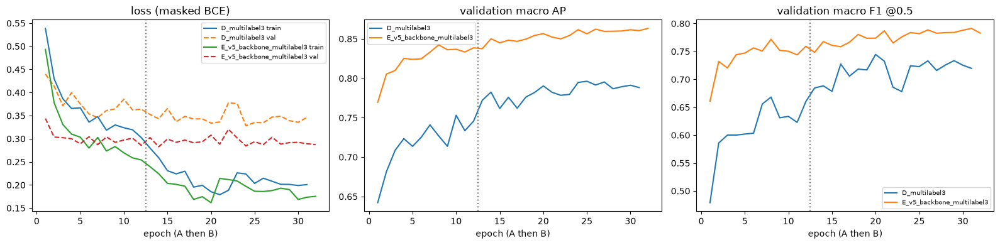

,experiment,epochs_A,epochs_B,best_step,best_phase,best_val_macro_ap,val_macro_f1_at_best
0,D_multilabel3,12,19,25,B,0.7963,0.7228
1,E_v5_backbone_multilabel3,12,20,32,B,0.8634,0.7830


In [3]:
def hist(exp):
    a = pd.read_csv(RUN / "checkpoints" / exp / "seed_42" / "phaseA_history.csv"); a["phase"] = "A"
    b = pd.read_csv(RUN / "checkpoints" / exp / "seed_42" / "phaseB_history.csv"); b["phase"] = "B"
    d = pd.concat([a, b], ignore_index=True); d["step"] = np.arange(1, len(d) + 1); return d, len(a)
H = {e: hist(e) for e in ["D_multilabel3", "E_v5_backbone_multilabel3"]}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for e, (d, na) in H.items():
    ax[0].plot(d.step, d.loss, label=f"{e} train"); ax[0].plot(d.step, d.val_loss, "--", label=f"{e} val")
    ax[1].plot(d.step, d.val_macro_ap, label=e); ax[2].plot(d.step, d.val_macro_f1, label=e)
for a_, t in zip(ax, ["loss (masked BCE)", "validation macro AP", "validation macro F1 @0.5"]):
    a_.axvline(na + 0.5, color="grey", ls=":"); a_.set_title(t); a_.set_xlabel("epoch (A then B)"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
rows = []
for e, (d, na) in H.items():
    i = d.val_macro_ap.idxmax(); rows.append(dict(experiment=e, epochs_A=na, epochs_B=len(d) - na, best_step=int(d.step[i]), best_phase=d.phase[i], best_val_macro_ap=d.val_macro_ap[i], val_macro_f1_at_best=d.val_macro_f1[i]))
display(pd.DataFrame(rows).round(4))

In [4]:
print("D vs E on validation images, split by V5 exposure (per condition):")
x = pd.read_csv(M / "d_vs_e_validation_by_exposure.csv"); display(x[["subset", "experiment", "condition", "pos", "neg", "precision", "recall", "f1", "ap"]].round(3))
print("selected:", json.load(open(M / "global_selection.json")).get("selected"))

D vs E on validation images, split by V5 exposure (per condition):


,subset,experiment,condition,pos,neg,precision,recall,f1,ap
0,all_validation,D_multilabel3,Acne,173,421,0.892,0.671,0.766,0.889
1,all_validation,D_multilabel3,Hyperpigmentation,233,363,0.812,0.725,0.766,0.871
2,all_validation,D_multilabel3,Eczema,55,537,0.636,0.636,0.636,0.630
3,all_validation,E_v5_backbone_multilabel3,Acne,173,421,0.876,0.855,0.865,0.925
4,all_validation,E_v5_backbone_multilabel3,Hyperpigmentation,233,363,0.902,0.708,0.793,0.912
5,all_validation,E_v5_backbone_multilabel3,Eczema,55,537,0.672,0.709,0.690,0.753
6,not_trained_by_v5,D_multilabel3,Acne,50,84,0.805,0.660,0.725,0.889
7,not_trained_by_v5,D_multilabel3,Hyperpigmentation,48,86,0.889,0.667,0.762,0.854
8,not_trained_by_v5,D_multilabel3,Eczema,18,114,0.625,0.556,0.588,0.687
9,not_trained_by_v5,E_v5_backbone_multilabel3,Acne,50,84,0.804,0.900,0.849,0.927


selected: E_v5_backbone_multilabel3


## 3. ROI MobileNetV2 (4 classes: acne, hyperpigmentation, eczema, background false positive)

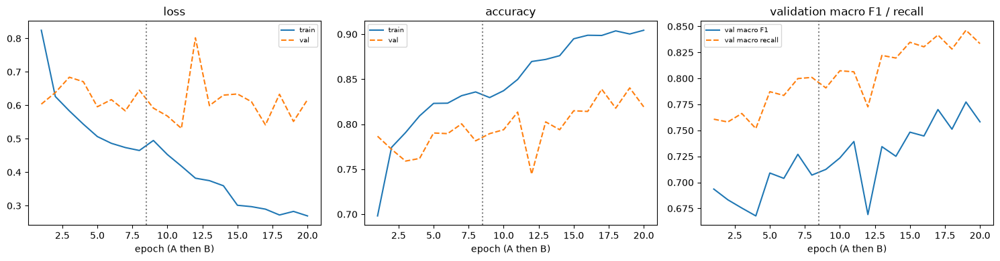

{
 "per_seed": {
  "42": {
   "frozen_backbone_val_macro_f1": 0.7270343989942278,
   "partial_finetune_val_macro_f1": 0.7773202615083622,
   "chosen": "B"
  }
 },
 "selected_seed": 42,
 "init": "imagenet"
}

ROI validation per class:


,region_class,support,precision,recall,specificity,f1,roc_auc,pr_auc,brier
0,Acne,275,0.752,0.927,0.924,0.831,0.980,0.919,0.050
1,Hyperpigmentation,132,0.620,0.864,0.944,0.722,0.968,0.827,0.047
2,Eczema,99,0.579,0.778,0.956,0.664,0.960,0.661,0.044
3,Background,872,0.986,0.817,0.980,0.893,0.967,0.982,0.103


In [5]:
ra = pd.read_csv(RUN / "checkpoints/ROI/seed_42/phaseA_history.csv"); rb = pd.read_csv(RUN / "checkpoints/ROI/seed_42/phaseB_history.csv")
r = pd.concat([ra.assign(phase="A"), rb.assign(phase="B")], ignore_index=True); r["step"] = np.arange(1, len(r) + 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.step, r.loss, label="train"); ax[0].plot(r.step, r.val_loss, "--", label="val"); ax[0].set_title("loss")
ax[1].plot(r.step, r.accuracy, label="train"); ax[1].plot(r.step, r.val_accuracy, "--", label="val"); ax[1].set_title("accuracy")
ax[2].plot(r.step, r.val_macro_f1, label="val macro F1"); ax[2].plot(r.step, r.val_macro_recall, "--", label="val macro recall"); ax[2].set_title("validation macro F1 / recall")
for a_ in ax: a_.axvline(len(ra) + 0.5, color="grey", ls=":"); a_.set_xlabel("epoch (A then B)"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(json.dumps(json.load(open(M / "roi_training_summary.json")), indent=1)[:1500])
print("\nROI validation per class:"); display(pd.read_csv(M / "roi_validation_per_class.csv").round(3))

## 4. Fusion models — 7 variants × (5 grouped folds + final fit)
Every fold and the final fit stop by early stopping. The table lists the epochs each used and its last validation loss (fold sizes are small, so curves are noisy).

42 fits found (expected 42)


fit,final,fold_0,fold_1,fold_2,fold_3,fold_4
variant,,,,,,
full,21,23,21,21,29,39
global_yolo,24,51,28,27,47,83
global_only,24,51,28,31,37,41
roi_only,24,21,21,21,27,38
no_acne_evidence,21,22,22,21,28,25
no_eczema_evidence,21,23,21,38,38,25
no_hyper_evidence,21,23,22,21,41,34


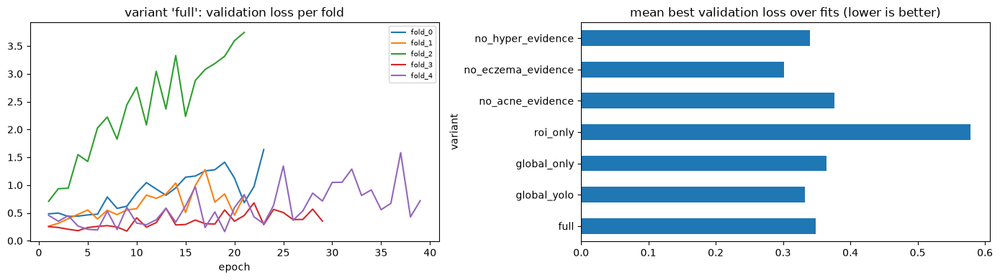

In [6]:
VARS = ["full", "global_yolo", "global_only", "roi_only", "no_acne_evidence", "no_eczema_evidence", "no_hyper_evidence"]
def fold_hist(var, fold):
    fs = sorted(glob.glob(str(RUN / "fusion" / "recovery" / var / "seed_42" / fold / "attempt_*" / "epoch_*.history.csv")))
    return pd.read_csv(fs[-1]) if fs else None
rows = []
for v in VARS:
    for f in ["fold_0", "fold_1", "fold_2", "fold_3", "fold_4", "final"]:
        h = fold_hist(v, f)
        if h is not None: rows.append(dict(variant=v, fit=f, epochs=len(h), best_val_loss=h.val_loss.min(), last_val_loss=h.val_loss.iloc[-1]))
FT = pd.DataFrame(rows); print(f"{len(FT)} fits found (expected 42)")
display(FT.pivot(index="variant", columns="fit", values="epochs").reindex(VARS))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for f in ["fold_0", "fold_1", "fold_2", "fold_3", "fold_4"]:
    h = fold_hist("full", f); ax[0].plot(h.epoch, h.val_loss, label=f)
ax[0].set_title("variant 'full': validation loss per fold"); ax[0].legend(fontsize=7); ax[0].set_xlabel("epoch")
FT.groupby("variant").best_val_loss.mean().reindex(VARS).plot.barh(ax=ax[1]); ax[1].set_title("mean best validation loss over fits (lower is better)")
plt.tight_layout(); plt.show()

## 5. Development evaluation (fusion split, out-of-fold)
Out-of-fold means each image was scored by a model that did not train on it. **This is not a V5 comparison and not a test result.** About 85 % of these images were in V5's training data.

condition,Acne,Eczema,Hyperpigmentation
variant,,,
Full fusion (+ROI),0.889,0.700,0.902
Global + YOLO evidence,0.884,0.746,0.911
Global only (recalibrated),0.877,0.716,0.894
ROI branch only,0.836,0.635,0.881


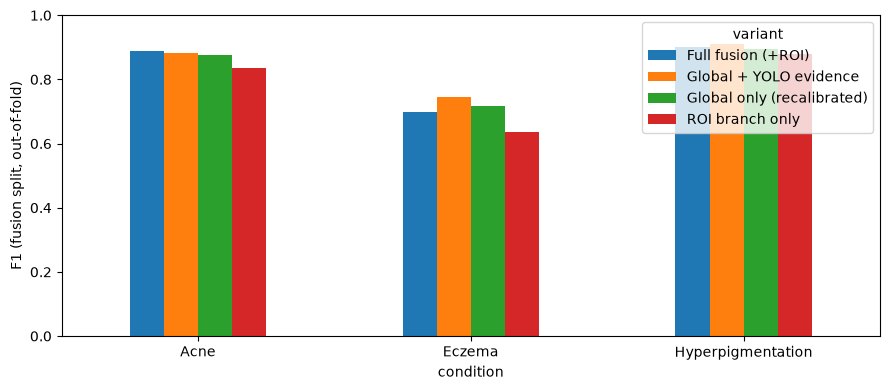

per-condition detail:


,variant,condition,n_evaluable,pos,neg,precision,recall,specificity,f1
0,Global only (recalibrated),Acne,353,111,242,0.921,0.838,0.967,0.877
1,Global only (recalibrated),Hyperpigmentation,352,124,228,0.902,0.887,0.947,0.894
2,Global only (recalibrated),Eczema,357,33,324,0.706,0.727,0.969,0.716
3,Global + YOLO evidence,Acne,353,111,242,0.876,0.892,0.942,0.884
4,Global + YOLO evidence,Hyperpigmentation,352,124,228,0.918,0.903,0.956,0.911
5,Global + YOLO evidence,Eczema,357,33,324,0.735,0.758,0.972,0.746
6,Full fusion (+ROI),Acne,353,111,242,0.877,0.901,0.942,0.889
7,Full fusion (+ROI),Hyperpigmentation,352,124,228,0.910,0.895,0.952,0.902
8,Full fusion (+ROI),Eczema,357,33,324,0.778,0.636,0.981,0.700
9,ROI branch only,Acne,353,111,242,0.844,0.829,0.930,0.836


In [7]:
names = {"global_only": "Global only (recalibrated)", "global_yolo": "Global + YOLO evidence", "full": "Full fusion (+ROI)", "roi_only": "ROI branch only"}
T = pd.concat([pd.read_csv(M / f"development_{k}_per_condition.csv").assign(variant=v) for k, v in names.items()], ignore_index=True)
display(T.pivot(index="variant", columns="condition", values="f1").round(3))
ax = T.pivot(index="condition", columns="variant", values="f1").plot.bar(figsize=(9, 4), rot=0); ax.set_ylabel("F1 (fusion split, out-of-fold)"); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()
print("per-condition detail:"); display(T[["variant", "condition", "n_evaluable", "pos", "neg", "precision", "recall", "specificity", "f1"]].round(3))

In [8]:
s = json.load(open(M / "development_oof_summary.json"))
fn = s["final_normal"]; s1 = s["stage1_normal"]
print(f"Derived-Normal decision (fusion split, n={s['n']}):")
print(f"  Stage 1 accepted {s1['accepted_n']} of {s1['reference_n']} references as Normal-decidable; abstention rate {s1['abstention_rate']:.1%}")
print(f"  Final (after Stage 2) accepted {fn['accepted_n']}; abstention rate {fn['abstention_rate']:.1%}; false Normal {fn['false_normal']}; recall over ALL references {fn['recall_all_references']:.1%}")
print("  A low error on accepted cases must be read together with this abstention rate; V5 never abstains.")

Derived-Normal decision (fusion split, n=360):
  Stage 1 accepted 12 of 347 references as Normal-decidable; abstention rate 96.5%
  Final (after Stage 2) accepted 74; abstention rate 78.7%; false Normal 1; recall over ALL references 40.6%
  A low error on accepted cases must be read together with this abstention rate; V5 never abstains.


## 6. Calibration of the fusion variants (out-of-fold)

In [9]:
c = pd.read_csv(M / "fusion_calibration_oof.csv"); display(c.round(4).head(30))

,variant,condition,brier_raw,brier_calibrated,ece_raw,ece_calibrated,calibrated,threshold
0,full,Acne,0.0649,0.0609,0.0521,0.0386,True,0.43
1,full,Hyperpigmentation,0.0585,0.0587,0.0341,0.0211,True,0.34
2,full,Eczema,0.0651,0.0437,0.0719,0.0180,True,0.33
3,global_yolo,Acne,0.0632,0.0582,0.0358,0.0237,True,0.42
4,global_yolo,Hyperpigmentation,0.0572,0.0562,0.0337,0.0199,True,0.37
5,global_yolo,Eczema,0.0600,0.0454,0.0712,0.0285,True,0.27
6,global_only,Acne,0.0653,0.0627,0.0393,0.0206,True,0.51
7,global_only,Hyperpigmentation,0.0664,0.0651,0.0427,0.0282,True,0.39
8,global_only,Eczema,0.0713,0.0450,0.0912,0.0258,True,0.25
9,roi_only,Acne,0.0877,0.0822,0.0546,0.0098,True,0.46


## 7. Stage rules

In [10]:
display(pd.read_csv(M / "development_oof_stage_per_condition.csv").round(3))

,condition,n_evaluable,pos,neg,precision,recall,specificity,f1,tp,fp,fn,tn,ap,roc_auc,stage
0,Acne,12,0,12,NaN,NaN,1.000,NaN,0,0,0,12,0.950,0.971,stage1
1,Hyperpigmentation,12,0,12,NaN,NaN,1.000,NaN,0,0,0,12,0.952,0.958,stage1
2,Eczema,12,1,11,1.000,1.000,1.000,1.00,1,0,0,11,0.711,0.915,stage1
3,Acne,74,7,67,0.667,0.857,0.955,0.75,6,3,1,64,0.941,0.969,final
4,Hyperpigmentation,74,25,49,1.000,0.960,1.000,0.98,24,0,1,49,0.956,0.962,final
5,Eczema,74,2,72,1.000,1.000,1.000,1.00,2,0,0,72,0.721,0.914,final


## 8. V5 vs V6 on validation images V5 never trained on  ← the thesis comparison
**Set:** validation images not in V5's training data (by id, MD5 and leakage group), fully verified labels. **Systems:** V5 argmax (its own decision rule), V5 with thresholds tuned on the fusion split (A2), Global E, Global+YOLO (E), Full fusion (F), ROI only, Global recalibrated. **Thresholds** come from the fusion split only. **Intervals** are 95 % bootstrap over leakage groups; an interval that includes 0 means the data do not show a difference (it does not show equivalence). **Caveat:** validation was used to select Global E over D and to stop ROI training, so V6 may look slightly better here than on fresh photos; V5 was not tuned on it. Abstention (system G) is not in this table.

,system,n,hp_pos,hp_missed_as_no_condition,hp_recall,all_neg,all_neg_flagged_hp,f1_acne,f1_hyper,f1_eczema,macro_f1
0,A_v5_argmax,132,47,9,0.511,26,1,0.835,0.658,0.718,0.737
1,A2_v5_thresholded,132,47,7,0.617,26,2,0.836,0.725,0.667,0.743
2,B_global_E,132,47,10,0.574,26,3,0.852,0.701,0.647,0.733
3,E_global_plus_yolo,132,47,10,0.574,26,2,0.870,0.711,0.632,0.737
4,F_full_fusion,132,47,8,0.702,26,2,0.862,0.759,0.645,0.755
5,D_roi_only,132,47,9,0.617,26,1,0.830,0.734,0.629,0.731
6,X_global_recalibrated,132,47,11,0.574,26,2,0.874,0.711,0.595,0.726


,system,vs,metric,difference,ci_lo,ci_hi,better_when,excludes_zero
0,B_global_E,A_v5_argmax,macro_f1,-0.003,-0.093,0.083,higher,False
1,B_global_E,A_v5_argmax,hp_missed_rate,0.021,-0.047,0.105,lower,False
2,B_global_E,A_v5_argmax,false_alarm_rate,0.077,0.000,0.200,lower,False
3,E_global_plus_yolo,A_v5_argmax,macro_f1,0.001,-0.084,0.074,higher,False
4,E_global_plus_yolo,A_v5_argmax,hp_missed_rate,0.021,0.000,0.076,lower,False
5,E_global_plus_yolo,A_v5_argmax,false_alarm_rate,0.038,-0.081,0.185,lower,False
6,F_full_fusion,A_v5_argmax,macro_f1,0.019,-0.086,0.112,higher,False
7,F_full_fusion,A_v5_argmax,hp_missed_rate,-0.021,-0.093,0.053,lower,False
8,F_full_fusion,A_v5_argmax,false_alarm_rate,0.038,0.000,0.136,lower,False


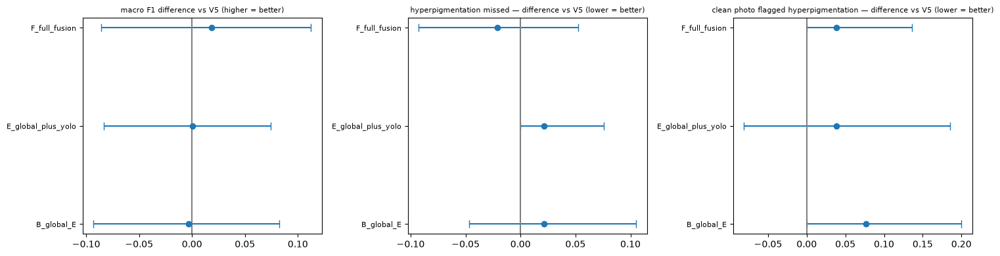

In [11]:
fair = pd.read_csv(M / "v5_vs_v6_fair_set.csv"); pair = pd.read_csv(M / "v5_vs_v6_fair_set_paired.csv")
display(fair.round(3)); display(pair.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, met, title in zip(ax, ["macro_f1", "hp_missed_rate", "false_alarm_rate"], ["macro F1 difference vs V5 (higher = better)", "hyperpigmentation missed — difference vs V5 (lower = better)", "clean photo flagged hyperpigmentation — difference vs V5 (lower = better)"]):
    p = pair[pair.metric == met]; y = np.arange(len(p))
    a_.errorbar(p.difference, y, xerr=[p.difference - p.ci_lo, p.ci_hi - p.difference], fmt="o", capsize=4); a_.axvline(0, color="grey"); a_.set_yticks(y); a_.set_yticklabels(p.system, fontsize=8); a_.set_title(title, fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
# Pre-registered criterion (v6/THESIS_TRACKER.md, fixed before results): V6 = Global + YOLO fusion counts as an improvement only if
# (a) hyperpigmentation-missed AND clean-flagged are each not worse than V5, and at least one is better with a 95% interval that excludes zero, and
# (b) Acne and Eczema F1 are each not more than 0.05 below V5.
f = fair.set_index("system"); A = f.loc["A_v5_argmax"]
for name in ["E_global_plus_yolo", "F_full_fusion"]:
    E = f.loc[name]; P = pair[(pair.system == name) & (pair.metric.isin(["hp_missed_rate", "false_alarm_rate"]))]
    a_notworse = bool(E.hp_missed_as_no_condition <= A.hp_missed_as_no_condition and E.all_neg_flagged_hp <= A.all_neg_flagged_hp)
    a_sig = bool(((P.difference < 0) & P.excludes_zero).any())
    b_ok = bool(E.f1_acne >= A.f1_acne - 0.05 and E.f1_eczema >= A.f1_eczema - 0.05)
    print(f"{name}: (a) not worse on both errors = {a_notworse}; one better with CI excluding 0 = {a_sig}; (b) acne/eczema F1 within 0.05 = {b_ok}  ->  {'MET' if (a_notworse and a_sig and b_ok) else 'NOT MET: report as no clear improvement'}")
    print(f"    hyper missed {int(E.hp_missed_as_no_condition)} vs V5 {int(A.hp_missed_as_no_condition)} | clean flagged {int(E.all_neg_flagged_hp)} vs {int(A.all_neg_flagged_hp)} | eczema F1 {E.f1_eczema:.3f} vs {A.f1_eczema:.3f}")

E_global_plus_yolo: (a) not worse on both errors = False; one better with CI excluding 0 = False; (b) acne/eczema F1 within 0.05 = False  ->  NOT MET: report as no clear improvement
    hyper missed 10 vs V5 9 | clean flagged 2 vs 1 | eczema F1 0.632 vs 0.718
F_full_fusion: (a) not worse on both errors = False; one better with CI excluding 0 = False; (b) acne/eczema F1 within 0.05 = False  ->  NOT MET: report as no clear improvement
    hyper missed 8 vs V5 9 | clean flagged 2 vs 1 | eczema F1 0.645 vs 0.718


### 8b. Eczema on the same fair set (post-hoc diagnostic — a hypothesis, not a result)
Only 18 eczema-positive photos. The V6 models *rank* eczema better than V5 (higher AP/AUC) but lose at the calibrated cutoff (thresholds were set on only 33 eczema positives in the fusion split). No threshold was re-tuned on these photos.

In [13]:
e = pd.read_csv(M / "eczema_fair_set_diagnostic.csv"); print(e.groupby("truth").size().to_dict())
pos = e[e.truth == "eczema"]; print(f"eczema positives {len(pos)}: V5 found {int(pos.v5_says.sum())}, full fusion found {int(pos.full_says.sum())}")
display(e[(e.v5_says == (e.truth == "eczema")) & (e.full_says != (e.truth == "eczema"))])

{'eczema': 18, 'no eczema': 114}
eczema positives 18: V5 found 14, full fusion found 10


,image_id,origin,truth,v5_score,full_score,v5_says,full_says
8,img_000810,source_dataset,eczema,0.668,0.179,True,False
89,img_012879,source_dataset,eczema,0.969,0.210,True,False
91,img_013087,source_dataset,eczema,0.541,0.150,True,False
95,img_014033,source_dataset,eczema,0.470,0.274,True,False
96,img_014106,source_dataset,eczema,0.939,0.220,True,False
97,img_014238,source_dataset,eczema,0.904,0.237,True,False


## 9. Export and ONNX faithfulness
The notebook's own check compared Keras on the **GPU** with ONNX on the **CPU** and flagged everything outside 1e-4. A follow-up compared the same images three ways: the gap is GPU-vs-CPU numeric noise, not an export defect.

In [14]:
ex = json.load(open(RUN / "export" / "v6_export_status.json")); print({k: v.get("status") for k, v in ex.items()})
v = json.load(open(RUN / "export" / "v6_keras_vs_onnx_verification.json"))
display(pd.DataFrame([dict(component=k, status=x.get("status"), max_abs_diff=max(x.get("max_abs_diff_per_output", [np.nan])), within_1e_4=x.get("within_tolerance")) for k, x in v.items() if isinstance(x, dict)]).round(5))
pc = RUN / "export" / "v6_global_features_parity_check.csv"
if pc.exists(): print("Global feature model, 160 validation photos x 3 conditions (Keras GPU / Keras CPU / ONNX CPU):"); display(pd.read_csv(pc).round(5))
else: print("(follow-up parity table not found in this folder)")

{'global_features': 'exported', 'roi_features': 'exported', 'fusion_global_only_seed42': 'exported', 'fusion_global_yolo_seed42': 'exported', 'fusion_full_seed42': 'exported'}


,component,status,max_abs_diff,within_1e_4
0,global_features,compared,0.04257,False
1,roi_features,compared,0.05155,False
2,fusion_global_only_seed42,compared,0.00047,False
3,fusion_global_yolo_seed42,compared,0.00051,False
4,fusion_full_seed42,compared,0.00055,False


Global feature model, 160 validation photos x 3 conditions (Keras GPU / Keras CPU / ONNX CPU):


,pair,max_abs_diff_embedding,max_abs_diff_logits,decisions_flipped_at_0_5,decisions_flipped_at_tuned_thresholds
0,Keras GPU vs Keras CPU,0.05241,0.06956,0,1
1,Keras CPU vs ONNX CPU,0.00004,0.00005,0,0
2,Keras GPU vs ONNX CPU,0.05244,0.06960,0,1


## 10. What this run does and does not show
- **Does show:** the pipeline trains end to end and reproduces (audit chain intact, originals unchanged, 35 of 37 unit tests pass with 2 skipped by design); components export to ONNX and match Keras on CPU.
- **Does not show:** that V6 beats V5. On validation images V5 never trained on, the pre-registered criterion was **not met** (section 8). Global E and the fusion models rank conditions somewhat better than V5, and acne F1 is higher, but the error rates the thesis targets are not significantly better and eczema F1 fell below the allowed margin.
- **Not done:** the locked test (no expert labels), an independent labelled set, dermatologist validation, C# parity, multi-seed variability.

# Part XII — The final model as deployed in LUMYVUE

Everything above trained and evaluated the V6 components (run **open_run02**). This part documents what happened **after** training, without retraining anything:
which variant became the final model, how it was packaged and verified for the C# application, and the clinical reading rules the application applies to its output.

**The final model is `global_yolo`**: the Global MobileNetV2 (experiment E, seed 42) and the three YOLOv8 detector ensembles, combined by the trained fusion network
(variant *global_yolo*, seed 42), Platt-calibrated, with the per-condition thresholds chosen on out-of-fold fusion predictions. The *full* variant (with the ROI branch)
is packaged as an option but is not the default.

Every cell in this part only **reads saved files** (the run folder, the deployment package and the application's model folder). Nothing is trained, and the locked test split is not opened.

In [ ]:
# 57.0 Locate the project (repository root holds v6/ and SkinDevApp/)
import json, os, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOTS = [os.environ.get("LUMYVUE_REPO", ""), "/mnt/c/Users/Bautista/source/repos/SkinDevApp", r"C:\Users\Bautista\source\repos\SkinDevApp"]
REPO = next(Path(r) for r in ROOTS if r and (Path(r) / "v6" / "deployment").is_dir())
RUN = REPO / "v6" / "astra_runs" / "open_run02"
DEP = REPO / "v6" / "deployment"
APP_MODELS = REPO / "SkinDevApp" / "Model" / "V6"
print("repository :", REPO)
print("run folder :", RUN, "| exists:", RUN.is_dir())
print("deployment :", DEP)
print("app models :", APP_MODELS)

repository : /mnt/c/Users/Bautista/source/repos/SkinDevApp
run folder : /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/astra_runs/open_run02 | exists: True
deployment : /mnt/c/Users/Bautista/source/repos/SkinDevApp/v6/deployment
app models : /mnt/c/Users/Bautista/source/repos/SkinDevApp/SkinDevApp/Model/V6


## 57. The deployment package and model identity

The application loads `v6_deployment_config.json` and refuses to run V6 if any model file's SHA-256 differs from the value recorded here.
The cell recomputes the hashes of the files actually installed in the application.

In [ ]:
# 57.1 Model files: recorded hash vs the file installed in the application
cfg = json.load(open(DEP / "v6_deployment_config.json"))
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
rows = []
for key, m in cfg["models"].items():
    p = APP_MODELS / m["file"]
    actual = sha(p) if p.exists() else None
    rows.append(dict(component=key, file=m["file"], size_MB=round(p.stat().st_size / 1e6, 2) if p.exists() else None,
                     recorded_sha256=m["sha256"][:16] + "…", matches_installed_file=(actual == m["sha256"])))
display(pd.DataFrame(rows))
print("run id:", cfg["run_id"], "| feature schema:", cfg["feature_schema_version"])

,component,file,size_MB,recorded_sha256,matches_installed_file
0,global_features,v6_global_features_mobilenetv2.onnx,9.57,82662184cc526f26…,True
1,fusion_global_yolo,v6_fusion_global_yolo_seed42.onnx,0.14,f25a741cae5d87b5…,True
2,fusion_global_only,v6_fusion_global_only_seed42.onnx,0.14,fd9ef9a6803f30a9…,True
3,fusion_full,v6_fusion_full_seed42.onnx,0.14,1dbea01249c76fa2…,True
4,roi_features,v6_roi_features_mobilenetv2.onnx,9.24,45a65103d89c4c59…,True


run id: open_run02 | feature schema: astra-fusion/1


In [ ]:
# 57.2 Decision settings of each fusion variant (calibration and thresholds were fitted on out-of-fold fusion-split predictions)
rows = []
for variant in ["global_yolo", "full", "global_only"]:
    cal = cfg["calibration"].get(variant)
    if not cal: continue
    for j, cond in enumerate(cfg["conditions"]):
        rows.append(dict(variant=variant, condition=cond, platt_a=round(cal["platt"][j]["a"], 3), platt_b=round(cal["platt"][j]["b"], 3), threshold=cal["thresholds"][j]))
display(pd.DataFrame(rows).pivot_table(index=["variant", "condition"], values=["platt_a", "platt_b", "threshold"]))
print("decision band:", cfg["decision"]["band"], "(present if p >= t + band, absent if p < t - band)")
print("detector deployed thresholds:", {c: v["deployed_threshold"] for c, v in cfg["detectors"]["per_condition"].items()},
      "| candidate pool from", cfg["detectors"]["candidate_pool_min_conf"], "| face filter for evidence:", cfg["detectors"]["face_filter_for_evidence"])
print("global_only is used only for the CNN-vs-detector conflict flag; it never changes a score.")

platt_a  platt_b  threshold
variant     condition                                     
full        Acne                 0.583   -0.807       0.43
            Eczema               0.501   -1.662       0.33
            Hyperpigmentation    0.628   -0.298       0.34
global_only Acne                 0.794   -0.488       0.51
            Eczema               0.594   -1.905       0.25
            Hyperpigmentation    0.880   -0.456       0.39
global_yolo Acne                 0.730   -0.681       0.42
            Eczema               0.536   -1.733       0.27
            Hyperpigmentation    0.762   -0.547       0.37

decision band: 0.0 (present if p >= t + band, absent if p < t - band)
detector deployed thresholds: {'Acne': 0.275, 'Hyperpigmentation': 0.225, 'Eczema': 0.25} | candidate pool from 0.05 | face filter for evidence: False
global_only is used only for the CNN-vs-detector conflict flag; it never changes a score.


## 58. Choosing the deployed variant

Section 49b compared V5 and the V6 variants on the **fair set**: 132 fully verified validation photographs that V5 never trained on.
The table repeats those saved results for the two candidate variants.

,system,n,hp_missed_as_no_condition,all_neg_flagged_hp,f1_acne,f1_hyper,f1_eczema,macro_f1
0,V5 (baseline),132,9,1,0.835,0.658,0.718,0.737
3,V6 global_yolo (deployed),132,10,2,0.870,0.711,0.632,0.737
4,V6 full (option),132,8,2,0.862,0.759,0.645,0.755


,system,vs,metric,difference,ci_lo,ci_hi,better_when,excludes_zero
0,B_global_E,A_v5_argmax,macro_f1,-0.003,-0.093,0.083,higher,False
1,B_global_E,A_v5_argmax,hp_missed_rate,0.021,-0.047,0.105,lower,False
2,B_global_E,A_v5_argmax,false_alarm_rate,0.077,0.000,0.200,lower,False
3,E_global_plus_yolo,A_v5_argmax,macro_f1,0.001,-0.084,0.074,higher,False
4,E_global_plus_yolo,A_v5_argmax,hp_missed_rate,0.021,0.000,0.076,lower,False
5,E_global_plus_yolo,A_v5_argmax,false_alarm_rate,0.038,-0.081,0.185,lower,False
6,F_full_fusion,A_v5_argmax,macro_f1,0.019,-0.086,0.112,higher,False
7,F_full_fusion,A_v5_argmax,hp_missed_rate,-0.021,-0.093,0.053,lower,False
8,F_full_fusion,A_v5_argmax,false_alarm_rate,0.038,0.000,0.136,lower,False


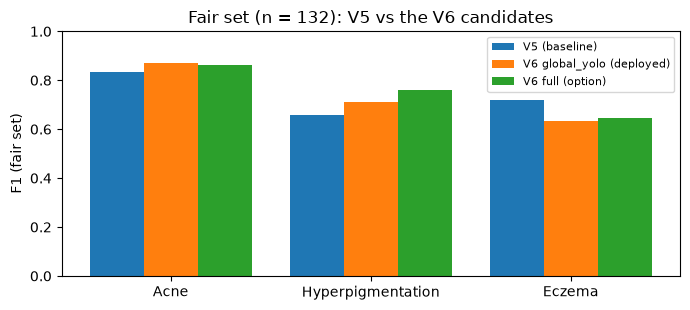

In [ ]:
# 58.1 Fair-set comparison of the candidates (saved by section 49b; nothing recomputed)
fair = pd.read_csv(RUN / "metrics" / "v5_vs_v6_fair_set.csv")
pick = fair[fair.system.isin(["A_v5_argmax", "E_global_plus_yolo", "F_full_fusion"])].copy()
pick["system"] = pick.system.map({"A_v5_argmax": "V5 (baseline)", "E_global_plus_yolo": "V6 global_yolo (deployed)", "F_full_fusion": "V6 full (option)"})
display(pick[["system", "n", "hp_missed_as_no_condition", "all_neg_flagged_hp", "f1_acne", "f1_hyper", "f1_eczema", "macro_f1"]].round(3))
paired = pd.read_csv(RUN / "metrics" / "v5_vs_v6_fair_set_paired.csv")
display(paired.round(3))
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(3); w = 0.27
for k, (name, r) in enumerate(pick.set_index("system").iterrows()):
    ax.bar(x + (k - 1) * w, [r.f1_acne, r.f1_hyper, r.f1_eczema], w, label=name)
ax.set_xticks(x); ax.set_xticklabels(["Acne", "Hyperpigmentation", "Eczema"]); ax.set_ylabel("F1 (fair set)"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title("Fair set (n = 132): V5 vs the V6 candidates"); plt.tight_layout(); plt.show()

**Decision.** The *full* variant scores slightly higher (macro-F1 0.755 vs 0.737; 8 vs 10 hyperpigmentation photographs missed), but the difference is
2 photographs out of 132, every paired 95% interval against V5 includes zero, the development evaluation (section 39-dev) found no gain from the ROI branch,
and it is slower (about 2 s per photograph on CPU because of the region crops). **`global_yolo` was therefore deployed as the default**; `full` stays
selectable (`V6Variant=full`). Neither variant is shown to be more accurate than V5; what V6 adds is one calibrated, reviewable result per photograph.

## 59. Faithfulness of the application (C#) to this notebook

The application re-implements, in C#, the detector post-processing (section 24), the 21-number evidence vector (section 29), the ROI selection and crops
(section 25/28, full variant), calibration, thresholds, flags and states (sections 31-36). The saved verification files below compare the C# results with a
Python reference that reproduces this notebook's code.

In [ ]:
# 59.1 Parity evidence saved by the deployment tools (v6/tools)
gold = json.load(open(DEP / "v6_real_photo_golden.json"))
rc = gold["replica_vs_training_cache"]
print(f"Python reference vs the detections this run was trained on: same box count on {rc['same_box_count_for_all_conditions']}/{rc['photos']} photographs, max |difference| {rc['max_abs_diff_conf_cx_cy_area']}")
cpu = json.load(open(DEP / "v6_cpu_parity_verification.json"))
print("Fusion, CPU ONNX vs Keras:", {k: v for k, v in cpu.items() if not isinstance(v, (list, dict))})
full = DEP / "v6_full_variant_golden.json"
if full.exists():
    fg = json.load(open(full))
    print("Full variant reference:", len(fg["photos"]), "photographs, thresholds", fg["thresholds"])
print("C# unit tests (SkinDevApp.Tests) compare against these files: detector boxes within 0.0001 px, fusion within 1.9e-6, full variant within 1e-6, 0 decisions flipped.")

Python reference vs the detections this run was trained on: same box count on 13/13 photographs, max |difference| 0.0
Fusion, CPU ONNX vs Keras: {'created': '2026-11-02T18:36:33', 'purpose': 'Supersedes the pass/fail flags in v6_keras_vs_onnx_verification.json, which compared Keras on the GPU with ONNX on the CPU. This record compares CPU with CPU.', 'tolerance_logits': 0.0001, 'conclusion': "CPU Keras and CPU ONNX agree within tolerance for the Global features model and the global_yolo fusion; the earlier 'outside tolerance' flag was GPU-vs-CPU numeric noise."}
Full variant reference: 13 photographs, thresholds [0.43, 0.34, 0.33]
C# unit tests (SkinDevApp.Tests) compare against these files: detector boxes within 0.0001 px, fusion within 1.9e-6, full variant within 1e-6, 0 decisions flipped.


## 60. The clinical reading the application shows

The fusion output is turned into a clinician-facing reading by `ClinicalSummary` in the application. The same rules are written here in Python and checked on
the saved reference photographs, so the thesis can state exactly what a dermatologist sees.

* **Per condition:** *Detected* (calibrated p ≥ threshold), *Not detected*, *Inconclusive* (model uncertain) or *Possible* (the fusion said no but that condition's
  detector marked an area).
* **Detector-led hyperpigmentation** (application rule, version 2): for **hyperpigmentation only**, an area marked by its detector is reported as *Detected — found by
  the lesion detector* even when the fusion did not confirm it. Reason: the detector finds most hyperpigmentation photographs the whole-face reading misses
  (about 91% on the fair set) — at the cost of more false alarms on clear skin (about 27% of clear faces). Such findings carry at most *moderate* certainty and always name their source.
* **Certainty:** detected p ≥ 0.80 high, ≥ 0.60 moderate, otherwise low; not detected p ≤ 0.10 high, ≤ 0.25 moderate, otherwise low; detector-led: moderate if the best
  box confidence ≥ 0.50, otherwise low.
* **Facial regions:** box centres relative to the face box: forehead (top 30%), mouth / chin (bottom 28%), nose (middle 40% across), right / left cheek on the patient's own side.
* **Outcome of a photograph:** *Condition detected*, *Needs review* (any inconclusive or possible condition, a conflict, an unusual photograph, a quality warning,
  a missing detector), *No condition detected*, *Retake photograph* (blocking quality problem: no condition is reported) or *Analysis not completed*.

In [ ]:
# 60.1 Python reference of the application's reading rules (ClinicalSummary, rules version 2)
DETECTOR_LED = {"Hyperpigmentation"}
CONDS = cfg["conditions"]

def region_of(cx, cy, face=None):
    bx, by, bw, bh = face if face else (0, 0, 1, 1)
    u, v = (cx - bx) / bw, (cy - by) / bh
    if u < -0.25 or u > 1.25 or v < -0.25 or v > 1.25: return None
    if v < 0.30: return "forehead"
    if v >= 0.72: return "mouth / chin"
    if 0.30 <= u <= 0.70: return "nose"
    return "right cheek" if u < 0.30 else "left cheek"           # camera not mirrored: image left = the patient's right

def certainty(status, p):
    if status == "Detected": return "High" if p >= 0.80 else "Moderate" if p >= 0.60 else "Low"
    if status == "Not detected": return "High" if p <= 0.10 else "Moderate" if p <= 0.25 else "Low"
    return "Low"

def read_photo(state, p, thr, available, detected, pools, flags, width, height, face=None):
    if state == "RECAPTURE_REQUIRED": return "Retake photograph", [], []
    if state == "INFERENCE_ERROR": return "Analysis not completed", [], []
    findings, reasons = [], []
    for j, c in enumerate(CONDS):
        present = p[j] >= thr[j]
        status = "Detected" if present else ("Possible" if detected[j] and available[j] else "Not detected" if available[j] else "Inconclusive")
        source, cert = "model", certainty(status, p[j])
        if status != "Detected" and available[j] and detected[j] and c in DETECTOR_LED:
            best = max([b["conf"] for b in pools[c] if b["deployed"]] or [0])
            status, source, cert = "Detected", "lesion detector", "Moderate" if best >= 0.50 else "Low"
        regions = sorted({region_of((b["x0"] + b["x1"]) / 2 / width, (b["y0"] + b["y1"]) / 2 / height, face) for b in pools[c] if b["deployed"]} - {None})
        findings.append(dict(condition=c, status=status, source=source, certainty=cert if status in ("Detected", "Not detected") else "—",
                             p=round(p[j], 3), threshold=thr[j], regions=", ".join(regions) if status in ("Detected", "Possible") else ""))
        if status == "Possible": reasons.append(c + ": detector marked an area the model did not confirm")
    for f in flags:
        if f.startswith("cnn_yolo_conflict_"):
            c = f[len("cnn_yolo_conflict_"):]
            if not any(x["condition"] == c and (x["status"] == "Possible" or x["source"] == "lesion detector") for x in findings): reasons.append(c + ": whole-face reading and detector disagree")
        elif f == "ood": reasons.append("unlike the training photographs")
        elif f.startswith("quality_") and not f.startswith("quality_warning"): reasons.append("photo quality: " + f[8:])
    detected_names = [x["condition"] for x in findings if x["status"] == "Detected"]
    if reasons: outcome = (" and ".join(detected_names) + " detected · needs review") if detected_names else "Needs review"
    elif detected_names: outcome = "Condition detected: " + ", ".join(detected_names)
    else: outcome = "No condition detected"
    return outcome, findings, reasons

# the same checks as the application's unit tests (ClinicalSummaryTests)
assert region_of(0.5, 0.15, (0.2, 0.1, 0.6, 0.8)) == "forehead" and region_of(0.25, 0.5, (0.2, 0.1, 0.6, 0.8)) == "right cheek"
assert certainty("Detected", 0.9) == "High" and certainty("Not detected", 0.2) == "Moderate"
print("reading rules loaded; checks passed")

reading rules loaded; checks passed


In [ ]:
# 60.2 The reading applied to the saved reference photographs (13 validation photographs; outputs of the deployed global_yolo model)
thr = cfg["calibration"]["global_yolo"]["thresholds"]
rows, detail = [], []
for ph in gold["photos"]:
    ev = ph["det_ev"]; avail = [ev[7 * j] > 0.5 for j in range(3)]; det = [ev[7 * j + 1] > 0.5 for j in range(3)]
    outcome, findings, reasons = read_photo(ph["state"], ph["calibrated_global_yolo"], thr, avail, det, ph["pools"], ph["flags"], ph["width"], ph["height"])
    rows.append(dict(photo=ph["image_id"], labelled_as=ph["kind"], model_state=ph["state"], outcome=outcome,
                     **({c[:5]: next(f["status"] + (" (detector)" if f["source"] == "lesion detector" else "") for f in findings if f["condition"] == c) for c in CONDS} if findings else {})))
display(pd.DataFrame(rows))
print("Regions are named relative to the whole frame here (the reference file does not store the face box); the application uses the saved face box.")

,photo,labelled_as,model_state,outcome,Acne,Hyper,Eczem
0,img_009371,hyperpigmentation,FINDINGS_SUPPORTED,Condition detected: Hyperpigmentation,Not detected,Detected,Not detected
1,img_007765,hyperpigmentation,UNCERTAIN_REVIEW_REQUIRED,Condition detected: Hyperpigmentation,Not detected,Detected (detector),Not detected
2,img_020830,hyperpigmentation,UNCERTAIN_REVIEW_REQUIRED,Condition detected: Hyperpigmentation,Not detected,Detected (detector),Not detected
3,img_009941,hyperpigmentation,UNCERTAIN_REVIEW_REQUIRED,Hyperpigmentation detected · needs review,Possible,Detected,Not detected
4,img_016301,hyperpigmentation,UNCERTAIN_REVIEW_REQUIRED,Needs review,Possible,Not detected,Not detected
5,img_002584,acne,UNCERTAIN_REVIEW_REQUIRED,Acne detected · needs review,Detected,Not detected,Possible
6,img_015560,acne,UNCERTAIN_REVIEW_REQUIRED,Eczema detected · needs review,Possible,Not detected,Detected
7,img_012924,acne,UNCERTAIN_REVIEW_REQUIRED,Eczema detected · needs review,Possible,Not detected,Detected
8,img_014033,eczema,UNCERTAIN_REVIEW_REQUIRED,Hyperpigmentation and Eczema detected · needs review,Possible,Detected (detector),Detected
9,img_014442,eczema,UNCERTAIN_REVIEW_REQUIRED,Hyperpigmentation and Eczema detected · needs review,Possible,Detected (detector),Detected


Regions are named relative to the whole frame here (the reference file does not store the face box); the application uses the saved face box.


In [ ]:
# 60.3 What the detector-led hyperpigmentation rule changes on these photographs
changed = [r for r in rows if "(detector)" in str(r.get("Hyper", ""))]
print(f"{len(changed)} of {len(rows)} reference photographs have hyperpigmentation reported by its detector rather than by the fusion:")
display(pd.DataFrame(changed)[["photo", "labelled_as", "Hyper", "outcome"]] if changed else pd.DataFrame())
print("These photographs are a convenience sample (5 hyperpigmentation, 3 acne, 2 eczema, 3 clear). A measured false-alarm rate for this rule needs a labelled set.")

5 of 13 reference photographs have hyperpigmentation reported by its detector rather than by the fusion:


,photo,labelled_as,Hyper,outcome
0,img_007765,hyperpigmentation,Detected (detector),Condition detected: Hyperpigmentation
1,img_020830,hyperpigmentation,Detected (detector),Condition detected: Hyperpigmentation
2,img_014033,eczema,Detected (detector),Hyperpigmentation and Eczema detected · needs review
3,img_014442,eczema,Detected (detector),Hyperpigmentation and Eczema detected · needs review
4,img_021049,clean,Detected (detector),Condition detected: Hyperpigmentation


These photographs are a convenience sample (5 hyperpigmentation, 3 acne, 2 eczema, 3 clear). A measured false-alarm rate for this rule needs a labelled set.


## 61. Final summary of the V6 model

| Item | Value |
|---|---|
| Deployed model | `global_yolo` fusion: Global MobileNetV2 (E, V5-backbone start, seed 42) + three YOLOv8 detector ensembles → trained fusion network (seed 42) → Platt calibration |
| Thresholds | Acne 0.42 · Hyperpigmentation 0.37 · Eczema 0.27 (calibrated probability), band 0.0 |
| Application rules | Possible / Inconclusive / conflict / out-of-distribution / quality → *Needs review*; hyperpigmentation is detector-led (rules version 2) |
| Fair-set result (n = 132) | macro-F1 0.737 (V5 0.737); 10 of 47 hyperpigmentation photographs missed (V5 9); 2 of 26 clear faces flagged (V5 1); all paired intervals include 0 |
| Faithfulness | C# vs Python: boxes within 0.0001 px; fusion within 1.9e-6; 0 decisions flipped |
| Not done | locked test split (no verified labels), dermatologist validation, skin-tone fairness, multi-seed fusion |

**What can be claimed:** V6 gives one unified, calibrated, auditable result per photograph (no contradicting second answer), with review flags, facial regions and
detector-evidence maps, at accuracy comparable to V5 on a small fair set. **What cannot be claimed:** that V6 is more accurate than V5, or any clinical validity.
Every result is a screening aid that waits for dermatologist review.